In [ ]:
!unzip Group_16.zip

Streaming output truncated to the last 5000 lines.
  inflating: Group_16/train/6/img_21392.jpg  
  inflating: Group_16/train/6/img_2988.jpg  
  inflating: Group_16/train/6/img_16349.jpg  
  inflating: Group_16/train/6/img_5021.jpg  
  inflating: Group_16/train/6/img_21025.jpg  
  inflating: Group_16/train/6/img_21219.jpg  
  inflating: Group_16/train/6/img_23580.jpg  
  inflating: Group_16/train/6/img_18021.jpg  
  inflating: Group_16/train/6/img_10303.jpg  
  inflating: Group_16/train/6/img_21326.jpg  
  inflating: Group_16/train/6/img_12943.jpg  
  inflating: Group_16/train/6/img_18356.jpg  
  inflating: Group_16/train/6/img_19625.jpg  
  inflating: Group_16/train/6/img_26881.jpg  
  inflating: Group_16/train/6/img_23515.jpg  
  inflating: Group_16/train/6/img_31028.jpg  
  inflating: Group_16/train/6/img_16346.jpg  
  inflating: Group_16/train/6/img_12856.jpg  
  inflating: Group_16/train/6/img_11917.jpg  
  inflating: Group_16/train/6/img_25543.jpg  
  inflating: Group_16/train/6/i

In [ ]:
import os

# Correct syntax
for j in ["train","val","test"]:
    if os.path.exists(f"Group_16/{j}"):
        print(f"The {j} exists!")

The train exists!
The val exists!
The test exists!


In [ ]:
import numpy as np
RANDOM_STATE=42
np.random.seed(RANDOM_STATE)

In [ ]:
TARGET_SIZES = [32, 64, 128, 256]

In [ ]:
ARCHITECTURES = {
    "3_hidden_best": [128, 64, 32],
    "4_hidden_best": [128, 64, 32, 16],
    "4_hidden_normal": [256, 128, 64, 32],
    "5_hidden_best": [256, 128, 64, 32, 16],
}

# **IMAGE DATA LOADING**

In [ ]:
import os
from PIL import Image

def load_dataset(base_path):
    """
    Loads images from a structured folder (e.g., 'train') where subfolders are class names.
    Returns:
        X: NumPy array of images
        y: NumPy array of labels (integer indices)
        class_names: List of class names corresponding to indices
    """
    # 1. Get and sort the class names from the subdirectory names
    class_names = sorted(os.listdir(base_path))
    # Create a mapping from class name string to an integer label
    class_to_idx = {class_name: idx for idx, class_name in enumerate(class_names)}

    images = []
    labels = []

    # 2. Iterate through each class folder
    for class_name in class_names:
        class_dir = os.path.join(base_path, class_name)

        # Skip if it's a file instead of a directory
        if not os.path.isdir(class_dir):
            continue

        # 3. Read every image in the class folder
        for img_name in os.listdir(class_dir):
            img_path = os.path.join(class_dir, img_name)

            try:
                # Open image using PIL
                with Image.open(img_path) as img:
                    # Optional: Resize images so they all have the same dimensions
                    # img = img.resize((128, 128))

                    # # Optional: Convert to RGB if you have a mix of grayscale and CMYK
                    # img = img.convert('L')

                    # Convert PIL image to a NumPy array
                    img_array = np.array(img)

                    images.append(img_array)
                    labels.append(class_to_idx[class_name])
            except Exception as e:
                # Skip broken images or non-image files (like .DS_Store)
                print(f"Skipping {img_path}: {e}")

    # 4. Convert lists to final NumPy arrays
    X = np.array(images)
    y = np.array(labels)

    return X, y, class_names

# --- How to use it for your folders ---

# Define the root path where your train, val, and test folders live
dataset_root = "Group_16"

# Load each split
X_train, y_train, classes = load_dataset(os.path.join(dataset_root, 'train'))
X_val, y_val, _          = load_dataset(os.path.join(dataset_root, 'val'))
X_test, y_test, _        = load_dataset(os.path.join(dataset_root, 'test'))

print(f"Train shapes: X={X_train.shape}, y={y_train.shape}")
print(f"Class labels mapping: {classes}")


Train shapes: X=(11385, 28, 28), y=(11385,)
Class labels mapping: ['1', '5', '6', '7', '9']


# **Normalizing data**

In [ ]:
X_train_scaled = X_train/255.0
X_test_scaled = X_test/255.0
X_val_scaled = X_val / 255.0

# **Flattening**

In [ ]:
X_train_flattened = X_train_scaled.reshape(X_train_scaled.shape[0], -1)
X_test_flattened = X_test_scaled.reshape(X_test_scaled.shape[0], -1)
X_val_flattened = X_val_scaled.reshape(X_val_scaled.shape[0], -1)
print("Shapes")
print(f"Train shapes: X={X_train_flattened.shape}")
print(f"Test shapes: X={X_test_flattened.shape}")
print(f"Val shapes: X={X_val_flattened.shape}")

Shapes
Train shapes: X=(11385, 784)
Test shapes: X=(3795, 784)
Val shapes: X=(3795, 784)


# **Centering**

In [ ]:
train_mean = np.mean(X_train_flattened, axis=0)
X_train_centered = X_train_flattened - train_mean
X_test_centered = X_test_flattened - train_mean
X_val_centered = X_val_flattened - train_mean

print("Shapes")
print(f"Train shapes: X={X_train_centered.shape}")
print(f"Test shapes: X={X_test_centered.shape}")
print(f"Val shapes: X={X_val_centered.shape}")


Shapes
Train shapes: X=(11385, 784)
Test shapes: X=(3795, 784)
Val shapes: X=(3795, 784)


In [ ]:
print(np.max(np.abs(X_train_centered.mean(axis=0))))

2.3076168409888e-14


In [ ]:
print("Train mean absolute mean:",
      np.mean(np.abs(X_train_centered.mean(axis=0))))

print("Validation centered using training mean:",
      np.mean(np.abs(X_val_centered.mean(axis=0))))

print("Test centered using training mean:",
      np.mean(np.abs(X_test_centered.mean(axis=0))))

Train mean absolute mean: 2.0946650466710396e-15
Validation centered using training mean: 0.0026724699541656686
Test centered using training mean: 0.002046228680317569


# **PCA**

In [ ]:
from sklearn.decomposition import PCA

# Dictionaries to store the reduced datasets
reduced_train = {}
reduced_val = {}
reduced_test = {}
pca_models={}
for n in TARGET_SIZES:

    pca = PCA(
        n_components=n,
        random_state=RANDOM_STATE
    )

    reduced_train[n] = pca.fit_transform(
        X_train_centered
    )

    reduced_val[n] = pca.transform(
        X_val_centered
    )

    reduced_test[n] = pca.transform(
        X_test_centered
    )

    pca_models[n] = pca

    # Optional: Print verified shapes to confirm success
    print(f"--- Components: {n} ---")
    print(f"Train shape: {reduced_train[n].shape}")
    print(f"Val shape:   {reduced_val[n].shape}")
    print(f"Test shape:  {reduced_test[n].shape}")
    print(f"Explained Variance Ratio: {np.sum(pca.explained_variance_ratio_):.4f}\n")


--- Components: 32 ---
Train shape: (11385, 32)
Val shape:   (3795, 32)
Test shape:  (3795, 32)
Explained Variance Ratio: 0.7654

--- Components: 64 ---
Train shape: (11385, 64)
Val shape:   (3795, 64)
Test shape:  (3795, 64)
Explained Variance Ratio: 0.8708

--- Components: 128 ---
Train shape: (11385, 128)
Val shape:   (3795, 128)
Test shape:  (3795, 128)
Explained Variance Ratio: 0.9386

--- Components: 256 ---
Train shape: (11385, 256)
Val shape:   (3795, 256)
Test shape:  (3795, 256)
Explained Variance Ratio: 0.9807



In [ ]:
import joblib

for n, pca in pca_models.items():

    joblib.dump(
        pca,
        os.path.join(
            CHECKPOINT_DIR,
            f"pca_{n}.joblib"
        )
    )

# **MODEL PART**

In [ ]:
# ==========================================
# TASK 1 — FCNN CLASSIFICATION
# ==========================================

import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random

# Reproducibility
SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
ARCHITECTURES = {
    "3_hidden_best": [128, 64, 32],
    "4_hidden_best": [128, 64, 32, 16],
    "4_hidden_normal": [256, 128, 64, 32],
    "5_hidden_best": [256, 128, 64, 32, 16],
}

for name, layers in ARCHITECTURES.items():
    print(f"{name}: {layers}")

3_hidden_best: [128, 64, 32]
4_hidden_best: [128, 64, 32, 16]
4_hidden_normal: [256, 128, 64, 32]
5_hidden_best: [256, 128, 64, 32, 16]


In [ ]:
class FCNN(nn.Module):

    def __init__(self, input_dim, hidden_layers, num_classes=5):
        super().__init__()

        layers = []

        prev_dim = input_dim

        # Hidden layers
        for hidden_dim in hidden_layers:

            linear = nn.Linear(prev_dim, hidden_dim)

            # Xavier initialization for tanh
            nn.init.xavier_uniform_(linear.weight)
            nn.init.zeros_(linear.bias)

            layers.append(linear)
            layers.append(nn.Tanh())

            prev_dim = hidden_dim

        # Output layer
        output = nn.Linear(prev_dim, num_classes)

        # Xavier initialization
        nn.init.xavier_uniform_(output.weight)
        nn.init.zeros_(output.bias)

        layers.append(output)

        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)

In [ ]:
for pca_dim in [32, 64, 128, 256]:

    print(f"\nPCA dimension: {pca_dim}")

    for name, hidden_layers in ARCHITECTURES.items():

        model = FCNN(
            input_dim=pca_dim,
            hidden_layers=hidden_layers,
            num_classes=5
        )

        print(
            f"{name}: "
            f"input={pca_dim}, "
            f"hidden={hidden_layers}, "
            f"output=5"
        )


PCA dimension: 32
3_hidden_best: input=32, hidden=[128, 64, 32], output=5
4_hidden_best: input=32, hidden=[128, 64, 32, 16], output=5
4_hidden_normal: input=32, hidden=[256, 128, 64, 32], output=5
5_hidden_best: input=32, hidden=[256, 128, 64, 32, 16], output=5

PCA dimension: 64
3_hidden_best: input=64, hidden=[128, 64, 32], output=5
4_hidden_best: input=64, hidden=[128, 64, 32, 16], output=5
4_hidden_normal: input=64, hidden=[256, 128, 64, 32], output=5
5_hidden_best: input=64, hidden=[256, 128, 64, 32, 16], output=5

PCA dimension: 128
3_hidden_best: input=128, hidden=[128, 64, 32], output=5
4_hidden_best: input=128, hidden=[128, 64, 32, 16], output=5
4_hidden_normal: input=128, hidden=[256, 128, 64, 32], output=5
5_hidden_best: input=128, hidden=[256, 128, 64, 32, 16], output=5

PCA dimension: 256
3_hidden_best: input=256, hidden=[128, 64, 32], output=5
4_hidden_best: input=256, hidden=[128, 64, 32, 16], output=5
4_hidden_normal: input=256, hidden=[256, 128, 64, 32], output=5
5_hi

In [ ]:
model = FCNN(
    input_dim=128,
    hidden_layers=[128, 64, 32, 16],
    num_classes=5
)

print(model)

FCNN(
  (network): Sequential(
    (0): Linear(in_features=128, out_features=128, bias=True)
    (1): Tanh()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): Tanh()
    (4): Linear(in_features=64, out_features=32, bias=True)
    (5): Tanh()
    (6): Linear(in_features=32, out_features=16, bias=True)
    (7): Tanh()
    (8): Linear(in_features=16, out_features=5, bias=True)
  )
)


In [ ]:
first_linear = model.network[0]

print("Weight shape:", first_linear.weight.shape)
print("Weight mean:", first_linear.weight.mean().item())
print("Weight std:", first_linear.weight.std().item())
print("Bias mean:", first_linear.bias.mean().item())

Weight shape: torch.Size([128, 128])
Weight mean: 0.000218958652112633
Weight std: 0.08816952258348465
Bias mean: 0.0


In [ ]:
def numpy_to_tensor(X, y):
    X_tensor = torch.from_numpy(
        X.astype(np.float32)
    )

    y_tensor = torch.from_numpy(
        y.astype(np.int64)
    )

    return X_tensor, y_tensor

In [ ]:
X_train_32, y_train_tensor = numpy_to_tensor(
    reduced_train[32],
    y_train
)

X_val_32, y_val_tensor = numpy_to_tensor(
    reduced_val[32],
    y_val
)

X_test_32, y_test_tensor = numpy_to_tensor(
    reduced_test[32],
    y_test
)

In [ ]:
X_train_gpu = X_train_32.to(device)
y_train_gpu = y_train_tensor.to(device)

X_val_gpu = X_val_32.to(device)
y_val_gpu = y_val_tensor.to(device)

X_test_gpu = X_test_32.to(device)
y_test_gpu = y_test_tensor.to(device)

In [ ]:
BATCH_SIZE = 1

In [ ]:
def iterate_minibatches(X, y, batch_size=1, shuffle=True):

    n_samples = X.shape[0]

    if shuffle:
        indices = torch.randperm(n_samples, device=X.device)
    else:
        indices = torch.arange(n_samples, device=X.device)

    for start in range(0, n_samples, batch_size):

        batch_indices = indices[start:start + batch_size]

        yield X[batch_indices], y[batch_indices]

In [ ]:
def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    max_epochs=100,
    batch_size=1,
    learning_rate=0.001,
    momentum=0.9,
    convergence_threshold=1e-4,
    warmup_epochs=2
):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        model.parameters(),
        lr=learning_rate,
        momentum=momentum
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_accuracy = -1.0
    best_epoch = 0
    best_state_dict = None

    previous_train_loss = None

    for epoch in range(max_epochs):

        # ==========================================
        # TRAINING
        # ==========================================

        model.train()

        total_loss = 0.0
        correct = 0
        total = 0

        for X_batch, y_batch in iterate_minibatches(
            X_train,
            y_train,
            batch_size=batch_size,
            shuffle=True
        ):

            optimizer.zero_grad()

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            loss.backward()

            optimizer.step()

            total_loss += loss.item() * X_batch.size(0)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == y_batch).sum().item()

            total += y_batch.size(0)

        # Average training loss
        train_loss = total_loss / total

        train_accuracy = (
            100.0 * correct / total
        )

        # ==========================================
        # VALIDATION
        # ==========================================

        model.eval()

        with torch.no_grad():

            val_outputs = model(X_val)

            val_predictions = torch.argmax(
                val_outputs,
                dim=1
            )

            val_accuracy = (
                100.0
                * (val_predictions == y_val).sum().item()
                / y_val.size(0)
            )

        # ==========================================
        # SAVE HISTORY
        # ==========================================

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        # ==========================================
        # SAVE BEST VALIDATION MODEL
        # ==========================================

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_epoch = epoch + 1

            best_state_dict = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        # ==========================================
        # CONVERGENCE CHECK
        # ==========================================

        loss_difference = None

        if previous_train_loss is not None:

            loss_difference = abs(
                train_loss - previous_train_loss
            )

        print(
            f"Epoch [{epoch + 1:3d}/{max_epochs}] "
            f"Loss: {train_loss:.6f} "
            f"Train Acc: {train_accuracy:.4f}% "
            f"Val Acc: {val_accuracy:.4f}%"
            + (
                f" | ΔLoss: {loss_difference:.6f}"
                if loss_difference is not None
                else ""
            )
        )

        # ------------------------------------------
        # A3 CONVERGENCE RULE
        #
        # Do NOT check during first 2 epochs.
        # ------------------------------------------

        if (
            epoch + 1 > warmup_epochs
            and loss_difference is not None
            and loss_difference < convergence_threshold
        ):

            print(
                f"\nConverged at epoch {epoch + 1}"
                f" | ΔLoss = {loss_difference:.8f}"
                f" < {convergence_threshold}"
            )

            break

        previous_train_loss = train_loss

    # ==========================================
    # RESTORE BEST VALIDATION MODEL
    # ==========================================

    model.load_state_dict(best_state_dict)

    print(
        f"\nBest validation accuracy: "
        f"{best_val_accuracy:.4f}% "
        f"(Epoch {best_epoch})"
    )

    return (
        model,
        optimizer,
        history,
        best_val_accuracy,
        best_epoch
    )

In [ ]:
model = FCNN(
    input_dim=32,
    hidden_layers=[128, 64, 32, 16],
    num_classes=5
)

X_train_gpu = torch.from_numpy(
    reduced_train[32].astype(np.float32)
).to(device)

X_val_gpu = torch.from_numpy(
    reduced_val[32].astype(np.float32)
).to(device)

y_train_gpu = torch.from_numpy(
    y_train.astype(np.int64)
).to(device)

y_val_gpu = torch.from_numpy(
    y_val.astype(np.int64)
).to(device)

In [ ]:
model, history, best_val_accuracy, best_epoch = train_model(
    model,
    X_train_gpu,
    y_train_gpu,
    X_val_gpu,
    y_val_gpu,
    epochs=5,
    batch_size=1,
    learning_rate=0.001,
    momentum=0.9
)

Epoch [  1/5] Loss: 0.012825 Train Acc: 99.5169% Val Acc: 98.4190%
Epoch [  2/5] Loss: 0.018717 Train Acc: 99.4466% Val Acc: 98.2082%
Epoch [  3/5] Loss: 0.008864 Train Acc: 99.7101% Val Acc: 98.4980%
Epoch [  4/5] Loss: 0.004474 Train Acc: 99.8946% Val Acc: 98.6034%
Epoch [  5/5] Loss: 0.001811 Train Acc: 99.9736% Val Acc: 98.6825%

Best validation accuracy: 98.6825% (Epoch 5)


In [ ]:
import os

CHECKPOINT_DIR = "/kaggle/working/task1_checkpoints"

if os.path.exists("/kaggle/working"):
    CHECKPOINT_DIR = "/kaggle/working/task1_checkpoints"
else:
    CHECKPOINT_DIR = "/content/task1_checkpoints"

os.makedirs(CHECKPOINT_DIR, exist_ok=True)

print("Checkpoint directory:", CHECKPOINT_DIR)

Checkpoint directory: /kaggle/working/task1_checkpoints


In [ ]:
def save_checkpoint(
    model,
    optimizer,
    history,
    pca_dim,
    architecture_name,
    hidden_layers,
    best_val_accuracy,
    best_epoch
):

    filename = (
        f"pca_{pca_dim}_"
        f"{architecture_name}_"
        f"best.pt"
    )

    filepath = os.path.join(
        CHECKPOINT_DIR,
        filename
    )

    checkpoint = {
        "pca_dim": pca_dim,
        "architecture_name": architecture_name,
        "hidden_layers": hidden_layers,
        "input_dim": pca_dim,
        "num_classes": 5,

        "best_val_accuracy": best_val_accuracy,
        "best_epoch": best_epoch,

        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        "history": history,

        "learning_rate": 0.001,
        "momentum": 0.9,
        "batch_size": 1,
        "activation": "tanh",
        "initialization": "xavier_uniform",
        "seed": 42
    }

    torch.save(checkpoint, filepath)

    print(f"Saved checkpoint: {filepath}")

    return filepath

In [ ]:
# ==========================================
# TASK 1 — RUN ALL 16 EXPERIMENTS
# ==========================================

all_results = []

for pca_dim in TARGET_SIZES:

    print("\n")
    print("=" * 70)
    print(f"                 PCA-{pca_dim}")
    print("=" * 70)

    # Convert PCA representation to tensors ONCE
    X_train_tensor = torch.from_numpy(
        reduced_train[pca_dim].astype(np.float32)
    ).to(device)

    X_val_tensor = torch.from_numpy(
        reduced_val[pca_dim].astype(np.float32)
    ).to(device)

    y_train_tensor = torch.from_numpy(
        y_train.astype(np.int64)
    ).to(device)

    y_val_tensor = torch.from_numpy(
        y_val.astype(np.int64)
    ).to(device)

    for architecture_name, hidden_layers in ARCHITECTURES.items():

        print("\n")
        print("-" * 70)
        print(f"PCA: {pca_dim}")
        print(f"Architecture: {architecture_name}")
        print(f"Hidden layers: {hidden_layers}")
        print("-" * 70)

        # Reproducibility
        torch.manual_seed(SEED)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)

        # Create model
        model = FCNN(
            input_dim=pca_dim,
            hidden_layers=hidden_layers,
            num_classes=5
        )

        # Train
        model, optimizer, history, best_val_accuracy, best_epoch = train_model(
            model,
            X_train_tensor,
            y_train_tensor,
            X_val_tensor,
            y_val_tensor,
            batch_size=BATCH_SIZE,
            learning_rate=0.001,
            momentum=0.9
        )

        # Save model immediately
        checkpoint_path = save_checkpoint(
            model=model,
            optimizer=optimizer,
            history=history,
            pca_dim=pca_dim,
            architecture_name=architecture_name,
            hidden_layers=hidden_layers,
            best_val_accuracy=best_val_accuracy,
            best_epoch=best_epoch
        )

        # Store result
        all_results.append({
            "pca_dim": pca_dim,
            "architecture": architecture_name,
            "hidden_layers": str(hidden_layers),
            "best_epoch": best_epoch,
            "best_val_accuracy": best_val_accuracy,
            "checkpoint": checkpoint_path
        })

        # Free model/GPU memory
        del model
        del optimizer

        torch.cuda.empty_cache()

        print(
            f"\nCompleted: PCA-{pca_dim} | "
            f"{architecture_name} | "
            f"Best Val = {best_val_accuracy:.4f}% | "
            f"Epoch = {best_epoch}"
        )



                 PCA-32


----------------------------------------------------------------------
PCA: 32
Architecture: 3_hidden_best
Hidden layers: [128, 64, 32]
----------------------------------------------------------------------
Epoch [  1/100] Loss: 0.169807 Train Acc: 94.7387% Val Acc: 96.8643%
Epoch [  2/100] Loss: 0.086065 Train Acc: 97.3913% Val Acc: 96.9960% | ΔLoss: 0.083742
Epoch [  3/100] Loss: 0.058106 Train Acc: 98.1730% Val Acc: 97.7339% | ΔLoss: 0.027959
Epoch [  4/100] Loss: 0.045139 Train Acc: 98.5507% Val Acc: 97.8920% | ΔLoss: 0.012967
Epoch [  5/100] Loss: 0.032857 Train Acc: 98.8845% Val Acc: 98.1818% | ΔLoss: 0.012282
Epoch [  6/100] Loss: 0.024130 Train Acc: 99.1919% Val Acc: 97.9183% | ΔLoss: 0.008727
Epoch [  7/100] Loss: 0.018598 Train Acc: 99.4906% Val Acc: 98.1555% | ΔLoss: 0.005532
Epoch [  8/100] Loss: 0.013192 Train Acc: 99.6047% Val Acc: 97.6812% | ΔLoss: 0.005406
Epoch [  9/100] Loss: 0.009216 Train Acc: 99.7716% Val Acc: 98.2872% | ΔLoss: 0.003977


In [ ]:
import pandas as pd

results_df = pd.DataFrame(all_results)

results_df = results_df.sort_values(
    ["pca_dim", "best_val_accuracy"],
    ascending=[True, False]
)

display(results_df)

In [ ]:
RESULTS_DIR = os.path.join(
    CHECKPOINT_DIR,
    "results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

results_csv = os.path.join(
    RESULTS_DIR,
    "task1_validation_results.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

print("Results saved to:", results_csv)

# **TASK 2**

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import random
import os
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Device: cuda
GPU: Tesla T4


In [ ]:
class Autoencoder(nn.Module):

    def __init__(
        self,
        input_dim=784,
        bottleneck_dim=32,
        architecture="1_hidden"
    ):
        super().__init__()

        # ==========================================
        # 1-HIDDEN-LAYER AUTOENCODER
        # ==========================================
        if architecture == "1_hidden":

            self.encoder = nn.Linear(
                input_dim,
                bottleneck_dim
            )

            self.decoder = nn.Sequential(
                nn.Linear(
                    bottleneck_dim,
                    input_dim
                ),
                nn.Sigmoid()
            )

        # ==========================================
        # 3-HIDDEN-LAYER AUTOENCODER
        # ==========================================
        elif architecture == "3_hidden":

            self.encoder = nn.Sequential(

                nn.Linear(input_dim, 400),
                nn.Sigmoid(),

                # LINEAR BOTTLENECK
                nn.Linear(400, bottleneck_dim)
            )

            self.decoder = nn.Sequential(

                nn.Linear(bottleneck_dim, 400),
                nn.Sigmoid(),

                nn.Linear(400, input_dim),
                nn.Sigmoid()
            )

        else:
            raise ValueError(
                "architecture must be '1_hidden' or '3_hidden'"
            )

    def encode(self, x):

        return self.encoder(x)

    def decode(self, z):

        return self.decoder(z)

    def forward(self, x):

        z = self.encode(x)

        reconstruction = self.decode(z)

        return reconstruction

In [ ]:
def initialize_weights(model):

    for layer in model.modules():

        if isinstance(layer, nn.Linear):

            nn.init.xavier_uniform_(layer.weight)

            nn.init.zeros_(layer.bias)

In [ ]:
model = Autoencoder(
    input_dim=784,
    bottleneck_dim=32,
    architecture="3_hidden"
)

initialize_weights(model)

print(model)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=400, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=400, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=400, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=400, out_features=784, bias=True)
    (3): Sigmoid()
  )
)


In [ ]:
X_train_ae = torch.from_numpy(
    X_train_flattened.astype(np.float32)
).to(device)

X_val_ae = torch.from_numpy(
    X_val_flattened.astype(np.float32)
).to(device)

X_test_ae = torch.from_numpy(
    X_test_flattened.astype(np.float32)
).to(device)

In [ ]:
print(X_train_ae.shape)
print(X_val_ae.shape)
print(X_test_ae.shape)

torch.Size([11385, 784])
torch.Size([3795, 784])
torch.Size([3795, 784])


In [ ]:
def train_autoencoder(
    model,
    X_train,
    X_val,
    max_epochs=500,
    batch_size=128,
    learning_rate=0.001
):

    model = model.to(device)

    criterion = nn.MSELoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    best_state_dict = None

    n_samples = X_train.size(0)

    for epoch in range(max_epochs):

        model.train()

        # Shuffle training data every epoch
        indices = torch.randperm(
            n_samples,
            device=device
        )

        total_loss = 0.0
        total_samples = 0

        for start in range(
            0,
            n_samples,
            batch_size
        ):

            end = min(
                start + batch_size,
                n_samples
            )

            batch_indices = indices[start:end]

            X_batch = X_train[batch_indices]

            optimizer.zero_grad()

            reconstruction = model(X_batch)

            loss = criterion(
                reconstruction,
                X_batch
            )

            loss.backward()

            optimizer.step()

            total_loss += (
                loss.item() * X_batch.size(0)
            )

            total_samples += X_batch.size(0)

        train_loss = total_loss / total_samples

        # ==========================================
        # VALIDATION
        # ==========================================

        model.eval()

        with torch.no_grad():

            val_reconstruction = model(X_val)

            val_loss = criterion(
                val_reconstruction,
                X_val
            ).item()

        history["train_loss"].append(train_loss)
        history["val_loss"].append(val_loss)

        # ==========================================
        # SAVE BEST VALIDATION MODEL IN MEMORY
        # ==========================================

        if val_loss < best_val_loss:

            best_val_loss = val_loss
            best_epoch = epoch + 1

            best_state_dict = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }
        if epoch%10==0:
          print(
              f"Epoch [{epoch + 1:3d}/{max_epochs}] "
              f"Train MSE: {train_loss:.8f} "
              f"Val MSE: {val_loss:.8f}"
          )

    # ==========================================
    # RESTORE BEST VALIDATION MODEL
    # ==========================================

    model.load_state_dict(best_state_dict)

    print(
        f"\nBest validation MSE: "
        f"{best_val_loss:.8f} "
        f"(Epoch {best_epoch})"
    )

    return (
        model,
        optimizer,
        history,
        best_val_loss,
        best_epoch
    )

In [ ]:
TASK2_DIR = "/content/task2_checkpoints"

os.makedirs(
    TASK2_DIR,
    exist_ok=True
)

print(TASK2_DIR)

/content/task2_checkpoints


In [ ]:
def reconstruction_error(model, X):

    model.eval()

    with torch.no_grad():

        reconstruction = model(X)

        error = torch.mean(
            (reconstruction - X) ** 2
        ).item()

    return error

In [ ]:
model = Autoencoder(
    input_dim=784,
    bottleneck_dim=32,
    architecture="1_hidden"
)

initialize_weights(model)

model, optimizer, history, best_val_loss, best_epoch = train_autoencoder(
    model,
    X_train_ae,
    X_val_ae,
    max_epochs=5,
    batch_size=128,
    learning_rate=0.001
)

Epoch [  1/5] Train MSE: 0.09771561 Val MSE: 0.06711502
Epoch [  2/5] Train MSE: 0.06150530 Val MSE: 0.05899973
Epoch [  3/5] Train MSE: 0.05283324 Val MSE: 0.04947550
Epoch [  4/5] Train MSE: 0.04401803 Val MSE: 0.04112651
Epoch [  5/5] Train MSE: 0.03762708 Val MSE: 0.03581311

Best validation MSE: 0.03581311 (Epoch 5)


In [ ]:
def save_autoencoder_checkpoint(
    model,
    optimizer,
    history,
    architecture,
    bottleneck_dim,
    best_val_loss,
    best_epoch,
    epoch,
    learning_rate=0.001,
    batch_size=128,

):

    filename = (
        f"ae_{architecture}_"
        f"{bottleneck_dim}_"
        f"best_{epoch}.pt"
    )

    filepath = os.path.join(
        TASK2_DIR,
        filename
    )

    checkpoint = {

        # ==========================================
        # MODEL INFORMATION
        # ==========================================

        "task": "Task 2",
        "architecture": architecture,
        "input_dim": 784,
        "bottleneck_dim": bottleneck_dim,

        # ==========================================
        # PERFORMANCE
        # ==========================================

        "best_val_loss": best_val_loss,
        "best_epoch": best_epoch,

        # ==========================================
        # MODEL / OPTIMIZER
        # ==========================================

        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),

        # ==========================================
        # TRAINING HISTORY
        # ==========================================

        "history": history,

        # ==========================================
        # HYPERPARAMETERS
        # ==========================================

        "learning_rate": learning_rate,
        "batch_size": batch_size,
        "optimizer": "Adam",

        # ==========================================
        # ARCHITECTURE DETAILS
        # ==========================================

        "activation": "sigmoid",
        "bottleneck_activation": "linear",
        "initialization": "xavier_uniform",

        # ==========================================
        # REPRODUCIBILITY
        # ==========================================

        "seed": SEED
    }

    torch.save(
        checkpoint,
        filepath
    )

    print(
        f"Saved checkpoint: {filepath}"
    )

    return filepath

In [ ]:
# ==========================================
# TASK 2 — RUN ALL 8 AUTOENCODERS
# ==========================================

BOTTLENECK_DIMS = [32, 64, 128, 256]

AE_ARCHITECTURES = [
    "1_hidden",
    "3_hidden"
]

MAX_EPOCHS = 500
AE_BATCH_SIZE = 128
AE_LEARNING_RATE = 0.001

all_ae_results = []

for architecture in AE_ARCHITECTURES:

    print("\n")
    print("=" * 80)
    print(f"          AUTOENCODER ARCHITECTURE: {architecture}")
    print("=" * 80)

    for bottleneck_dim in BOTTLENECK_DIMS:

        print("\n")
        print("-" * 80)
        print(f"Architecture : {architecture}")
        print(f"Bottleneck   : {bottleneck_dim}")
        print("-" * 80)

        # ==========================================
        # REPRODUCIBILITY
        # ==========================================

        torch.manual_seed(SEED)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)

        # ==========================================
        # CREATE MODEL
        # ==========================================

        model = Autoencoder(
            input_dim=784,
            bottleneck_dim=bottleneck_dim,
            architecture=architecture
        )

        # Xavier initialization
        initialize_weights(model)

        # ==========================================
        # TRAIN
        # ==========================================

        model, optimizer, history, best_val_loss, best_epoch = train_autoencoder(
            model,
            X_train_ae,
            X_val_ae,
            max_epochs=MAX_EPOCHS,
            batch_size=AE_BATCH_SIZE,
            learning_rate=AE_LEARNING_RATE
        )

        # ==========================================
        # RECONSTRUCTION ERRORS
        # ==========================================

        train_error = reconstruction_error(
            model,
            X_train_ae
        )

        val_error = reconstruction_error(
            model,
            X_val_ae
        )

        test_error = reconstruction_error(
            model,
            X_test_ae
        )

        print("\nFinal Reconstruction Errors:")
        print(f"Train MSE: {train_error:.8f}")
        print(f"Val   MSE: {val_error:.8f}")
        print(f"Test  MSE: {test_error:.8f}")

        # ==========================================
        # SAVE CHECKPOINT IMMEDIATELY
        # ==========================================

        checkpoint_path = save_autoencoder_checkpoint(
            model=model,
            optimizer=optimizer,
            history=history,
            architecture=architecture,
            bottleneck_dim=bottleneck_dim,
            best_val_loss=best_val_loss,
            best_epoch=best_epoch,
            learning_rate=AE_LEARNING_RATE,
            batch_size=AE_BATCH_SIZE,
            epoch=MAX_EPOCHS
        )

        # ==========================================
        # STORE RESULTS
        # ==========================================

        all_ae_results.append({

            "architecture": architecture,

            "bottleneck_dim": bottleneck_dim,

            "best_epoch": best_epoch,

            "best_val_loss": best_val_loss,

            "train_reconstruction_error": train_error,

            "val_reconstruction_error": val_error,

            "test_reconstruction_error": test_error,

            "checkpoint": checkpoint_path
        })

        # ==========================================
        # FREE GPU MEMORY
        # ==========================================

        del model
        del optimizer

        torch.cuda.empty_cache()

        print(
            f"\nCompleted: "
            f"{architecture} | "
            f"Bottleneck={bottleneck_dim} | "
            f"Best Val MSE={best_val_loss:.8f}"
        )



          AUTOENCODER ARCHITECTURE: 1_hidden


--------------------------------------------------------------------------------
Architecture : 1_hidden
Bottleneck   : 32
--------------------------------------------------------------------------------
Epoch [  1/500] Train MSE: 0.09028240 Val MSE: 0.05538058
Epoch [ 11/500] Train MSE: 0.01714709 Val MSE: 0.01709273
Epoch [ 21/500] Train MSE: 0.01026336 Val MSE: 0.01048135
Epoch [ 31/500] Train MSE: 0.00799757 Val MSE: 0.00839068
Epoch [ 41/500] Train MSE: 0.00730828 Val MSE: 0.00774889
Epoch [ 51/500] Train MSE: 0.00701212 Val MSE: 0.00749739
Epoch [ 61/500] Train MSE: 0.00684488 Val MSE: 0.00738475
Epoch [ 71/500] Train MSE: 0.00673910 Val MSE: 0.00730951
Epoch [ 81/500] Train MSE: 0.00666755 Val MSE: 0.00726430
Epoch [ 91/500] Train MSE: 0.00660918 Val MSE: 0.00723667
Epoch [101/500] Train MSE: 0.00657268 Val MSE: 0.00722486
Epoch [111/500] Train MSE: 0.00654073 Val MSE: 0.00722274
Epoch [121/500] Train MSE: 0.00651733 Val MSE: 0.00

In [ ]:
# ==========================================
# TASK 2 RESULTS
# ==========================================

ae_results_df = pd.DataFrame(
    all_ae_results
)

ae_results_df = ae_results_df.sort_values(
    [
        "architecture",
        "bottleneck_dim"
    ]
)

display(ae_results_df)

,architecture,bottleneck_dim,best_epoch,best_val_loss,train_reconstruction_error,val_reconstruction_error,test_reconstruction_error,checkpoint
0,1_hidden,32,114,0.007211,0.006452,0.007211,0.007314,/content/task2_checkpoints/ae_1_hidden_32_best...
1,1_hidden,64,151,0.003019,0.002369,0.003019,0.003065,/content/task2_checkpoints/ae_1_hidden_64_best...
2,1_hidden,128,170,0.001416,0.000953,0.001416,0.001415,/content/task2_checkpoints/ae_1_hidden_128_bes...
3,1_hidden,256,204,0.000805,0.000498,0.000805,0.000805,/content/task2_checkpoints/ae_1_hidden_256_bes...
4,3_hidden,32,147,0.005041,0.002815,0.005041,0.005136,/content/task2_checkpoints/ae_3_hidden_32_best...
5,3_hidden,64,258,0.003398,0.001463,0.003398,0.003467,/content/task2_checkpoints/ae_3_hidden_64_best...
6,3_hidden,128,496,0.002209,0.000761,0.002209,0.002226,/content/task2_checkpoints/ae_3_hidden_128_bes...
7,3_hidden,256,500,0.001576,0.000582,0.001576,0.001588,/content/task2_checkpoints/ae_3_hidden_256_bes...


In [ ]:
TASK2_RESULTS_DIR = os.path.join(
    TASK2_DIR,
    "results"
)

os.makedirs(
    TASK2_RESULTS_DIR,
    exist_ok=True
)

TASK2_RESULTS_CSV = os.path.join(
    TASK2_RESULTS_DIR,
    "task2_autoencoder_results_500.csv"
)

ae_results_df.to_csv(
    TASK2_RESULTS_CSV,
    index=False
)

print(
    "Task 2 results saved to:",
    TASK2_RESULTS_CSV
)

Task 2 results saved to: /content/task2_checkpoints/results/task2_autoencoder_results_500.csv


# **Visualization task2**

In [ ]:
# ==========================================
# REUSABLE AUTOENCODER RECONSTRUCTION FUNCTION
# ==========================================

def load_autoencoder_checkpoint(
    architecture,
    bottleneck_dim,
    epochs=500
):
    """
    Load a saved Task 2 autoencoder checkpoint.

    Parameters
    ----------
    architecture : str
        '1_hidden' or '3_hidden'

    bottleneck_dim : int
        32, 64, 128, or 256

    epochs : int
        100 or 500

    Returns
    -------
    model : trained Autoencoder
    checkpoint : checkpoint dictionary
    """

    filename = (
        f"ae_{architecture}_"
        f"{bottleneck_dim}_"
        f"best_{epochs}.pt"
    )

    filepath = os.path.join(
        TASK2_DIR,
        filename
    )

    if not os.path.exists(filepath):
        raise FileNotFoundError(
            f"Checkpoint not found:\n{filepath}"
        )

    checkpoint = torch.load(
        filepath,
        map_location=device
    )

    model = Autoencoder(
        input_dim=checkpoint["input_dim"],
        bottleneck_dim=checkpoint["bottleneck_dim"],
        architecture=checkpoint["architecture"]
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(device)
    model.eval()

    print(f"Loaded: {filename}")
    print(
        f"Architecture: {checkpoint['architecture']} | "
        f"Bottleneck: {checkpoint['bottleneck_dim']} | "
        f"Best Epoch: {checkpoint['best_epoch']}"
    )

    return model, checkpoint

In [ ]:
# ==========================================
# RECONSTRUCT SELECTED IMAGES
# ==========================================

def get_reconstructions(
    model,
    X,
    indices
):
    """
    Reconstruct selected images using a trained AE.

    X:
        NumPy array containing flattened images.

    indices:
        Indices of images to reconstruct.

    Returns
    -------
    originals : NumPy array
    reconstructions : NumPy array
    """

    originals = X[indices]

    X_tensor = torch.from_numpy(
        originals.astype(np.float32)
    ).to(device)

    model.eval()

    with torch.no_grad():
        reconstructed = model(X_tensor)

    reconstructed = (
        reconstructed
        .cpu()
        .numpy()
    )

    return originals, reconstructed

In [ ]:
# ==========================================
# SELECT ONE IMAGE PER CLASS
# ==========================================

def select_one_per_class(
    y,
    num_classes=5
):
    """
    Select the first occurrence of each class.

    Returns
    -------
    indices : list
        One dataset index for every class.
    """

    indices = []

    y = np.asarray(y)

    for class_id in range(num_classes):

        matches = np.where(
            y == class_id
        )[0]

        if len(matches) == 0:
            raise ValueError(
                f"No sample found for class {class_id}"
            )

        indices.append(
            matches[0]
        )

    return indices

In [ ]:
train_indices = select_one_per_class(
    y_train
)

val_indices = select_one_per_class(
    y_val
)

test_indices = select_one_per_class(
    y_test
)

print("Train indices:", train_indices)
print("Val indices  :", val_indices)
print("Test indices :", test_indices)

Train indices: [np.int64(0), np.int64(2277), np.int64(4554), np.int64(6831), np.int64(9108)]
Val indices  : [np.int64(0), np.int64(759), np.int64(1518), np.int64(2277), np.int64(3036)]
Test indices : [np.int64(0), np.int64(759), np.int64(1518), np.int64(2277), np.int64(3036)]


In [ ]:
# ==========================================
# REUSABLE ORIGINAL vs RECONSTRUCTION PLOT
# ==========================================

def plot_reconstructions(
    model,
    X,
    y,
    indices,
    dataset_name,
    architecture,
    bottleneck_dim,
    epochs=500,
    save_dir=None
):
    """
    Plot original and reconstructed images
    for one image from each class.
    """

    originals, reconstructions = get_reconstructions(
        model,
        X,
        indices
    )

    num_images = len(indices)

    fig, axes = plt.subplots(
        2,
        num_images,
        figsize=(3 * num_images, 6)
    )

    if num_images == 1:
        axes = np.array(axes).reshape(2, 1)

    # ==========================================
    # ORIGINAL IMAGES
    # ==========================================

    for i in range(num_images):

        image = originals[i].reshape(28, 28)

        axes[0, i].imshow(
            image,
            cmap="gray"
        )

        axes[0, i].set_title(
            f"Class {y[indices[i]]}"
        )

        axes[0, i].axis("off")

    # ==========================================
    # RECONSTRUCTED IMAGES
    # ==========================================

    for i in range(num_images):

        image = reconstructions[i].reshape(28, 28)

        axes[1, i].imshow(
            image,
            cmap="gray"
        )

        axes[1, i].set_title(
            f"Class {y[indices[i]]}"
        )

        axes[1, i].axis("off")

    axes[0, 0].set_ylabel(
        "Original",
        fontsize=12
    )

    axes[1, 0].set_ylabel(
        "Reconstructed",
        fontsize=12
    )

    fig.suptitle(
        f"Task 2 — {dataset_name}\n"
        f"{architecture}, Bottleneck={bottleneck_dim}, "
        f"{epochs} Epochs",
        fontsize=14
    )

    plt.tight_layout()

    # ==========================================
    # SAVE FIGURE
    # ==========================================

    if save_dir is not None:

        os.makedirs(
            save_dir,
            exist_ok=True
        )

        filename = (
            f"{dataset_name.lower()}_"
            f"{architecture}_"
            f"bottleneck_{bottleneck_dim}_"
            f"{epochs}epochs.png"
        )

        filepath = os.path.join(
            save_dir,
            filename
        )

        plt.savefig(
            filepath,
            dpi=300,
            bbox_inches="tight"
        )

        print(
            f"Saved figure: {filepath}"
        )

    plt.show()

    return originals, reconstructions

In [ ]:
TASK2_500_FIG_DIR = os.path.join(
    TASK2_DIR,
    "figures_500_epochs"
)

os.makedirs(
    TASK2_500_FIG_DIR,
    exist_ok=True
)

print(
    "Official Task 2 figures:",
    TASK2_500_FIG_DIR
)

Official Task 2 figures: /content/task2_checkpoints/figures_500_epochs


In [ ]:
#test
model, checkpoint = load_autoencoder_checkpoint(
    architecture="1_hidden",
    bottleneck_dim=256,
    epochs=500
)

Loaded: ae_1_hidden_256_best_500.pt
Architecture: 1_hidden | Bottleneck: 256 | Best Epoch: 204


Saved figure: /content/task2_checkpoints/figures_500_epochs/train_1_hidden_bottleneck_256_500epochs.png


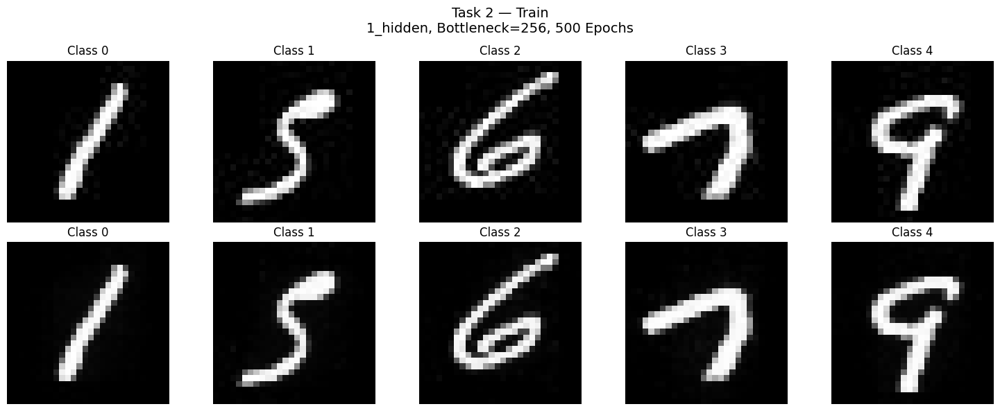

(array([[0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.],
        [0., 0., 0., ..., 0., 0., 0.]]),
 array([[2.6730463e-04, 2.3250964e-04, 2.9859404e-04, ..., 9.0685484e-05,
         8.2916507e-05, 1.4182850e-04],
        [1.6620287e-04, 1.7210815e-04, 3.0818817e-04, ..., 6.9190683e-05,
         5.6019493e-05, 7.0857452e-05],
        [4.0784851e-04, 2.4341547e-05, 7.9014299e-06, ..., 6.3562969e-05,
         8.0221464e-05, 5.7121808e-05],
        [1.7694545e-04, 1.3243452e-04, 1.3224586e-04, ..., 8.3761595e-05,
         9.4612893e-05, 1.6806969e-04],
        [2.3157644e-04, 2.8170391e-03, 8.4062944e-05, ..., 2.0045046e-04,
         1.8034206e-04, 1.1725450e-04]], dtype=float32))

In [ ]:
plot_reconstructions(
    model=model,
    X=X_train_flattened,
    y=y_train,
    indices=train_indices,
    dataset_name="Train",
    architecture="1_hidden",
    bottleneck_dim=256,
    epochs=500,
    save_dir=TASK2_500_FIG_DIR
)



1_hidden | Bottleneck=32 | 500 Epochs
Loaded: ae_1_hidden_32_best_500.pt
Architecture: 1_hidden | Bottleneck: 32 | Best Epoch: 114
Saved figure: /content/task2_checkpoints/figures_500_epochs/train_1_hidden_bottleneck_32_500epochs.png


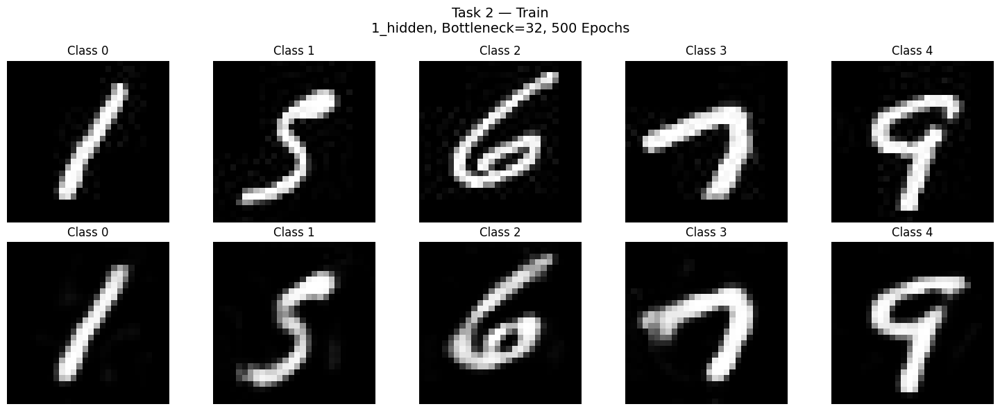

Saved figure: /content/task2_checkpoints/figures_500_epochs/validation_1_hidden_bottleneck_32_500epochs.png


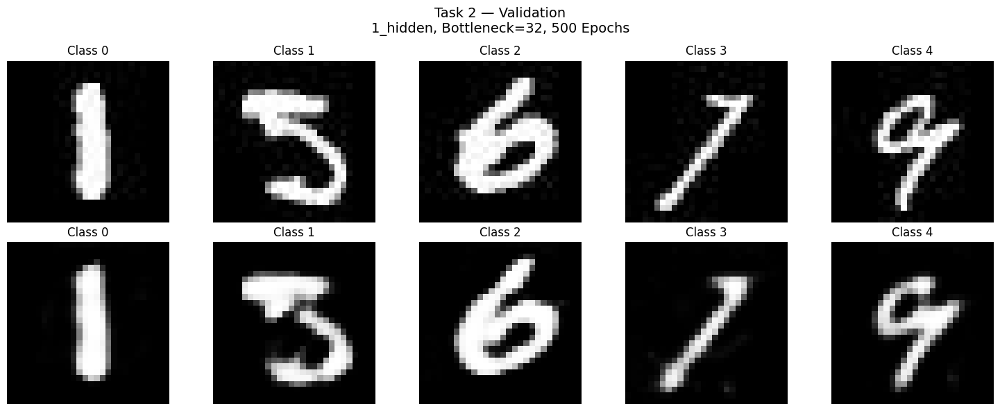

Saved figure: /content/task2_checkpoints/figures_500_epochs/test_1_hidden_bottleneck_32_500epochs.png


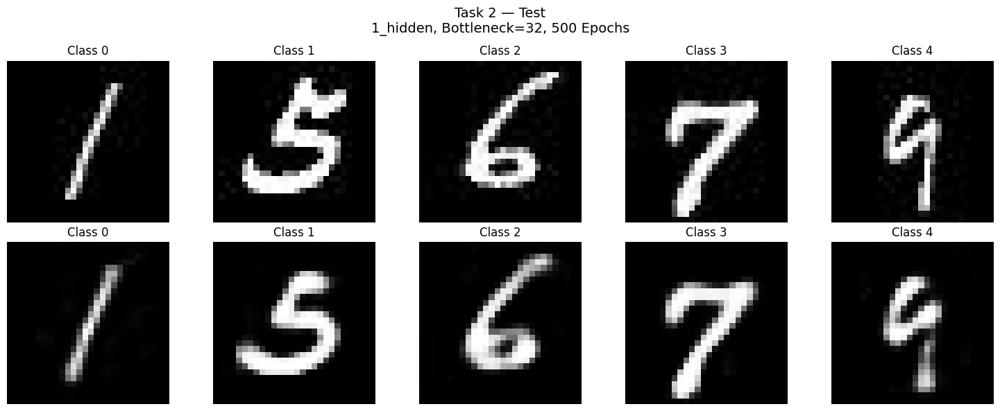



1_hidden | Bottleneck=64 | 500 Epochs
Loaded: ae_1_hidden_64_best_500.pt
Architecture: 1_hidden | Bottleneck: 64 | Best Epoch: 151
Saved figure: /content/task2_checkpoints/figures_500_epochs/train_1_hidden_bottleneck_64_500epochs.png


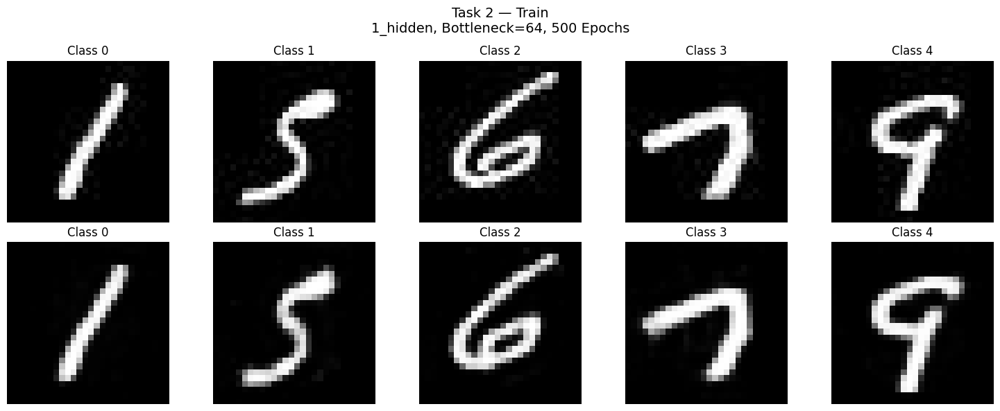

Saved figure: /content/task2_checkpoints/figures_500_epochs/validation_1_hidden_bottleneck_64_500epochs.png


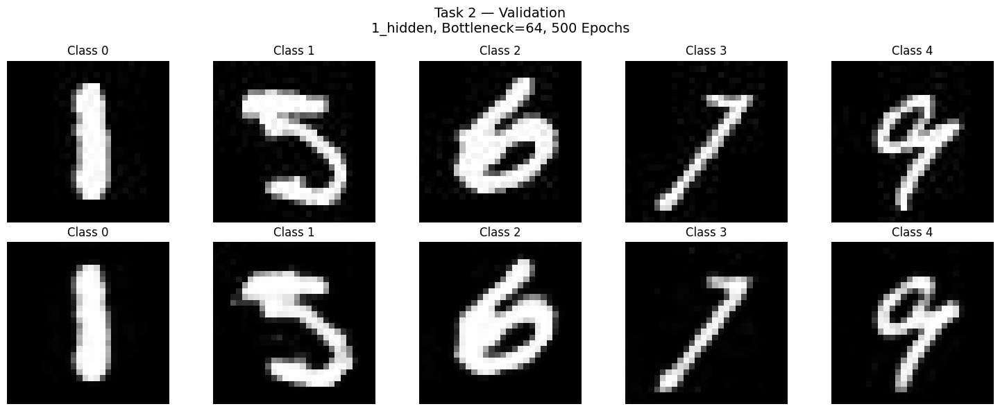

Saved figure: /content/task2_checkpoints/figures_500_epochs/test_1_hidden_bottleneck_64_500epochs.png


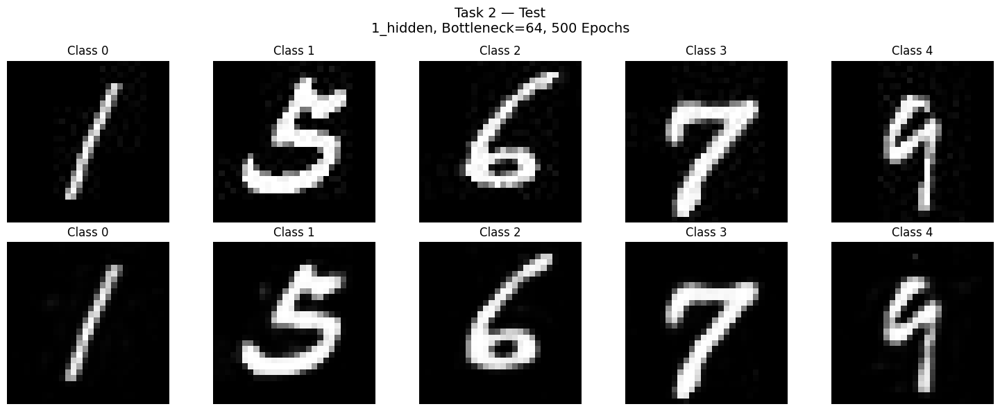



1_hidden | Bottleneck=128 | 500 Epochs
Loaded: ae_1_hidden_128_best_500.pt
Architecture: 1_hidden | Bottleneck: 128 | Best Epoch: 170
Saved figure: /content/task2_checkpoints/figures_500_epochs/train_1_hidden_bottleneck_128_500epochs.png


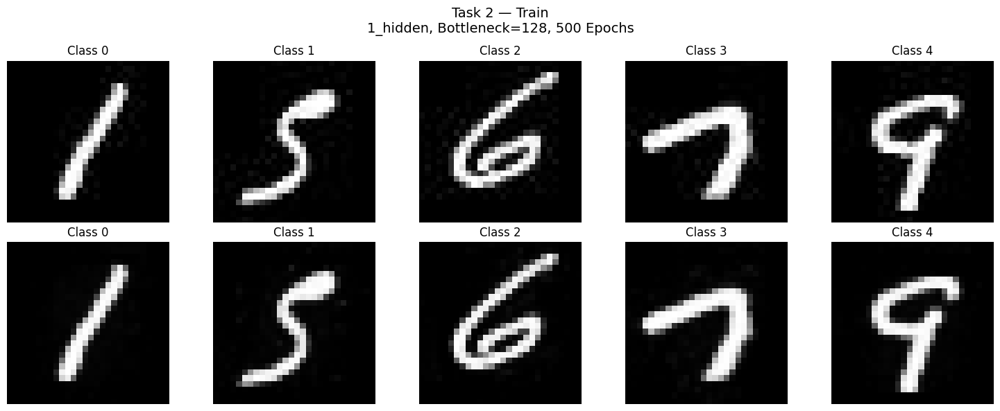

Saved figure: /content/task2_checkpoints/figures_500_epochs/validation_1_hidden_bottleneck_128_500epochs.png


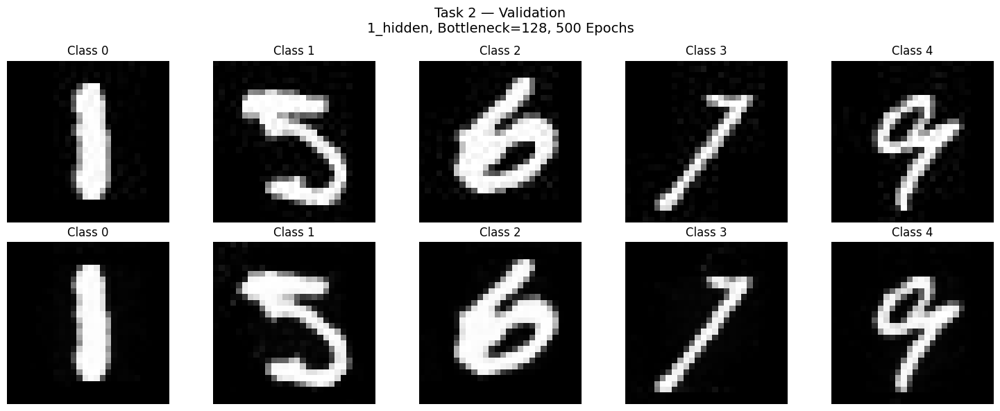

Saved figure: /content/task2_checkpoints/figures_500_epochs/test_1_hidden_bottleneck_128_500epochs.png


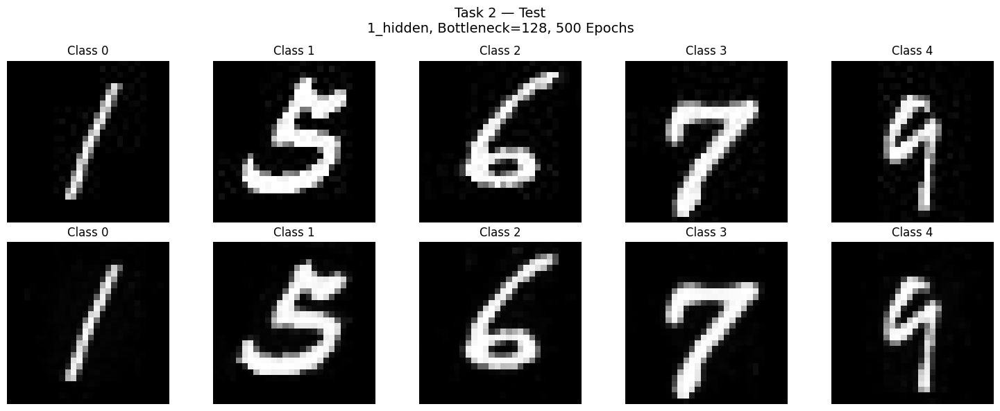



1_hidden | Bottleneck=256 | 500 Epochs
Loaded: ae_1_hidden_256_best_500.pt
Architecture: 1_hidden | Bottleneck: 256 | Best Epoch: 204
Saved figure: /content/task2_checkpoints/figures_500_epochs/train_1_hidden_bottleneck_256_500epochs.png


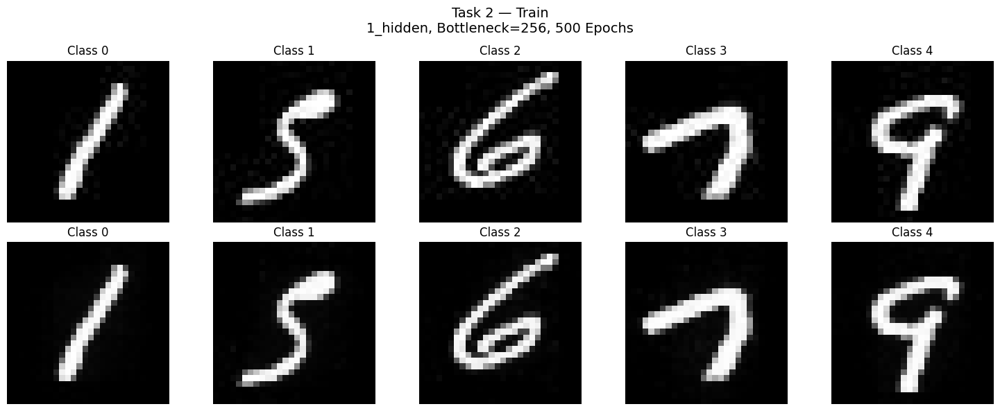

Saved figure: /content/task2_checkpoints/figures_500_epochs/validation_1_hidden_bottleneck_256_500epochs.png


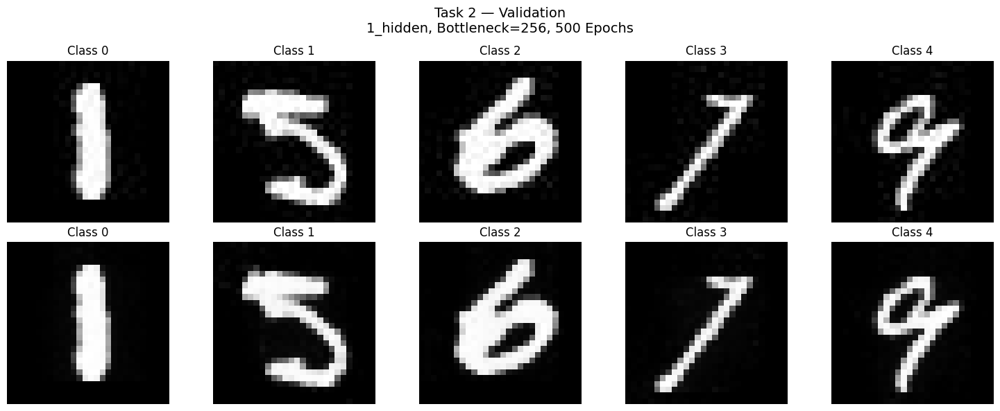

Saved figure: /content/task2_checkpoints/figures_500_epochs/test_1_hidden_bottleneck_256_500epochs.png


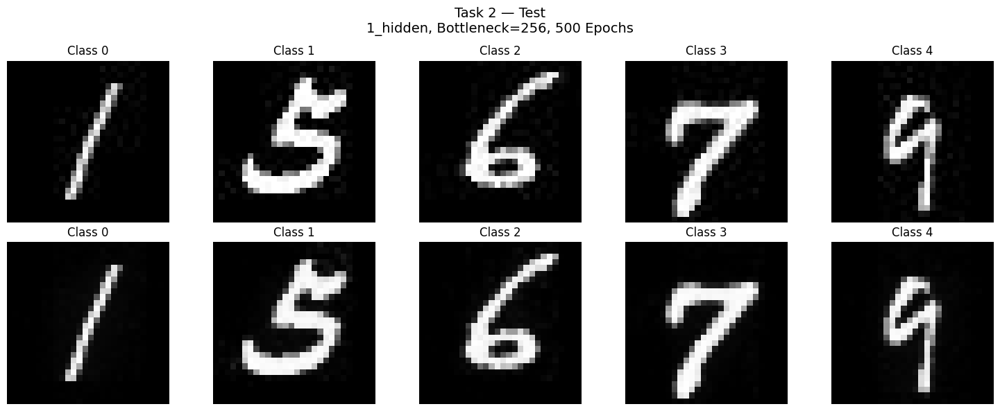



3_hidden | Bottleneck=32 | 500 Epochs
Loaded: ae_3_hidden_32_best_500.pt
Architecture: 3_hidden | Bottleneck: 32 | Best Epoch: 147
Saved figure: /content/task2_checkpoints/figures_500_epochs/train_3_hidden_bottleneck_32_500epochs.png


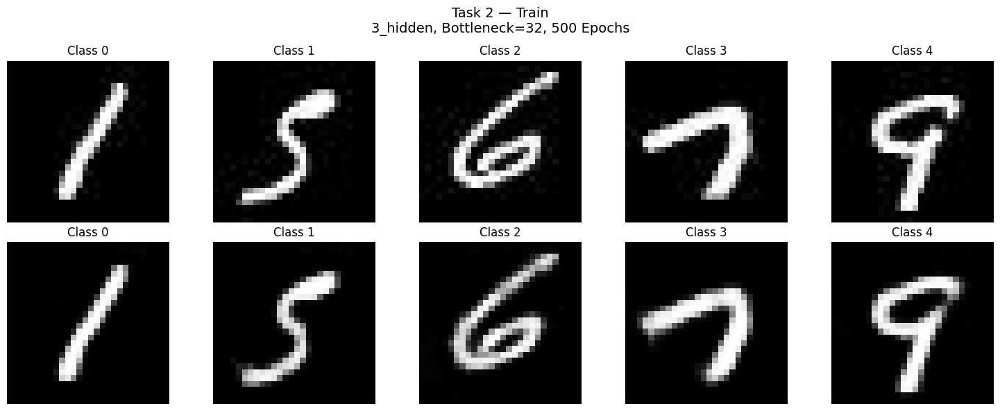

Saved figure: /content/task2_checkpoints/figures_500_epochs/validation_3_hidden_bottleneck_32_500epochs.png


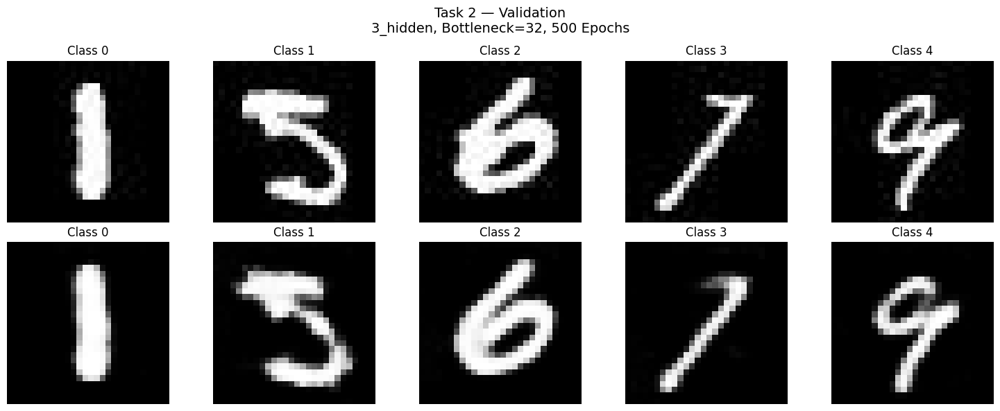

Saved figure: /content/task2_checkpoints/figures_500_epochs/test_3_hidden_bottleneck_32_500epochs.png


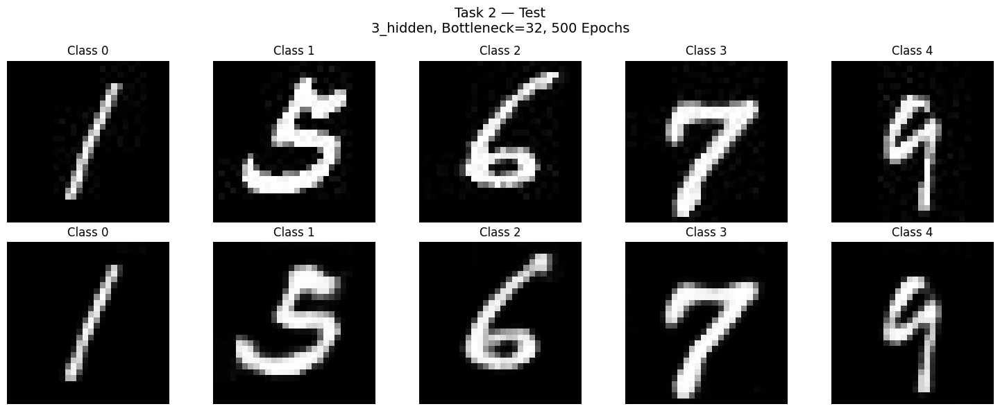



3_hidden | Bottleneck=64 | 500 Epochs
Loaded: ae_3_hidden_64_best_500.pt
Architecture: 3_hidden | Bottleneck: 64 | Best Epoch: 258
Saved figure: /content/task2_checkpoints/figures_500_epochs/train_3_hidden_bottleneck_64_500epochs.png


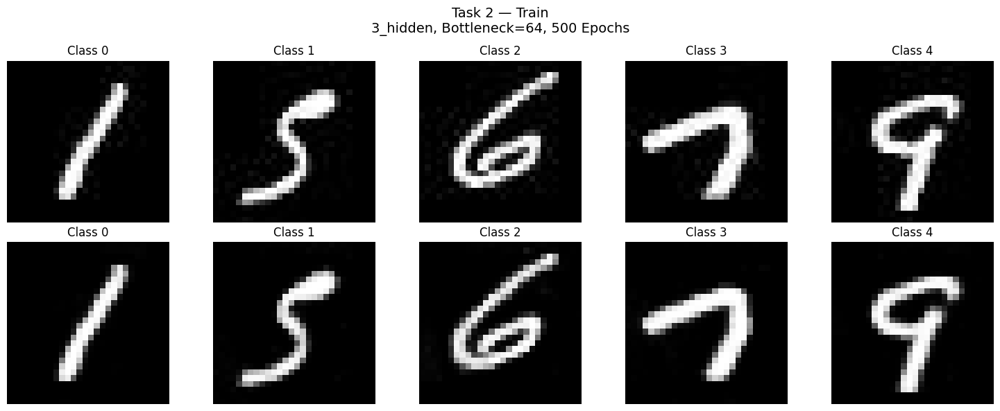

Saved figure: /content/task2_checkpoints/figures_500_epochs/validation_3_hidden_bottleneck_64_500epochs.png


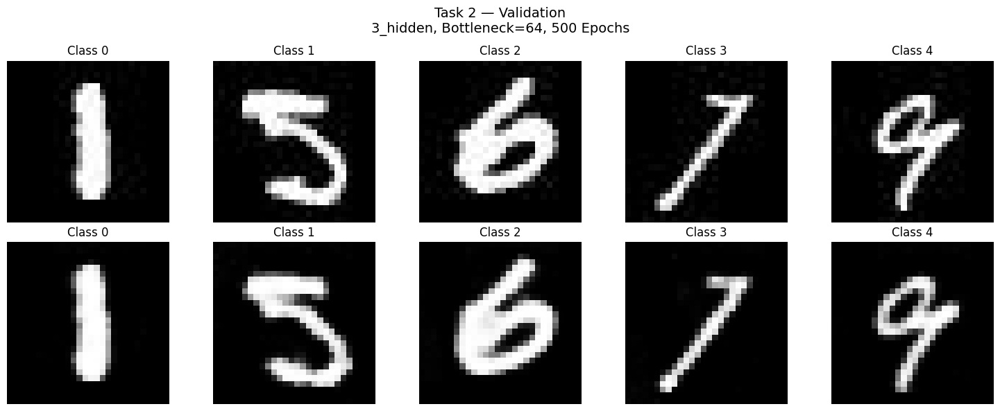

Saved figure: /content/task2_checkpoints/figures_500_epochs/test_3_hidden_bottleneck_64_500epochs.png


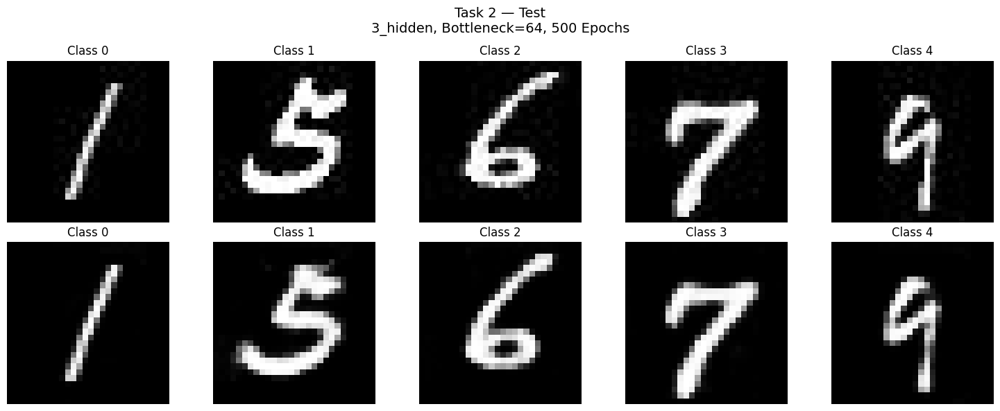



3_hidden | Bottleneck=128 | 500 Epochs
Loaded: ae_3_hidden_128_best_500.pt
Architecture: 3_hidden | Bottleneck: 128 | Best Epoch: 496
Saved figure: /content/task2_checkpoints/figures_500_epochs/train_3_hidden_bottleneck_128_500epochs.png


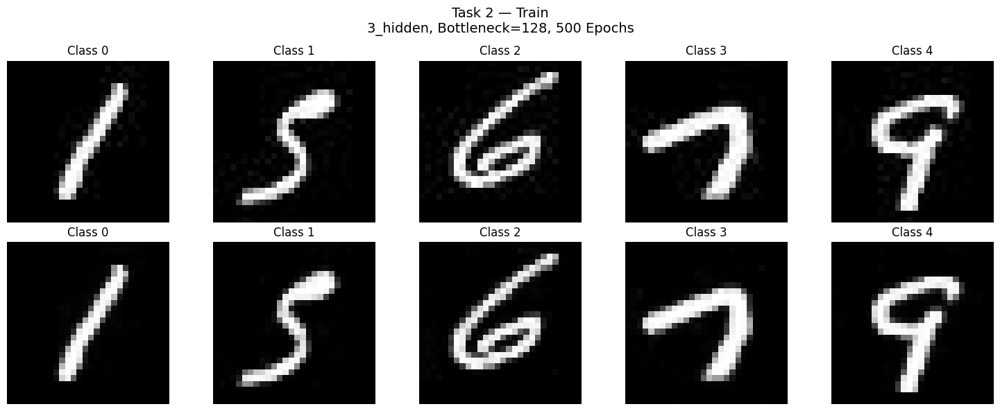

Saved figure: /content/task2_checkpoints/figures_500_epochs/validation_3_hidden_bottleneck_128_500epochs.png


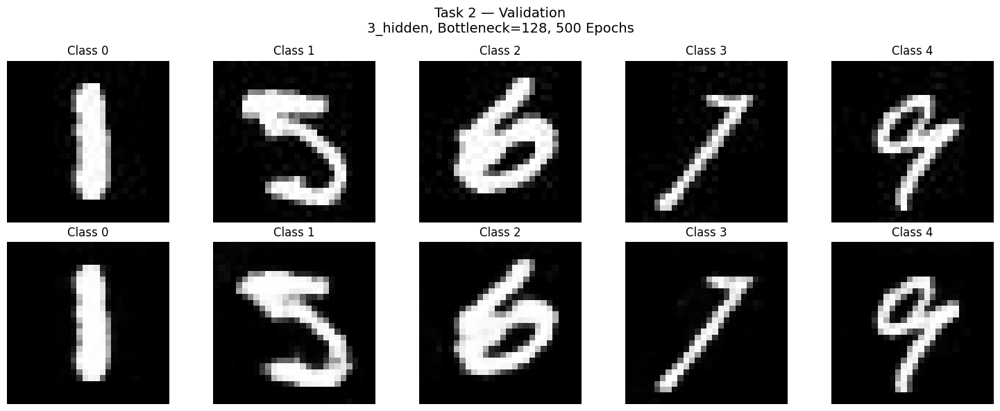

Saved figure: /content/task2_checkpoints/figures_500_epochs/test_3_hidden_bottleneck_128_500epochs.png


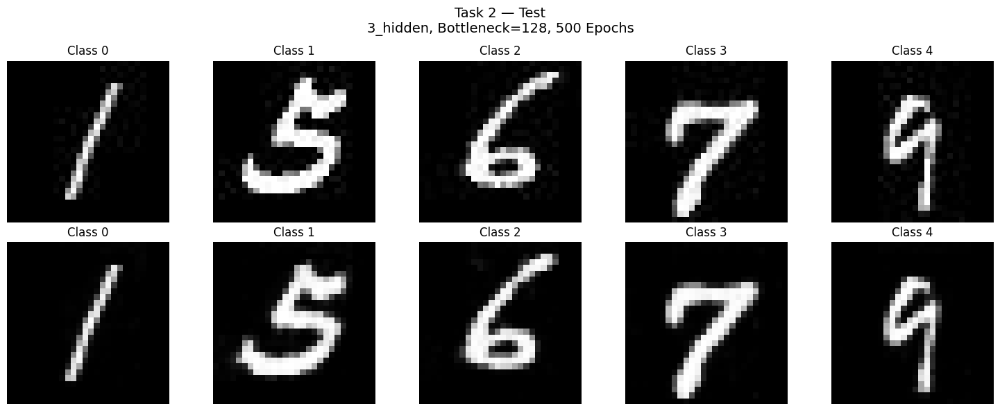



3_hidden | Bottleneck=256 | 500 Epochs
Loaded: ae_3_hidden_256_best_500.pt
Architecture: 3_hidden | Bottleneck: 256 | Best Epoch: 500
Saved figure: /content/task2_checkpoints/figures_500_epochs/train_3_hidden_bottleneck_256_500epochs.png


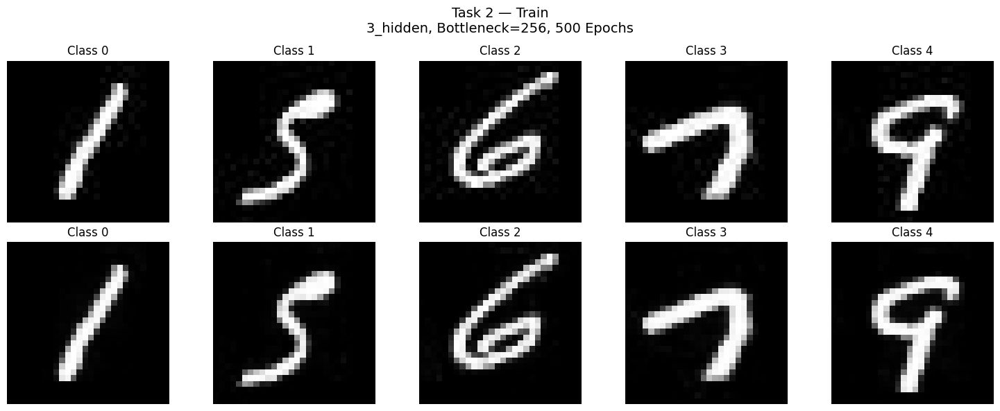

Saved figure: /content/task2_checkpoints/figures_500_epochs/validation_3_hidden_bottleneck_256_500epochs.png


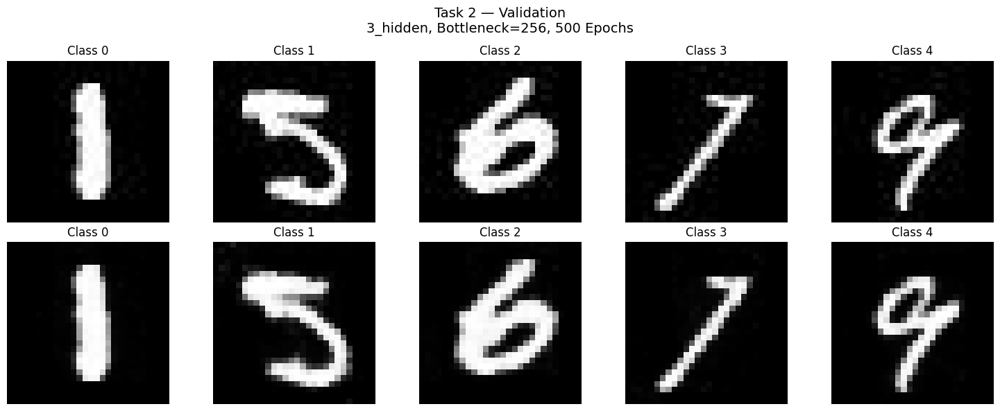

Saved figure: /content/task2_checkpoints/figures_500_epochs/test_3_hidden_bottleneck_256_500epochs.png


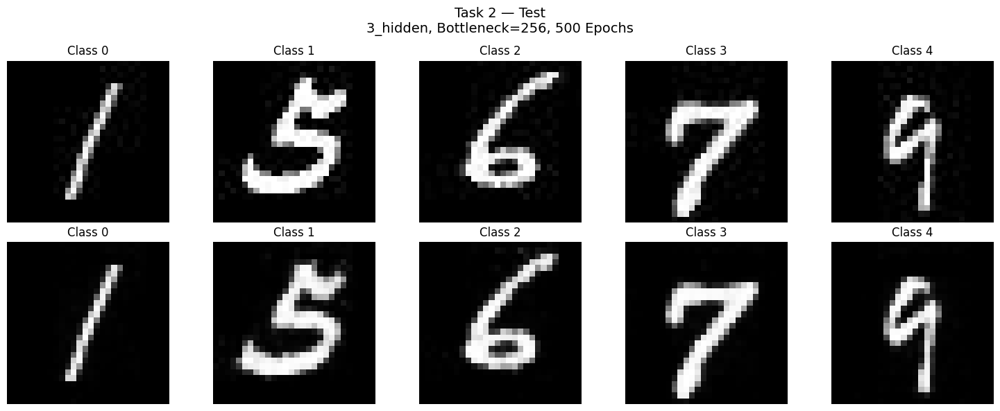

In [ ]:
# ==========================================
# GENERATE ALL OFFICIAL TASK 2 FIGURES
# 500-EPOCH MODELS
# ==========================================

AE_ARCHITECTURES = [
    "1_hidden",
    "3_hidden"
]

BOTTLENECK_DIMS = [
    32,
    64,
    128,
    256
]

datasets = [
    (
        "Train",
        X_train_flattened,
        y_train,
        train_indices
    ),
    (
        "Validation",
        X_val_flattened,
        y_val,
        val_indices
    ),
    (
        "Test",
        X_test_flattened,
        y_test,
        test_indices
    )
]

for architecture in AE_ARCHITECTURES:

    for bottleneck_dim in BOTTLENECK_DIMS:

        print("\n")
        print("=" * 80)
        print(
            f"{architecture} | "
            f"Bottleneck={bottleneck_dim} | "
            f"500 Epochs"
        )
        print("=" * 80)

        # Load saved model
        model, checkpoint = load_autoencoder_checkpoint(
            architecture=architecture,
            bottleneck_dim=bottleneck_dim,
            epochs=500
        )

        # Generate Train / Validation / Test figures
        for (
            dataset_name,
            X_data,
            y_data,
            indices
        ) in datasets:

            plot_reconstructions(
                model=model,
                X=X_data,
                y=y_data,
                indices=indices,
                dataset_name=dataset_name,
                architecture=architecture,
                bottleneck_dim=bottleneck_dim,
                epochs=500,
                save_dir=TASK2_500_FIG_DIR
            )

        # Free memory
        del model
        torch.cuda.empty_cache()

# ***TASK 3***

In [ ]:
import zipfile
import os

WEIGHT_ZIP = "1_hidden_layer_500.zip"

AE_WEIGHT_DIR = "/content/task2_1hidden_weights"

os.makedirs(
    AE_WEIGHT_DIR,
    exist_ok=True
)

with zipfile.ZipFile(
    WEIGHT_ZIP,
    "r"
) as zip_ref:

    zip_ref.extractall(
        AE_WEIGHT_DIR
    )

print(
    "Extracted to:",
    AE_WEIGHT_DIR
)

Extracted to: /content/task2_1hidden_weights


In [ ]:
import torch
import torch.nn as nn
import os
import numpy as np
import pandas as pd

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class Autoencoder(nn.Module):

    def __init__(
        self,
        input_dim=784,
        bottleneck_dim=32,
        architecture="1_hidden"
    ):

        super().__init__()

        if architecture == "1_hidden":

            self.encoder = nn.Linear(
                input_dim,
                bottleneck_dim
            )

            self.decoder = nn.Sequential(
                nn.Linear(
                    bottleneck_dim,
                    input_dim
                ),
                nn.Sigmoid()
            )

        elif architecture == "3_hidden":

            self.encoder = nn.Sequential(
                nn.Linear(
                    input_dim,
                    400
                ),
                nn.Sigmoid(),

                nn.Linear(
                    400,
                    bottleneck_dim
                )
            )

            self.decoder = nn.Sequential(
                nn.Linear(
                    bottleneck_dim,
                    400
                ),
                nn.Sigmoid(),

                nn.Linear(
                    400,
                    input_dim
                ),
                nn.Sigmoid()
            )

        else:
            raise ValueError(
                "architecture must be "
                "'1_hidden' or '3_hidden'"
            )

    def encode(self, x):
        return self.encoder(x)

    def decode(self, z):
        return self.decoder(z)

    def forward(self, x):

        z = self.encode(x)

        reconstruction = self.decode(z)

        return reconstruction

In [ ]:
def load_task3_autoencoder(
    checkpoint_path
):

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )

    model = Autoencoder(
        input_dim=checkpoint["input_dim"],
        bottleneck_dim=checkpoint["bottleneck_dim"],
        architecture=checkpoint["architecture"]
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(device)
    model.eval()

    return model, checkpoint

In [ ]:
import glob

ae_checkpoints = glob.glob(
    os.path.join(
        AE_WEIGHT_DIR,
        "**",
        "*.pt"
    ),
    recursive=True
)

print(
    f"Found {len(ae_checkpoints)} checkpoint files:"
)

for path in ae_checkpoints:
    print(path)

Found 4 checkpoint files:
/content/task2_1hidden_weights/1_hidden_layer_500/ae_1_hidden_32_best_500.pt
/content/task2_1hidden_weights/1_hidden_layer_500/ae_1_hidden_128_best_500.pt
/content/task2_1hidden_weights/1_hidden_layer_500/ae_1_hidden_256_best_500.pt
/content/task2_1hidden_weights/1_hidden_layer_500/ae_1_hidden_64_best_500.pt


In [ ]:
TASK3_AE_CHECKPOINTS = {}

for bottleneck_dim in [32, 64, 128, 256]:

    matches = [
        path
        for path in ae_checkpoints
        if (
            f"1_hidden_{bottleneck_dim}_best_500.pt"
            in os.path.basename(path)
        )
    ]

    if len(matches) == 0:
        raise FileNotFoundError(
            f"500-epoch 1-hidden AE not found "
            f"for bottleneck {bottleneck_dim}"
        )

    if len(matches) > 1:
        print(
            f"WARNING: Multiple matches for "
            f"bottleneck {bottleneck_dim}"
        )
        print(matches)

    TASK3_AE_CHECKPOINTS[bottleneck_dim] = matches[0]


print("\nOfficial Task 3 AE checkpoints:")

for dim, path in TASK3_AE_CHECKPOINTS.items():
    print(
        f"{dim}: {path}"
    )


Official Task 3 AE checkpoints:
32: /content/task2_1hidden_weights/1_hidden_layer_500/ae_1_hidden_32_best_500.pt
64: /content/task2_1hidden_weights/1_hidden_layer_500/ae_1_hidden_64_best_500.pt
128: /content/task2_1hidden_weights/1_hidden_layer_500/ae_1_hidden_128_best_500.pt
256: /content/task2_1hidden_weights/1_hidden_layer_500/ae_1_hidden_256_best_500.pt


In [ ]:
X_train_ae = torch.from_numpy(
    X_train_flattened.astype(np.float32)
).to(device)

X_val_ae = torch.from_numpy(
    X_val_flattened.astype(np.float32)
).to(device)

X_test_ae = torch.from_numpy(
    X_test_flattened.astype(np.float32)
).to(device)

y_train_tensor = torch.from_numpy(
    y_train.astype(np.int64)
).to(device)

y_val_tensor = torch.from_numpy(
    y_val.astype(np.int64)
).to(device)

y_test_tensor = torch.from_numpy(
    y_test.astype(np.int64)
).to(device)

print("Train:", X_train_ae.shape)
print("Val  :", X_val_ae.shape)
print("Test :", X_test_ae.shape)

Train: torch.Size([11385, 784])
Val  : torch.Size([3795, 784])
Test : torch.Size([3795, 784])


In [ ]:
def extract_compressed_representation(
    model,
    X
):

    model.eval()

    with torch.no_grad():

        compressed = model.encode(X)

    return compressed

In [ ]:
compressed_train = {}
compressed_val = {}
compressed_test = {}

for bottleneck_dim in [32, 64, 128, 256]:

    print("\n")
    print("=" * 70)
    print(
        f"Extracting {bottleneck_dim}-D representation"
    )
    print("=" * 70)

    checkpoint_path = (
        TASK3_AE_CHECKPOINTS[bottleneck_dim]
    )

    model, checkpoint = load_task3_autoencoder(
        checkpoint_path
    )

    compressed_train[bottleneck_dim] = (
        extract_compressed_representation(
            model,
            X_train_ae
        )
    )

    compressed_val[bottleneck_dim] = (
        extract_compressed_representation(
            model,
            X_val_ae
        )
    )

    compressed_test[bottleneck_dim] = (
        extract_compressed_representation(
            model,
            X_test_ae
        )
    )

    print(
        "Train:",
        compressed_train[bottleneck_dim].shape
    )

    print(
        "Val:",
        compressed_val[bottleneck_dim].shape
    )

    print(
        "Test:",
        compressed_test[bottleneck_dim].shape
    )

    del model
    torch.cuda.empty_cache()



Extracting 32-D representation
Train: torch.Size([11385, 32])
Val: torch.Size([3795, 32])
Test: torch.Size([3795, 32])


Extracting 64-D representation
Train: torch.Size([11385, 64])
Val: torch.Size([3795, 64])
Test: torch.Size([3795, 64])


Extracting 128-D representation
Train: torch.Size([11385, 128])
Val: torch.Size([3795, 128])
Test: torch.Size([3795, 128])


Extracting 256-D representation
Train: torch.Size([11385, 256])
Val: torch.Size([3795, 256])
Test: torch.Size([3795, 256])


In [ ]:
TASK3_REP_DIR = "/content/task3_compressed_representations"

os.makedirs(
    TASK3_REP_DIR,
    exist_ok=True
)

for dim in [32, 64, 128, 256]:

    np.save(
        os.path.join(
            TASK3_REP_DIR,
            f"train_{dim}.npy"
        ),
        compressed_train[dim]
        .cpu()
        .numpy()
    )

    np.save(
        os.path.join(
            TASK3_REP_DIR,
            f"val_{dim}.npy"
        ),
        compressed_val[dim]
        .cpu()
        .numpy()
    )

    np.save(
        os.path.join(
            TASK3_REP_DIR,
            f"test_{dim}.npy"
        ),
        compressed_test[dim]
        .cpu()
        .numpy()
    )

print(
    "Compressed representations saved to:",
    TASK3_REP_DIR
)

Compressed representations saved to: /content/task3_compressed_representations


In [ ]:
!zip -r task3_compressed_representations.zip task3_compressed_representations

  adding: task3_compressed_representations/ (stored 0%)
  adding: task3_compressed_representations/val_32.npy (deflated 8%)
  adding: task3_compressed_representations/test_256.npy (deflated 7%)
  adding: task3_compressed_representations/val_64.npy (deflated 8%)
  adding: task3_compressed_representations/train_64.npy (deflated 8%)
  adding: task3_compressed_representations/train_256.npy (deflated 7%)
  adding: task3_compressed_representations/test_32.npy (deflated 8%)
  adding: task3_compressed_representations/val_128.npy (deflated 8%)
  adding: task3_compressed_representations/train_128.npy (deflated 7%)
  adding: task3_compressed_representations/test_64.npy (deflated 8%)
  adding: task3_compressed_representations/test_128.npy (deflated 8%)
  adding: task3_compressed_representations/val_256.npy (deflated 7%)
  adding: task3_compressed_representations/train_32.npy (deflated 8%)


In [ ]:
class FCNN(nn.Module):

    def __init__(
        self,
        input_dim,
        hidden_layers,
        num_classes=5
    ):

        super().__init__()

        layers = []

        prev_dim = input_dim

        for hidden_dim in hidden_layers:

            linear = nn.Linear(
                prev_dim,
                hidden_dim
            )

            nn.init.xavier_uniform_(
                linear.weight
            )

            nn.init.zeros_(
                linear.bias
            )

            layers.append(linear)
            layers.append(nn.Tanh())

            prev_dim = hidden_dim

        output = nn.Linear(
            prev_dim,
            num_classes
        )

        nn.init.xavier_uniform_(
            output.weight
        )

        nn.init.zeros_(
            output.bias
        )

        layers.append(output)

        self.network = nn.Sequential(
            *layers
        )

    def forward(self, x):
        return self.network(x)

In [ ]:
ARCHITECTURES = {

    "3_hidden_best":
        [128, 64, 32],

    "4_hidden_best":
        [128, 64, 32, 16],

    "4_hidden_normal":
        [256, 128, 64, 32],

    "5_hidden_best":
        [256, 128, 64, 32, 16],
}

for name, layers in ARCHITECTURES.items():

    print(
        name,
        "→",
        layers
    )

3_hidden_best → [128, 64, 32]
4_hidden_best → [128, 64, 32, 16]
4_hidden_normal → [256, 128, 64, 32]
5_hidden_best → [256, 128, 64, 32, 16]


In [ ]:
TASK3_CHECKPOINT_DIR = "/content/task3_checkpoints"

os.makedirs(
    TASK3_CHECKPOINT_DIR,
    exist_ok=True
)

print(
    "Task 3 checkpoint directory:",
    TASK3_CHECKPOINT_DIR
)

Task 3 checkpoint directory: /content/task3_checkpoints


In [ ]:
def save_task3_checkpoint(
    model,
    optimizer,
    history,
    representation_dim,
    architecture_name,
    hidden_layers,
    best_val_accuracy,
    best_epoch
):

    filename = (
        f"ae1_{representation_dim}_"
        f"{architecture_name}_best.pt"
    )

    filepath = os.path.join(
        TASK3_CHECKPOINT_DIR,
        filename
    )

    checkpoint = {

        "task": "Task 3",

        "source": "1-hidden-layer autoencoder",

        "ae_epochs": 500,

        "representation_dim":
            representation_dim,

        "architecture":
            architecture_name,

        "hidden_layers":
            hidden_layers,

        "input_dim":
            representation_dim,

        "num_classes":
            5,

        "best_val_accuracy":
            best_val_accuracy,

        "best_epoch":
            best_epoch,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "history":
            history,

        "learning_rate":
            0.001,

        "momentum":
            0.9,

        "batch_size":
            1,

        "activation":
            "tanh",

        "initialization":
            "xavier_uniform",

        "seed":
            42
    }

    torch.save(
        checkpoint,
        filepath
    )

    print(
        f"Saved: {filepath}"
    )

    return filepath

In [ ]:
def iterate_minibatches(X, y, batch_size=1, shuffle=True):

    n_samples = X.shape[0]

    if shuffle:
        indices = torch.randperm(n_samples, device=X.device)
    else:
        indices = torch.arange(n_samples, device=X.device)

    for start in range(0, n_samples, batch_size):

        batch_indices = indices[start:start + batch_size]

        yield X[batch_indices], y[batch_indices]


def train_model(
    model,
    X_train,
    y_train,
    X_val,
    y_val,
    max_epochs=100,
    batch_size=1,
    learning_rate=0.001,
    momentum=0.9,
    convergence_threshold=1e-4,
    warmup_epochs=2
):

    model = model.to(device)

    criterion = nn.CrossEntropyLoss()

    optimizer = optim.SGD(
        model.parameters(),
        lr=learning_rate,
        momentum=momentum
    )

    history = {
        "train_loss": [],
        "train_accuracy": [],
        "val_accuracy": []
    }

    best_val_accuracy = -1.0
    best_epoch = 0
    best_state_dict = None

    previous_train_loss = None

    for epoch in range(max_epochs):

        # ==========================================
        # TRAINING
        # ==========================================

        model.train()

        total_loss = 0.0
        correct = 0
        total = 0

        for X_batch, y_batch in iterate_minibatches(
            X_train,
            y_train,
            batch_size=batch_size,
            shuffle=True
        ):

            optimizer.zero_grad()

            outputs = model(X_batch)

            loss = criterion(outputs, y_batch)

            loss.backward()

            optimizer.step()

            total_loss += loss.item() * X_batch.size(0)

            predictions = torch.argmax(outputs, dim=1)

            correct += (predictions == y_batch).sum().item()

            total += y_batch.size(0)

        # Average training loss
        train_loss = total_loss / total

        train_accuracy = (
            100.0 * correct / total
        )

        # ==========================================
        # VALIDATION
        # ==========================================

        model.eval()

        with torch.no_grad():

            val_outputs = model(X_val)

            val_predictions = torch.argmax(
                val_outputs,
                dim=1
            )

            val_accuracy = (
                100.0
                * (val_predictions == y_val).sum().item()
                / y_val.size(0)
            )

        # ==========================================
        # SAVE HISTORY
        # ==========================================

        history["train_loss"].append(train_loss)
        history["train_accuracy"].append(train_accuracy)
        history["val_accuracy"].append(val_accuracy)

        # ==========================================
        # SAVE BEST VALIDATION MODEL
        # ==========================================

        if val_accuracy > best_val_accuracy:

            best_val_accuracy = val_accuracy
            best_epoch = epoch + 1

            best_state_dict = {
                key: value.detach().cpu().clone()
                for key, value in model.state_dict().items()
            }

        # ==========================================
        # CONVERGENCE CHECK
        # ==========================================

        loss_difference = None

        if previous_train_loss is not None:

            loss_difference = abs(
                train_loss - previous_train_loss
            )

        print(
            f"Epoch [{epoch + 1:3d}/{max_epochs}] "
            f"Loss: {train_loss:.6f} "
            f"Train Acc: {train_accuracy:.4f}% "
            f"Val Acc: {val_accuracy:.4f}%"
            + (
                f" | ΔLoss: {loss_difference:.6f}"
                if loss_difference is not None
                else ""
            )
        )

        # ------------------------------------------
        # A3 CONVERGENCE RULE
        #
        # Do NOT check during first 2 epochs.
        # ------------------------------------------

        if (
            epoch + 1 > warmup_epochs
            and loss_difference is not None
            and loss_difference < convergence_threshold
        ):

            print(
                f"\nConverged at epoch {epoch + 1}"
                f" | ΔLoss = {loss_difference:.8f}"
                f" < {convergence_threshold}"
            )

            break

        previous_train_loss = train_loss

    # ==========================================
    # RESTORE BEST VALIDATION MODEL
    # ==========================================

    model.load_state_dict(best_state_dict)

    print(
        f"\nBest validation accuracy: "
        f"{best_val_accuracy:.4f}% "
        f"(Epoch {best_epoch})"
    )

    return (
        model,
        optimizer,
        history,
        best_val_accuracy,
        best_epoch
    )

In [ ]:
# ==========================================
# TASK 3 — RUN ALL 16 CLASSIFIERS
# ==========================================

REPRESENTATION_DIMS = [
    32,
    64,
    128,
    256
]

all_task3_results = []

for representation_dim in REPRESENTATION_DIMS:

    print("\n")
    print("=" * 80)
    print(
        f"        TASK 3 REPRESENTATION: "
        f"{representation_dim}-D"
    )
    print("=" * 80)

    X_train_rep = (
        compressed_train[representation_dim]
    )

    X_val_rep = (
        compressed_val[representation_dim]
    )

    for architecture_name, hidden_layers in ARCHITECTURES.items():

        print("\n")
        print("-" * 80)
        print(
            f"Representation : "
            f"{representation_dim}-D"
        )
        print(
            f"Architecture   : "
            f"{architecture_name}"
        )
        print(
            f"Hidden layers  : "
            f"{hidden_layers}"
        )
        print("-" * 80)

        # Reproducibility
        torch.manual_seed(SEED)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)

        # Create FCNN
        model = FCNN(
            input_dim=representation_dim,
            hidden_layers=hidden_layers,
            num_classes=5
        )

        # Train using EXACT Task 1 training procedure
        (
            model,
            optimizer,
            history,
            best_val_accuracy,
            best_epoch
        ) = train_model(
            model,
            X_train_rep,
            y_train_tensor,
            X_val_rep,
            y_val_tensor,
            batch_size=1,
            learning_rate=0.001,
            momentum=0.9
        )

        # Save checkpoint
        checkpoint_path = save_task3_checkpoint(
            model=model,
            optimizer=optimizer,
            history=history,
            representation_dim=representation_dim,
            architecture_name=architecture_name,
            hidden_layers=hidden_layers,
            best_val_accuracy=best_val_accuracy,
            best_epoch=best_epoch
        )

        # Save result
        all_task3_results.append({

            "representation_dim":
                representation_dim,

            "architecture":
                architecture_name,

            "hidden_layers":
                str(hidden_layers),

            "best_epoch":
                best_epoch,

            "best_val_accuracy":
                best_val_accuracy,

            "checkpoint":
                checkpoint_path
        })

        print(
            f"\nCompleted: "
            f"{representation_dim}-D | "
            f"{architecture_name} | "
            f"Best Val = "
            f"{best_val_accuracy:.4f}%"
        )

        del model
        del optimizer

        torch.cuda.empty_cache()



        TASK 3 REPRESENTATION: 32-D


--------------------------------------------------------------------------------
Representation : 32-D
Architecture   : 3_hidden_best
Hidden layers  : [128, 64, 32]
--------------------------------------------------------------------------------
Epoch [  1/100] Loss: 0.152147 Train Acc: 95.0549% Val Acc: 95.7049%
Epoch [  2/100] Loss: 0.074158 Train Acc: 97.6460% Val Acc: 97.7075% | ΔLoss: 0.077990
Epoch [  3/100] Loss: 0.050345 Train Acc: 98.1643% Val Acc: 97.6548% | ΔLoss: 0.023813
Epoch [  4/100] Loss: 0.042556 Train Acc: 98.7352% Val Acc: 97.5758% | ΔLoss: 0.007789
Epoch [  5/100] Loss: 0.035726 Train Acc: 98.6825% Val Acc: 97.5231% | ΔLoss: 0.006829
Epoch [  6/100] Loss: 0.025272 Train Acc: 99.2446% Val Acc: 98.1818% | ΔLoss: 0.010454
Epoch [  7/100] Loss: 0.017575 Train Acc: 99.4379% Val Acc: 97.7075% | ΔLoss: 0.007697
Epoch [  8/100] Loss: 0.017864 Train Acc: 99.4642% Val Acc: 97.9710% | ΔLoss: 0.000290
Epoch [  9/100] Loss: 0.010520 Train

In [ ]:
import pandas as pd

results_df = pd.DataFrame(all_task3_results)

results_df = results_df.sort_values(
    ["representation_dim", "best_val_accuracy"],
    ascending=[True, False]
)

display(results_df)

,representation_dim,architecture,hidden_layers,best_epoch,best_val_accuracy,checkpoint
2,32,4_hidden_normal,"[256, 128, 64, 32]",11,98.682477,/content/task3_checkpoints/ae1_32_4_hidden_nor...
0,32,3_hidden_best,"[128, 64, 32]",24,98.629776,/content/task3_checkpoints/ae1_32_3_hidden_bes...
1,32,4_hidden_best,"[128, 64, 32, 16]",12,98.366271,/content/task3_checkpoints/ae1_32_4_hidden_bes...
3,32,5_hidden_best,"[256, 128, 64, 32, 16]",5,97.997365,/content/task3_checkpoints/ae1_32_5_hidden_bes...
5,64,4_hidden_best,"[128, 64, 32, 16]",19,98.550725,/content/task3_checkpoints/ae1_64_4_hidden_bes...
4,64,3_hidden_best,"[128, 64, 32]",9,98.445323,/content/task3_checkpoints/ae1_64_3_hidden_bes...
6,64,4_hidden_normal,"[256, 128, 64, 32]",10,98.366271,/content/task3_checkpoints/ae1_64_4_hidden_nor...
7,64,5_hidden_best,"[256, 128, 64, 32, 16]",8,98.339921,/content/task3_checkpoints/ae1_64_5_hidden_bes...
10,128,4_hidden_normal,"[256, 128, 64, 32]",11,98.524374,/content/task3_checkpoints/ae1_128_4_hidden_no...
11,128,5_hidden_best,"[256, 128, 64, 32, 16]",12,98.445323,/content/task3_checkpoints/ae1_128_5_hidden_be...


In [ ]:
RESULTS_DIR = os.path.join(
    "task3_checkpoints",
    "results"
)

os.makedirs(RESULTS_DIR, exist_ok=True)

results_csv = os.path.join(
    RESULTS_DIR,
    "task3_validation_results.csv"
)

results_df.to_csv(
    results_csv,
    index=False
)

print("Results saved to:", results_csv)

Results saved to: task3_checkpoints/results/task3_validation_results.csv


In [ ]:
print(compressed_test.keys())

for dim in [32, 64, 128, 256]:
    print(
        dim,
        compressed_test[dim].shape
    )

dict_keys([32, 64, 128, 256])
32 torch.Size([3795, 32])
64 torch.Size([3795, 64])
128 torch.Size([3795, 128])
256 torch.Size([3795, 256])


In [ ]:
# ==========================================
# TASK 3 — TEST EVALUATION
# ==========================================

from sklearn.metrics import accuracy_score, confusion_matrix


def evaluate_task3_test(
    model,
    X_test,
    y_test
):

    model.eval()

    with torch.no_grad():

        outputs = model(X_test)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

    y_true = y_test.cpu().numpy()
    y_pred = predictions.cpu().numpy()

    test_accuracy = (
        100.0 *
        accuracy_score(
            y_true,
            y_pred
        )
    )

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    return (
        test_accuracy,
        cm,
        y_true,
        y_pred
    )

In [ ]:
import glob
import os

TASK3_CHECKPOINT_FILES = glob.glob(
    "/content/**/ae1_*_best.pt",
    recursive=True
)

print(
    f"Found {len(TASK3_CHECKPOINT_FILES)} Task 3 checkpoints"
)

for path in TASK3_CHECKPOINT_FILES:
    print(path)

Found 16 Task 3 checkpoints
/content/task3_checkpoints/ae1_32_3_hidden_best_best.pt
/content/task3_checkpoints/ae1_256_3_hidden_best_best.pt
/content/task3_checkpoints/ae1_32_5_hidden_best_best.pt
/content/task3_checkpoints/ae1_64_3_hidden_best_best.pt
/content/task3_checkpoints/ae1_64_5_hidden_best_best.pt
/content/task3_checkpoints/ae1_64_4_hidden_normal_best.pt
/content/task3_checkpoints/ae1_128_3_hidden_best_best.pt
/content/task3_checkpoints/ae1_64_4_hidden_best_best.pt
/content/task3_checkpoints/ae1_128_4_hidden_normal_best.pt
/content/task3_checkpoints/ae1_256_4_hidden_best_best.pt
/content/task3_checkpoints/ae1_256_4_hidden_normal_best.pt
/content/task3_checkpoints/ae1_256_5_hidden_best_best.pt
/content/task3_checkpoints/ae1_128_4_hidden_best_best.pt
/content/task3_checkpoints/ae1_32_4_hidden_best_best.pt
/content/task3_checkpoints/ae1_128_5_hidden_best_best.pt
/content/task3_checkpoints/ae1_32_4_hidden_normal_best.pt


In [ ]:
def find_task3_checkpoint(
    representation_dim,
    architecture_name
):

    filename = (
        f"ae1_{representation_dim}_"
        f"{architecture_name}_best.pt"
    )

    matches = [
        path
        for path in TASK3_CHECKPOINT_FILES
        if os.path.basename(path) == filename
    ]

    if len(matches) == 0:
        raise FileNotFoundError(
            f"Checkpoint not found: {filename}"
        )

    return matches[0]

In [ ]:
def load_task3_classifier(
    representation_dim,
    architecture_name
):

    filepath = find_task3_checkpoint(
        representation_dim,
        architecture_name
    )

    checkpoint = torch.load(
        filepath,
        map_location=device
    )

    model = FCNN(
        input_dim=checkpoint["input_dim"],
        hidden_layers=checkpoint["hidden_layers"],
        num_classes=checkpoint["num_classes"]
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(device)
    model.eval()

    print(
        f"Loaded: {filepath}"
    )

    print(
        f"Representation: "
        f"{representation_dim}-D"
    )

    print(
        f"Architecture: "
        f"{architecture_name}"
    )

    print(
        f"Best validation accuracy: "
        f"{checkpoint['best_val_accuracy']:.6f}%"
    )

    print(
        f"Best epoch: "
        f"{checkpoint['best_epoch']}"
    )

    return model, checkpoint

In [ ]:
# ==========================================
# TASK 3 — SELECT BEST ARCHITECTURE
# PER REPRESENTATION
# ==========================================

task3_validation_df = pd.read_csv(
    "task3_checkpoints/results/task3_validation_results.csv"
)

best_task3_models = (
    task3_validation_df
    .sort_values(
        "best_val_accuracy",
        ascending=False
    )
    .groupby(
        "representation_dim",
        as_index=False
    )
    .first()
    .sort_values(
        "representation_dim"
    )
)

display(
    best_task3_models[
        [
            "representation_dim",
            "architecture",
            "hidden_layers",
            "best_epoch",
            "best_val_accuracy"
        ]
    ]
)

,representation_dim,architecture,hidden_layers,best_epoch,best_val_accuracy
0,32,4_hidden_normal,"[256, 128, 64, 32]",11,98.682477
1,64,4_hidden_best,"[128, 64, 32, 16]",19,98.550725
2,128,4_hidden_normal,"[256, 128, 64, 32]",11,98.524374
3,256,5_hidden_best,"[256, 128, 64, 32, 16]",13,98.445323


In [ ]:
# ==========================================
# TASK 3 — TEST THE FOUR WINNING MODELS
# ==========================================

task3_test_results = []

task3_confusion_matrices = {}


for _, row in best_task3_models.iterrows():

    representation_dim = int(
        row["representation_dim"]
    )

    architecture_name = (
        row["architecture"]
    )

    print("\n")
    print("=" * 80)
    print(
        f"Task 3 | "
        f"{representation_dim}-D | "
        f"{architecture_name}"
    )
    print("=" * 80)

    # --------------------------------------
    # Load saved best-validation classifier
    # --------------------------------------

    model, checkpoint = load_task3_classifier(
        representation_dim,
        architecture_name
    )

    # --------------------------------------
    # Test representation
    # --------------------------------------

    X_test_rep = compressed_test[
        representation_dim
    ]

    # --------------------------------------
    # Test
    # --------------------------------------

    (
        test_accuracy,
        cm,
        y_true,
        y_pred
    ) = evaluate_task3_test(
        model,
        X_test_rep,
        y_test_tensor
    )

    task3_confusion_matrices[
        representation_dim
    ] = cm

    print(
        f"\nValidation Accuracy: "
        f"{checkpoint['best_val_accuracy']:.6f}%"
    )

    print(
        f"Test Accuracy: "
        f"{test_accuracy:.6f}%"
    )

    print("\nConfusion Matrix:")
    print(cm)

    # --------------------------------------
    # Save result
    # --------------------------------------

    task3_test_results.append({

        "representation_dim":
            representation_dim,

        "architecture":
            architecture_name,

        "hidden_layers":
            str(row["hidden_layers"]),

        "best_epoch":
            int(checkpoint["best_epoch"]),

        "validation_accuracy":
            float(
                checkpoint[
                    "best_val_accuracy"
                ]
            ),

        "test_accuracy":
            test_accuracy
    })

    del model
    torch.cuda.empty_cache()



Task 3 | 32-D | 4_hidden_normal
Loaded: /content/task3_checkpoints/ae1_32_4_hidden_normal_best.pt
Representation: 32-D
Architecture: 4_hidden_normal
Best validation accuracy: 98.682477%
Best epoch: 11

Validation Accuracy: 98.682477%
Test Accuracy: 97.944664%

Confusion Matrix:
[[750   4   1   4   0]
 [  1 741   8   2   7]
 [  1  10 746   1   1]
 [  4   0   2 741  12]
 [  4   4   0  12 739]]


Task 3 | 64-D | 4_hidden_best
Loaded: /content/task3_checkpoints/ae1_64_4_hidden_best_best.pt
Representation: 64-D
Architecture: 4_hidden_best
Best validation accuracy: 98.550725%
Best epoch: 19

Validation Accuracy: 98.550725%
Test Accuracy: 98.102767%

Confusion Matrix:
[[749   4   1   3   2]
 [  0 748   6   0   5]
 [  2  10 746   0   1]
 [  3   2   2 742  10]
 [  3   8   1   9 738]]


Task 3 | 128-D | 4_hidden_normal
Loaded: /content/task3_checkpoints/ae1_128_4_hidden_normal_best.pt
Representation: 128-D
Architecture: 4_hidden_normal
Best validation accuracy: 98.524374%
Best epoch: 11

Valid

In [ ]:
# ==========================================
# TASK 3 — FINAL TEST RESULTS
# ==========================================

task3_test_results_df = pd.DataFrame(
    task3_test_results
)

task3_test_results_df = (
    task3_test_results_df
    .sort_values(
        "representation_dim"
    )
    .reset_index(drop=True)
)

display(
    task3_test_results_df
)

,representation_dim,architecture,hidden_layers,best_epoch,validation_accuracy,test_accuracy
0,32,4_hidden_normal,"[256, 128, 64, 32]",11,98.682477,97.944664
1,64,4_hidden_best,"[128, 64, 32, 16]",19,98.550725,98.102767
2,128,4_hidden_normal,"[256, 128, 64, 32]",11,98.524374,98.155468
3,256,5_hidden_best,"[256, 128, 64, 32, 16]",13,98.445323,97.997365


In [ ]:
TASK3_RESULTS_DIR = "/content/task3_results"

os.makedirs(
    TASK3_RESULTS_DIR,
    exist_ok=True
)

TASK3_TEST_CSV = os.path.join(
    TASK3_RESULTS_DIR,
    "task3_test_results.csv"
)

task3_test_results_df.to_csv(
    TASK3_TEST_CSV,
    index=False
)

print(
    "Saved:",
    TASK3_TEST_CSV
)

Saved: /content/task3_results/task3_test_results.csv


In [ ]:
TASK3_CM_DIR = os.path.join(
    TASK3_RESULTS_DIR,
    "confusion_matrices"
)

os.makedirs(
    TASK3_CM_DIR,
    exist_ok=True
)

for representation_dim, cm in (
    task3_confusion_matrices.items()
):

    filepath = os.path.join(
        TASK3_CM_DIR,
        f"confusion_matrix_{representation_dim}.csv"
    )

    pd.DataFrame(
        cm,
        index=classes,
        columns=classes
    ).to_csv(
        filepath
    )

    print(
        f"Saved: {filepath}"
    )

Saved: /content/task3_results/confusion_matrices/confusion_matrix_32.csv
Saved: /content/task3_results/confusion_matrices/confusion_matrix_64.csv
Saved: /content/task3_results/confusion_matrices/confusion_matrix_128.csv
Saved: /content/task3_results/confusion_matrices/confusion_matrix_256.csv


In [ ]:
import matplotlib.pyplot as plt
import numpy as np


def plot_confusion_matrix(
    cm,
    class_names,
    title,
    save_path=None
):

    fig, ax = plt.subplots(
        figsize=(6, 5)
    )

    im = ax.imshow(cm)

    ax.set_xticks(
        np.arange(len(class_names))
    )

    ax.set_yticks(
        np.arange(len(class_names))
    )

    ax.set_xticklabels(
        class_names
    )

    ax.set_yticklabels(
        class_names
    )

    ax.set_xlabel(
        "Predicted Label"
    )

    ax.set_ylabel(
        "True Label"
    )

    ax.set_title(
        title
    )

    for i in range(cm.shape[0]):

        for j in range(cm.shape[1]):

            ax.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.tight_layout()

    if save_path is not None:

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

        print(
            f"Saved: {save_path}"
        )

    plt.show()

Saved: /content/task3_results/figures/confusion_matrix_32.png


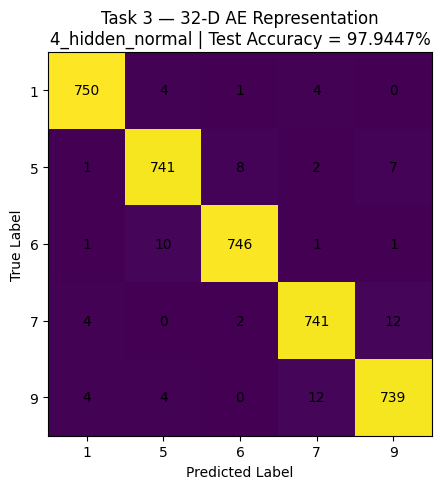

Saved: /content/task3_results/figures/confusion_matrix_64.png


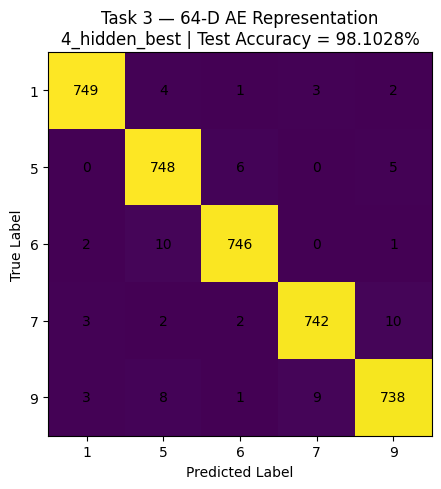

Saved: /content/task3_results/figures/confusion_matrix_128.png


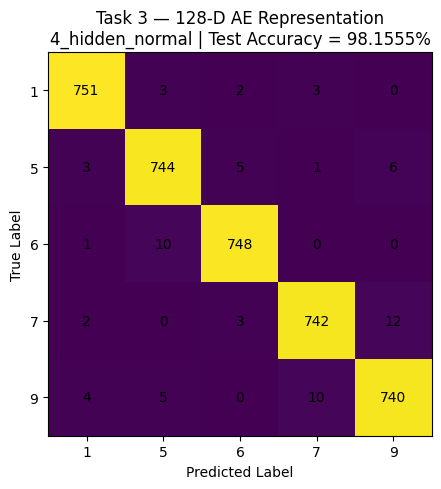

Saved: /content/task3_results/figures/confusion_matrix_256.png


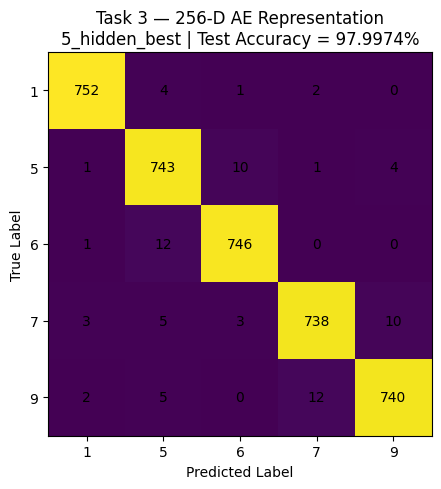

In [ ]:
TASK3_FIG_DIR = os.path.join(
    TASK3_RESULTS_DIR,
    "figures"
)

os.makedirs(
    TASK3_FIG_DIR,
    exist_ok=True
)


for _, row in task3_test_results_df.iterrows():

    representation_dim = int(
        row["representation_dim"]
    )

    architecture = row[
        "architecture"
    ]

    cm = task3_confusion_matrices[
        representation_dim
    ]

    save_path = os.path.join(
        TASK3_FIG_DIR,
        f"confusion_matrix_{representation_dim}.png"
    )

    plot_confusion_matrix(
        cm=cm,
        class_names=classes,
        title=(
            f"Task 3 — {representation_dim}-D "
            f"AE Representation\n"
            f"{architecture} | "
            f"Test Accuracy = "
            f"{row['test_accuracy']:.4f}%"
        ),
        save_path=save_path
    )

In [ ]:
# ==========================================
# TASK 3 — BEST REPRESENTATION
# ==========================================

best_task3_row = task3_test_results_df.loc[
    task3_test_results_df[
        "test_accuracy"
    ].idxmax()
]

print("=" * 70)
print("BEST TASK 3 REPRESENTATION")
print("=" * 70)

print(
    f"Representation : "
    f"{int(best_task3_row['representation_dim'])}-D"
)

print(
    f"Architecture   : "
    f"{best_task3_row['architecture']}"
)

print(
    f"Hidden Layers  : "
    f"{best_task3_row['hidden_layers']}"
)

print(
    f"Validation Acc : "
    f"{best_task3_row['validation_accuracy']:.6f}%"
)

print(
    f"Test Accuracy  : "
    f"{best_task3_row['test_accuracy']:.6f}%"
)

BEST TASK 3 REPRESENTATION
Representation : 128-D
Architecture   : 4_hidden_normal
Hidden Layers  : [256, 128, 64, 32]
Validation Acc : 98.524374%
Test Accuracy  : 98.155468%


In [ ]:
!zip -r task3_checkpoints.zip task3_checkpoints

  adding: task3_checkpoints/ (stored 0%)
  adding: task3_checkpoints/ae1_32_3_hidden_best_best.pt (deflated 9%)
  adding: task3_checkpoints/ae1_256_3_hidden_best_best.pt (deflated 8%)
  adding: task3_checkpoints/ae1_32_5_hidden_best_best.pt (deflated 8%)
  adding: task3_checkpoints/ae1_64_3_hidden_best_best.pt (deflated 8%)
  adding: task3_checkpoints/ae1_64_5_hidden_best_best.pt (deflated 8%)
  adding: task3_checkpoints/ae1_64_4_hidden_normal_best.pt (deflated 8%)
  adding: task3_checkpoints/ae1_128_3_hidden_best_best.pt (deflated 8%)
  adding: task3_checkpoints/ae1_64_4_hidden_best_best.pt (deflated 9%)
  adding: task3_checkpoints/ae1_128_4_hidden_normal_best.pt (deflated 7%)
  adding: task3_checkpoints/ae1_256_4_hidden_best_best.pt (deflated 8%)
  adding: task3_checkpoints/ae1_256_4_hidden_normal_best.pt (deflated 7%)
  adding: task3_checkpoints/ae1_256_5_hidden_best_best.pt (deflated 7%)
  adding: task3_checkpoints/ae1_128_4_hidden_best_best.pt (deflated 9%)
  adding: task3_checkpo

In [ ]:
!zip -r task3_results.zip task3_results

  adding: task3_results/ (stored 0%)
  adding: task3_results/figures/ (stored 0%)
  adding: task3_results/figures/confusion_matrix_32.png (deflated 16%)
  adding: task3_results/figures/confusion_matrix_64.png (deflated 15%)
  adding: task3_results/figures/confusion_matrix_256.png (deflated 15%)
  adding: task3_results/figures/confusion_matrix_128.png (deflated 15%)
  adding: task3_results/task3_test_results.csv (deflated 45%)
  adding: task3_results/confusion_matrices/ (stored 0%)
  adding: task3_results/confusion_matrices/confusion_matrix_64.csv (deflated 34%)
  adding: task3_results/confusion_matrices/confusion_matrix_256.csv (deflated 31%)
  adding: task3_results/confusion_matrices/confusion_matrix_32.csv (deflated 33%)
  adding: task3_results/confusion_matrices/confusion_matrix_128.csv (deflated 33%)


# **TASK 4**

In [ ]:
# ==========================================
# TASK 4 — EXTRACT 3-HIDDEN-LAYER AE MODELS
# ==========================================

import zipfile
import os

TASK4_AE_DIR = "/content/task4_3hidden_weights"

os.makedirs(
    TASK4_AE_DIR,
    exist_ok=True
)

TASK4_AE_ZIP = "3_hidden_layer_500.zip"

with zipfile.ZipFile(
    TASK4_AE_ZIP,
    "r"
) as zip_ref:

    zip_ref.extractall(
        TASK4_AE_DIR
    )

print("Extracted to:")
print(TASK4_AE_DIR)

Extracted to:
/content/task4_3hidden_weights


In [ ]:
import glob

TASK4_AE_FILES = glob.glob(
    os.path.join(
        TASK4_AE_DIR,
        "**",
        "*.pt"
    ),
    recursive=True
)

print(
    f"Found {len(TASK4_AE_FILES)} checkpoint files:"
)

for path in TASK4_AE_FILES:
    print(path)

Found 4 checkpoint files:
/content/task4_3hidden_weights/3_hidden_layer_500/ae_3_hidden_32_best_500.pt
/content/task4_3hidden_weights/3_hidden_layer_500/ae_3_hidden_128_best_500.pt
/content/task4_3hidden_weights/3_hidden_layer_500/ae_3_hidden_256_best_500.pt
/content/task4_3hidden_weights/3_hidden_layer_500/ae_3_hidden_64_best_500.pt


In [ ]:
# ==========================================
# TASK 4 — IDENTIFY OFFICIAL AE CHECKPOINTS
# ==========================================

TASK4_AE_CHECKPOINTS = {}

for bottleneck_dim in [32, 64, 128, 256]:

    matches = [
        path
        for path in TASK4_AE_FILES
        if (
            f"3_hidden_{bottleneck_dim}_best_500.pt"
            in os.path.basename(path)
        )
    ]

    if len(matches) == 0:
        raise FileNotFoundError(
            f"3-hidden 500-epoch AE not found "
            f"for bottleneck {bottleneck_dim}"
        )

    if len(matches) > 1:
        print(
            f"WARNING: Multiple matches for "
            f"{bottleneck_dim}-D:"
        )
        for m in matches:
            print(m)

    TASK4_AE_CHECKPOINTS[bottleneck_dim] = matches[0]


print("\nOfficial Task 4 AE checkpoints:")

for dim, path in TASK4_AE_CHECKPOINTS.items():

    print(
        f"{dim}-D : {path}"
    )


Official Task 4 AE checkpoints:
32-D : /content/task4_3hidden_weights/3_hidden_layer_500/ae_3_hidden_32_best_500.pt
64-D : /content/task4_3hidden_weights/3_hidden_layer_500/ae_3_hidden_64_best_500.pt
128-D : /content/task4_3hidden_weights/3_hidden_layer_500/ae_3_hidden_128_best_500.pt
256-D : /content/task4_3hidden_weights/3_hidden_layer_500/ae_3_hidden_256_best_500.pt


In [ ]:
# ==========================================
# TASK 4 — LOAD 3-HIDDEN AUTOENCODER
# ==========================================

def load_task4_autoencoder(checkpoint_path):

    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )

    model = Autoencoder(
        input_dim=checkpoint["input_dim"],
        bottleneck_dim=checkpoint["bottleneck_dim"],
        architecture=checkpoint["architecture"]
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(device)
    model.eval()

    return model, checkpoint

In [ ]:
# ==========================================
# TASK 4 — VERIFY 32-D AUTOENCODER
# ==========================================

model, checkpoint = load_task4_autoencoder(
    TASK4_AE_CHECKPOINTS[32]
)

print(model)

print("\nCheckpoint information:")
print(
    "Architecture:",
    checkpoint["architecture"]
)
print(
    "Bottleneck:",
    checkpoint["bottleneck_dim"]
)
print(
    "Best epoch:",
    checkpoint["best_epoch"]
)
print(
    "Best validation MSE:",
    checkpoint["best_val_loss"]
)

Autoencoder(
  (encoder): Sequential(
    (0): Linear(in_features=784, out_features=400, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=400, out_features=32, bias=True)
  )
  (decoder): Sequential(
    (0): Linear(in_features=32, out_features=400, bias=True)
    (1): Sigmoid()
    (2): Linear(in_features=400, out_features=784, bias=True)
    (3): Sigmoid()
  )
)

Checkpoint information:
Architecture: 3_hidden
Bottleneck: 32
Best epoch: 147
Best validation MSE: 0.005040803458541632


In [ ]:
# ==========================================
# TASK 4 — EXTRACT COMPRESSED REPRESENTATIONS
# ==========================================

task4_compressed_train = {}
task4_compressed_val = {}
task4_compressed_test = {}

for bottleneck_dim in [32, 64, 128, 256]:

    print("\n")
    print("=" * 70)
    print(
        f"Task 4 — Extracting "
        f"{bottleneck_dim}-D representation"
    )
    print("=" * 70)

    # --------------------------------------
    # Load official 500-epoch 3-hidden AE
    # --------------------------------------

    model, checkpoint = load_task4_autoencoder(
        TASK4_AE_CHECKPOINTS[bottleneck_dim]
    )

    # --------------------------------------
    # Encode TRAIN
    # --------------------------------------

    with torch.no_grad():

        train_representation = model.encode(
            X_train_ae
        )

        val_representation = model.encode(
            X_val_ae
        )

        test_representation = model.encode(
            X_test_ae
        )

    # --------------------------------------
    # Save in dictionaries
    # --------------------------------------

    task4_compressed_train[
        bottleneck_dim
    ] = train_representation

    task4_compressed_val[
        bottleneck_dim
    ] = val_representation

    task4_compressed_test[
        bottleneck_dim
    ] = test_representation

    # --------------------------------------
    # Verify shapes
    # --------------------------------------

    print(
        "Train:",
        train_representation.shape
    )

    print(
        "Val  :",
        val_representation.shape
    )

    print(
        "Test :",
        test_representation.shape
    )

    del model
    torch.cuda.empty_cache()



Task 4 — Extracting 32-D representation
Train: torch.Size([11385, 32])
Val  : torch.Size([3795, 32])
Test : torch.Size([3795, 32])


Task 4 — Extracting 64-D representation
Train: torch.Size([11385, 64])
Val  : torch.Size([3795, 64])
Test : torch.Size([3795, 64])


Task 4 — Extracting 128-D representation
Train: torch.Size([11385, 128])
Val  : torch.Size([3795, 128])
Test : torch.Size([3795, 128])


Task 4 — Extracting 256-D representation
Train: torch.Size([11385, 256])
Val  : torch.Size([3795, 256])
Test : torch.Size([3795, 256])


In [ ]:
# ==========================================
# TASK 4 — SAVE COMPRESSED REPRESENTATIONS
# ==========================================

TASK4_REP_DIR = "/content/task4_compressed_representations"

os.makedirs(
    TASK4_REP_DIR,
    exist_ok=True
)

for dim in [32, 64, 128, 256]:

    np.save(
        os.path.join(
            TASK4_REP_DIR,
            f"train_{dim}.npy"
        ),
        task4_compressed_train[dim]
        .detach()
        .cpu()
        .numpy()
    )

    np.save(
        os.path.join(
            TASK4_REP_DIR,
            f"val_{dim}.npy"
        ),
        task4_compressed_val[dim]
        .detach()
        .cpu()
        .numpy()
    )

    np.save(
        os.path.join(
            TASK4_REP_DIR,
            f"test_{dim}.npy"
        ),
        task4_compressed_test[dim]
        .detach()
        .cpu()
        .numpy()
    )

print(
    "Saved Task 4 representations to:"
)

print(TASK4_REP_DIR)

Saved Task 4 representations to:
/content/task4_compressed_representations


In [ ]:
!zip -r task4_compressed_representations.zip task4_compressed_representations

  adding: task4_compressed_representations/ (stored 0%)
  adding: task4_compressed_representations/val_32.npy (deflated 8%)
  adding: task4_compressed_representations/test_256.npy (deflated 7%)
  adding: task4_compressed_representations/val_64.npy (deflated 7%)
  adding: task4_compressed_representations/train_64.npy (deflated 7%)
  adding: task4_compressed_representations/train_256.npy (deflated 7%)
  adding: task4_compressed_representations/test_32.npy (deflated 8%)
  adding: task4_compressed_representations/val_128.npy (deflated 8%)
  adding: task4_compressed_representations/train_128.npy (deflated 7%)
  adding: task4_compressed_representations/test_64.npy (deflated 7%)
  adding: task4_compressed_representations/test_128.npy (deflated 8%)
  adding: task4_compressed_representations/val_256.npy (deflated 7%)
  adding: task4_compressed_representations/train_32.npy (deflated 8%)


In [ ]:
# ==========================================
# TASK 4 — VERIFY REPRESENTATIONS
# ==========================================

for dim in [32, 64, 128, 256]:

    print(
        f"{dim}-D:"
    )

    print(
        "  Train:",
        task4_compressed_train[dim].shape
    )

    print(
        "  Val  :",
        task4_compressed_val[dim].shape
    )

    print(
        "  Test :",
        task4_compressed_test[dim].shape
    )

32-D:
  Train: torch.Size([11385, 32])
  Val  : torch.Size([3795, 32])
  Test : torch.Size([3795, 32])
64-D:
  Train: torch.Size([11385, 64])
  Val  : torch.Size([3795, 64])
  Test : torch.Size([3795, 64])
128-D:
  Train: torch.Size([11385, 128])
  Val  : torch.Size([3795, 128])
  Test : torch.Size([3795, 128])
256-D:
  Train: torch.Size([11385, 256])
  Val  : torch.Size([3795, 256])
  Test : torch.Size([3795, 256])


In [ ]:
# ==========================================
# TASK 4 — CHECKPOINT SETUP
# ==========================================

TASK4_CHECKPOINT_DIR = "/content/task4_checkpoints"

os.makedirs(
    TASK4_CHECKPOINT_DIR,
    exist_ok=True
)

print(
    "Task 4 checkpoint directory:",
    TASK4_CHECKPOINT_DIR
)
# ==========================================
# TASK 4 — SAVE CLASSIFIER CHECKPOINT
# ==========================================

def save_task4_checkpoint(
    model,
    optimizer,
    history,
    representation_dim,
    architecture_name,
    hidden_layers,
    best_val_accuracy,
    best_epoch
):

    filename = (
        f"ae2_{representation_dim}_"
        f"{architecture_name}_best.pt"
    )

    filepath = os.path.join(
        TASK4_CHECKPOINT_DIR,
        filename
    )

    checkpoint = {

        "task":
            "Task 4",

        "source":
            "2-hidden-layer encoder from 3-hidden-layer autoencoder",

        "representation_dim":
            representation_dim,

        "architecture":
            architecture_name,

        "hidden_layers":
            hidden_layers,

        "input_dim":
            representation_dim,

        "num_classes":
            5,

        "best_val_accuracy":
            best_val_accuracy,

        "best_epoch":
            best_epoch,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "history":
            history,

        "learning_rate":
            0.001,

        "momentum":
            0.9,

        "batch_size":
            1,

        "activation":
            "tanh",

        "initialization":
            "xavier_uniform",

        "seed":
            42
    }

    torch.save(
        checkpoint,
        filepath
    )

    print(
        f"Saved: {filepath}"
    )

    return filepath

Task 4 checkpoint directory: /content/task4_checkpoints


In [ ]:
# ==========================================
# TASK 4 — RUN ALL 16 CLASSIFIERS
# ==========================================

REPRESENTATION_DIMS = [
    32,
    64,
    128,
    256
]

all_task4_results = []

for representation_dim in REPRESENTATION_DIMS:

    print("\n")
    print("=" * 80)
    print(
        f"        TASK 4 REPRESENTATION: "
        f"{representation_dim}-D"
    )
    print("=" * 80)

    # --------------------------------------
    # Get compressed representations
    # --------------------------------------

    X_train_rep = (
        task4_compressed_train[
            representation_dim
        ]
    )

    X_val_rep = (
        task4_compressed_val[
            representation_dim
        ]
    )

    for architecture_name, hidden_layers in ARCHITECTURES.items():

        print("\n")
        print("-" * 80)
        print(
            f"Representation : "
            f"{representation_dim}-D"
        )
        print(
            f"Architecture   : "
            f"{architecture_name}"
        )
        print(
            f"Hidden layers  : "
            f"{hidden_layers}"
        )
        print("-" * 80)

        # --------------------------------------
        # Reproducibility
        # --------------------------------------

        torch.manual_seed(SEED)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)

        # --------------------------------------
        # Create FCNN
        # --------------------------------------

        model = FCNN(
            input_dim=representation_dim,
            hidden_layers=hidden_layers,
            num_classes=5
        )

        # --------------------------------------
        # EXACT SAME TRAINING PROCEDURE
        # AS TASK 1 / TASK 3
        # --------------------------------------

        (
            model,
            optimizer,
            history,
            best_val_accuracy,
            best_epoch
        ) = train_model(
            model,
            X_train_rep,
            y_train_tensor,
            X_val_rep,
            y_val_tensor,
            batch_size=1,
            learning_rate=0.001,
            momentum=0.9
        )

        # --------------------------------------
        # Save checkpoint
        # --------------------------------------

        checkpoint_path = save_task4_checkpoint(
            model=model,
            optimizer=optimizer,
            history=history,
            representation_dim=representation_dim,
            architecture_name=architecture_name,
            hidden_layers=hidden_layers,
            best_val_accuracy=best_val_accuracy,
            best_epoch=best_epoch
        )

        # --------------------------------------
        # Store result
        # --------------------------------------

        all_task4_results.append({

            "representation_dim":
                representation_dim,

            "architecture":
                architecture_name,

            "hidden_layers":
                str(hidden_layers),

            "best_epoch":
                best_epoch,

            "best_val_accuracy":
                best_val_accuracy,

            "checkpoint":
                checkpoint_path
        })

        print(
            f"\nCompleted: "
            f"{representation_dim}-D | "
            f"{architecture_name} | "
            f"Best Val = "
            f"{best_val_accuracy:.4f}% | "
            f"Epoch = "
            f"{best_epoch}"
        )

        # --------------------------------------
        # Free GPU memory
        # --------------------------------------

        del model
        del optimizer

        torch.cuda.empty_cache()



        TASK 4 REPRESENTATION: 32-D


--------------------------------------------------------------------------------
Representation : 32-D
Architecture   : 3_hidden_best
Hidden layers  : [128, 64, 32]
--------------------------------------------------------------------------------
Epoch [  1/100] Loss: 0.130597 Train Acc: 95.7927% Val Acc: 97.0751%
Epoch [  2/100] Loss: 0.059950 Train Acc: 98.1379% Val Acc: 97.6812% | ΔLoss: 0.070647
Epoch [  3/100] Loss: 0.038091 Train Acc: 98.7527% Val Acc: 98.0237% | ΔLoss: 0.021859
Epoch [  4/100] Loss: 0.027357 Train Acc: 99.0426% Val Acc: 97.9710% | ΔLoss: 0.010734
Epoch [  5/100] Loss: 0.017068 Train Acc: 99.4818% Val Acc: 98.5507% | ΔLoss: 0.010289
Epoch [  6/100] Loss: 0.011576 Train Acc: 99.6135% Val Acc: 98.1818% | ΔLoss: 0.005492
Epoch [  7/100] Loss: 0.012827 Train Acc: 99.6662% Val Acc: 98.3399% | ΔLoss: 0.001251
Epoch [  8/100] Loss: 0.009885 Train Acc: 99.6487% Val Acc: 98.4717% | ΔLoss: 0.002942
Epoch [  9/100] Loss: 0.003291 Train

In [ ]:
# ==========================================
# TASK 4 — SAVE VALIDATION RESULTS
# ==========================================

task4_results_df = pd.DataFrame(
    all_task4_results
)

display(
    task4_results_df
)

,representation_dim,architecture,hidden_layers,best_epoch,best_val_accuracy,checkpoint
0,32,3_hidden_best,"[128, 64, 32]",13,98.603426,/content/task4_checkpoints/ae2_32_3_hidden_bes...
1,32,4_hidden_best,"[128, 64, 32, 16]",10,98.550725,/content/task4_checkpoints/ae2_32_4_hidden_bes...
2,32,4_hidden_normal,"[256, 128, 64, 32]",5,98.550725,/content/task4_checkpoints/ae2_32_4_hidden_nor...
3,32,5_hidden_best,"[256, 128, 64, 32, 16]",9,98.761528,/content/task4_checkpoints/ae2_32_5_hidden_bes...
4,64,3_hidden_best,"[128, 64, 32]",10,98.418972,/content/task4_checkpoints/ae2_64_3_hidden_bes...
5,64,4_hidden_best,"[128, 64, 32, 16]",10,98.339921,/content/task4_checkpoints/ae2_64_4_hidden_bes...
6,64,4_hidden_normal,"[256, 128, 64, 32]",10,98.366271,/content/task4_checkpoints/ae2_64_4_hidden_nor...
7,64,5_hidden_best,"[256, 128, 64, 32, 16]",8,98.445323,/content/task4_checkpoints/ae2_64_5_hidden_bes...
8,128,3_hidden_best,"[128, 64, 32]",9,98.155468,/content/task4_checkpoints/ae2_128_3_hidden_be...
9,128,4_hidden_best,"[128, 64, 32, 16]",7,98.313570,/content/task4_checkpoints/ae2_128_4_hidden_be...


In [ ]:
# ==========================================
# TASK 4 — SAVE RESULTS TO CSV
# ==========================================

TASK4_RESULTS_DIR = os.path.join(
    TASK4_CHECKPOINT_DIR,
    "results"
)

os.makedirs(
    TASK4_RESULTS_DIR,
    exist_ok=True
)

task4_validation_csv = os.path.join(
    TASK4_RESULTS_DIR,
    "task4_validation_results.csv"
)

task4_results_df.to_csv(
    task4_validation_csv,
    index=False
)

print(
    "Task 4 validation results saved to:"
)

print(
    task4_validation_csv
)

Task 4 validation results saved to:
/content/task4_checkpoints/results/task4_validation_results.csv


In [ ]:
# ==========================================
# TASK 4 — SELECT BEST ARCHITECTURE
# PER REPRESENTATION
# ==========================================

task4_validation_df = pd.read_csv(
    "/content/task4_checkpoints/results/task4_validation_results.csv"
)

best_task4_models = (
    task4_validation_df
    .sort_values(
        "best_val_accuracy",
        ascending=False
    )
    .groupby(
        "representation_dim",
        as_index=False
    )
    .first()
    .sort_values(
        "representation_dim"
    )
)

display(
    best_task4_models[
        [
            "representation_dim",
            "architecture",
            "hidden_layers",
            "best_epoch",
            "best_val_accuracy"
        ]
    ]
)

,representation_dim,architecture,hidden_layers,best_epoch,best_val_accuracy
0,32,5_hidden_best,"[256, 128, 64, 32, 16]",9,98.761528
1,64,5_hidden_best,"[256, 128, 64, 32, 16]",8,98.445323
2,128,4_hidden_normal,"[256, 128, 64, 32]",5,98.445323
3,256,4_hidden_best,"[128, 64, 32, 16]",8,98.471673


In [ ]:
# ==========================================
# TASK 4 — FIND CLASSIFIER CHECKPOINT
# ==========================================

def find_task4_checkpoint(
    representation_dim,
    architecture_name
):

    filename = (
        f"ae2_{representation_dim}_"
        f"{architecture_name}_best.pt"
    )

    filepath = os.path.join(
        TASK4_CHECKPOINT_DIR,
        filename
    )

    if not os.path.exists(filepath):

        raise FileNotFoundError(
            f"Checkpoint not found: {filepath}"
        )

    return filepath

In [ ]:
# ==========================================
# TASK 4 — LOAD CLASSIFIER
# ==========================================

def load_task4_classifier(
    representation_dim,
    architecture_name
):

    filepath = find_task4_checkpoint(
        representation_dim,
        architecture_name
    )

    checkpoint = torch.load(
        filepath,
        map_location=device
    )

    model = FCNN(
        input_dim=checkpoint["input_dim"],
        hidden_layers=checkpoint["hidden_layers"],
        num_classes=checkpoint["num_classes"]
    )

    model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    model = model.to(device)
    model.eval()

    print(
        f"Loaded: {filepath}"
    )

    print(
        f"Representation: "
        f"{representation_dim}-D"
    )

    print(
        f"Architecture: "
        f"{architecture_name}"
    )

    print(
        f"Best validation accuracy: "
        f"{checkpoint['best_val_accuracy']:.6f}%"
    )

    print(
        f"Best epoch: "
        f"{checkpoint['best_epoch']}"
    )

    return model, checkpoint

In [ ]:
# ==========================================
# TASK 4 — TEST EVALUATION
# ==========================================

from sklearn.metrics import accuracy_score, confusion_matrix


def evaluate_task4_test(
    model,
    X_test,
    y_test
):

    model.eval()

    with torch.no_grad():

        outputs = model(X_test)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

    y_true = y_test.cpu().numpy()

    y_pred = predictions.cpu().numpy()

    test_accuracy = (
        100.0 *
        accuracy_score(
            y_true,
            y_pred
        )
    )

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    return (
        test_accuracy,
        cm,
        y_true,
        y_pred
    )

In [ ]:
# ==========================================
# TASK 4 — TEST THE FOUR WINNING MODELS
# ==========================================

task4_test_results = []

task4_confusion_matrices = {}


for _, row in best_task4_models.iterrows():

    representation_dim = int(
        row["representation_dim"]
    )

    architecture_name = (
        row["architecture"]
    )

    print("\n")
    print("=" * 80)

    print(
        f"Task 4 | "
        f"{representation_dim}-D | "
        f"{architecture_name}"
    )

    print("=" * 80)

    # --------------------------------------
    # Load saved best-validation classifier
    # --------------------------------------

    model, checkpoint = load_task4_classifier(
        representation_dim,
        architecture_name
    )

    # --------------------------------------
    # Test representation
    # --------------------------------------

    X_test_rep = (
        task4_compressed_test[
            representation_dim
        ]
    )

    # --------------------------------------
    # Test
    # --------------------------------------

    (
        test_accuracy,
        cm,
        y_true,
        y_pred
    ) = evaluate_task4_test(
        model,
        X_test_rep,
        y_test_tensor
    )

    # --------------------------------------
    # Save confusion matrix
    # --------------------------------------

    task4_confusion_matrices[
        representation_dim
    ] = cm

    print(
        f"\nValidation Accuracy: "
        f"{checkpoint['best_val_accuracy']:.6f}%"
    )

    print(
        f"Test Accuracy: "
        f"{test_accuracy:.6f}%"
    )

    print("\nConfusion Matrix:")

    print(cm)

    # --------------------------------------
    # Store result
    # --------------------------------------

    task4_test_results.append({

        "representation_dim":
            representation_dim,

        "architecture":
            architecture_name,

        "hidden_layers":
            str(row["hidden_layers"]),

        "best_epoch":
            int(
                checkpoint["best_epoch"]
            ),

        "validation_accuracy":
            float(
                checkpoint[
                    "best_val_accuracy"
                ]
            ),

        "test_accuracy":
            test_accuracy
    })

    del model

    torch.cuda.empty_cache()



Task 4 | 32-D | 5_hidden_best
Loaded: /content/task4_checkpoints/ae2_32_5_hidden_best_best.pt
Representation: 32-D
Architecture: 5_hidden_best
Best validation accuracy: 98.761528%
Best epoch: 9

Validation Accuracy: 98.761528%
Test Accuracy: 98.234519%

Confusion Matrix:
[[751   1   2   4   1]
 [  2 743  11   0   3]
 [  0  11 745   0   3]
 [  1   1   2 748   7]
 [  3   4   1  10 741]]


Task 4 | 64-D | 5_hidden_best
Loaded: /content/task4_checkpoints/ae2_64_5_hidden_best_best.pt
Representation: 64-D
Architecture: 5_hidden_best
Best validation accuracy: 98.445323%
Best epoch: 8

Validation Accuracy: 98.445323%
Test Accuracy: 98.287220%

Confusion Matrix:
[[751   4   1   3   0]
 [  1 748   6   0   4]
 [  1   9 746   1   2]
 [  3   5   0 743   8]
 [  2   5   0  10 742]]


Task 4 | 128-D | 4_hidden_normal
Loaded: /content/task4_checkpoints/ae2_128_4_hidden_normal_best.pt
Representation: 128-D
Architecture: 4_hidden_normal
Best validation accuracy: 98.445323%
Best epoch: 5

Validation Acc

Saved: /content/task4_checkpoints/figures/confusion_matrix_32.png


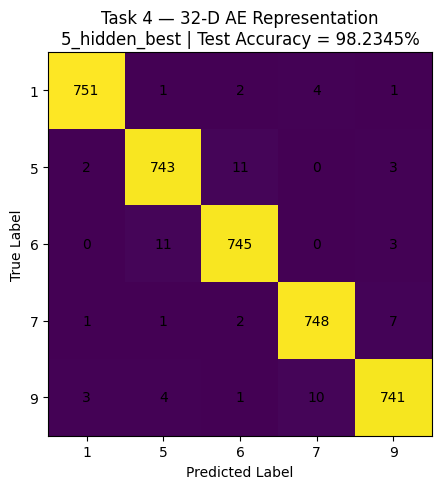

Saved: /content/task4_checkpoints/figures/confusion_matrix_64.png


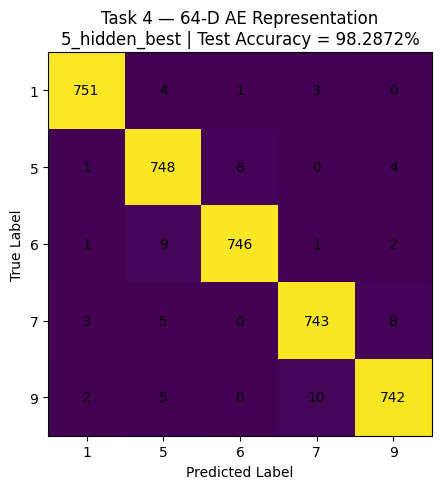

Saved: /content/task4_checkpoints/figures/confusion_matrix_128.png


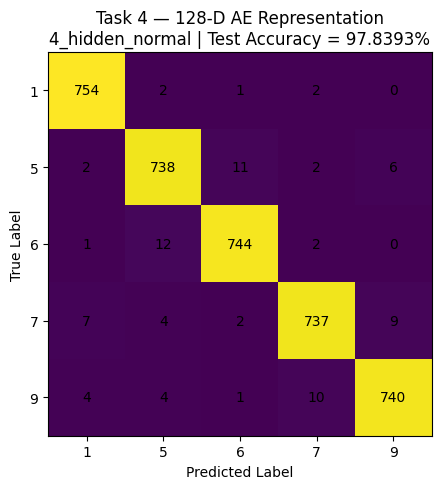

Saved: /content/task4_checkpoints/figures/confusion_matrix_256.png


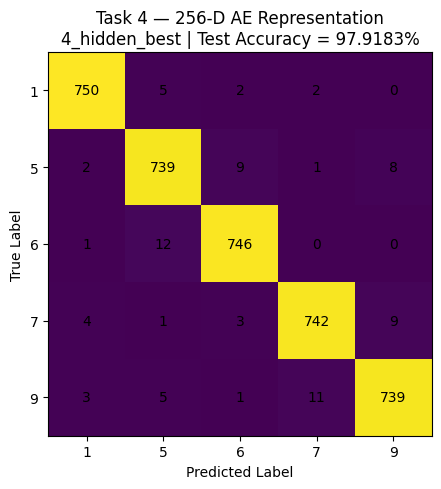


All Task 4 confusion matrices saved!
Location: /content/task4_checkpoints/figures


In [ ]:
# ==========================================
# TASK 4 — SAVE CONFUSION MATRIX FIGURES
# ==========================================

TASK4_FIG_DIR = os.path.join(
    TASK4_CHECKPOINT_DIR,
    "figures"
)

os.makedirs(
    TASK4_FIG_DIR,
    exist_ok=True
)


for _, row in task4_test_results_df.iterrows():

    representation_dim = int(
        row["representation_dim"]
    )

    architecture = row[
        "architecture"
    ]

    cm = task4_confusion_matrices[
        representation_dim
    ]

    save_path = os.path.join(
        TASK4_FIG_DIR,
        f"confusion_matrix_{representation_dim}.png"
    )

    plot_confusion_matrix(
        cm=cm,
        class_names=classes,
        title=(
            f"Task 4 — {representation_dim}-D "
            f"AE Representation\n"
            f"{architecture} | "
            f"Test Accuracy = "
            f"{row['test_accuracy']:.4f}%"
        ),
        save_path=save_path
    )

print("\nAll Task 4 confusion matrices saved!")

print(
    f"Location: {TASK4_FIG_DIR}"
)

In [ ]:
# ==========================================
# TASK 4 — SAVE CONFUSION MATRICES AS CSV
# ==========================================

TASK4_CM_DIR = os.path.join(
    TASK4_CHECKPOINT_DIR,
    "confusion_matrices"
)

os.makedirs(
    TASK4_CM_DIR,
    exist_ok=True
)


for representation_dim, cm in task4_confusion_matrices.items():

    cm_df = pd.DataFrame(
        cm,
        index=classes,
        columns=classes
    )

    save_path = os.path.join(
        TASK4_CM_DIR,
        f"confusion_matrix_{representation_dim}.csv"
    )

    cm_df.to_csv(
        save_path
    )

    print(
        f"Saved: {save_path}"
    )

Saved: /content/task4_checkpoints/confusion_matrices/confusion_matrix_32.csv
Saved: /content/task4_checkpoints/confusion_matrices/confusion_matrix_64.csv
Saved: /content/task4_checkpoints/confusion_matrices/confusion_matrix_128.csv
Saved: /content/task4_checkpoints/confusion_matrices/confusion_matrix_256.csv


In [ ]:
# ==========================================
# TASK 4 — FINAL TEST RESULTS
# ==========================================

task4_test_results_df = pd.DataFrame(
    task4_test_results
)

task4_test_results_df = (
    task4_test_results_df
    .sort_values(
        "representation_dim"
    )
    .reset_index(drop=True)
)

display(
    task4_test_results_df
)

,representation_dim,architecture,hidden_layers,best_epoch,validation_accuracy,test_accuracy
0,32,5_hidden_best,"[256, 128, 64, 32, 16]",9,98.761528,98.234519
1,64,5_hidden_best,"[256, 128, 64, 32, 16]",8,98.445323,98.287220
2,128,4_hidden_normal,"[256, 128, 64, 32]",5,98.445323,97.839262
3,256,4_hidden_best,"[128, 64, 32, 16]",8,98.471673,97.918314


In [ ]:
# ==========================================
# TASK 4 — BEST REPRESENTATION
# ==========================================

best_task4_row = task4_test_results_df.loc[
    task4_test_results_df[
        "test_accuracy"
    ].idxmax()
]

print("=" * 70)
print("BEST TASK 4 REPRESENTATION")
print("=" * 70)

print(
    f"Representation : "
    f"{int(best_task4_row['representation_dim'])}-D"
)

print(
    f"Architecture   : "
    f"{best_task4_row['architecture']}"
)

print(
    f"Hidden Layers  : "
    f"{best_task4_row['hidden_layers']}"
)

print(
    f"Validation Acc : "
    f"{best_task4_row['validation_accuracy']:.6f}%"
)

print(
    f"Test Accuracy  : "
    f"{best_task4_row['test_accuracy']:.6f}%"
)

BEST TASK 4 REPRESENTATION
Representation : 64-D
Architecture   : 5_hidden_best
Hidden Layers  : [256, 128, 64, 32, 16]
Validation Acc : 98.445323%
Test Accuracy  : 98.287220%


In [ ]:
# ==========================================
# TASK 4 — SAVE FINAL TEST RESULTS
# ==========================================

task4_test_csv = os.path.join(
    TASK4_RESULTS_DIR,
    "task4_test_results.csv"
)

task4_test_results_df.to_csv(
    task4_test_csv,
    index=False
)

print(
    "Saved Task 4 test results:"
)

print(
    task4_test_csv
)

Saved Task 4 test results:
/content/task4_checkpoints/results/task4_test_results.csv


In [ ]:
!zip -r task4_checkpoints.zip task4_checkpoints

  adding: task4_checkpoints/ (stored 0%)
  adding: task4_checkpoints/ae2_64_4_hidden_best_best.pt (deflated 9%)
  adding: task4_checkpoints/ae2_64_4_hidden_normal_best.pt (deflated 8%)
  adding: task4_checkpoints/ae2_32_5_hidden_best_best.pt (deflated 8%)
  adding: task4_checkpoints/ae2_32_4_hidden_normal_best.pt (deflated 8%)
  adding: task4_checkpoints/ae2_64_5_hidden_best_best.pt (deflated 8%)
  adding: task4_checkpoints/ae2_128_3_hidden_best_best.pt (deflated 8%)
  adding: task4_checkpoints/figures/ (stored 0%)
  adding: task4_checkpoints/figures/confusion_matrix_32.png (deflated 16%)
  adding: task4_checkpoints/figures/confusion_matrix_64.png (deflated 16%)
  adding: task4_checkpoints/figures/confusion_matrix_256.png (deflated 15%)
  adding: task4_checkpoints/figures/confusion_matrix_128.png (deflated 15%)
  adding: task4_checkpoints/ae2_32_3_hidden_best_best.pt (deflated 9%)
  adding: task4_checkpoints/ae2_256_3_hidden_best_best.pt (deflated 8%)
  adding: task4_checkpoints/ae2_12

In [ ]:
!zip -r task4_results.zip task4_checkpoints/results

  adding: task4_checkpoints/results/ (stored 0%)
  adding: task4_checkpoints/results/task4_test_results.csv (deflated 48%)
  adding: task4_checkpoints/results/task4_validation_results.csv (deflated 78%)


In [ ]:
!zip -r task4_complete.zip task4_checkpoints

  adding: task4_checkpoints/ (stored 0%)
  adding: task4_checkpoints/ae2_64_4_hidden_best_best.pt (deflated 9%)
  adding: task4_checkpoints/ae2_64_4_hidden_normal_best.pt (deflated 8%)
  adding: task4_checkpoints/ae2_32_5_hidden_best_best.pt (deflated 8%)
  adding: task4_checkpoints/ae2_32_4_hidden_normal_best.pt (deflated 8%)
  adding: task4_checkpoints/ae2_64_5_hidden_best_best.pt (deflated 8%)
  adding: task4_checkpoints/ae2_128_3_hidden_best_best.pt (deflated 8%)
  adding: task4_checkpoints/figures/ (stored 0%)
  adding: task4_checkpoints/figures/confusion_matrix_32.png (deflated 16%)
  adding: task4_checkpoints/figures/confusion_matrix_64.png (deflated 16%)
  adding: task4_checkpoints/figures/confusion_matrix_256.png (deflated 15%)
  adding: task4_checkpoints/figures/confusion_matrix_128.png (deflated 15%)
  adding: task4_checkpoints/ae2_32_3_hidden_best_best.pt (deflated 9%)
  adding: task4_checkpoints/ae2_256_3_hidden_best_best.pt (deflated 8%)
  adding: task4_checkpoints/ae2_12

# **TASK 5**

In [ ]:
# ==========================================
# TASK 5 — SETUP
# ==========================================

TASK5_DIR = "/content/task5_denoising"

TASK5_CHECKPOINT_DIR = os.path.join(
    TASK5_DIR,
    "checkpoints"
)

TASK5_FIG_DIR = os.path.join(
    TASK5_DIR,
    "figures"
)

TASK5_RESULTS_DIR = os.path.join(
    TASK5_DIR,
    "results"
)

TASK5_REP_DIR = os.path.join(
    TASK5_DIR,
    "compressed_representations"
)

os.makedirs(
    TASK5_CHECKPOINT_DIR,
    exist_ok=True
)

os.makedirs(
    TASK5_FIG_DIR,
    exist_ok=True
)

os.makedirs(
    TASK5_RESULTS_DIR,
    exist_ok=True
)

os.makedirs(
    TASK5_REP_DIR,
    exist_ok=True
)

print("Task 5 directories created.")
print(TASK5_DIR)

Task 5 directories created.
/content/task5_denoising


In [ ]:
# ==========================================
# TASK 5 — DENOISING AUTOENCODER
# ==========================================

class DenoisingAutoencoder(nn.Module):

    def __init__(
        self,
        input_dim=784,
        bottleneck_dim=128
    ):

        super().__init__()

        # --------------------------------------
        # ONE-HIDDEN-LAYER ENCODER
        # --------------------------------------

        self.encoder = nn.Linear(
            input_dim,
            bottleneck_dim
        )

        # --------------------------------------
        # DECODER
        # --------------------------------------

        self.decoder = nn.Sequential(

            nn.Linear(
                bottleneck_dim,
                input_dim
            ),

            nn.Sigmoid()
        )

    def encode(self, x):

        return self.encoder(x)

    def decode(self, z):

        return self.decoder(z)

    def forward(self, x):

        z = self.encode(x)

        reconstruction = self.decode(z)

        return reconstruction

In [ ]:
# ==========================================
# TASK 5 — GAUSSIAN NOISE FUNCTION
# ==========================================

def add_gaussian_noise(
    X,
    noise_fraction
):

    # Random mask selecting pixels to corrupt
    mask = (
        torch.rand_like(X)
        < noise_fraction
    )

    # N(0,1) Gaussian noise
    noise = torch.randn_like(X)

    # Add noise only to selected pixels
    noisy_X = (
        X
        + mask.float() * noise
    )

    return noisy_X

In [ ]:
# ==========================================
# TASK 5 — VERIFY NOISE
# ==========================================

sample_X = X_train_ae[:5]

noisy_20 = add_gaussian_noise(
    sample_X,
    0.20
)

noisy_40 = add_gaussian_noise(
    sample_X,
    0.40
)

print("Original shape :", sample_X.shape)
print("20% noisy shape:", noisy_20.shape)
print("40% noisy shape:", noisy_40.shape)

print("\nOriginal range:")
print(
    sample_X.min().item(),
    sample_X.max().item()
)

print("\n20% noisy range:")
print(
    noisy_20.min().item(),
    noisy_20.max().item()
)

print("\n40% noisy range:")
print(
    noisy_40.min().item(),
    noisy_40.max().item()
)

Original shape : torch.Size([5, 784])
20% noisy shape: torch.Size([5, 784])
40% noisy shape: torch.Size([5, 784])

Original range:
0.0 1.0

20% noisy range:
-3.291189670562744 3.9624667167663574

40% noisy range:
-3.6626944541931152 3.614206314086914


In [ ]:
# ==========================================
# TASK 5 — TRAIN DENOISING AUTOENCODER
# ==========================================

def train_denoising_autoencoder(
    model,
    X_train,
    X_val,
    noise_fraction,
    max_epochs=500,
    batch_size=128,
    learning_rate=0.001
):

    model = model.to(device)

    criterion = nn.MSELoss()

    optimizer = optim.Adam(
        model.parameters(),
        lr=learning_rate
    )

    history = {
        "train_loss": [],
        "val_loss": []
    }

    best_val_loss = float("inf")
    best_epoch = 0
    best_state_dict = None

    n_samples = X_train.size(0)

    # --------------------------------------
    # FIXED VALIDATION NOISE
    # --------------------------------------
    # This keeps validation comparison
    # consistent across epochs.
    # --------------------------------------

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    X_val_noisy = add_gaussian_noise(
        X_val,
        noise_fraction
    )

    for epoch in range(max_epochs):

        model.train()

        # Shuffle training examples
        indices = torch.randperm(
            n_samples,
            device=device
        )

        total_loss = 0.0
        total_samples = 0

        for start in range(
            0,
            n_samples,
            batch_size
        ):

            end = min(
                start + batch_size,
                n_samples
            )

            batch_indices = indices[
                start:end
            ]

            X_batch = X_train[
                batch_indices
            ]

            # --------------------------------------
            # CREATE NEW NOISY INPUT
            # --------------------------------------

            X_batch_noisy = (
                add_gaussian_noise(
                    X_batch,
                    noise_fraction
                )
            )

            optimizer.zero_grad()

            reconstruction = model(
                X_batch_noisy
            )

            # Target = CLEAN image
            loss = criterion(
                reconstruction,
                X_batch
            )

            loss.backward()

            optimizer.step()

            total_loss += (
                loss.item()
                * X_batch.size(0)
            )

            total_samples += (
                X_batch.size(0)
            )

        train_loss = (
            total_loss /
            total_samples
        )

        # --------------------------------------
        # VALIDATION
        # --------------------------------------

        model.eval()

        with torch.no_grad():

            val_reconstruction = model(
                X_val_noisy
            )

            val_loss = criterion(
                val_reconstruction,
                X_val
            ).item()

        history["train_loss"].append(
            train_loss
        )

        history["val_loss"].append(
            val_loss
        )

        # --------------------------------------
        # SAVE BEST VALIDATION MODEL
        # --------------------------------------

        if val_loss < best_val_loss:

            best_val_loss = val_loss

            best_epoch = epoch + 1

            best_state_dict = {
                key:
                    value.detach()
                    .cpu()
                    .clone()

                for key, value
                in model.state_dict().items()
            }

        # --------------------------------------
        # PRINT
        # --------------------------------------

        if epoch % 10 == 0:

            print(
                f"Epoch [{epoch + 1:3d}/"
                f"{max_epochs}] "
                f"Train MSE: "
                f"{train_loss:.8f} "
                f"Val MSE: "
                f"{val_loss:.8f}"
            )

    # --------------------------------------
    # RESTORE BEST MODEL
    # --------------------------------------

    model.load_state_dict(
        best_state_dict
    )

    print(
        f"\nBest validation MSE: "
        f"{best_val_loss:.8f} "
        f"(Epoch {best_epoch})"
    )

    return (
        model,
        optimizer,
        history,
        best_val_loss,
        best_epoch
    )

In [ ]:
# ==========================================
# TASK 5 — DENOISING RECONSTRUCTION ERROR
# ==========================================

def denoising_reconstruction_error(
    model,
    X,
    noise_fraction
):

    model.eval()

    # Create fresh noisy input
    X_noisy = add_gaussian_noise(
        X,
        noise_fraction
    )

    with torch.no_grad():

        reconstruction = model(
            X_noisy
        )

        error = torch.mean(
            (
                reconstruction - X
            ) ** 2
        ).item()

    return error

In [ ]:
# ==========================================
# TASK 5 — 20% NOISE DAE
# ==========================================

NOISE_LEVEL = 0.20
DAE_BOTTLENECK = 128

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

dae_20 = DenoisingAutoencoder(
    input_dim=784,
    bottleneck_dim=DAE_BOTTLENECK
)

initialize_weights(dae_20)

print(dae_20)

(
    dae_20,
    optimizer_20,
    history_20,
    best_val_loss_20,
    best_epoch_20
) = train_denoising_autoencoder(
    dae_20,
    X_train_ae,
    X_val_ae,
    noise_fraction=NOISE_LEVEL,
    max_epochs=500,
    batch_size=128,
    learning_rate=0.001
)

DenoisingAutoencoder(
  (encoder): Linear(in_features=784, out_features=128, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=128, out_features=784, bias=True)
    (1): Sigmoid()
  )
)
Epoch [  1/500] Train MSE: 0.07095197 Val MSE: 0.04383420
Epoch [ 11/500] Train MSE: 0.01504689 Val MSE: 0.01483728
Epoch [ 21/500] Train MSE: 0.01143075 Val MSE: 0.01155366
Epoch [ 31/500] Train MSE: 0.01089100 Val MSE: 0.01108994
Epoch [ 41/500] Train MSE: 0.01065703 Val MSE: 0.01085328
Epoch [ 51/500] Train MSE: 0.01061892 Val MSE: 0.01079041
Epoch [ 61/500] Train MSE: 0.01050804 Val MSE: 0.01070159
Epoch [ 71/500] Train MSE: 0.01048089 Val MSE: 0.01067489
Epoch [ 81/500] Train MSE: 0.01049009 Val MSE: 0.01066851
Epoch [ 91/500] Train MSE: 0.01044854 Val MSE: 0.01064717
Epoch [101/500] Train MSE: 0.01043239 Val MSE: 0.01063721
Epoch [111/500] Train MSE: 0.01046611 Val MSE: 0.01067001
Epoch [121/500] Train MSE: 0.01043763 Val MSE: 0.01062930
Epoch [131/500] Train MSE: 0.01041530 Val MSE:

In [ ]:
# ==========================================
# TASK 5 — 40% NOISE DAE
# ==========================================

NOISE_LEVEL = 0.40

torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

dae_40 = DenoisingAutoencoder(
    input_dim=784,
    bottleneck_dim=DAE_BOTTLENECK
)

initialize_weights(dae_40)

print(dae_40)

(
    dae_40,
    optimizer_40,
    history_40,
    best_val_loss_40,
    best_epoch_40
) = train_denoising_autoencoder(
    dae_40,
    X_train_ae,
    X_val_ae,
    noise_fraction=NOISE_LEVEL,
    max_epochs=500,
    batch_size=128,
    learning_rate=0.001
)

DenoisingAutoencoder(
  (encoder): Linear(in_features=784, out_features=128, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=128, out_features=784, bias=True)
    (1): Sigmoid()
  )
)
Epoch [  1/500] Train MSE: 0.07385703 Val MSE: 0.04652512
Epoch [ 11/500] Train MSE: 0.02039297 Val MSE: 0.02020986
Epoch [ 21/500] Train MSE: 0.01695273 Val MSE: 0.01717958
Epoch [ 31/500] Train MSE: 0.01658240 Val MSE: 0.01681186
Epoch [ 41/500] Train MSE: 0.01634590 Val MSE: 0.01661858
Epoch [ 51/500] Train MSE: 0.01631035 Val MSE: 0.01653860
Epoch [ 61/500] Train MSE: 0.01623339 Val MSE: 0.01649412
Epoch [ 71/500] Train MSE: 0.01623061 Val MSE: 0.01644457
Epoch [ 81/500] Train MSE: 0.01619969 Val MSE: 0.01648159
Epoch [ 91/500] Train MSE: 0.01618036 Val MSE: 0.01641971
Epoch [101/500] Train MSE: 0.01615322 Val MSE: 0.01643343
Epoch [111/500] Train MSE: 0.01616927 Val MSE: 0.01641954
Epoch [121/500] Train MSE: 0.01612250 Val MSE: 0.01638671
Epoch [131/500] Train MSE: 0.01609301 Val MSE:

In [ ]:
# ==========================================
# TASK 5 — RECONSTRUCTION ERRORS
# ==========================================

task5_reconstruction_results = []

for noise_label, noise_fraction, model in [

    ("20%", 0.20, dae_20),

    ("40%", 0.40, dae_40)
]:

    train_error = (
        denoising_reconstruction_error(
            model,
            X_train_ae,
            noise_fraction
        )
    )

    val_error = (
        denoising_reconstruction_error(
            model,
            X_val_ae,
            noise_fraction
        )
    )

    test_error = (
        denoising_reconstruction_error(
            model,
            X_test_ae,
            noise_fraction
        )
    )

    task5_reconstruction_results.append({

        "noise":
            noise_label,

        "noise_fraction":
            noise_fraction,

        "bottleneck_dim":
            128,

        "best_epoch":
            (
                best_epoch_20
                if noise_fraction == 0.20
                else best_epoch_40
            ),

        "best_val_mse":
            (
                best_val_loss_20
                if noise_fraction == 0.20
                else best_val_loss_40
            ),

        "train_mse":
            train_error,

        "val_mse":
            val_error,

        "test_mse":
            test_error
    })


task5_reconstruction_df = pd.DataFrame(
    task5_reconstruction_results
)

display(
    task5_reconstruction_df
)

,noise,noise_fraction,bottleneck_dim,best_epoch,best_val_mse,train_mse,val_mse,test_mse
0,20%,0.2,128,429,0.010579,0.010297,0.010644,0.010699
1,40%,0.4,128,500,0.016291,0.015991,0.016365,0.016454


In [ ]:
# ==========================================
# TASK 5 — SAVE RECONSTRUCTION RESULTS
# ==========================================

task5_reconstruction_csv = os.path.join(
    TASK5_RESULTS_DIR,
    "task5_reconstruction_results.csv"
)

task5_reconstruction_df.to_csv(
    task5_reconstruction_csv,
    index=False
)

print(
    "Saved:",
    task5_reconstruction_csv
)

Saved: /content/task5_denoising/results/task5_reconstruction_results.csv


In [ ]:
# ==========================================
# TASK 5 — SAVE DAE CHECKPOINTS
# ==========================================

def save_task5_dae_checkpoint(
    model,
    optimizer,
    history,
    noise_fraction,
    best_val_loss,
    best_epoch
):

    noise_percent = int(
        noise_fraction * 100
    )

    filename = (
        f"dae_{noise_percent}pct_"
        f"128_best_500.pt"
    )

    filepath = os.path.join(
        TASK5_CHECKPOINT_DIR,
        filename
    )

    checkpoint = {

        "task": "Task 5",

        "architecture":
            "1_hidden_denoising_autoencoder",

        "input_dim":
            784,

        "bottleneck_dim":
            128,

        "noise_fraction":
            noise_fraction,

        "noise_distribution":
            "N(0,1)",

        "best_val_loss":
            best_val_loss,

        "best_epoch":
            best_epoch,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "history":
            history,

        "learning_rate":
            0.001,

        "batch_size":
            128,

        "optimizer":
            "Adam",

        "activation":
            "sigmoid",

        "bottleneck_activation":
            "linear",

        "initialization":
            "xavier_uniform",

        "epochs":
            500,

        "seed":
            SEED
    }

    torch.save(
        checkpoint,
        filepath
    )

    print(
        f"Saved: {filepath}"
    )

    return filepath


dae_20_checkpoint = (
    save_task5_dae_checkpoint(
        dae_20,
        optimizer_20,
        history_20,
        0.20,
        best_val_loss_20,
        best_epoch_20
    )
)

dae_40_checkpoint = (
    save_task5_dae_checkpoint(
        dae_40,
        optimizer_40,
        history_40,
        0.40,
        best_val_loss_40,
        best_epoch_40
    )
)

Saved: /content/task5_denoising/checkpoints/dae_20pct_128_best_500.pt
Saved: /content/task5_denoising/checkpoints/dae_40pct_128_best_500.pt


In [ ]:
# ==========================================
# TASK 5 — PLOT DENOISING RECONSTRUCTIONS
# ==========================================

def plot_denoising_reconstructions(
    model,
    X,
    y,
    dataset_name,
    noise_fraction,
    save_dir
):

    model.eval()

    # --------------------------------------
    # Find one example per class
    # --------------------------------------

    selected_indices = []

    class_values = torch.unique(y).tolist()

    for class_id in class_values:

        indices = torch.where(
            y == class_id
        )[0]

        selected_indices.append(
            indices[0].item()
        )

    selected_indices = (
        selected_indices[:5]
    )

    X_selected = X[
        selected_indices
    ]

    y_selected = y[
        selected_indices
    ]

    # --------------------------------------
    # Add noise
    # --------------------------------------

    X_noisy = add_gaussian_noise(
        X_selected,
        noise_fraction
    )

    # --------------------------------------
    # Reconstruct
    # --------------------------------------

    with torch.no_grad():

        reconstruction = model(
            X_noisy
        )

    # --------------------------------------
    # Move to CPU
    # --------------------------------------

    original = (
        X_selected
        .detach()
        .cpu()
        .numpy()
    )

    noisy = (
        X_noisy
        .detach()
        .cpu()
        .numpy()
    )

    reconstructed = (
        reconstruction
        .detach()
        .cpu()
        .numpy()
    )

    labels = (
        y_selected
        .detach()
        .cpu()
        .numpy()
    )

    # --------------------------------------
    # Plot
    # --------------------------------------

    fig, axes = plt.subplots(
        3,
        len(selected_indices),
        figsize=(15, 8)
    )

    noise_percent = int(
        noise_fraction * 100
    )

    for i in range(
        len(selected_indices)
    ):

        axes[0, i].imshow(
            original[i].reshape(28, 28),
            cmap="gray"
        )

        axes[0, i].set_title(
            f"Class {labels[i]}"
        )

        axes[1, i].imshow(
            noisy[i].reshape(28, 28),
            cmap="gray"
        )

        axes[1, i].set_title(
            f"Noisy ({noise_percent}%)"
        )

        axes[2, i].imshow(
            reconstructed[i].reshape(28, 28),
            cmap="gray"
        )

        axes[2, i].set_title(
            "Reconstructed"
        )

        axes[0, i].axis("off")
        axes[1, i].axis("off")
        axes[2, i].axis("off")

    axes[0, 0].set_ylabel(
        "Original"
    )

    axes[1, 0].set_ylabel(
        "Noisy"
    )

    axes[2, 0].set_ylabel(
        "Reconstructed"
    )

    fig.suptitle(
        f"Task 5 — {noise_percent}% "
        f"Denoising Autoencoder — "
        f"{dataset_name}",
        fontsize=14
    )

    plt.tight_layout()

    save_path = os.path.join(
        save_dir,
        f"dae_{noise_percent}pct_"
        f"{dataset_name.lower()}_reconstructions.png"
    )

    plt.savefig(
        save_path,
        dpi=200,
        bbox_inches="tight"
    )

    plt.show()

    plt.close()

    print(
        "Saved:",
        save_path
    )

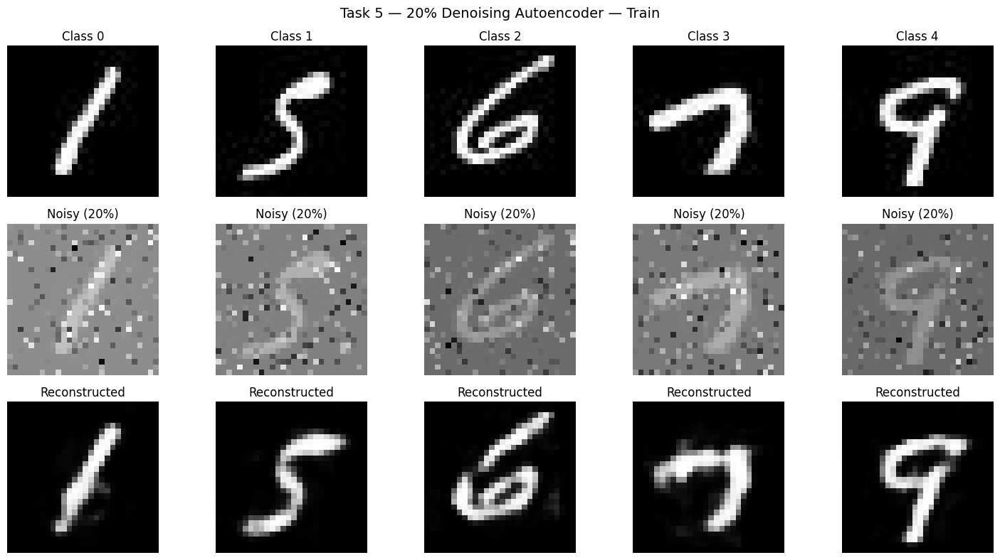

Saved: /content/task5_denoising/figures/dae_20pct_train_reconstructions.png


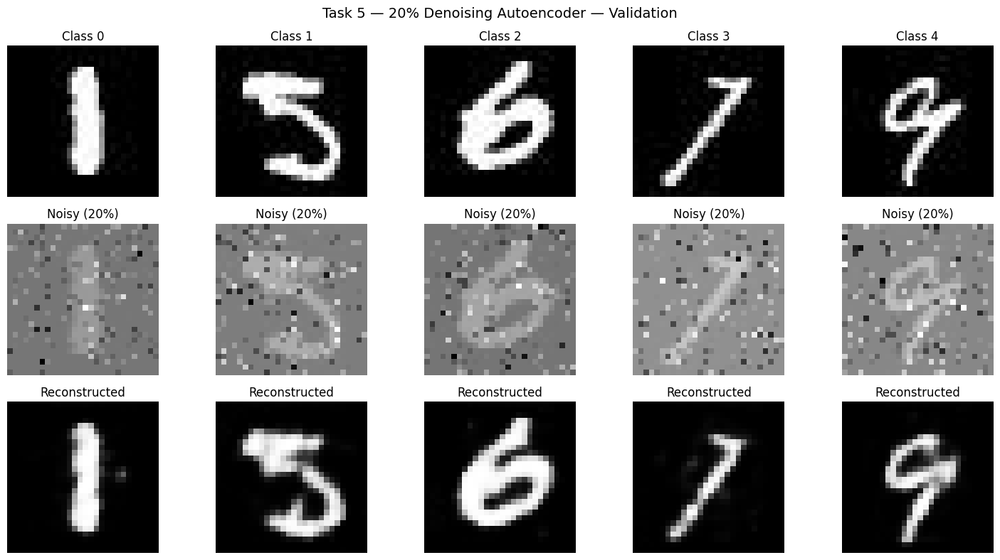

Saved: /content/task5_denoising/figures/dae_20pct_validation_reconstructions.png


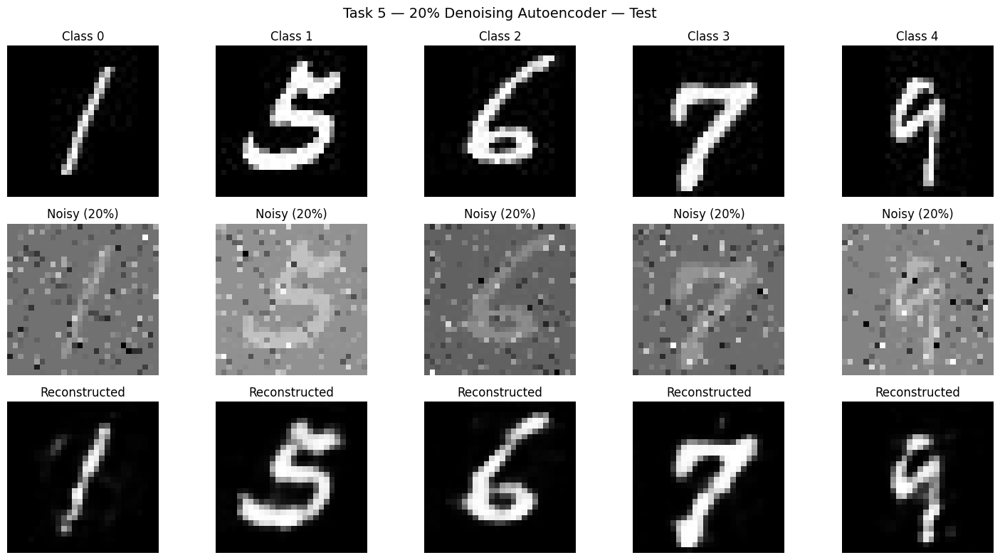

Saved: /content/task5_denoising/figures/dae_20pct_test_reconstructions.png


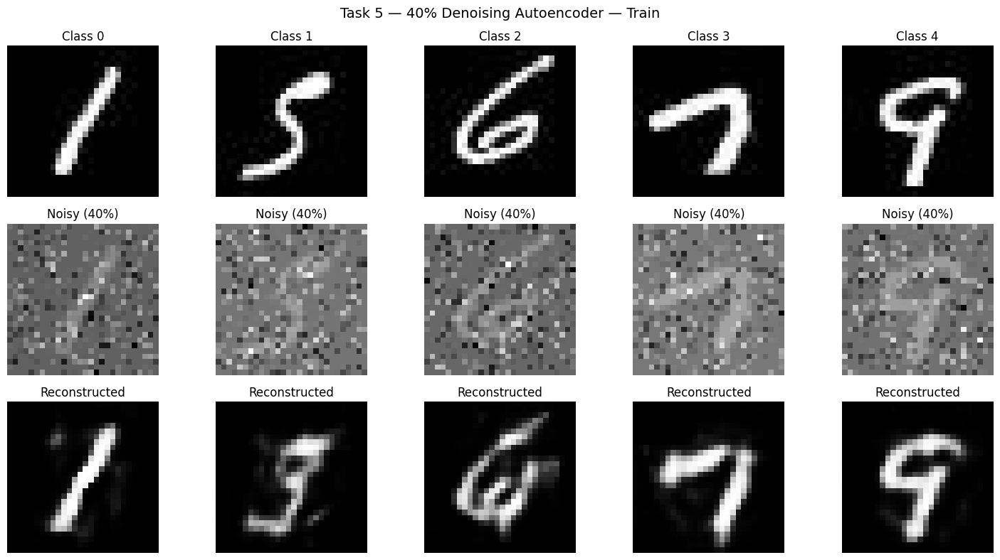

Saved: /content/task5_denoising/figures/dae_40pct_train_reconstructions.png


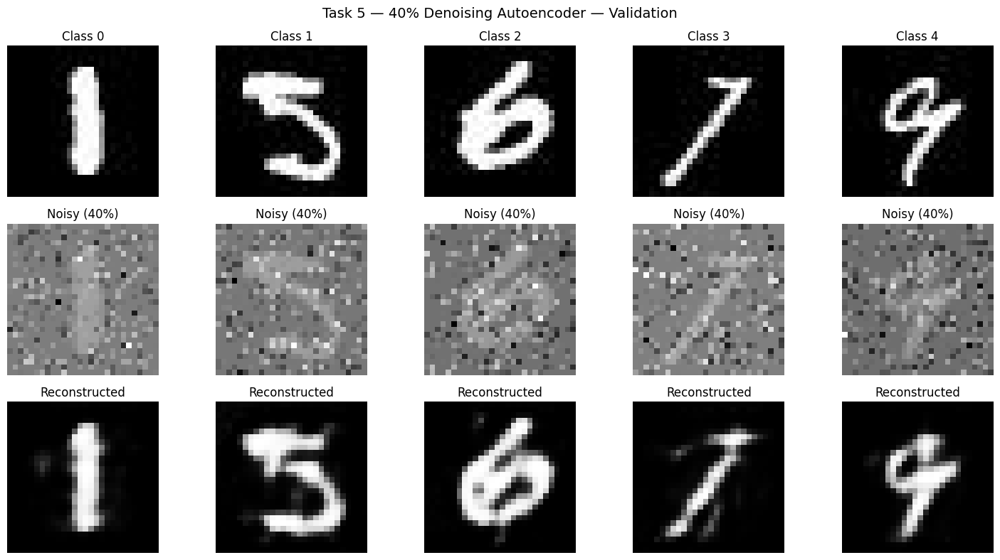

Saved: /content/task5_denoising/figures/dae_40pct_validation_reconstructions.png


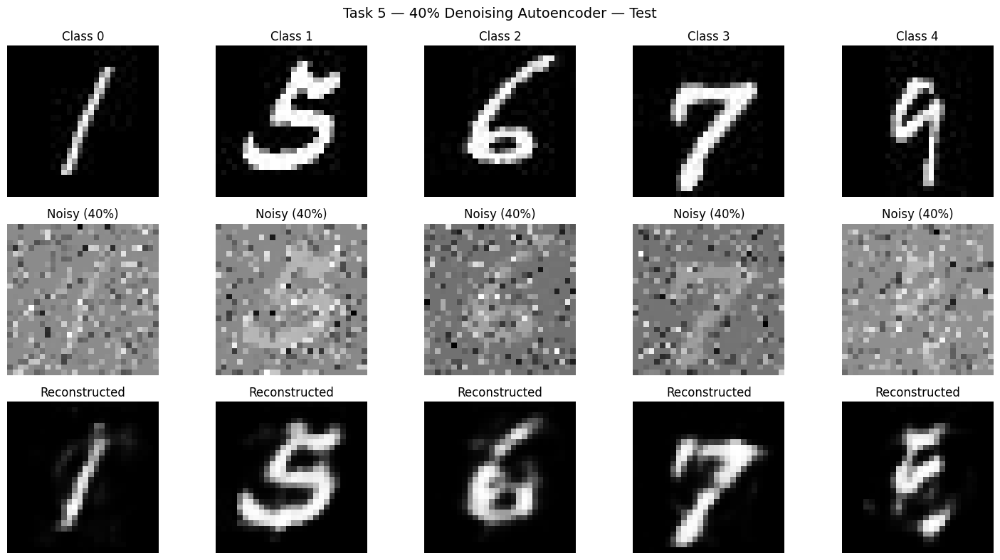

Saved: /content/task5_denoising/figures/dae_40pct_test_reconstructions.png


In [ ]:
# ==========================================
# TASK 5 — GENERATE RECONSTRUCTION FIGURES
# ==========================================

datasets = [

    (
        "Train",
        X_train_ae,
        y_train_tensor
    ),

    (
        "Validation",
        X_val_ae,
        y_val_tensor
    ),

    (
        "Test",
        X_test_ae,
        y_test_tensor
    )
]


for noise_fraction, model in [

    (0.20, dae_20),

    (0.40, dae_40)
]:

    for dataset_name, X_data, y_data in datasets:

        plot_denoising_reconstructions(
            model=model,
            X=X_data,
            y=y_data,
            dataset_name=dataset_name,
            noise_fraction=noise_fraction,
            save_dir=TASK5_FIG_DIR
        )

In [ ]:
# ==========================================
# TASK 5 — EXTRACT DAE COMPRESSED DATA
# ==========================================

task5_compressed = {}

for noise_label, model in [

    ("20%", dae_20),

    ("40%", dae_40)
]:

    model.eval()

    with torch.no_grad():

        train_rep = model.encode(
            X_train_ae
        )

        val_rep = model.encode(
            X_val_ae
        )

        test_rep = model.encode(
            X_test_ae
        )

    task5_compressed[
        noise_label
    ] = {

        "train": train_rep,

        "val": val_rep,

        "test": test_rep
    }

    print(
        f"\n{noise_label} DAE:"
    )

    print(
        "Train:",
        train_rep.shape
    )

    print(
        "Val  :",
        val_rep.shape
    )

    print(
        "Test :",
        test_rep.shape
    )


20% DAE:
Train: torch.Size([11385, 128])
Val  : torch.Size([3795, 128])
Test : torch.Size([3795, 128])

40% DAE:
Train: torch.Size([11385, 128])
Val  : torch.Size([3795, 128])
Test : torch.Size([3795, 128])


In [ ]:
# ==========================================
# TASK 5 — CLASSIFICATION SETTINGS
# ==========================================

TASK5_CLASSIFIER_ARCHITECTURE = (
    "4_hidden_normal"
)

TASK5_CLASSIFIER_HIDDEN = (
    ARCHITECTURES[
        TASK5_CLASSIFIER_ARCHITECTURE
    ]
)

print(
    "Task 5 classifier:"
)

print(
    TASK5_CLASSIFIER_ARCHITECTURE
)

print(
    TASK5_CLASSIFIER_HIDDEN
)

Task 5 classifier:
4_hidden_normal
[256, 128, 64, 32]


In [ ]:
# ==========================================
# TASK 5 — CLASSIFIER CHECKPOINT DIRECTORY
# ==========================================

TASK5_CLASSIFIER_DIR = os.path.join(
    TASK5_CHECKPOINT_DIR,
    "classifiers"
)

os.makedirs(
    TASK5_CLASSIFIER_DIR,
    exist_ok=True
)

In [ ]:
# ==========================================
# TASK 5 — TRAIN DAE CLASSIFIERS
# ==========================================

all_task5_classification_results = []


for noise_label in ["20%", "40%"]:

    print("\n")
    print("=" * 80)

    print(
        f"TASK 5 CLASSIFICATION — "
        f"{noise_label} DAE"
    )

    print("=" * 80)

    X_train_rep = (
        task5_compressed[
            noise_label
        ]["train"]
    )

    X_val_rep = (
        task5_compressed[
            noise_label
        ]["val"]
    )

    # --------------------------------------
    # Reproducibility
    # --------------------------------------

    torch.manual_seed(SEED)

    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    # --------------------------------------
    # Create FCNN
    # --------------------------------------

    model = FCNN(
        input_dim=128,
        hidden_layers=TASK5_CLASSIFIER_HIDDEN,
        num_classes=5
    )

    # --------------------------------------
    # Train
    # --------------------------------------

    (
        model,
        optimizer,
        history,
        best_val_accuracy,
        best_epoch
    ) = train_model(
        model,
        X_train_rep,
        y_train_tensor,
        X_val_rep,
        y_val_tensor,
        batch_size=1,
        learning_rate=0.001,
        momentum=0.9
    )

    # --------------------------------------
    # Save checkpoint
    # --------------------------------------

    filename = (
        f"dae_{noise_label.replace('%','pct')}"
        f"_classifier_best.pt"
    )

    checkpoint_path = os.path.join(
        TASK5_CLASSIFIER_DIR,
        filename
    )

    torch.save({

        "task":
            "Task 5 Classification",

        "noise":
            noise_label,

        "representation_dim":
            128,

        "architecture":
            TASK5_CLASSIFIER_ARCHITECTURE,

        "hidden_layers":
            TASK5_CLASSIFIER_HIDDEN,

        "best_val_accuracy":
            best_val_accuracy,

        "best_epoch":
            best_epoch,

        "model_state_dict":
            model.state_dict(),

        "optimizer_state_dict":
            optimizer.state_dict(),

        "history":
            history,

        "learning_rate":
            0.001,

        "momentum":
            0.9,

        "batch_size":
            1,

        "activation":
            "tanh",

        "initialization":
            "xavier_uniform",

        "seed":
            SEED

    }, checkpoint_path)

    # --------------------------------------
    # Test
    # --------------------------------------

    X_test_rep = (
        task5_compressed[
            noise_label
        ]["test"]
    )

    (
        test_accuracy,
        cm,
        y_true,
        y_pred
    ) = evaluate_task4_test(
        model,
        X_test_rep,
        y_test_tensor
    )

    print(
        f"\n{noise_label} DAE"
    )

    print(
        f"Validation Accuracy: "
        f"{best_val_accuracy:.6f}%"
    )

    print(
        f"Test Accuracy: "
        f"{test_accuracy:.6f}%"
    )

    print(
        "\nConfusion Matrix:"
    )

    print(cm)

    all_task5_classification_results.append({

        "noise":
            noise_label,

        "representation_dim":
            128,

        "architecture":
            TASK5_CLASSIFIER_ARCHITECTURE,

        "hidden_layers":
            str(TASK5_CLASSIFIER_HIDDEN),

        "best_epoch":
            best_epoch,

        "validation_accuracy":
            best_val_accuracy,

        "test_accuracy":
            test_accuracy,

        "checkpoint":
            checkpoint_path
    })

    # Store CM
    if "task5_confusion_matrices" not in globals():
        task5_confusion_matrices = {}

    task5_confusion_matrices[
        noise_label
    ] = cm

    del model
    del optimizer

    torch.cuda.empty_cache()



TASK 5 CLASSIFICATION — 20% DAE
Epoch [  1/100] Loss: 0.145817 Train Acc: 95.4062% Val Acc: 95.8103%
Epoch [  2/100] Loss: 0.055986 Train Acc: 98.1555% Val Acc: 97.6548% | ΔLoss: 0.089831
Epoch [  3/100] Loss: 0.031208 Train Acc: 98.9635% Val Acc: 98.1555% | ΔLoss: 0.024778
Epoch [  4/100] Loss: 0.020228 Train Acc: 99.3412% Val Acc: 97.3386% | ΔLoss: 0.010980
Epoch [  5/100] Loss: 0.012196 Train Acc: 99.6399% Val Acc: 98.2872% | ΔLoss: 0.008031
Epoch [  6/100] Loss: 0.005492 Train Acc: 99.8331% Val Acc: 98.3136% | ΔLoss: 0.006704
Epoch [  7/100] Loss: 0.001390 Train Acc: 100.0000% Val Acc: 98.4980% | ΔLoss: 0.004102
Epoch [  8/100] Loss: 0.000738 Train Acc: 99.9912% Val Acc: 98.5771% | ΔLoss: 0.000652
Epoch [  9/100] Loss: 0.000442 Train Acc: 100.0000% Val Acc: 98.5771% | ΔLoss: 0.000296
Epoch [ 10/100] Loss: 0.000334 Train Acc: 100.0000% Val Acc: 98.5244% | ΔLoss: 0.000108
Epoch [ 11/100] Loss: 0.000277 Train Acc: 100.0000% Val Acc: 98.5507% | ΔLoss: 0.000057

Converged at epoch 11 

In [ ]:
# ==========================================
# TASK 5 — SAVE CLASSIFICATION RESULTS
# ==========================================

task5_classification_df = pd.DataFrame(
    all_task5_classification_results
)

display(
    task5_classification_df
)

task5_classification_csv = os.path.join(
    TASK5_RESULTS_DIR,
    "task5_classification_results.csv"
)

task5_classification_df.to_csv(
    task5_classification_csv,
    index=False
)

print(
    "\nSaved:",
    task5_classification_csv
)

,noise,representation_dim,architecture,hidden_layers,best_epoch,validation_accuracy,test_accuracy,checkpoint
0,20%,128,4_hidden_normal,"[256, 128, 64, 32]",8,98.577075,98.445323,/content/task5_denoising/checkpoints/classifie...
1,40%,128,4_hidden_normal,"[256, 128, 64, 32]",10,98.550725,98.418972,/content/task5_denoising/checkpoints/classifie...



Saved: /content/task5_denoising/results/task5_classification_results.csv


In [ ]:
# ==========================================
# TASK 5 — SAVE CONFUSION MATRICES
# ==========================================

TASK5_CM_DIR = os.path.join(
    TASK5_RESULTS_DIR,
    "confusion_matrices"
)

os.makedirs(
    TASK5_CM_DIR,
    exist_ok=True
)


for noise_label, cm in (
    task5_confusion_matrices.items()
):

    filename = (
        f"confusion_matrix_"
        f"{noise_label.replace('%','pct')}.csv"
    )

    save_path = os.path.join(
        TASK5_CM_DIR,
        filename
    )

    cm_df = pd.DataFrame(
        cm,
        index=classes,
        columns=classes
    )

    cm_df.to_csv(
        save_path
    )

    print(
        "Saved:",
        save_path
    )

Saved: /content/task5_denoising/results/confusion_matrices/confusion_matrix_20pct.csv
Saved: /content/task5_denoising/results/confusion_matrices/confusion_matrix_40pct.csv


Saved: /content/task5_denoising/figures/confusion_matrices/confusion_matrix_20pct.png


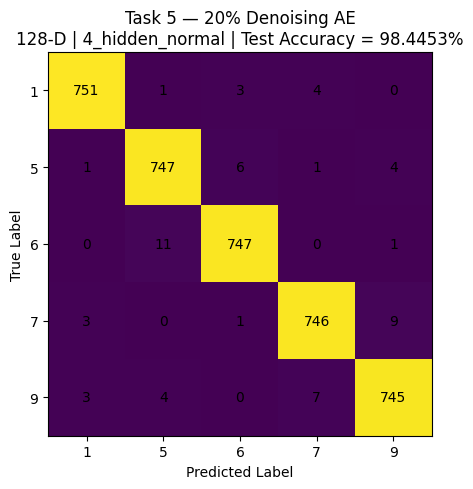

Saved: /content/task5_denoising/figures/confusion_matrices/confusion_matrix_40pct.png


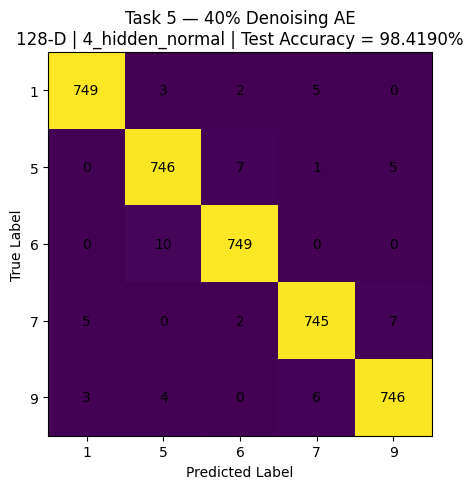


Task 5 confusion matrix figures saved.


In [ ]:
# ==========================================
# TASK 5 — CONFUSION MATRIX FIGURES
# ==========================================

TASK5_CM_FIG_DIR = os.path.join(
    TASK5_FIG_DIR,
    "confusion_matrices"
)

os.makedirs(
    TASK5_CM_FIG_DIR,
    exist_ok=True
)


for _, row in task5_classification_df.iterrows():

    noise_label = row["noise"]

    cm = task5_confusion_matrices[
        noise_label
    ]

    save_path = os.path.join(
        TASK5_CM_FIG_DIR,
        f"confusion_matrix_"
        f"{noise_label.replace('%','pct')}.png"
    )

    plot_confusion_matrix(
        cm=cm,
        class_names=classes,
        title=(
            f"Task 5 — {noise_label} "
            f"Denoising AE\n"
            f"128-D | "
            f"{row['architecture']} | "
            f"Test Accuracy = "
            f"{row['test_accuracy']:.4f}%"
        ),
        save_path=save_path
    )

print(
    "\nTask 5 confusion matrix figures saved."
)

In [ ]:
# ==========================================
# TASK 5 — SAVE COMPRESSED REPRESENTATIONS
# ==========================================

for noise_label in ["20%", "40%"]:

    prefix = (
        f"dae_{noise_label.replace('%','pct')}"
    )

    np.save(
        os.path.join(
            TASK5_REP_DIR,
            f"{prefix}_train_128.npy"
        ),
        task5_compressed[
            noise_label
        ]["train"].cpu().numpy()
    )

    np.save(
        os.path.join(
            TASK5_REP_DIR,
            f"{prefix}_val_128.npy"
        ),
        task5_compressed[
            noise_label
        ]["val"].cpu().numpy()
    )

    np.save(
        os.path.join(
            TASK5_REP_DIR,
            f"{prefix}_test_128.npy"
        ),
        task5_compressed[
            noise_label
        ]["test"].cpu().numpy()
    )

print(
    "Task 5 compressed representations saved."
)

Task 5 compressed representations saved.


In [ ]:
# ==========================================
# TASK 5 — FINAL SUMMARY
# ==========================================

print("=" * 80)
print("TASK 5 — FINAL SUMMARY")
print("=" * 80)

print("\nReconstruction results:")
display(
    task5_reconstruction_df
)

print("\nClassification results:")
display(
    task5_classification_df
)

print("\nTask 5 setup:")
print(
    "Bottleneck dimension : 128"
)

print(
    "Noise distributions  : N(0,1)"
)

print(
    "Noise levels         : 20%, 40%"
)

print(
    "Classifier           : "
    "4_hidden_normal"
)

print(
    "Classifier layers    : "
    "[256, 128, 64, 32]"
)

TASK 5 — FINAL SUMMARY

Reconstruction results:


,noise,noise_fraction,bottleneck_dim,best_epoch,best_val_mse,train_mse,val_mse,test_mse
0,20%,0.2,128,429,0.010579,0.010297,0.010644,0.010699
1,40%,0.4,128,500,0.016291,0.015991,0.016365,0.016454



Classification results:


,noise,representation_dim,architecture,hidden_layers,best_epoch,validation_accuracy,test_accuracy,checkpoint
0,20%,128,4_hidden_normal,"[256, 128, 64, 32]",8,98.577075,98.445323,/content/task5_denoising/checkpoints/classifie...
1,40%,128,4_hidden_normal,"[256, 128, 64, 32]",10,98.550725,98.418972,/content/task5_denoising/checkpoints/classifie...



Task 5 setup:
Bottleneck dimension : 128
Noise distributions  : N(0,1)
Noise levels         : 20%, 40%
Classifier           : 4_hidden_normal
Classifier layers    : [256, 128, 64, 32]


In [ ]:
!zip task5_denoising.zip -r task5_denoising

  adding: task5_denoising/ (stored 0%)
  adding: task5_denoising/figures/ (stored 0%)
  adding: task5_denoising/figures/dae_20pct_test_reconstructions.png (deflated 32%)
  adding: task5_denoising/figures/dae_20pct_train_reconstructions.png (deflated 32%)
  adding: task5_denoising/figures/dae_20pct_validation_reconstructions.png (deflated 32%)
  adding: task5_denoising/figures/dae_40pct_test_reconstructions.png (deflated 32%)
  adding: task5_denoising/figures/dae_40pct_validation_reconstructions.png (deflated 31%)
  adding: task5_denoising/figures/confusion_matrices/ (stored 0%)
  adding: task5_denoising/figures/confusion_matrices/confusion_matrix_20pct.png (deflated 16%)
  adding: task5_denoising/figures/confusion_matrices/confusion_matrix_40pct.png (deflated 16%)
  adding: task5_denoising/figures/dae_40pct_train_reconstructions.png (deflated 33%)
  adding: task5_denoising/compressed_representations/ (stored 0%)
  adding: task5_denoising/compressed_representations/dae_20pct_test_128.np

# **TASK 6**

In [ ]:
# ==========================================
# TASK 6 — CHECKPOINT PATHS
# ==========================================

TASK6_DIR = "/content/task6_weight_visualization"

TASK6_FIG_DIR = os.path.join(
    TASK6_DIR,
    "figures"
)

TASK6_DETAILED_DIR = os.path.join(
    TASK6_FIG_DIR,
    "detailed")

os.makedirs(
    TASK6_DETAILED_DIR,
    exist_ok=True
)


# Normal 1-hidden AE
AE_128_CHECKPOINT = (
    "/content/ae_1_hidden_128_best_500.pt"
)


# 20% DAE
DAE_20_CHECKPOINT = (
    "/content/task5_denoising/"
    "checkpoints/"
    "dae_20pct_128_best_500.pt"
)


# 40% DAE
DAE_40_CHECKPOINT = (
    "/content/task5_denoising/"
    "checkpoints/"
    "dae_40pct_128_best_500.pt"
)


print("Normal AE:")
print(AE_128_CHECKPOINT)

print("\n20% DAE:")
print(DAE_20_CHECKPOINT)

print("\n40% DAE:")
print(DAE_40_CHECKPOINT)

Normal AE:
/content/ae_1_hidden_128_best_500.pt

20% DAE:
/content/task5_denoising/checkpoints/dae_20pct_128_best_500.pt

40% DAE:
/content/task5_denoising/checkpoints/dae_40pct_128_best_500.pt


In [ ]:
# ==========================================
# TASK 6 — INSPECT CHECKPOINTS
# ==========================================

def inspect_checkpoint(path, name):

    print("\n")
    print("=" * 80)
    print(name)
    print("=" * 80)

    checkpoint = torch.load(
        path,
        map_location="cpu"
    )

    print("\nCheckpoint type:")
    print(type(checkpoint))

    if isinstance(checkpoint, dict):

        print("\nCheckpoint keys:")

        for key in checkpoint.keys():
            print("  ", key)

        if "model_state_dict" in checkpoint:

            print("\nModel state_dict:")

            for key, value in (
                checkpoint[
                    "model_state_dict"
                ].items()
            ):

                if torch.is_tensor(value):

                    print(
                        f"  {key:40s}"
                        f"{tuple(value.shape)}"
                    )

    return checkpoint


ae128_checkpoint = inspect_checkpoint(
    AE_128_CHECKPOINT,
    "NORMAL 1-HIDDEN AE — 128-D"
)

dae20_checkpoint = inspect_checkpoint(
    DAE_20_CHECKPOINT,
    "DAE — 20% NOISE — 128-D"
)

dae40_checkpoint = inspect_checkpoint(
    DAE_40_CHECKPOINT,
    "DAE — 40% NOISE — 128-D"
)



NORMAL 1-HIDDEN AE — 128-D

Checkpoint type:
<class 'dict'>

Checkpoint keys:
   task
   architecture
   input_dim
   bottleneck_dim
   best_val_loss
   best_epoch
   model_state_dict
   optimizer_state_dict
   history
   learning_rate
   batch_size
   optimizer
   activation
   bottleneck_activation
   initialization
   seed

Model state_dict:
  encoder.weight                          (128, 784)
  encoder.bias                            (128,)
  decoder.0.weight                        (784, 128)
  decoder.0.bias                          (784,)


DAE — 20% NOISE — 128-D

Checkpoint type:
<class 'dict'>

Checkpoint keys:
   task
   architecture
   input_dim
   bottleneck_dim
   noise_fraction
   noise_distribution
   best_val_loss
   best_epoch
   model_state_dict
   optimizer_state_dict
   history
   learning_rate
   batch_size
   optimizer
   activation
   bottleneck_activation
   initialization
   epochs
   seed

Model state_dict:
  encoder.weight                          (128, 784

In [ ]:
# ==========================================
# TASK 6 — LOAD CHECKPOINTS
# ==========================================

ae128_checkpoint = torch.load(
    AE_128_CHECKPOINT,
    map_location="cpu"
)

dae20_checkpoint = torch.load(
    DAE_20_CHECKPOINT,
    map_location="cpu"
)

dae40_checkpoint = torch.load(
    DAE_40_CHECKPOINT,
    map_location="cpu"
)


def extract_input_to_bottleneck_weights(
    checkpoint,
    name
):

    state_dict = checkpoint[
        "model_state_dict"
    ]

    candidates = []

    for key, value in state_dict.items():

        if (
            torch.is_tensor(value)
            and value.ndim == 2
            and tuple(value.shape) == (128, 784)
        ):

            candidates.append(
                (key, value)
            )

    if len(candidates) == 0:

        print(
            f"\n{name}: available weight matrices:"
        )

        for key, value in state_dict.items():

            if (
                torch.is_tensor(value)
                and value.ndim == 2
            ):

                print(
                    key,
                    tuple(value.shape)
                )

        raise ValueError(
            f"Could not find (128, 784) "
            f"weight matrix for {name}"
        )

    weight_key, weights = candidates[0]

    print(
        f"{name}: {weight_key} "
        f"{tuple(weights.shape)}"
    )

    return (
        weights
        .detach()
        .cpu()
    )


ae128_weights = (
    extract_input_to_bottleneck_weights(
        ae128_checkpoint,
        "Normal 1-hidden AE"
    )
)

dae20_weights = (
    extract_input_to_bottleneck_weights(
        dae20_checkpoint,
        "20% DAE"
    )
)

dae40_weights = (
    extract_input_to_bottleneck_weights(
        dae40_checkpoint,
        "40% DAE"
    )
)

Normal 1-hidden AE: encoder.weight (128, 784)
20% DAE: encoder.weight (128, 784)
40% DAE: encoder.weight (128, 784)


In [ ]:
# ==========================================
# EXTRACT ALL THREE WEIGHT MATRICES
# ==========================================

ae128_weights = (
    extract_input_to_bottleneck_weights(
        ae128_checkpoint,
        "Normal 1-hidden AE"
    )
)

dae20_weights = (
    extract_input_to_bottleneck_weights(
        dae20_checkpoint,
        "20% Denoising AE"
    )
)

dae40_weights = (
    extract_input_to_bottleneck_weights(
        dae40_checkpoint,
        "40% Denoising AE"
    )
)


Normal 1-hidden AE
Selected layer : encoder.weight
Weight shape   : (128, 784)

20% Denoising AE
Selected layer : encoder.weight
Weight shape   : (128, 784)

40% Denoising AE
Selected layer : encoder.weight
Weight shape   : (128, 784)


In [ ]:
# ==========================================
# OPTIONAL — 4×4 WITH COLORBAR
# ==========================================

def plot_weight_pages_with_colorbar(
    weights,
    model_name,
    output_dir
):

    weights_np = (
        weights
        .detach()
        .cpu()
        .numpy()
    )

    max_abs = np.max(
        np.abs(weights_np)
    )

    for start in range(
        0,
        128,
        16
    ):

        end = start + 16

        fig, axes = plt.subplots(
            4,
            4,
            figsize=(15, 15)
        )

        axes = axes.flatten()

        for local_idx, neuron_idx in enumerate(
            range(start, end)
        ):

            image = weights_np[
                neuron_idx
            ].reshape(28, 28)

            im = axes[
                local_idx
            ].imshow(
                image,
                cmap="seismic",
                vmin=-max_abs,
                vmax=max_abs,
                interpolation="nearest"
            )

            axes[
                local_idx
            ].set_title(
                f"Neuron {neuron_idx + 1}",
                fontsize=13
            )

            axes[
                local_idx
            ].axis("off")

        # Shared colorbar
        cbar = fig.colorbar(
            im,
            ax=axes.tolist(),
            fraction=0.025,
            pad=0.02
        )

        cbar.set_label(
            "Weight value",
            fontsize=12
        )

        fig.suptitle(
            (
                f"{model_name}\n"
                f"Input → Compressed Layer "
                f"Weights | "
                f"Neurons {start + 1}–{end}"
            ),
            fontsize=20,
            fontweight="bold"
        )

        plt.tight_layout(
            rect=[0, 0, 0.95, 0.94]
        )

        filename = (
            f"neurons_{start + 1:03d}"
            f"_{end:03d}_colorbar.png"
        )

        save_path = os.path.join(
            output_dir,
            filename
        )

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        plt.close()

/tmp/ipykernel_1632/2125805302.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


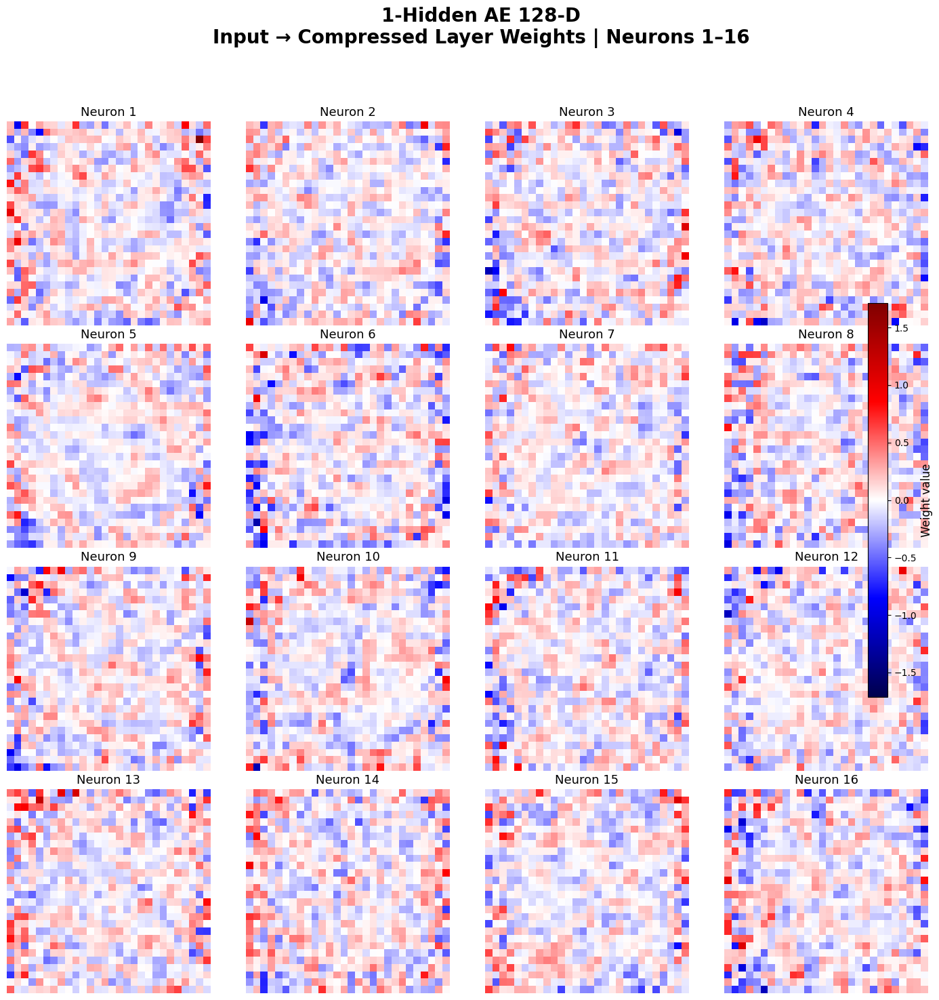

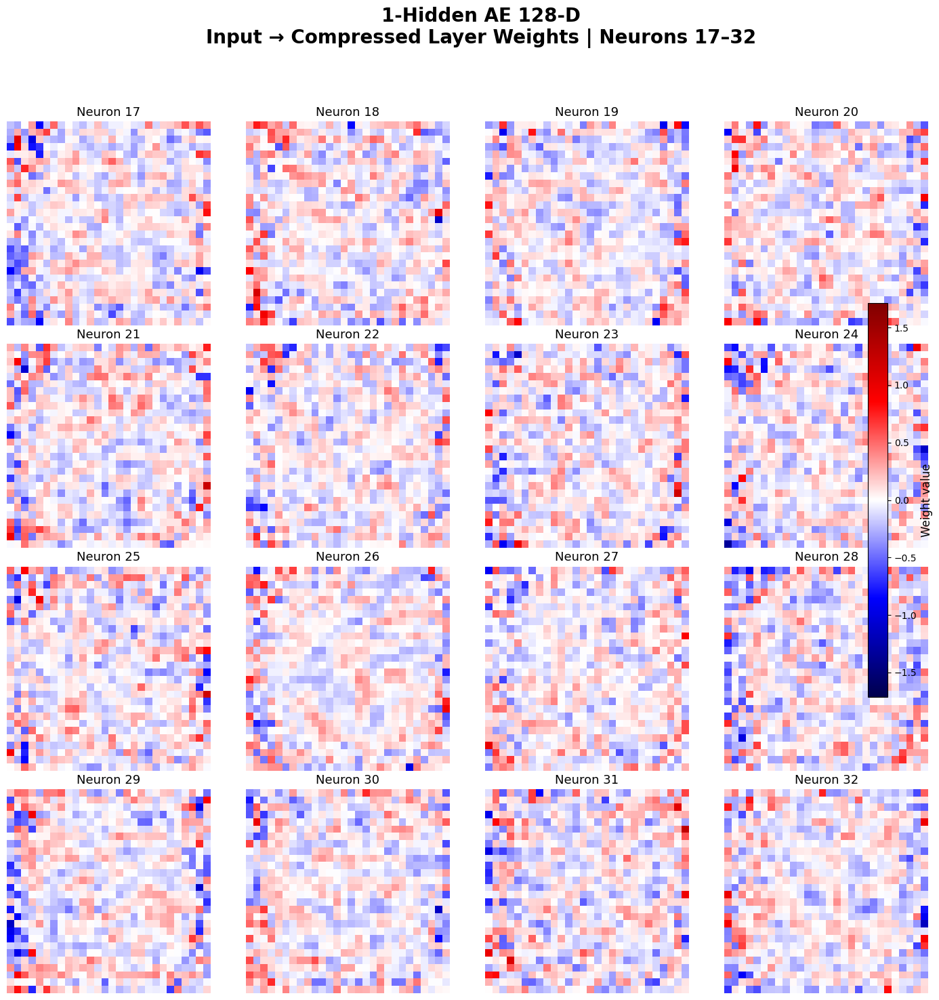

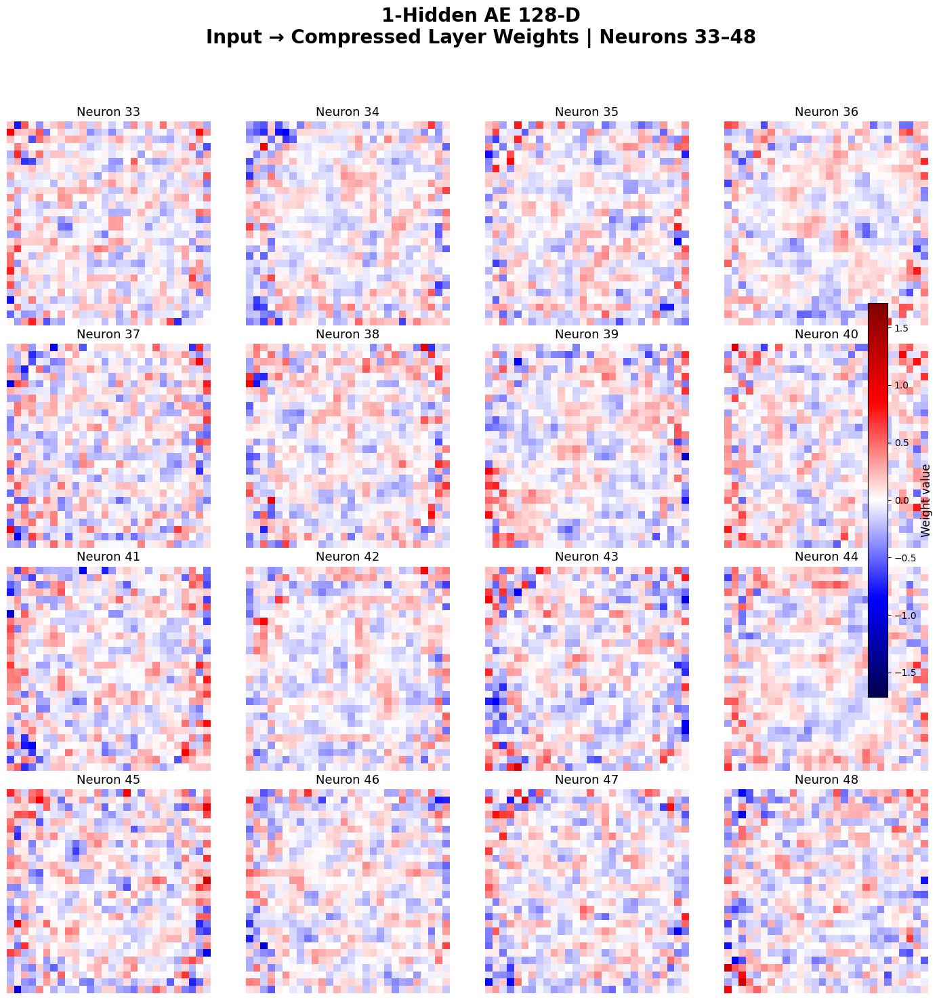

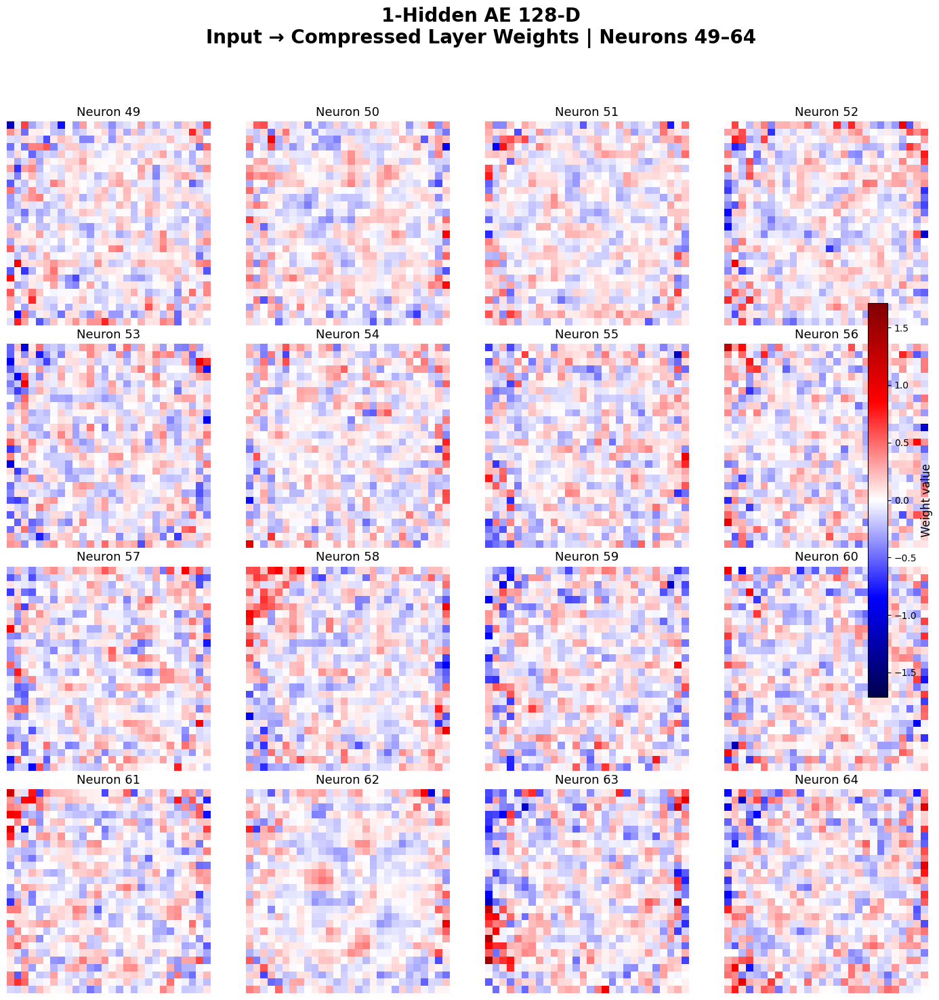

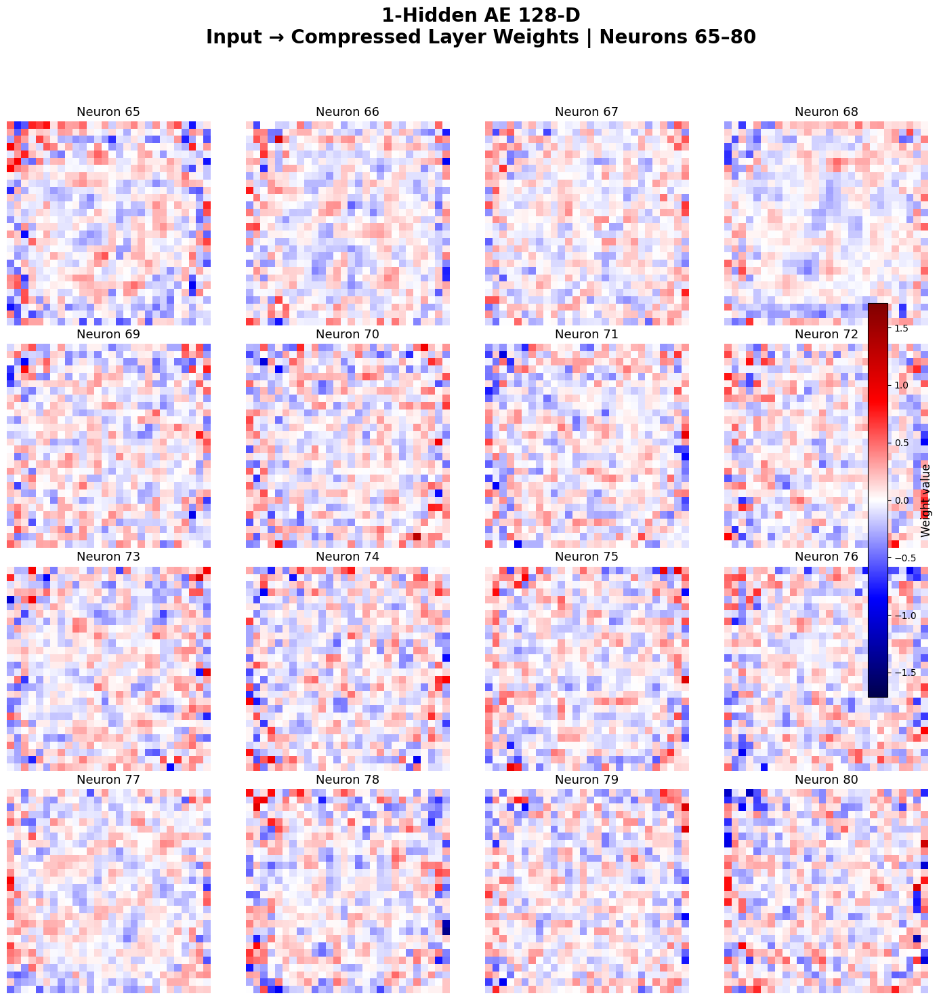

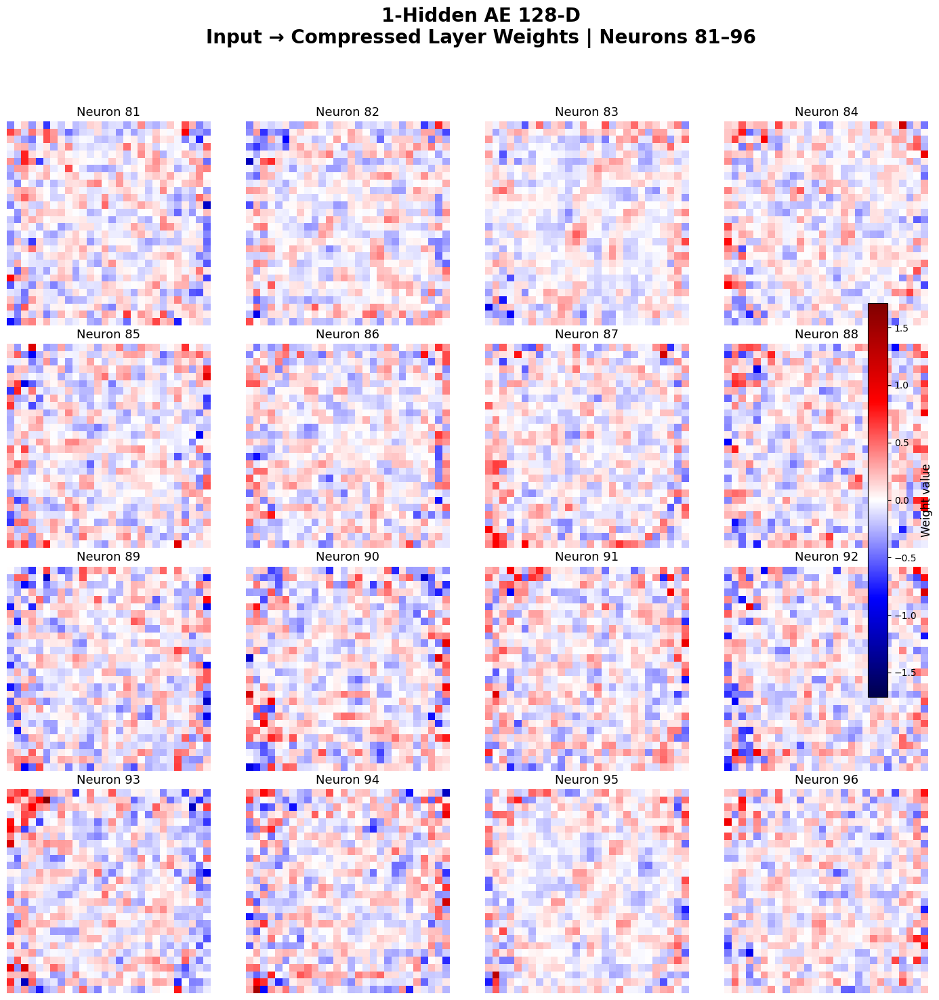

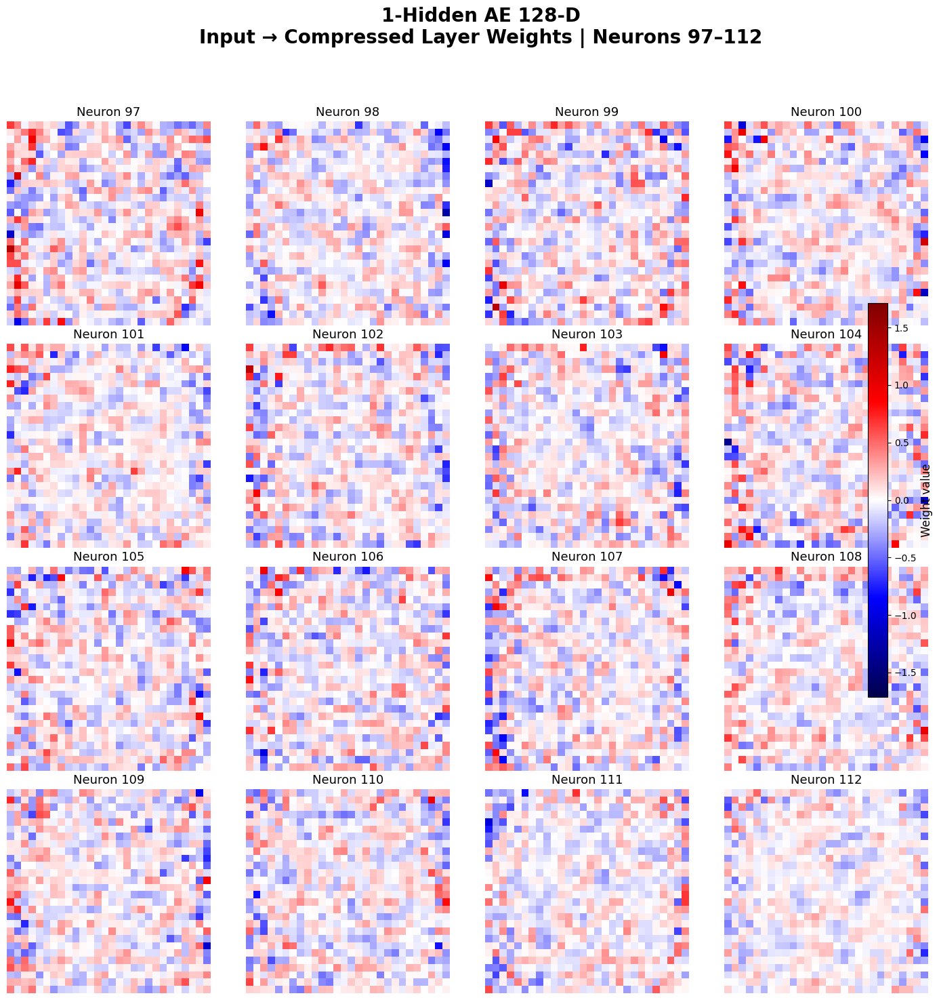

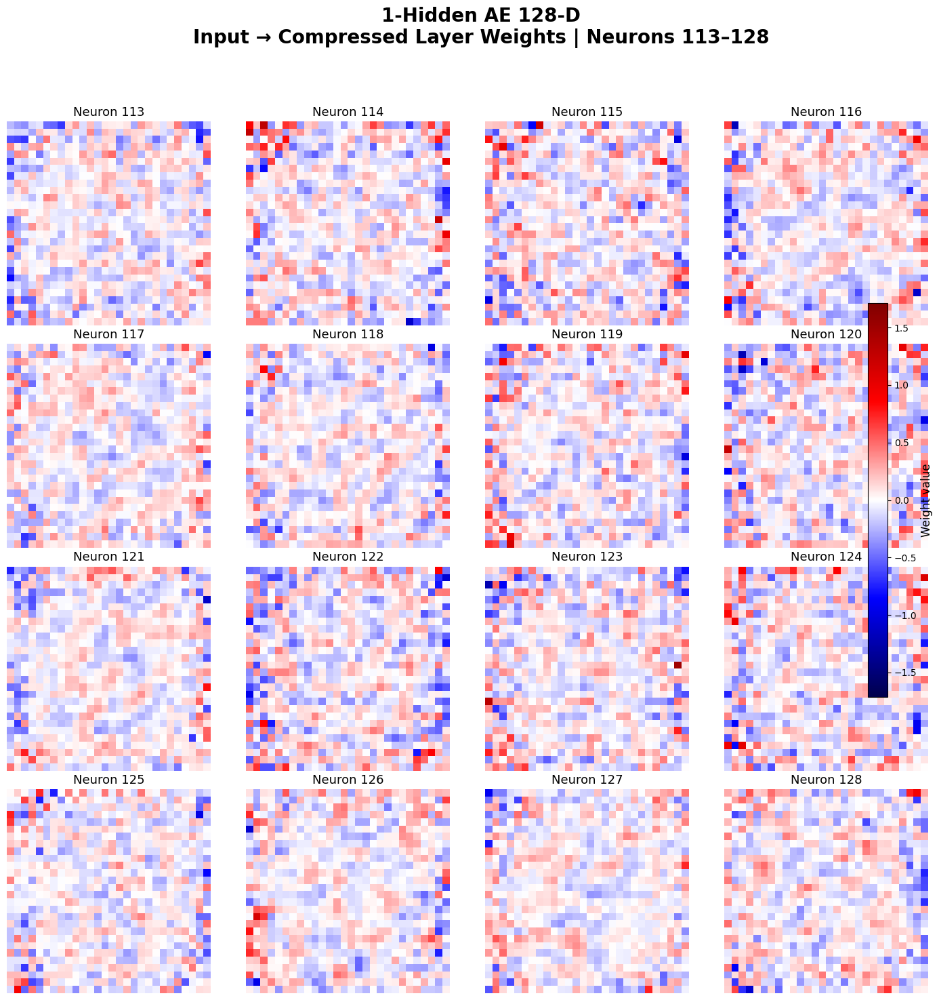

In [ ]:
# ==========================================
# TASK 6(a) — NORMAL AE
# ==========================================

AE_DETAILED_DIR = os.path.join(
    TASK6_DETAILED_DIR,
    "normal_ae"
)

os.makedirs(
    AE_DETAILED_DIR,
    exist_ok=True
)


plot_weight_pages_with_colorbar(
    weights=ae128_weights,
    model_name="1-Hidden AE 128-D",
    output_dir=AE_DETAILED_DIR
)

/tmp/ipykernel_1632/2125805302.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


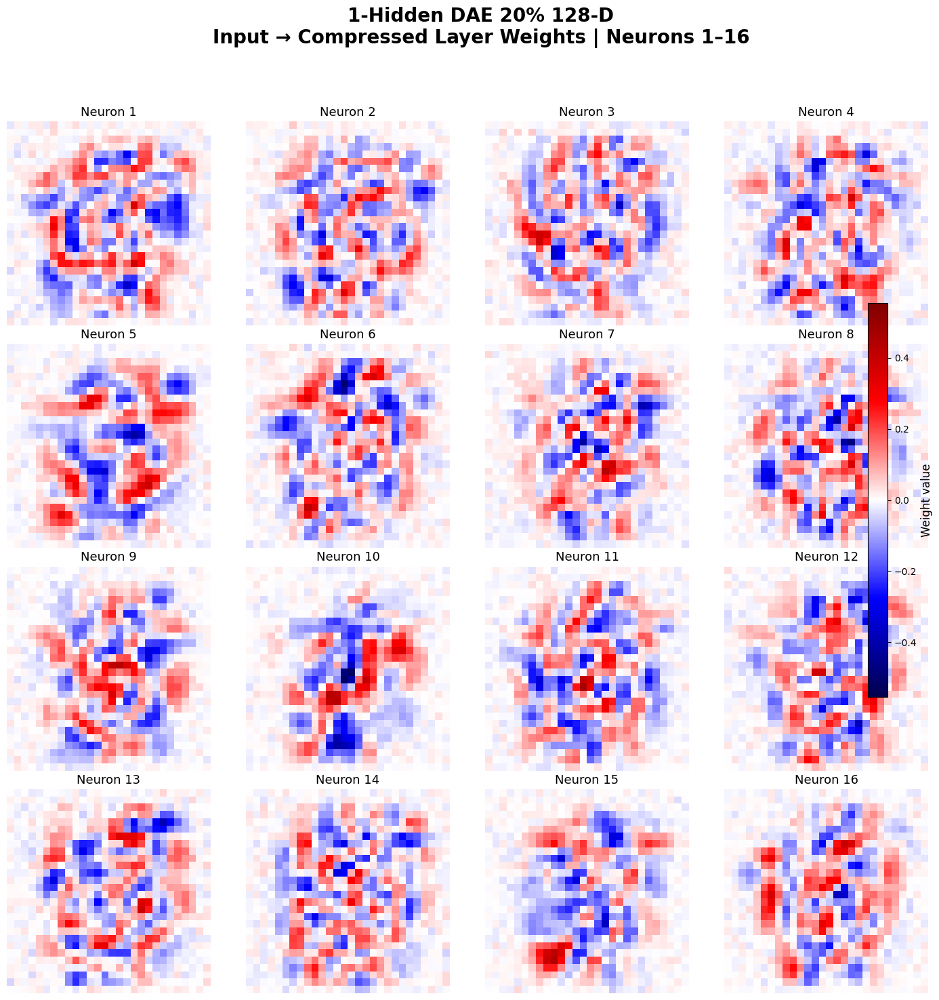

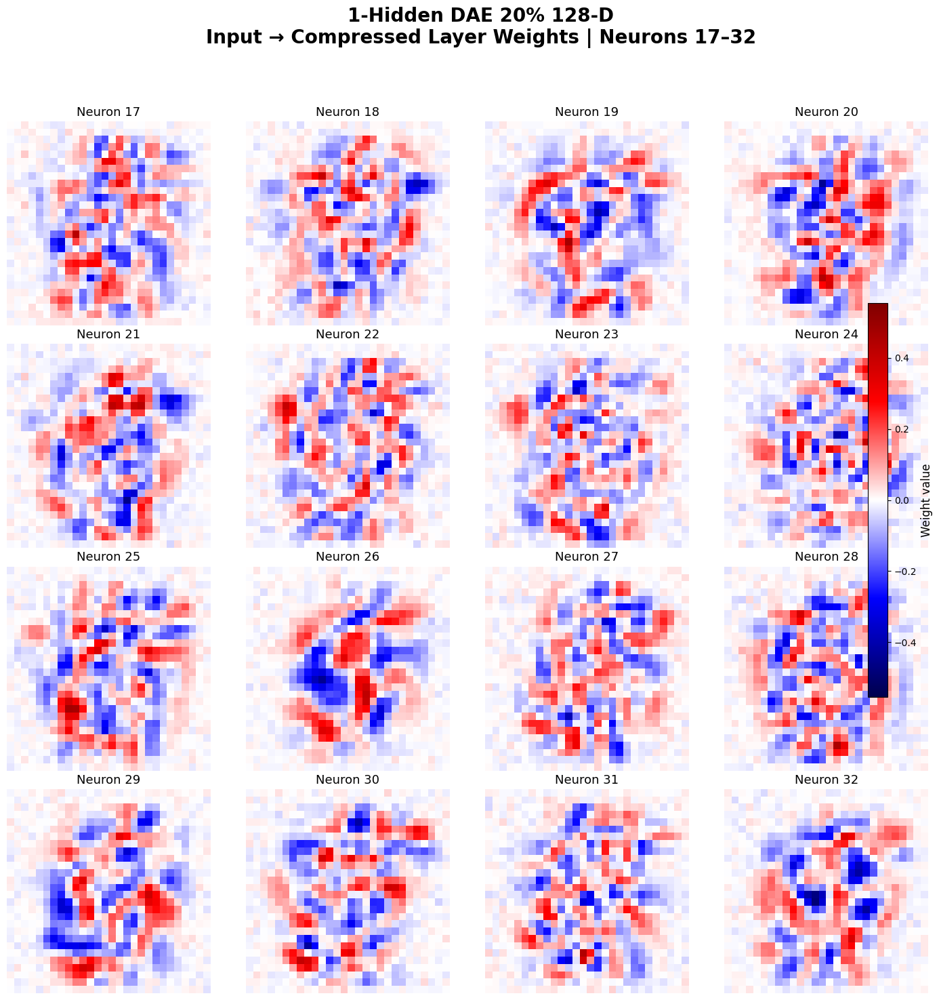

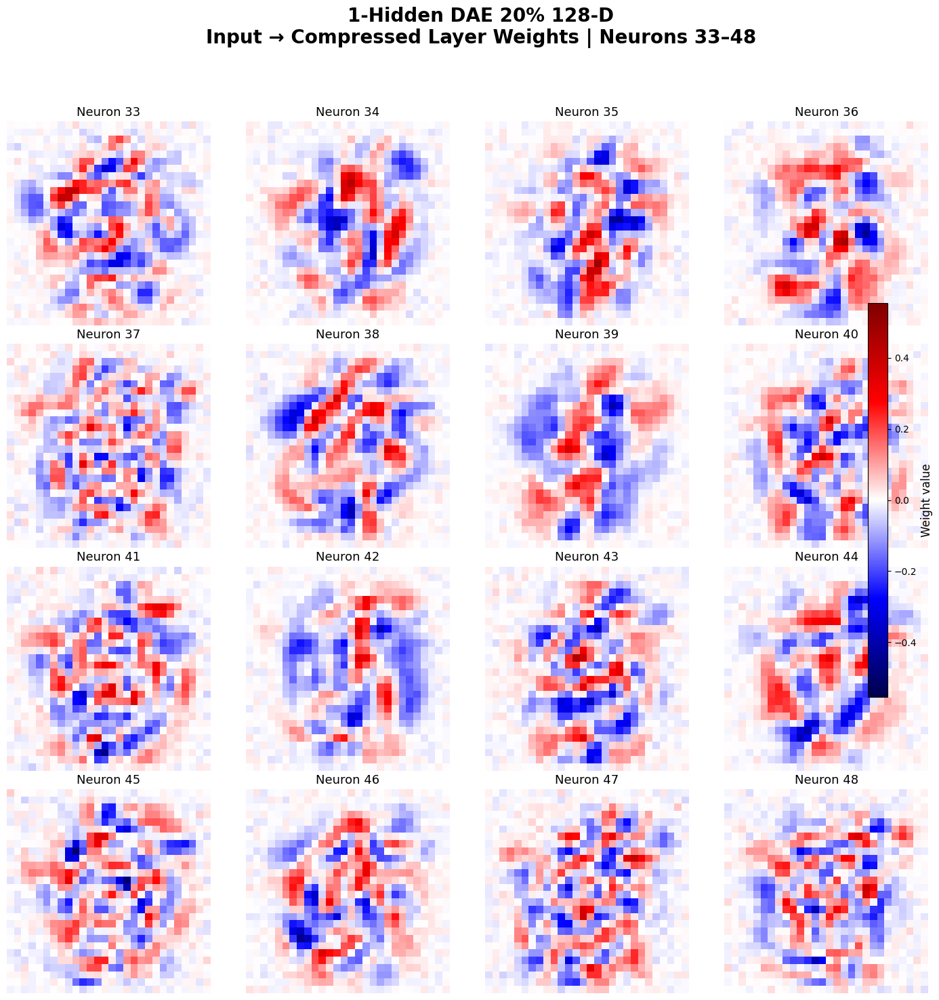

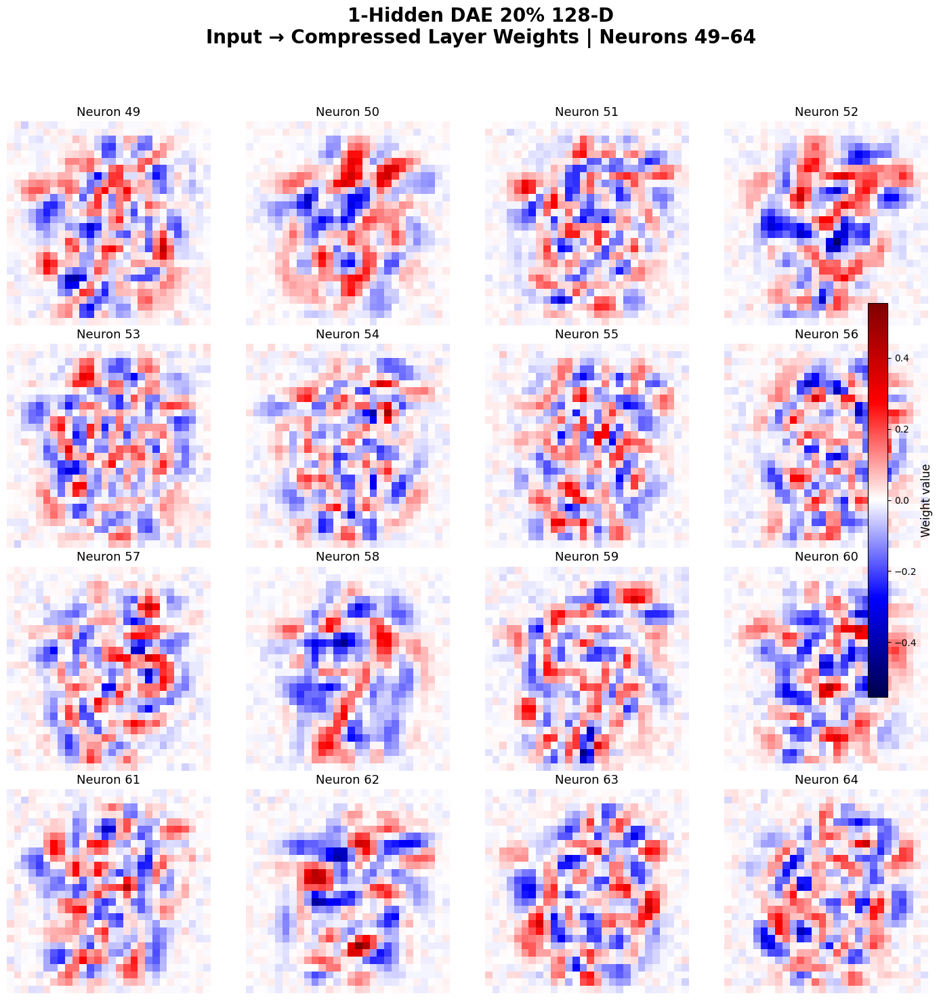

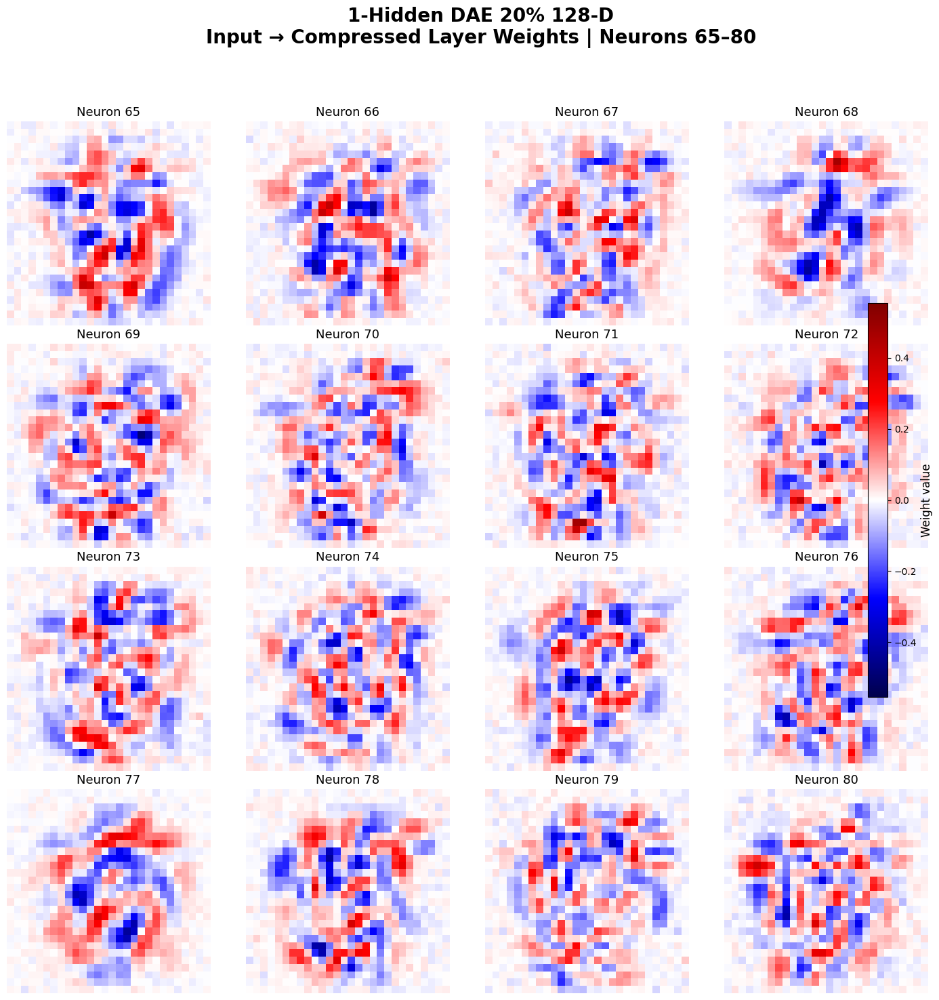

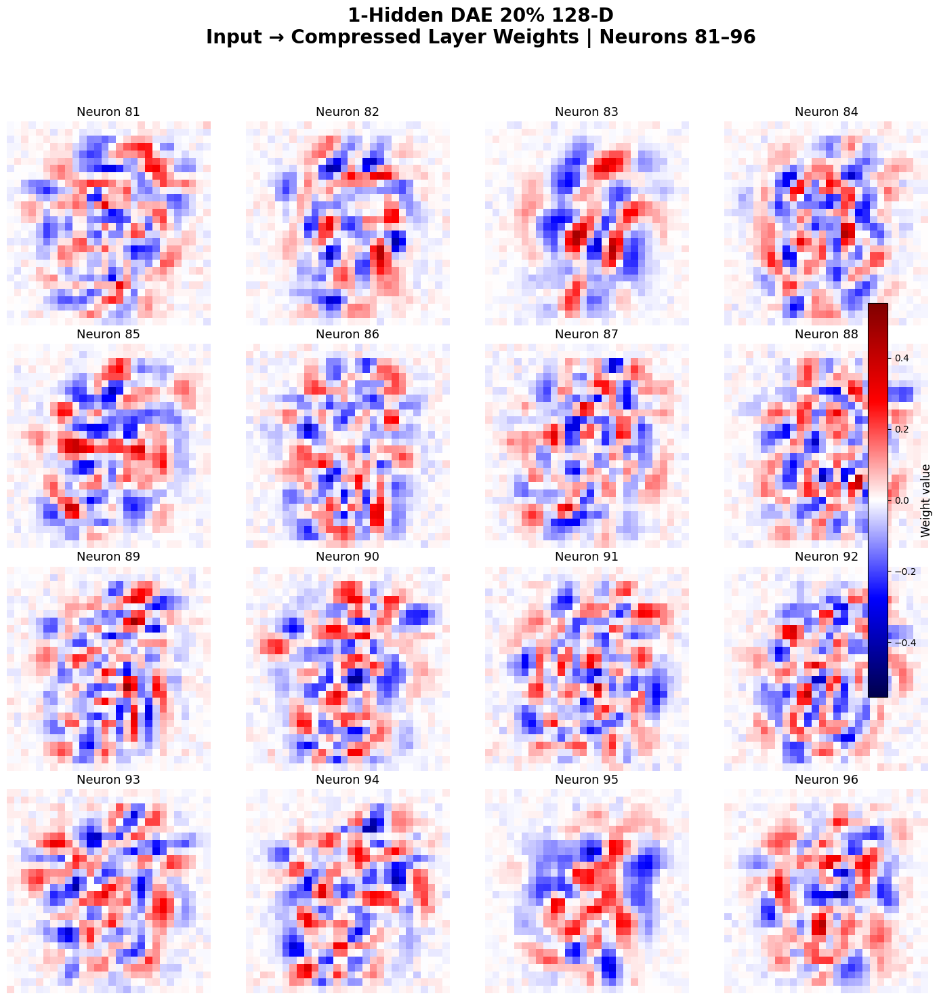

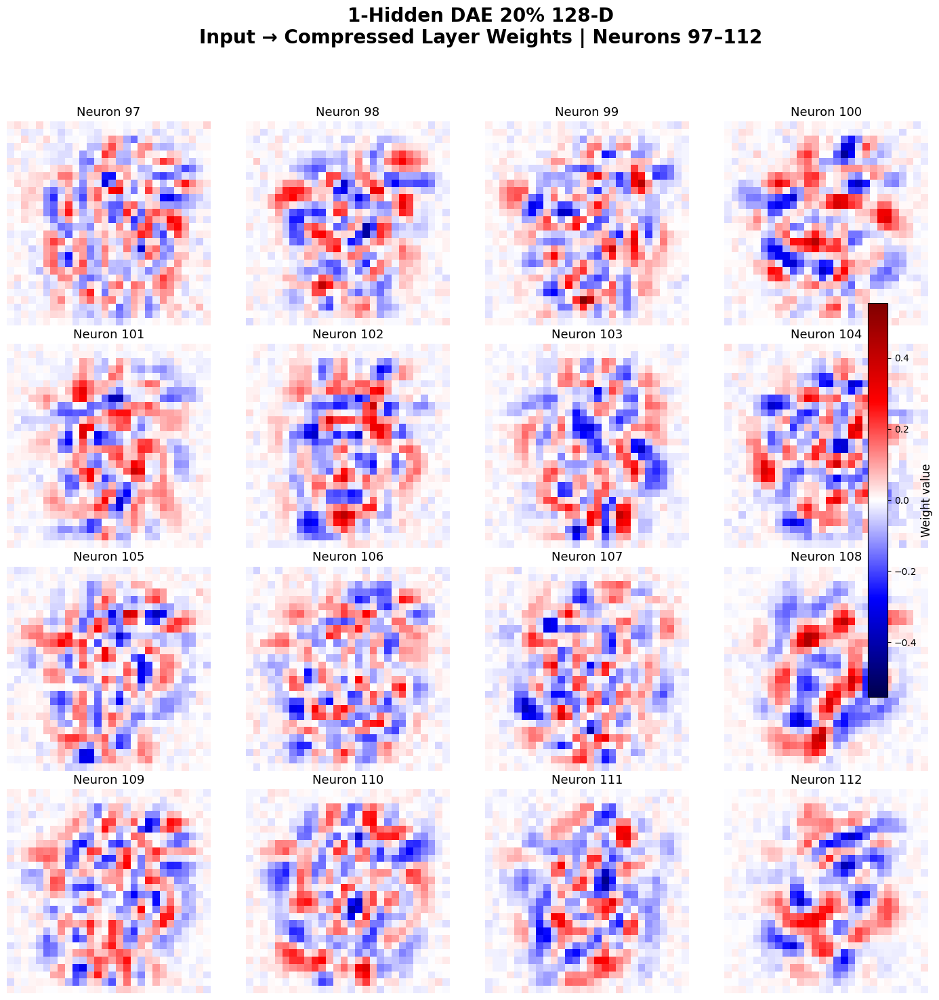

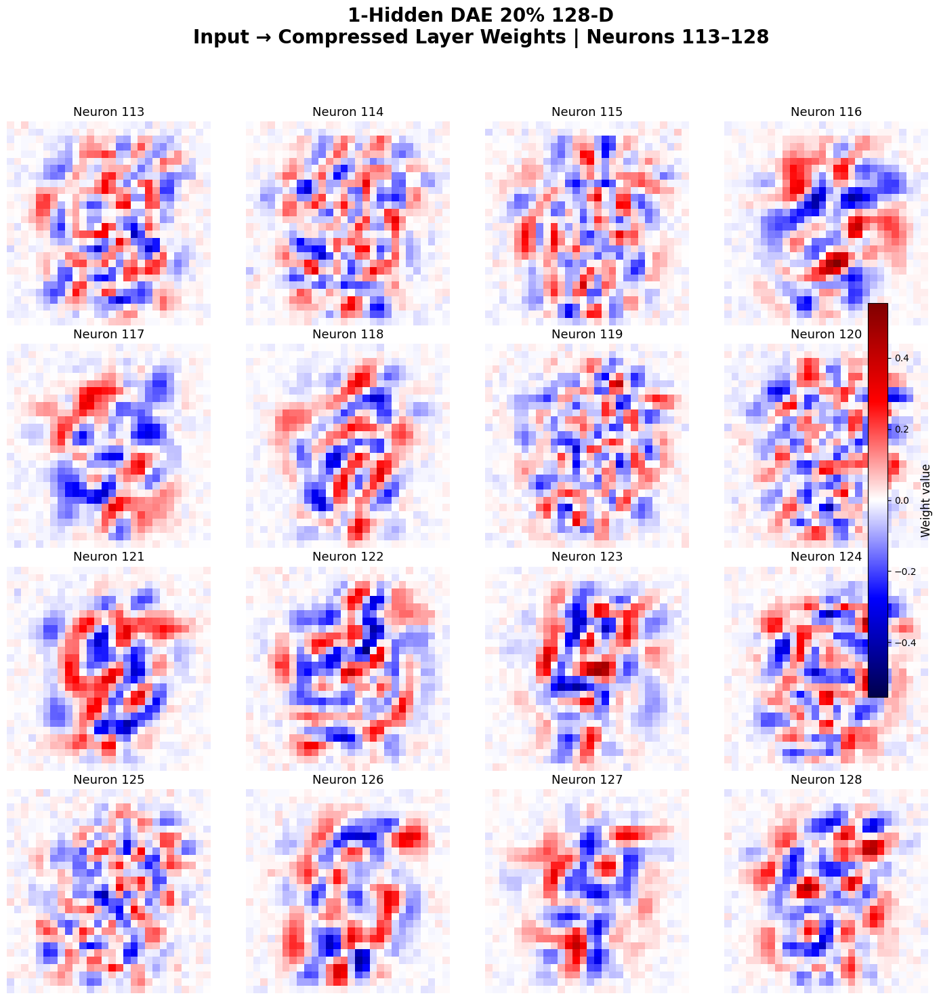

In [ ]:
# ==========================================
# TASK 6(b)
# 20% DENOISING AUTOENCODER
# ==========================================

DAE_DETAILED_DIR = os.path.join(
    TASK6_DETAILED_DIR,
    "DAE_20PCT"
)

os.makedirs(
    DAE_DETAILED_DIR,
    exist_ok=True
)

plot_weight_pages_with_colorbar(
    weights=dae20_weights,
    model_name="1-Hidden DAE 20% 128-D",
    output_dir=AE_DETAILED_DIR
)


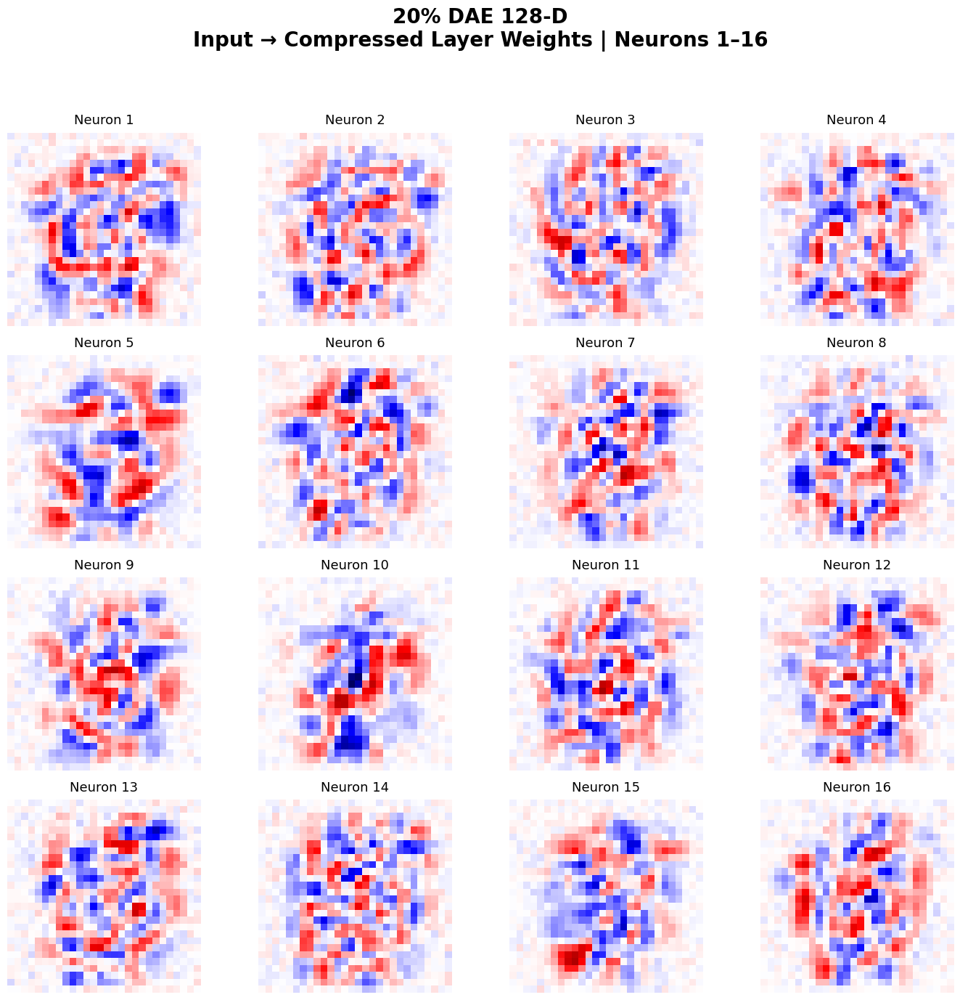

Saved: /content/task6_weight_visualization/figures/detailed/dae_20pct/20%_dae_128-d_neurons_001_016.png


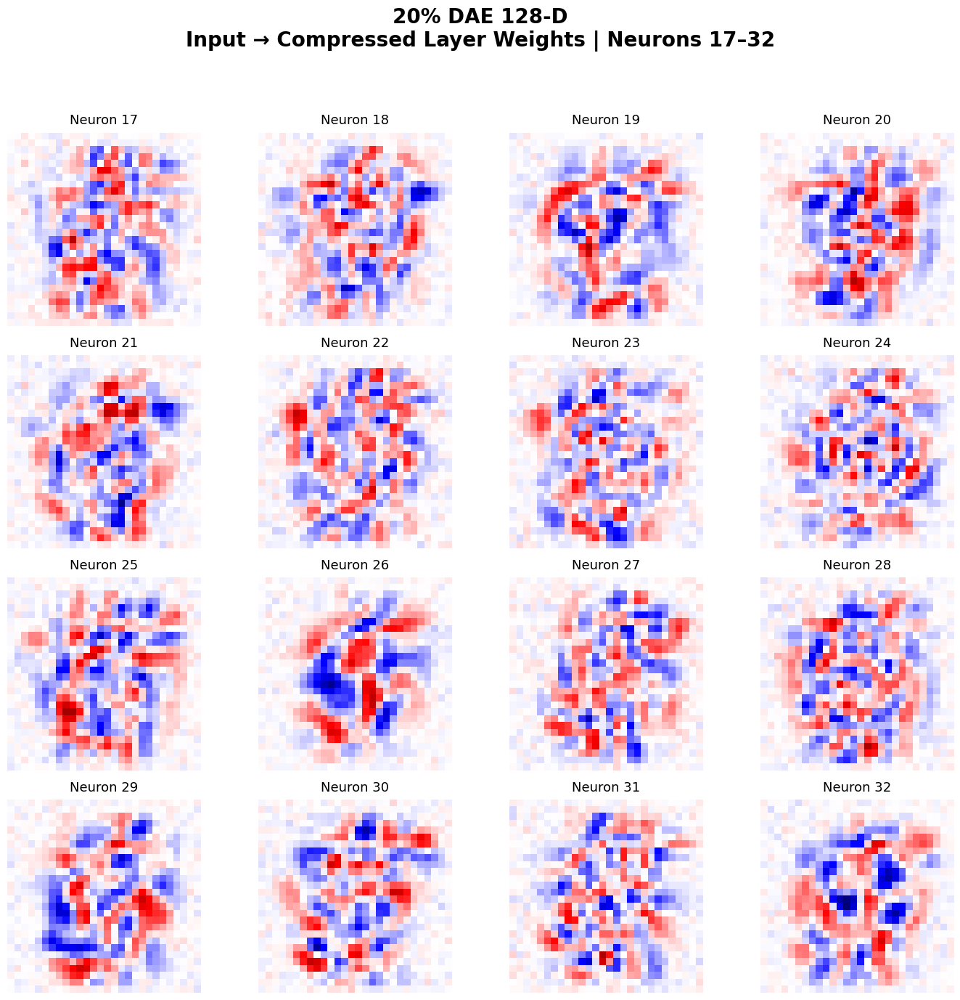

Saved: /content/task6_weight_visualization/figures/detailed/dae_20pct/20%_dae_128-d_neurons_017_032.png


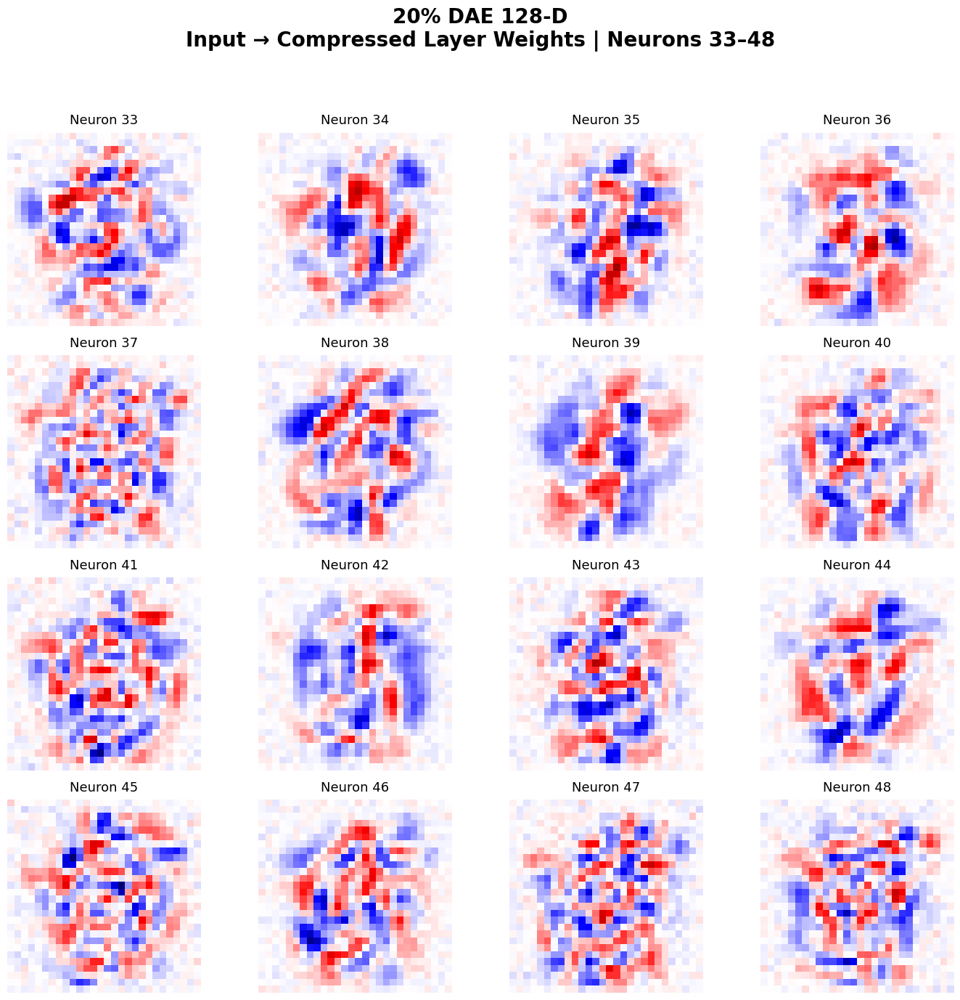

Saved: /content/task6_weight_visualization/figures/detailed/dae_20pct/20%_dae_128-d_neurons_033_048.png


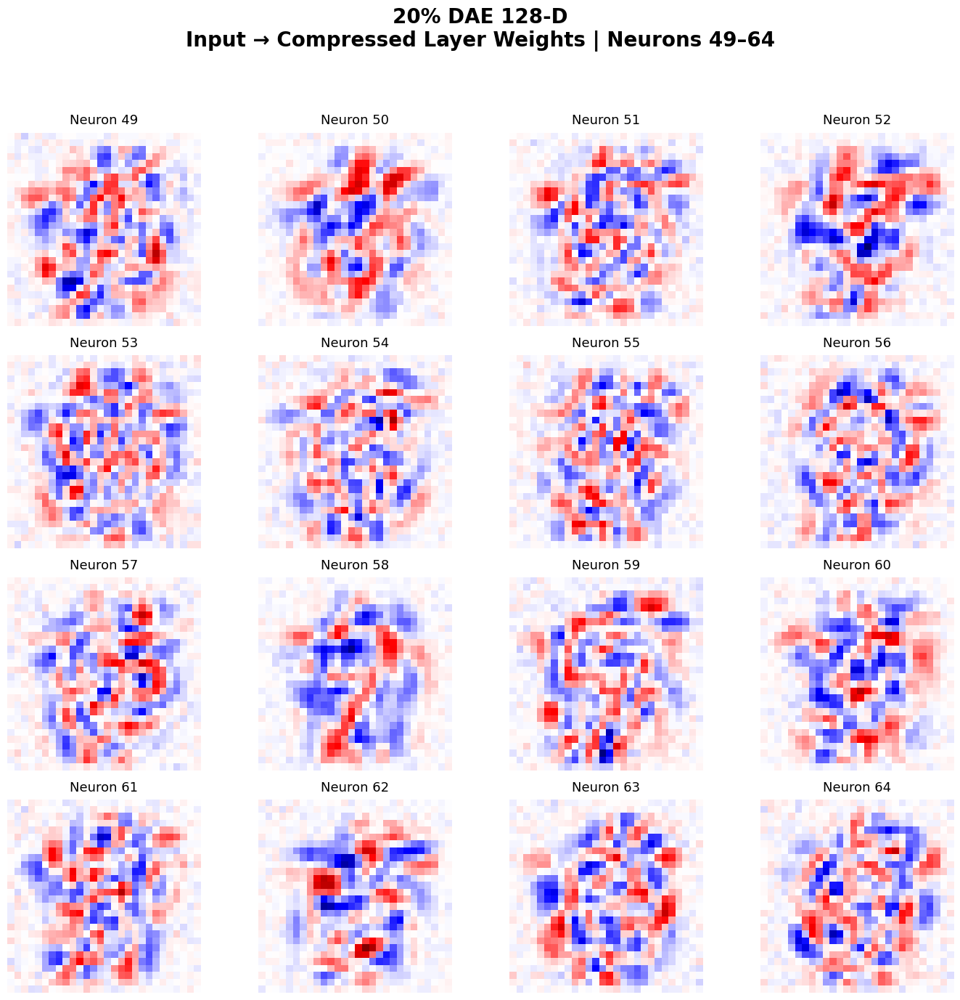

Saved: /content/task6_weight_visualization/figures/detailed/dae_20pct/20%_dae_128-d_neurons_049_064.png


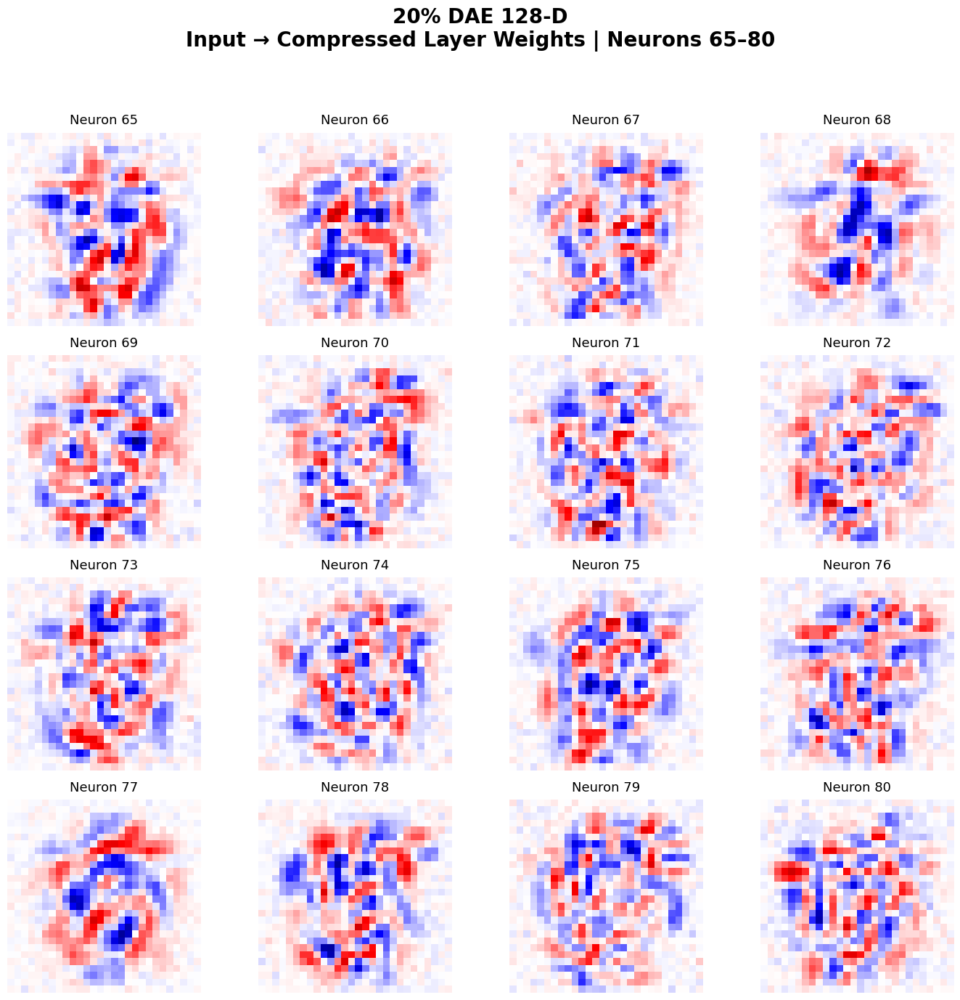

Saved: /content/task6_weight_visualization/figures/detailed/dae_20pct/20%_dae_128-d_neurons_065_080.png


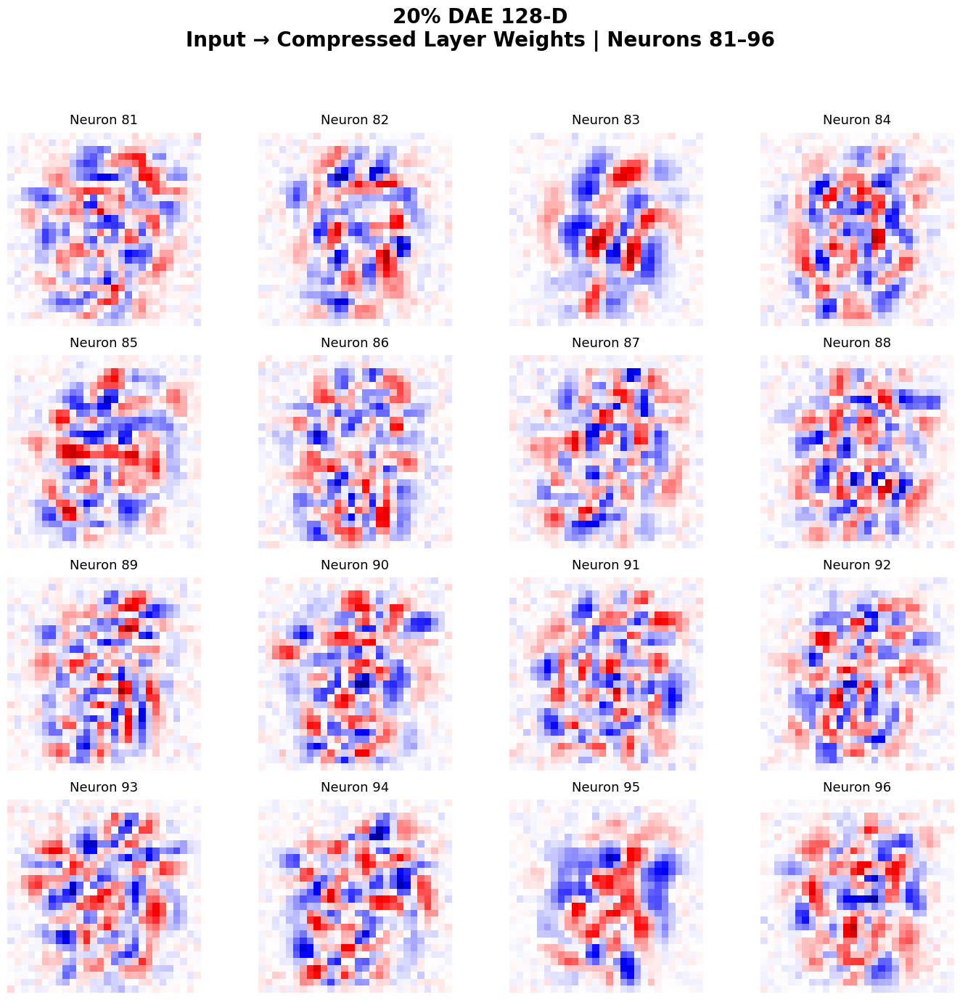

Saved: /content/task6_weight_visualization/figures/detailed/dae_20pct/20%_dae_128-d_neurons_081_096.png


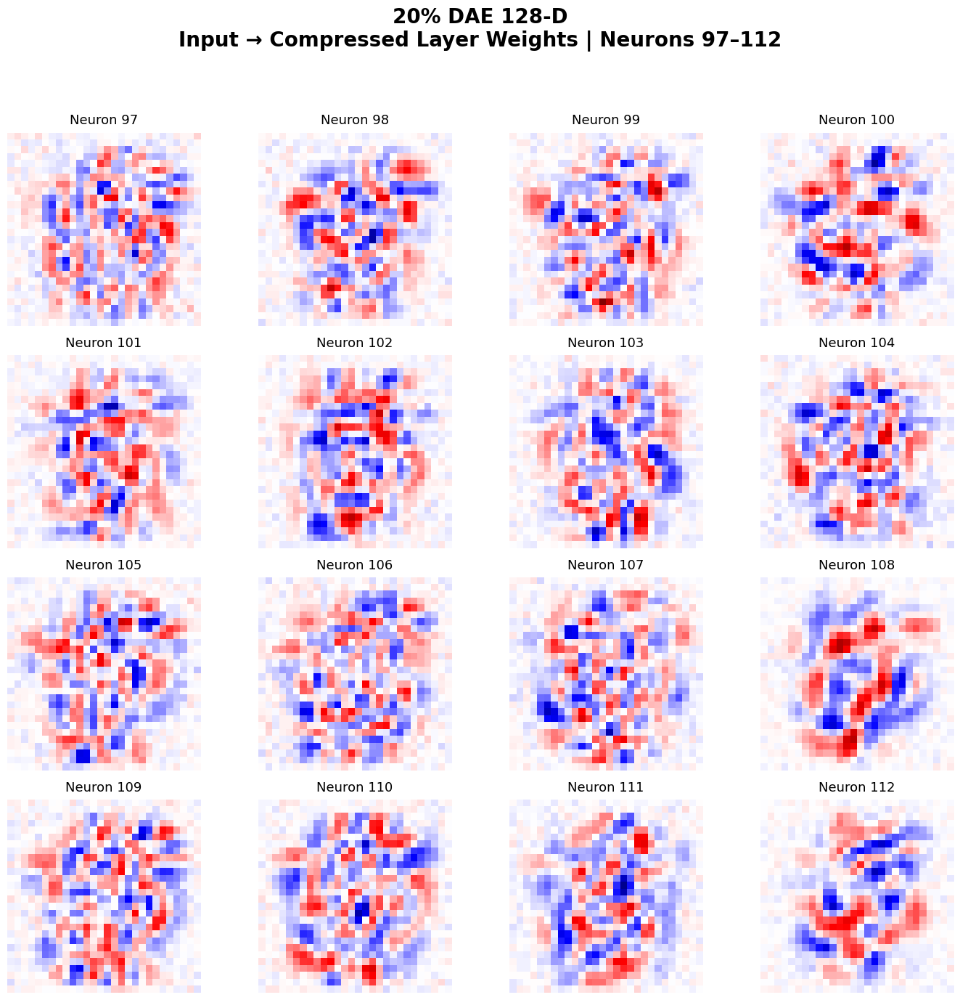

Saved: /content/task6_weight_visualization/figures/detailed/dae_20pct/20%_dae_128-d_neurons_097_112.png


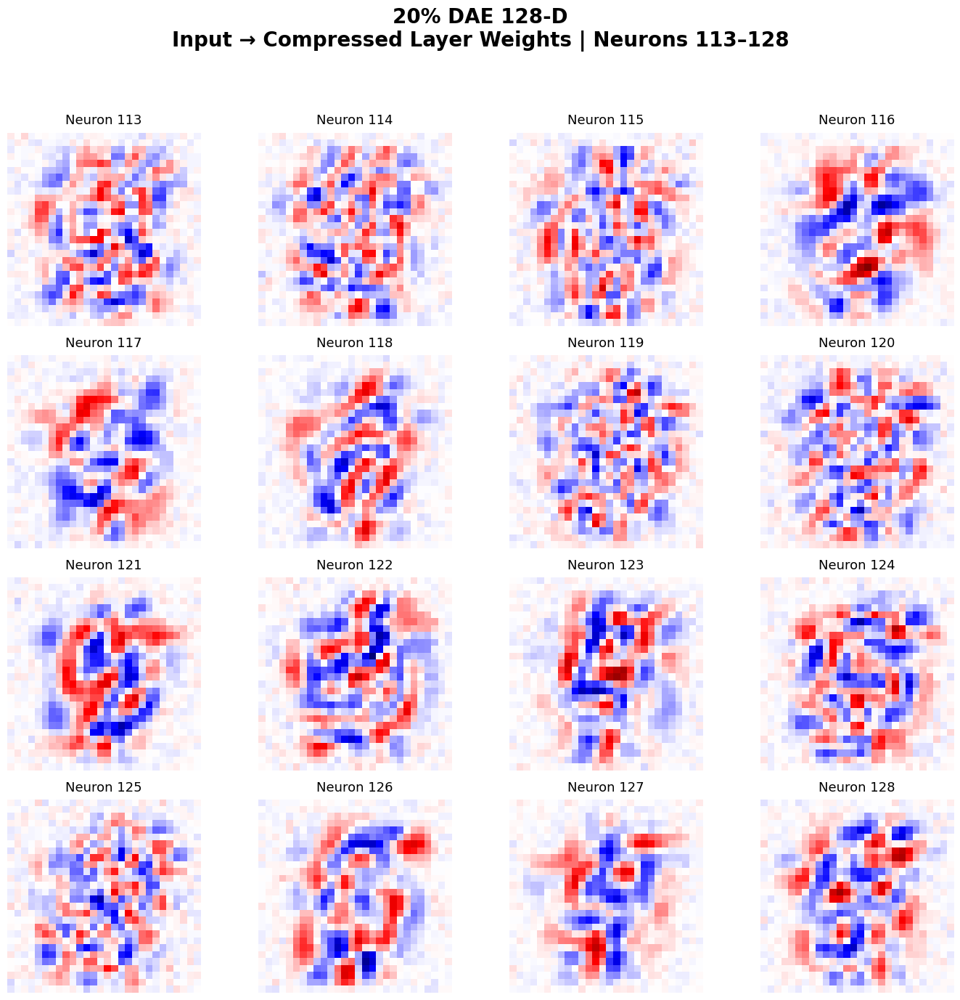

Saved: /content/task6_weight_visualization/figures/detailed/dae_20pct/20%_dae_128-d_neurons_113_128.png


In [ ]:
# ==========================================
# TASK 6(b) — 20% DAE
# ==========================================

DAE20_DETAILED_DIR = os.path.join(
    TASK6_DETAILED_DIR,
    "dae_20pct"
)

os.makedirs(
    DAE20_DETAILED_DIR,
    exist_ok=True
)


plot_weight_pages(
    weights=dae20_weights,
    model_name="20% DAE 128-D",
    output_dir=DAE20_DETAILED_DIR
)

/tmp/ipykernel_1632/2125805302.py:91: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


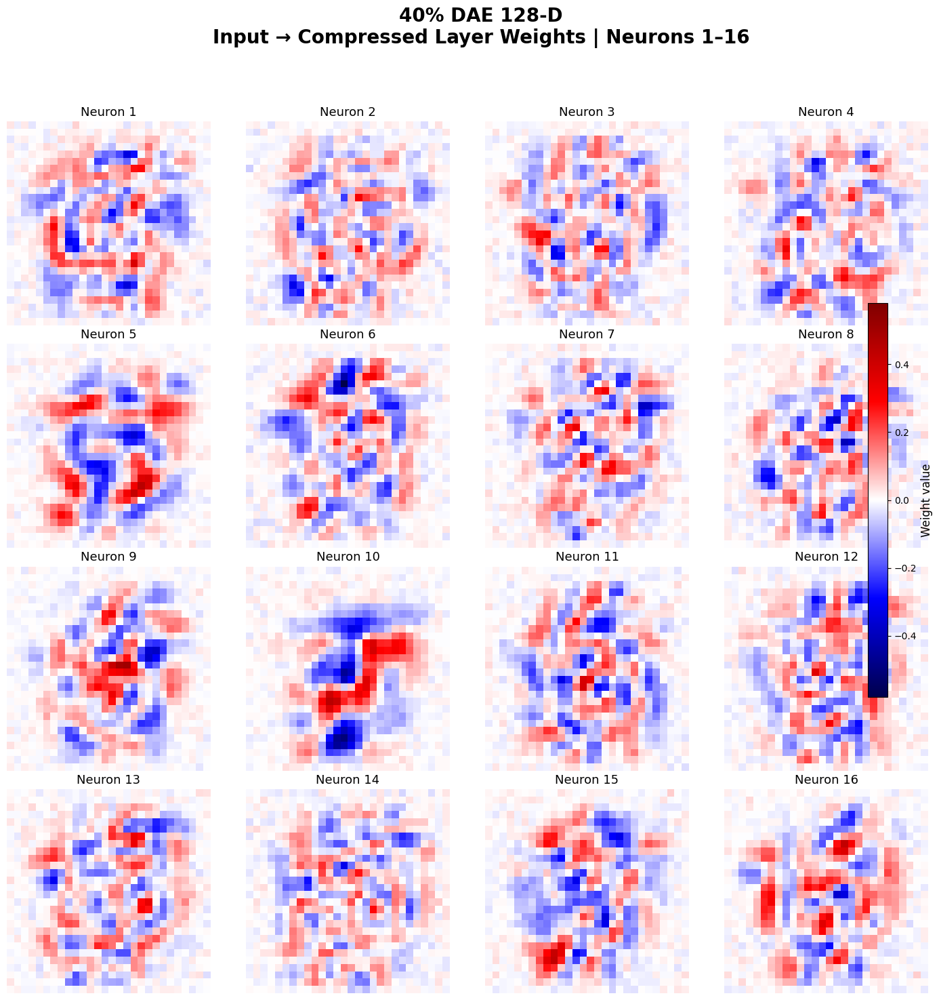

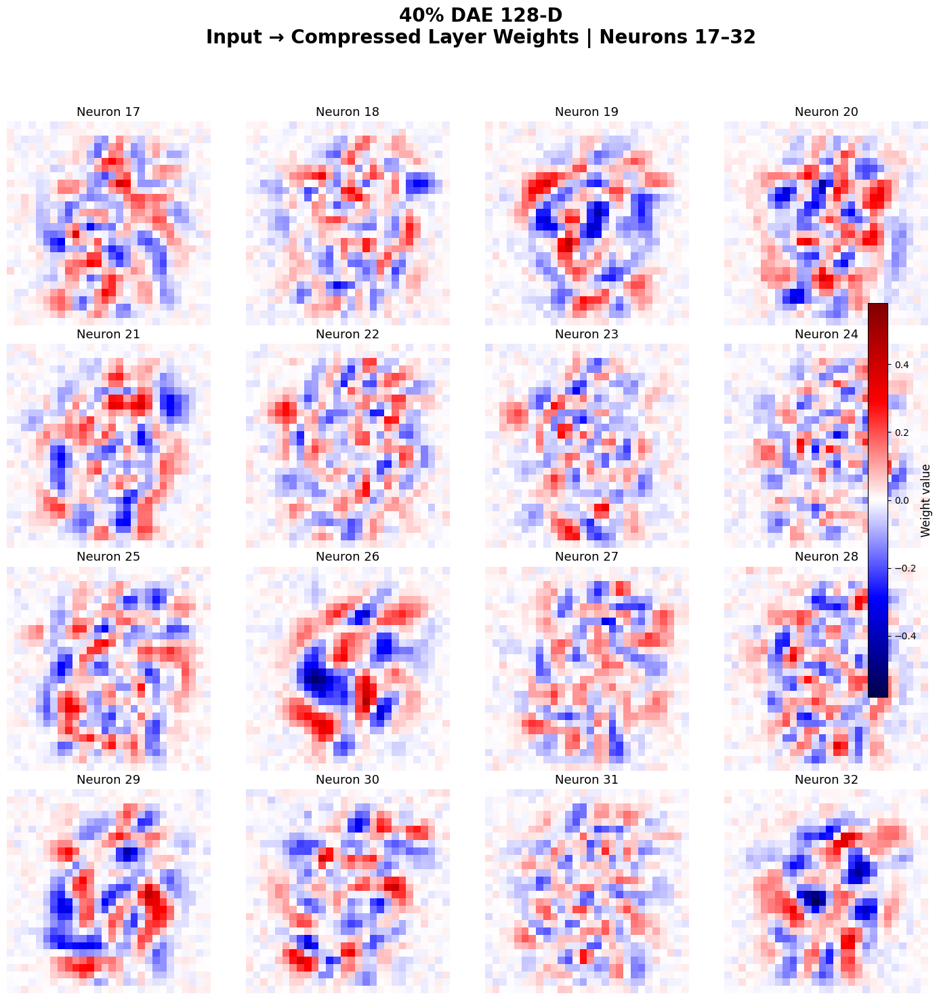

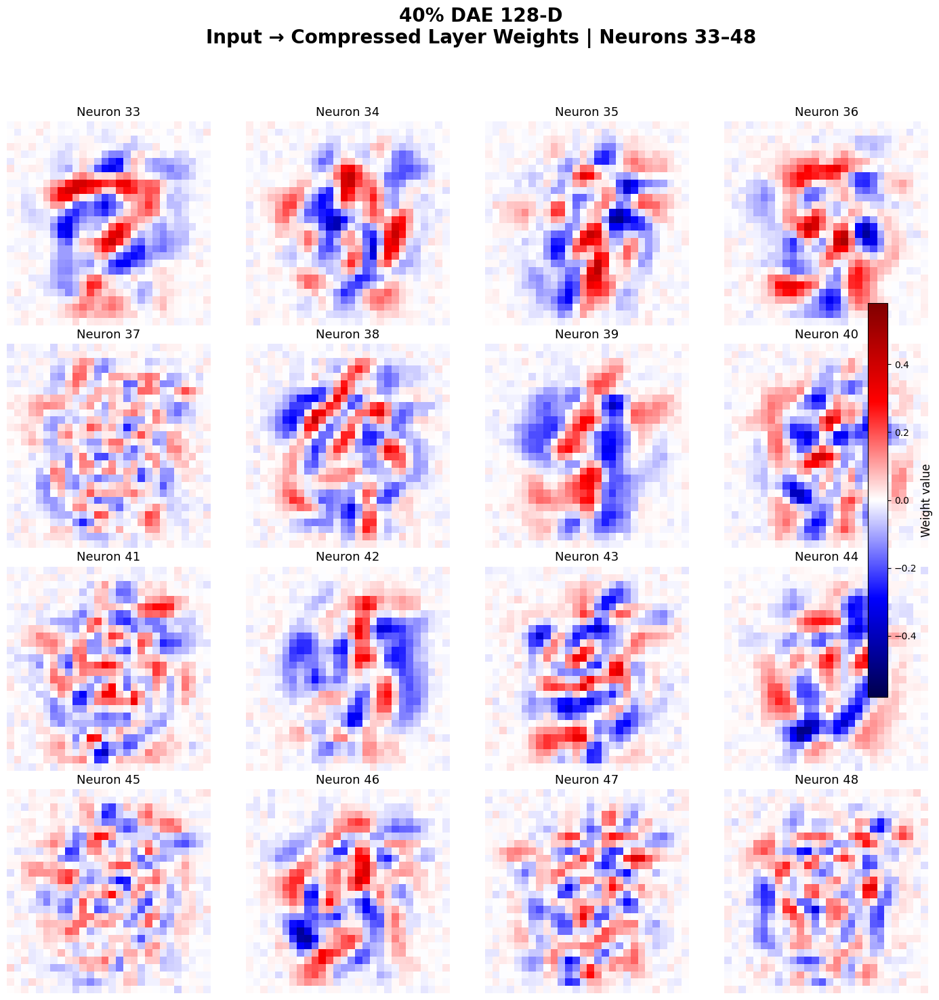

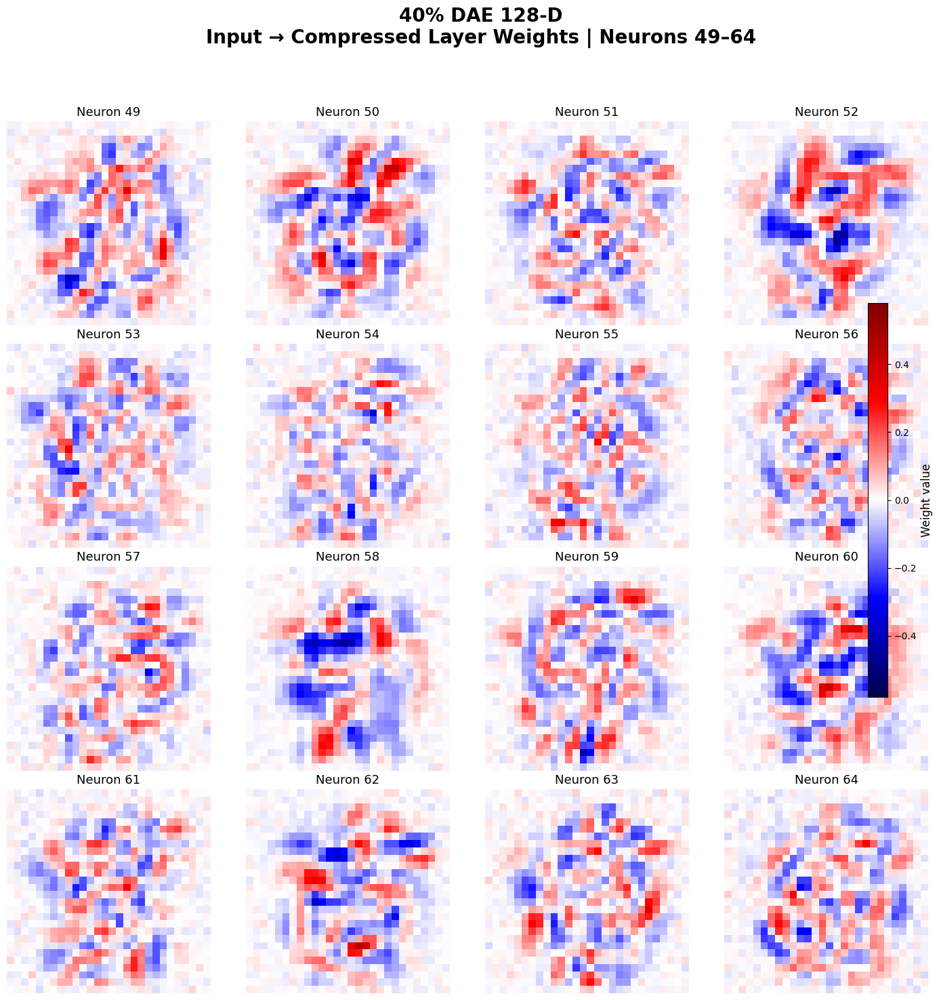

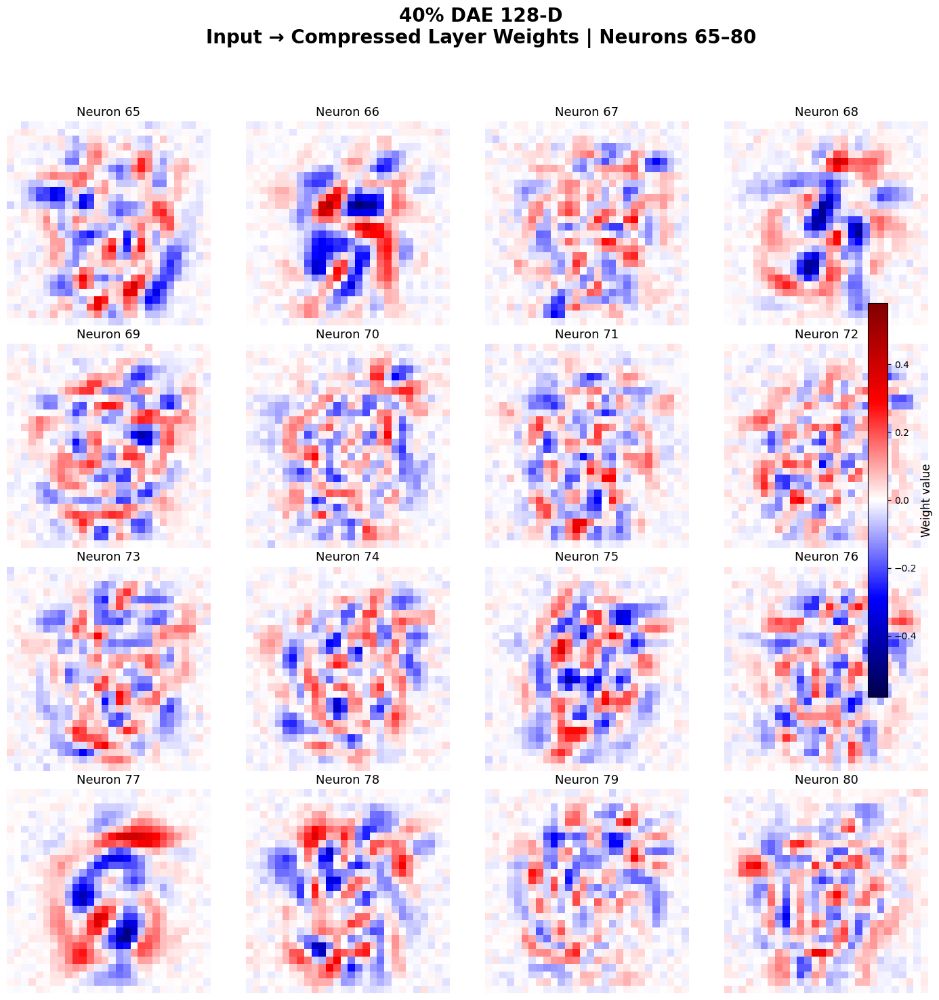

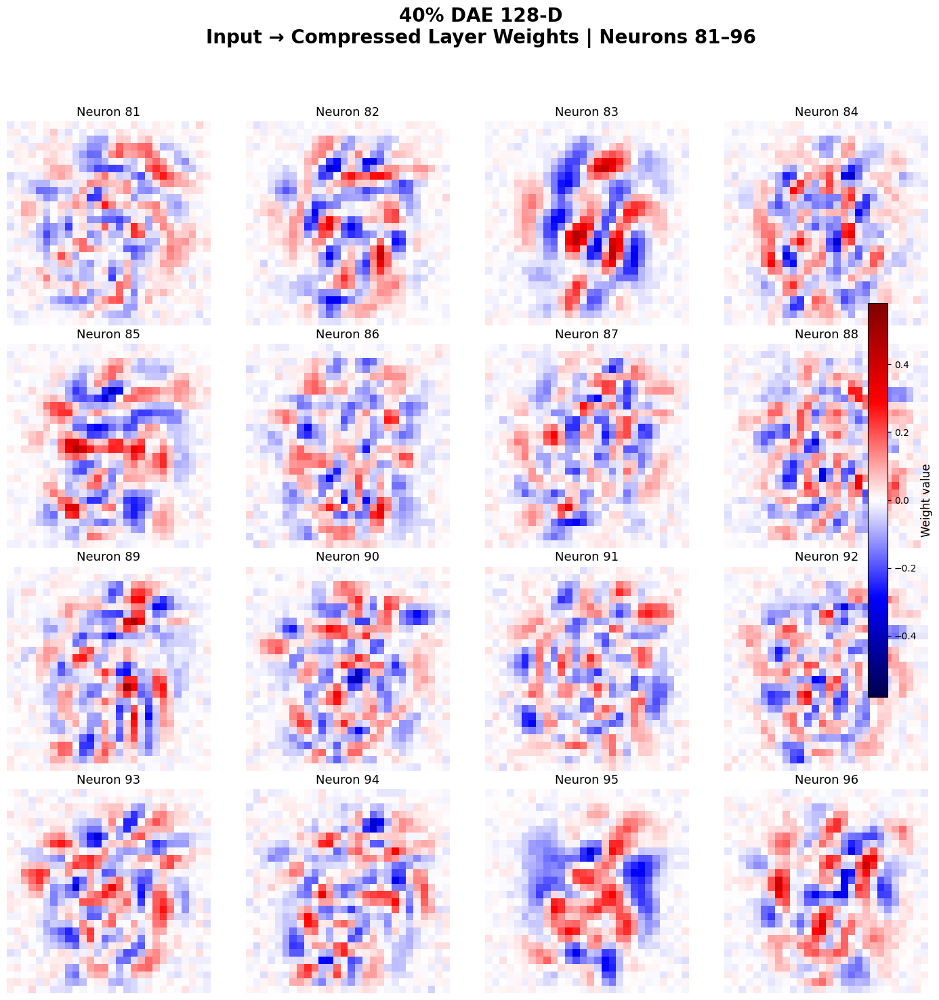

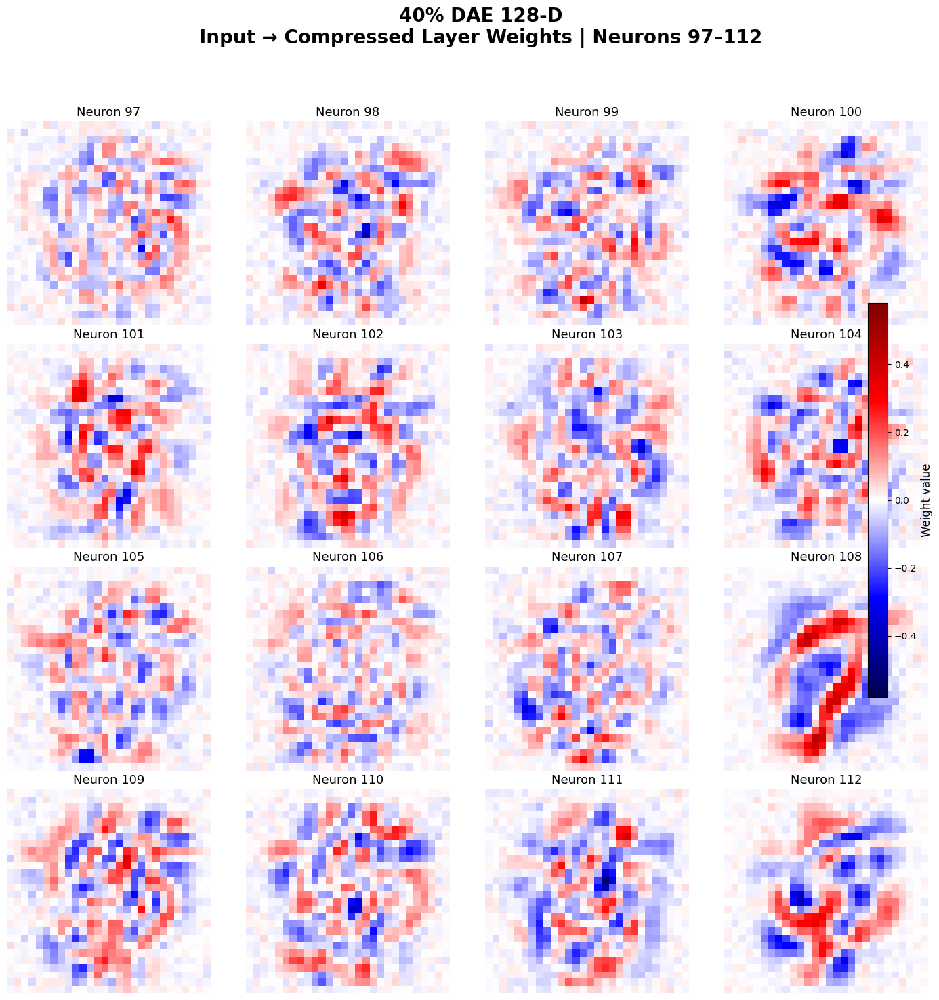

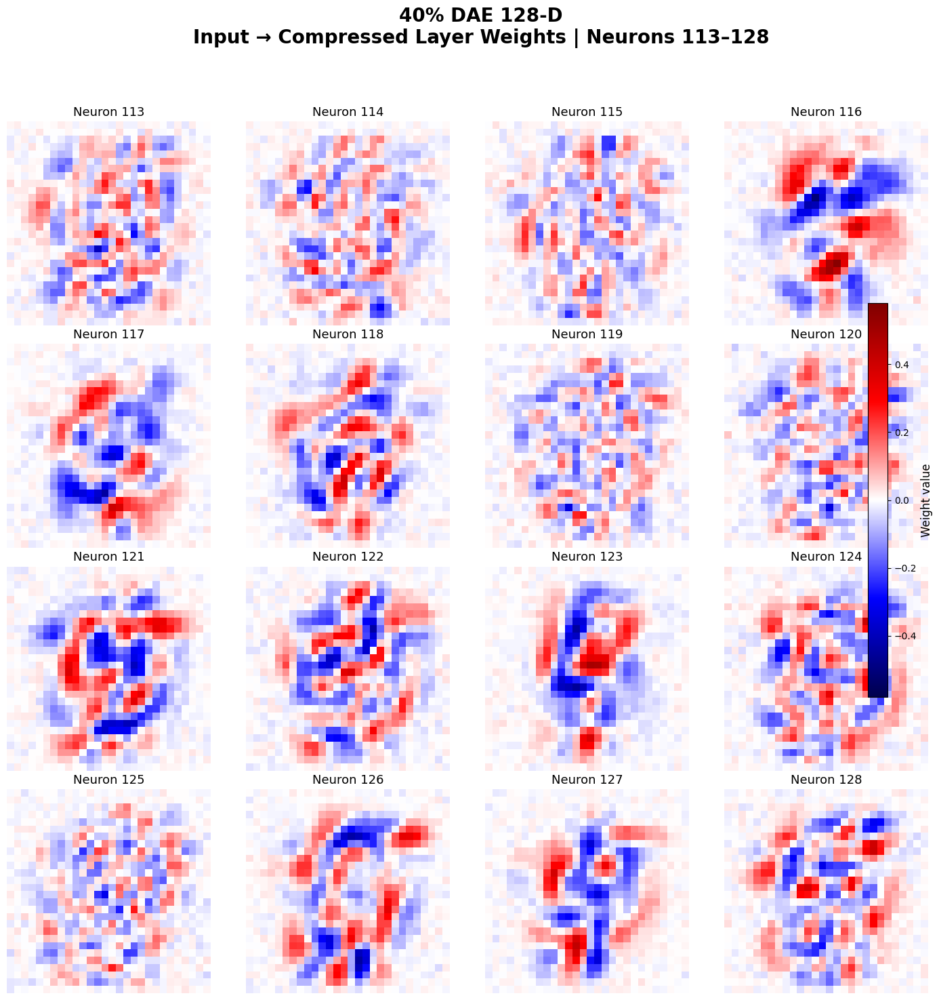

In [ ]:
# ==========================================
# TASK 6(b) — 40% DAE
# ==========================================

DAE40_DETAILED_DIR = os.path.join(
    TASK6_DETAILED_DIR,
    "dae_40pct"
)

os.makedirs(
    DAE40_DETAILED_DIR,
    exist_ok=True
)


plot_weight_pages_with_colorbar(
    weights=dae40_weights,
    model_name="40% DAE 128-D",
    output_dir=DAE40_DETAILED_DIR
)

In [ ]:
# ==========================================
# TASK 6(c)
# COMPARISON SUMMARY
# ==========================================

print("=" * 80)
print("TASK 6 — WEIGHT VISUALIZATION COMPARISON")
print("=" * 80)

print("\nNormal 1-hidden AE:")
print(
    "Shape:",
    tuple(ae128_weights.shape)
)

print(
    "Mean absolute weight:",
    torch.mean(
        torch.abs(ae128_weights)
    ).item()
)

print(
    "Maximum absolute weight:",
    torch.max(
        torch.abs(ae128_weights)
    ).item()
)


print("\n20% Denoising AE:")
print(
    "Shape:",
    tuple(dae20_weights.shape)
)

print(
    "Mean absolute weight:",
    torch.mean(
        torch.abs(dae20_weights)
    ).item()
)

print(
    "Maximum absolute weight:",
    torch.max(
        torch.abs(dae20_weights)
    ).item()
)


print("\n40% Denoising AE:")
print(
    "Shape:",
    tuple(dae40_weights.shape)
)

print(
    "Mean absolute weight:",
    torch.mean(
        torch.abs(dae40_weights)
    ).item()
)

print(
    "Maximum absolute weight:",
    torch.max(
        torch.abs(dae40_weights)
    ).item()
)

TASK 6 — WEIGHT VISUALIZATION COMPARISON

Normal 1-hidden AE:
Shape: (128, 784)
Mean absolute weight: 0.17473076283931732
Maximum absolute weight: 1.7138512134552002

20% Denoising AE:
Shape: (128, 784)
Mean absolute weight: 0.06451509147882462
Maximum absolute weight: 0.5542120933532715

40% Denoising AE:
Shape: (128, 784)
Mean absolute weight: 0.05920303240418434
Maximum absolute weight: 0.5801858305931091


In [ ]:
# ==========================================
# TASK 6 — SAVE WEIGHT MATRICES
# ==========================================

TASK6_WEIGHT_DIR = os.path.join(
    TASK6_DIR,
    "weights"
)

os.makedirs(
    TASK6_WEIGHT_DIR,
    exist_ok=True
)


np.save(
    os.path.join(
        TASK6_WEIGHT_DIR,
        "1hidden_ae_128_weights.npy"
    ),
    ae128_weights.numpy()
)

np.save(
    os.path.join(
        TASK6_WEIGHT_DIR,
        "dae_20pct_128_weights.npy"
    ),
    dae20_weights.numpy()
)

np.save(
    os.path.join(
        TASK6_WEIGHT_DIR,
        "dae_40pct_128_weights.npy"
    ),
    dae40_weights.numpy()
)

print(
    "All Task 6 weight matrices saved."
)

All Task 6 weight matrices saved.


In [ ]:
# ==========================================
# TASK 6 — FINAL VERIFICATION
# ==========================================

print("=" * 80)
print("TASK 6 — FINAL VERIFICATION")
print("=" * 80)

print("\nWeight matrices:")

print(
    "1-hidden AE :",
    tuple(ae128_weights.shape)
)

print(
    "20% DAE     :",
    tuple(dae20_weights.shape)
)

print(
    "40% DAE     :",
    tuple(dae40_weights.shape)
)


print("\nFigures:")

for filename in sorted(
    os.listdir(TASK6_FIG_DIR)
):

    print(
        " ",
        filename
    )


print("\nTask 6 output directory:")
print(TASK6_DIR)

print("\n" + "=" * 80)
print("TASK 6 COMPLETE")
print("=" * 80)

TASK 6 — FINAL VERIFICATION

Weight matrices:
1-hidden AE : (128, 784)
20% DAE     : (128, 784)
40% DAE     : (128, 784)

Figures:
  detailed
  task6_1hidden_ae_128_weights.png

Task 6 output directory:
/content/task6_weight_visualization

TASK 6 COMPLETE


In [ ]:
# ============================================================
# TASK 6 — LOAD SAVED WEIGHT MATRICES
# ============================================================

import numpy as np
import os

TASK6_WEIGHT_DIR = "/content"

ae128_weights = np.load(
    os.path.join(
        TASK6_WEIGHT_DIR,
        "1hidden_ae_128_weights.npy"
    )
)

dae20_weights = np.load(
    os.path.join(
        TASK6_WEIGHT_DIR,
        "dae_20pct_128_weights.npy"
    )
)

dae40_weights = np.load(
    os.path.join(
        TASK6_WEIGHT_DIR,
        "dae_40pct_128_weights.npy"
    )
)

print("Normal AE :", ae128_weights.shape)
print("20% DAE   :", dae20_weights.shape)
print("40% DAE   :", dae40_weights.shape)

Normal AE : (128, 784)
20% DAE   : (128, 784)
40% DAE   : (128, 784)


In [ ]:
# ============================================================
# TASK 6 — CLEAR WEIGHT VISUALIZATION
# 4 × 4 layout, 16 neurons per figure
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt
import torch

# ------------------------------------------------------------
# Output directories
# ------------------------------------------------------------

TASK6_FIG_DIR = "/content/task6_weight_visualization_NEW/figures/detailed"

MODEL_DIRS = {
    "normal_ae": os.path.join(TASK6_FIG_DIR, "normal_ae"),
    "dae_20pct": os.path.join(TASK6_FIG_DIR, "dae_20pct"),
    "dae_40pct": os.path.join(TASK6_FIG_DIR, "dae_40pct"),
}

for path in MODEL_DIRS.values():
    os.makedirs(path, exist_ok=True)


# ------------------------------------------------------------
# Plot one page of 16 neurons
# ------------------------------------------------------------

def plot_weight_page(
    weights,
    start_neuron,
    model_title,
    save_path
):
    """
    weights:
        Tensor/array of shape (128, 784)

    start_neuron:
        Zero-based index of first neuron on this page.

    Produces:
        4 × 4 grid containing 16 input-to-bottleneck
        weight maps, each reshaped to 28 × 28.
    """

    weights = np.asarray(weights)

    end_neuron = min(start_neuron + 16, weights.shape[0])

    # --------------------------------------------------------
    # Robust symmetric scale
    # --------------------------------------------------------
    #
    # Instead of a fixed +/-1.5 range, determine the scale
    # from the actual learned weights.
    #
    # 99th percentile prevents a few extreme weights from
    # washing out the rest of the visualization.
    # --------------------------------------------------------

    abs_weights = np.abs(weights[start_neuron:end_neuron])

    vmax = np.percentile(abs_weights, 99)

    if vmax == 0:
        vmax = np.max(abs_weights)

    if vmax == 0:
        vmax = 1.0

    # --------------------------------------------------------
    # Figure
    # --------------------------------------------------------

    fig, axes = plt.subplots(
        4,
        4,
        figsize=(12, 12),
        constrained_layout=True
    )

    axes = axes.flatten()

    # --------------------------------------------------------
    # Plot each neuron
    # --------------------------------------------------------

    for local_idx, neuron_idx in enumerate(
        range(start_neuron, end_neuron)
    ):

        ax = axes[local_idx]

        neuron_weights = weights[neuron_idx]

        # 784 -> 28 × 28
        weight_image = neuron_weights.reshape(28, 28)

        im = ax.imshow(
            weight_image,
            cmap="seismic",
            vmin=-vmax,
            vmax=vmax,
            interpolation="bilinear"
        )

        ax.set_title(
            f"Neuron {neuron_idx + 1}",
            fontsize=12,
            fontweight="bold",
            pad=6
        )

        ax.set_xticks([])
        ax.set_yticks([])

        # Clean border
        for spine in ax.spines.values():
            spine.set_visible(False)

    # --------------------------------------------------------
    # Hide unused axes
    # --------------------------------------------------------

    for idx in range(end_neuron - start_neuron, 16):
        axes[idx].axis("off")

    # --------------------------------------------------------
    # Main title
    # --------------------------------------------------------

    fig.suptitle(
        f"{model_title}\n"
        f"Input → Compressed Layer Weights | "
        f"Neurons {start_neuron + 1}–{end_neuron}",
        fontsize=18,
        fontweight="bold"
    )

    # --------------------------------------------------------
    # Shared colorbar
    # --------------------------------------------------------

    cbar = fig.colorbar(
        im,
        ax=axes.tolist(),
        shrink=0.72,
        pad=0.015
    )

    cbar.set_label(
        "Weight value",
        fontsize=11
    )

    # --------------------------------------------------------
    # Save high-quality figure
    # --------------------------------------------------------

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()
    plt.close(fig)


# ============================================================
# Generate 8 figures for each model
# ============================================================

def generate_all_weight_figures(
    weights,
    model_title,
    output_dir
):

    weights = np.asarray(weights)

    assert weights.shape == (128, 784), \
        f"Expected (128, 784), got {weights.shape}"

    for start_neuron in range(0, 128, 16):

        end_neuron = start_neuron + 16

        filename = (
            f"neurons_{start_neuron + 1:03d}"
            f"_{end_neuron:03d}.png"
        )

        save_path = os.path.join(
            output_dir,
            filename
        )

        plot_weight_page(
            weights=weights,
            start_neuron=start_neuron,
            model_title=model_title,
            save_path=save_path
        )


# ============================================================
# Generate figures
# ============================================================

generate_all_weight_figures(
    ae128_weights,
    "1-Hidden AE 128-D",
    MODEL_DIRS["normal_ae"]
)

generate_all_weight_figures(
    dae20_weights,
    "20% Denoising AE 128-D",
    MODEL_DIRS["dae_20pct"]
)

generate_all_weight_figures(
    dae40_weights,
    "40% Denoising AE 128-D",
    MODEL_DIRS["dae_40pct"]
)

print("\nTask 6 weight visualizations generated successfully.")
print("Each model: 8 figures × 16 neurons = 128 neurons.")

In [ ]:
!zip -r task6_weight_visualization_NEW.zip /content/task6_weight_visualization_NEW

  adding: content/task6_weight_visualization_NEW/ (stored 0%)
  adding: content/task6_weight_visualization_NEW/figures/ (stored 0%)
  adding: content/task6_weight_visualization_NEW/figures/detailed/ (stored 0%)
  adding: content/task6_weight_visualization_NEW/figures/detailed/dae_40pct/ (stored 0%)
  adding: content/task6_weight_visualization_NEW/figures/detailed/dae_40pct/neurons_001_016.png (deflated 1%)
  adding: content/task6_weight_visualization_NEW/figures/detailed/dae_40pct/neurons_081_096.png (deflated 1%)
  adding: content/task6_weight_visualization_NEW/figures/detailed/dae_40pct/neurons_097_112.png (deflated 1%)
  adding: content/task6_weight_visualization_NEW/figures/detailed/dae_40pct/neurons_033_048.png (deflated 1%)
  adding: content/task6_weight_visualization_NEW/figures/detailed/dae_40pct/neurons_017_032.png (deflated 1%)
  adding: content/task6_weight_visualization_NEW/figures/detailed/dae_40pct/neurons_113_128.png (deflated 1%)
  adding: content/task6_weight_visualiza

In [ ]:
!zip -r task6_weight_visualization.zip /content/task6_weight_visualization

  adding: content/task6_weight_visualization/ (stored 0%)
  adding: content/task6_weight_visualization/figures/ (stored 0%)
  adding: content/task6_weight_visualization/figures/task6_1hidden_ae_128_weights.png (deflated 15%)
  adding: content/task6_weight_visualization/figures/detailed/ (stored 0%)
  adding: content/task6_weight_visualization/figures/detailed/dae_40pct/ (stored 0%)
  adding: content/task6_weight_visualization/figures/detailed/dae_40pct/neurons_065_080_colorbar.png (deflated 34%)
  adding: content/task6_weight_visualization/figures/detailed/dae_40pct/neurons_049_064_colorbar.png (deflated 34%)
  adding: content/task6_weight_visualization/figures/detailed/dae_40pct/neurons_081_096_colorbar.png (deflated 34%)
  adding: content/task6_weight_visualization/figures/detailed/dae_40pct/neurons_097_112_colorbar.png (deflated 34%)
  adding: content/task6_weight_visualization/figures/detailed/dae_40pct/neurons_033_048_colorbar.png (deflated 34%)
  adding: content/task6_weight_visu

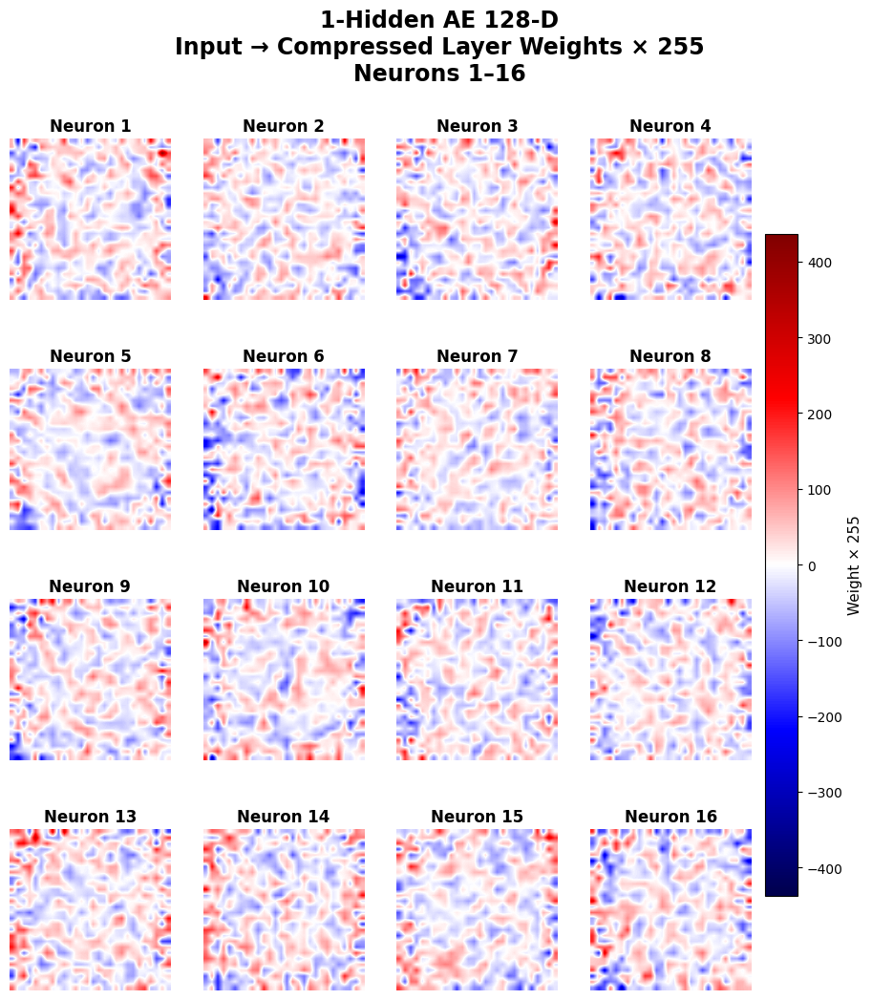

Saved: /content/task6_weight_visualization_0255/figures/normal_ae/neurons_001_016.png


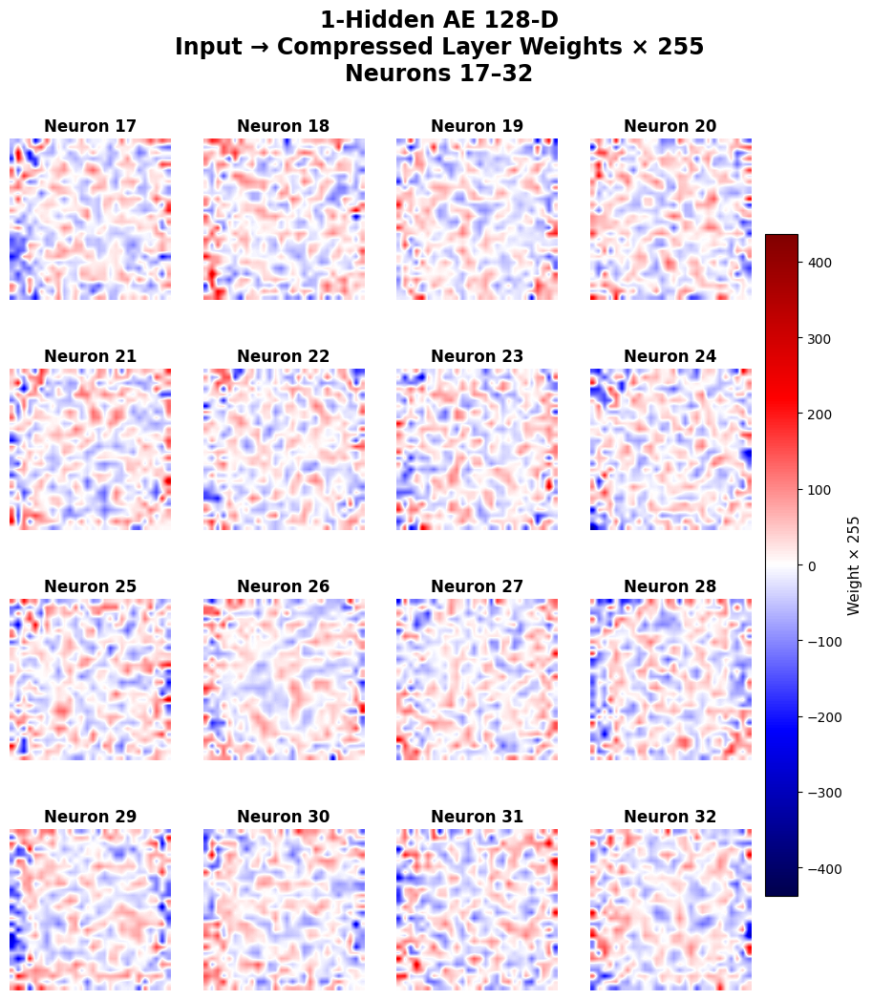

Saved: /content/task6_weight_visualization_0255/figures/normal_ae/neurons_017_032.png


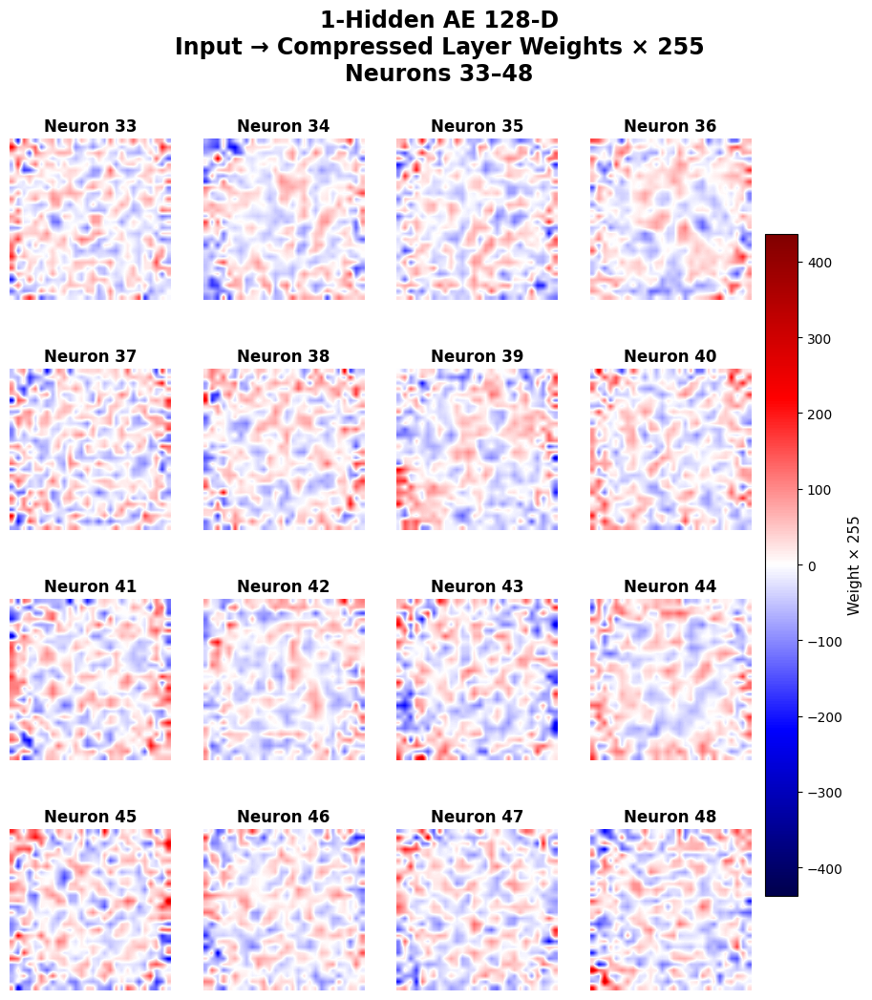

Saved: /content/task6_weight_visualization_0255/figures/normal_ae/neurons_033_048.png


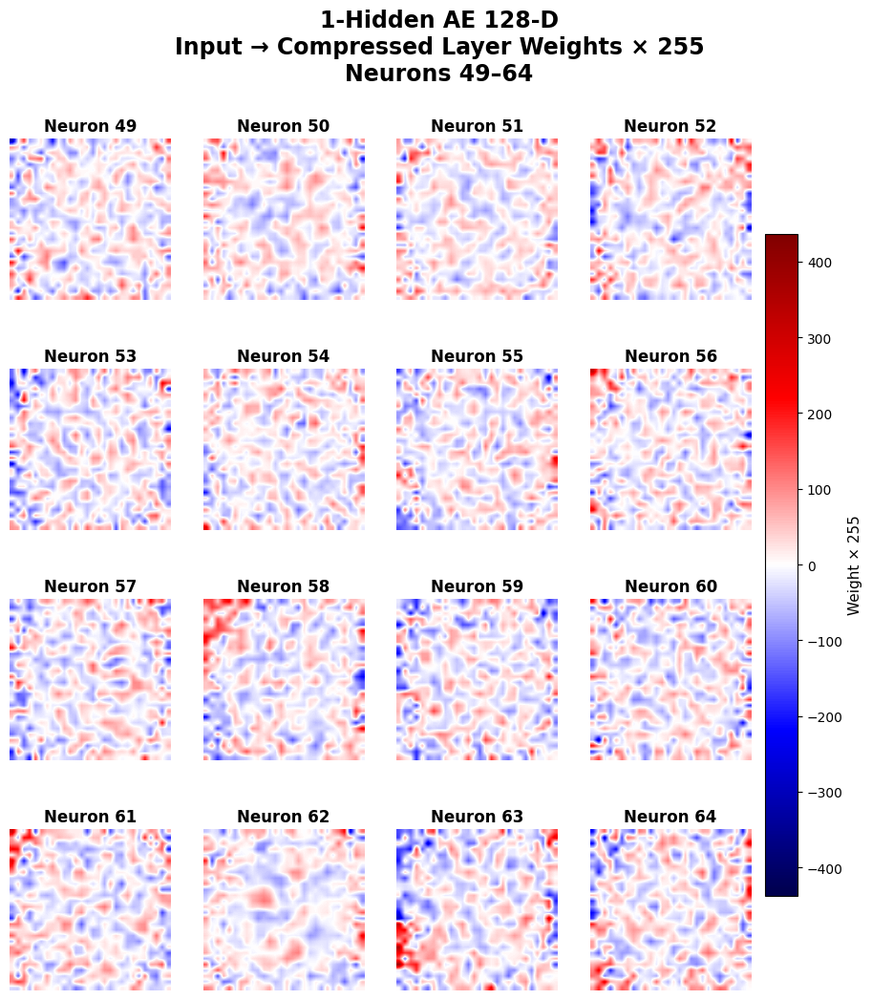

Saved: /content/task6_weight_visualization_0255/figures/normal_ae/neurons_049_064.png


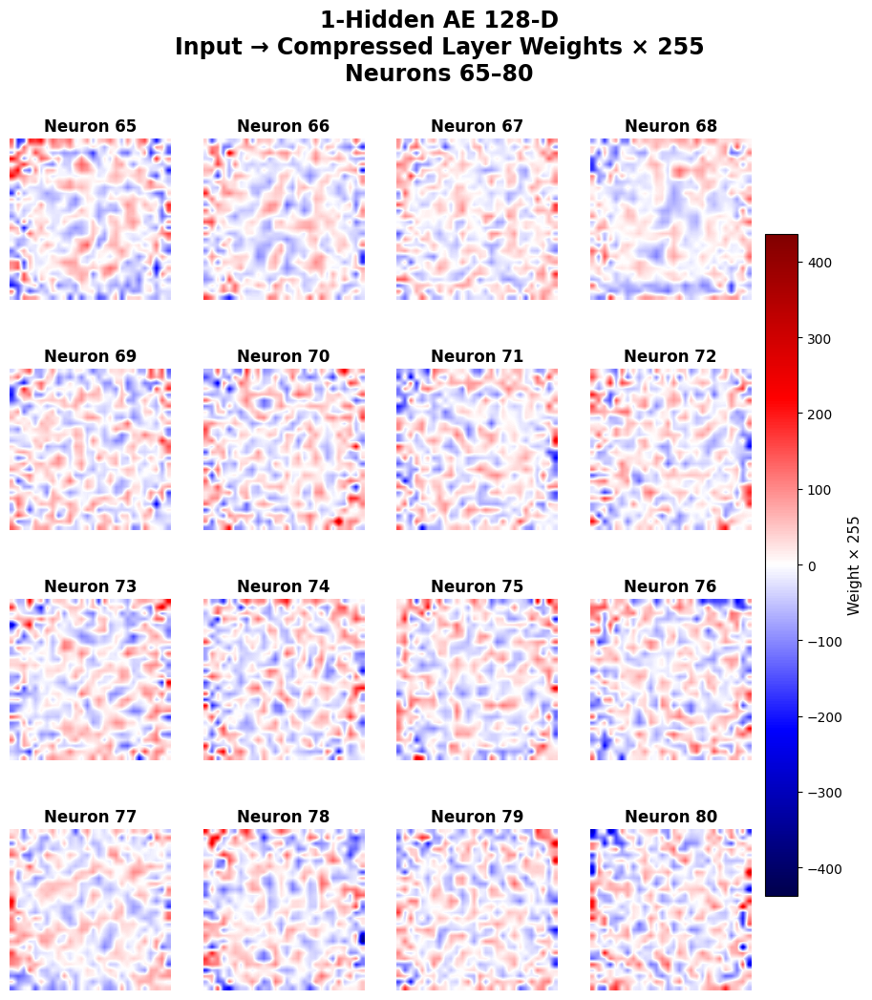

Saved: /content/task6_weight_visualization_0255/figures/normal_ae/neurons_065_080.png


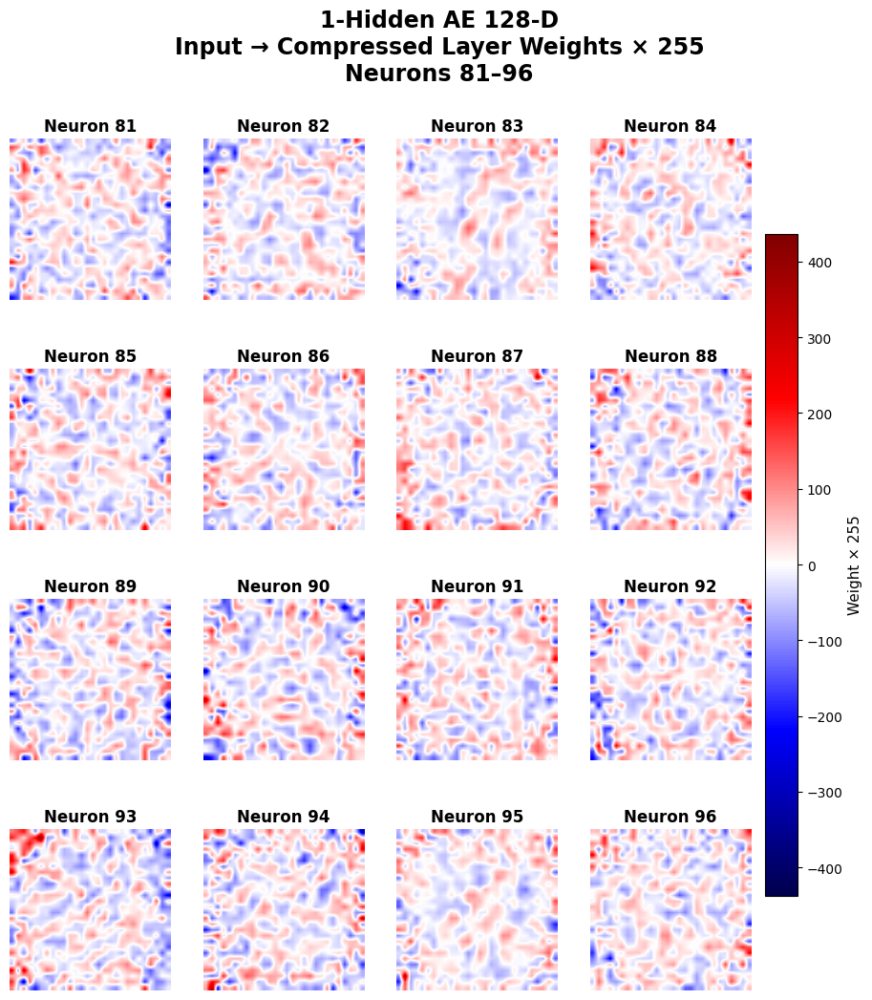

Saved: /content/task6_weight_visualization_0255/figures/normal_ae/neurons_081_096.png


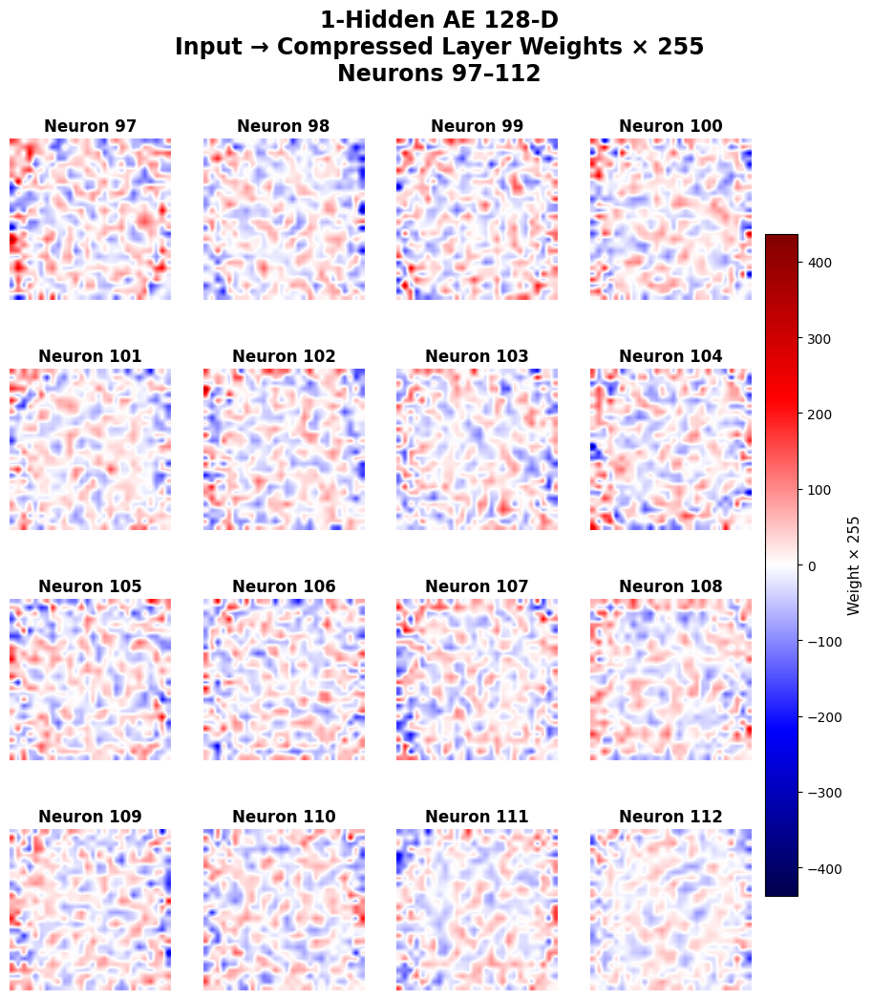

Saved: /content/task6_weight_visualization_0255/figures/normal_ae/neurons_097_112.png


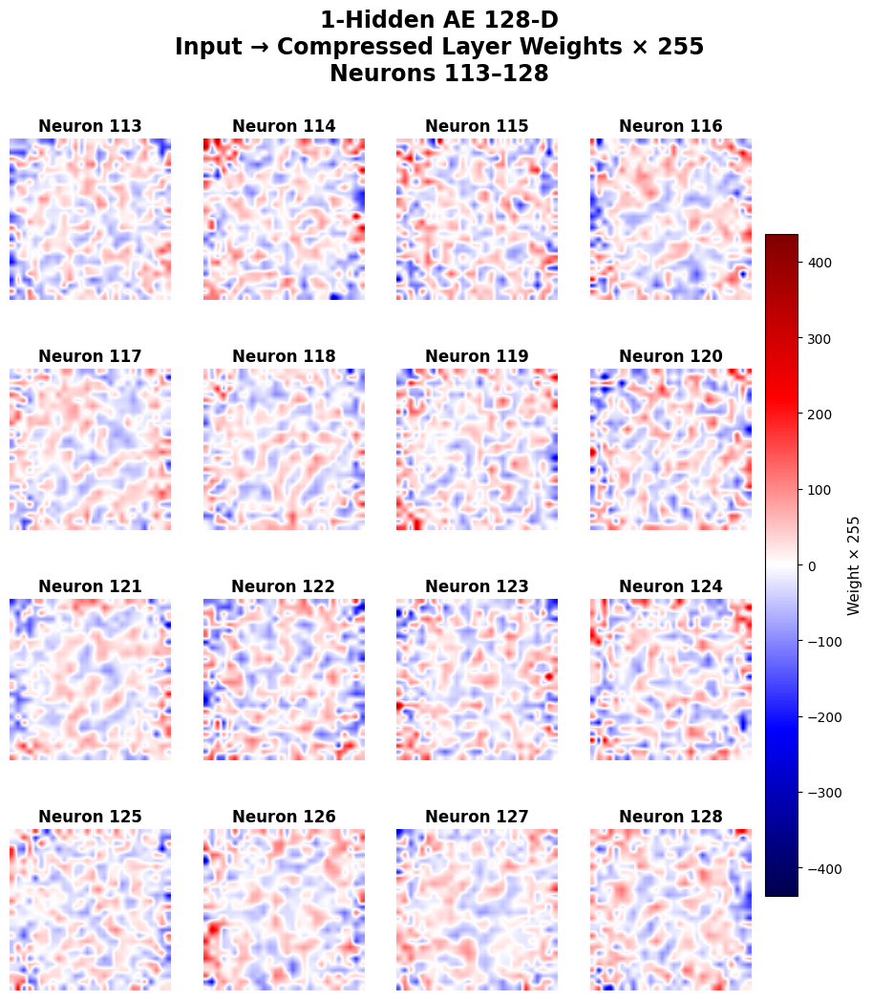

Saved: /content/task6_weight_visualization_0255/figures/normal_ae/neurons_113_128.png


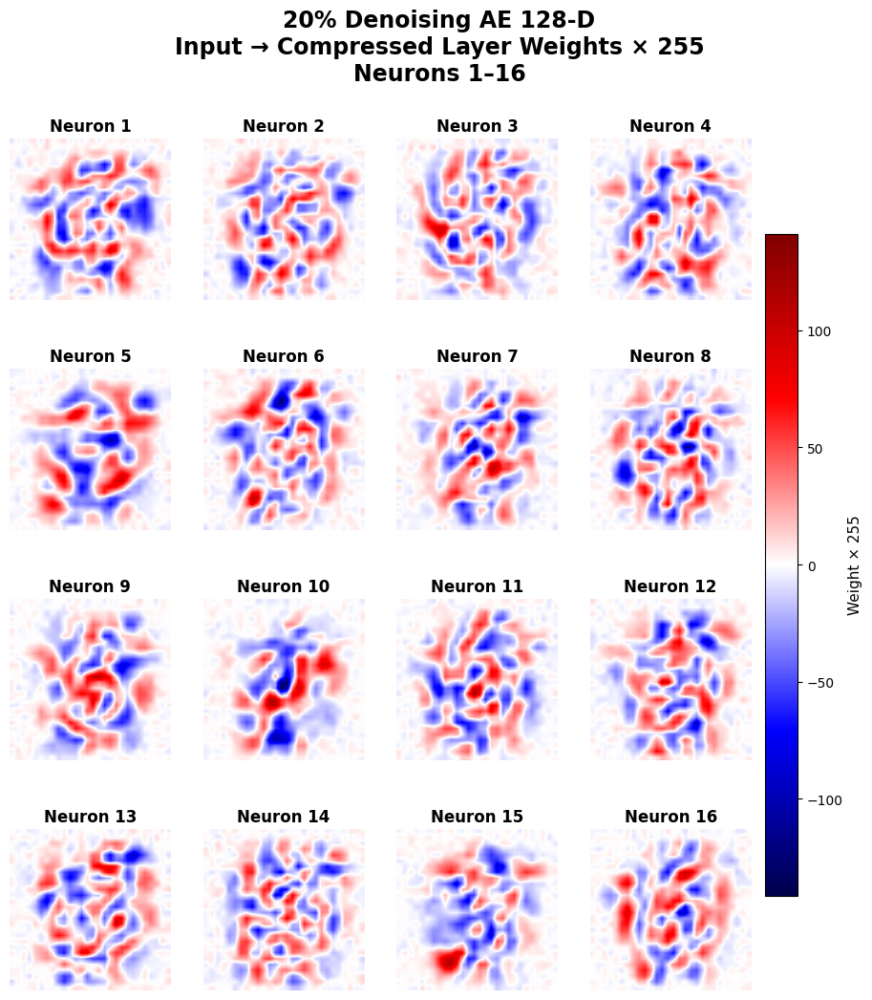

Saved: /content/task6_weight_visualization_0255/figures/dae_20pct/neurons_001_016.png


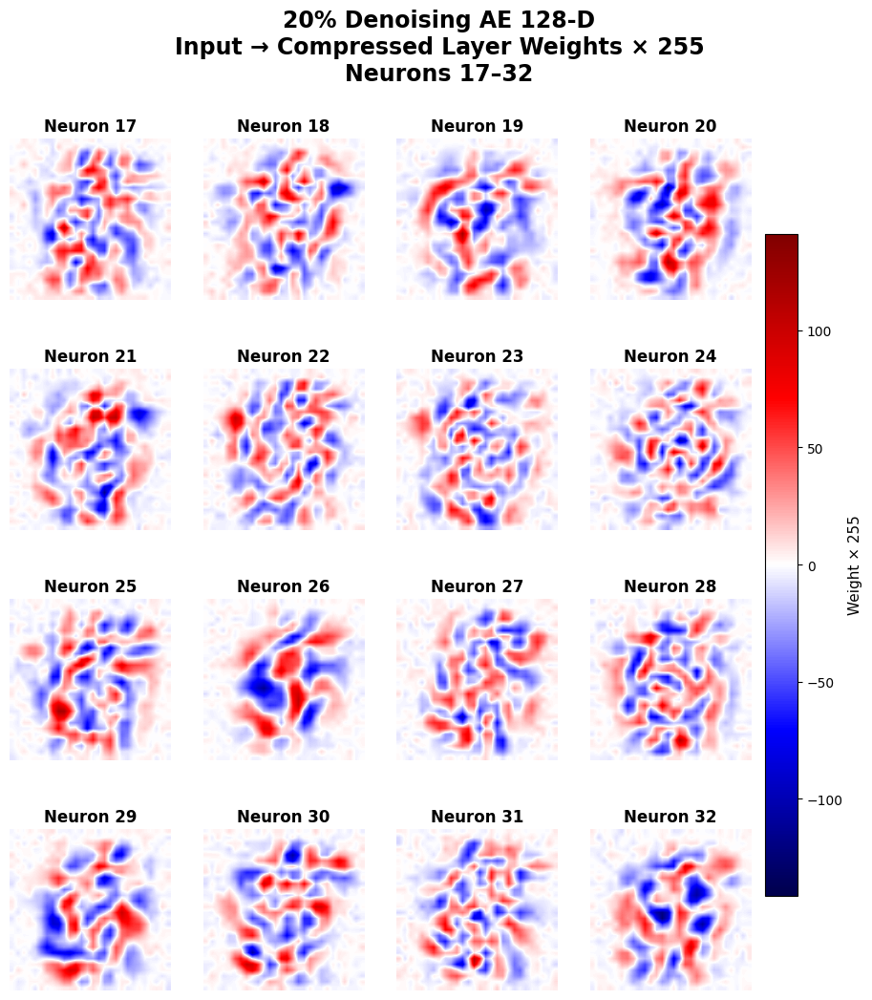

Saved: /content/task6_weight_visualization_0255/figures/dae_20pct/neurons_017_032.png


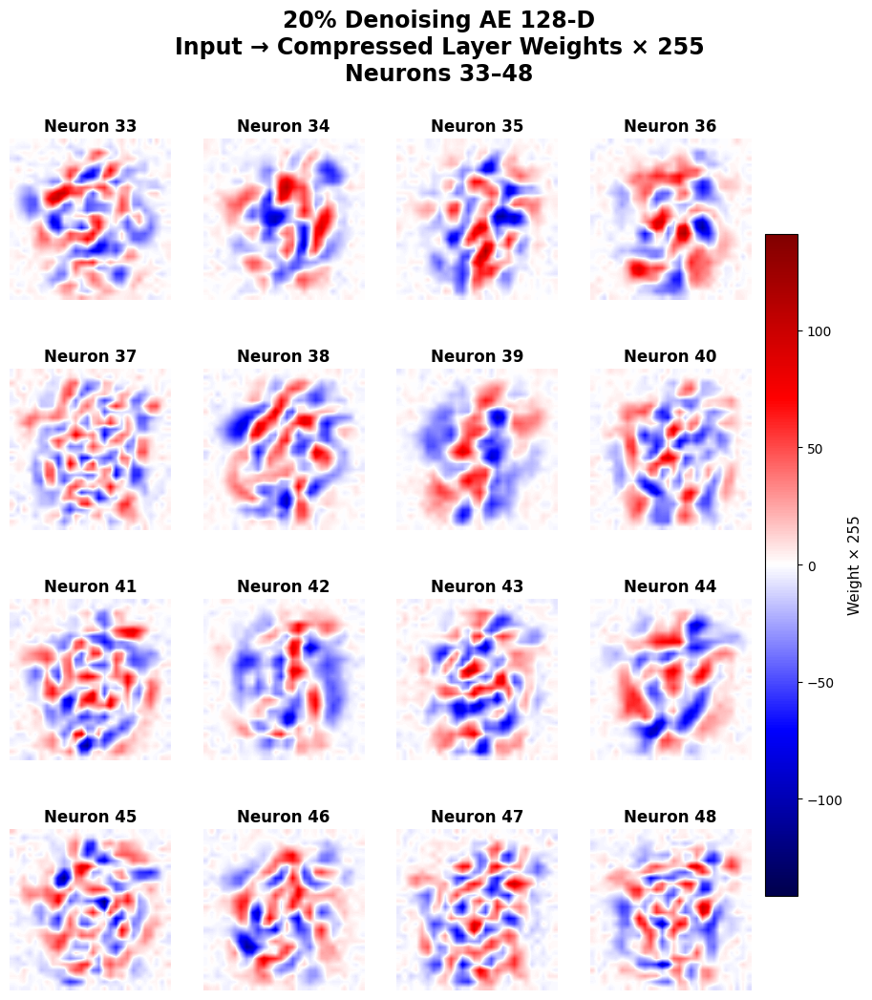

Saved: /content/task6_weight_visualization_0255/figures/dae_20pct/neurons_033_048.png


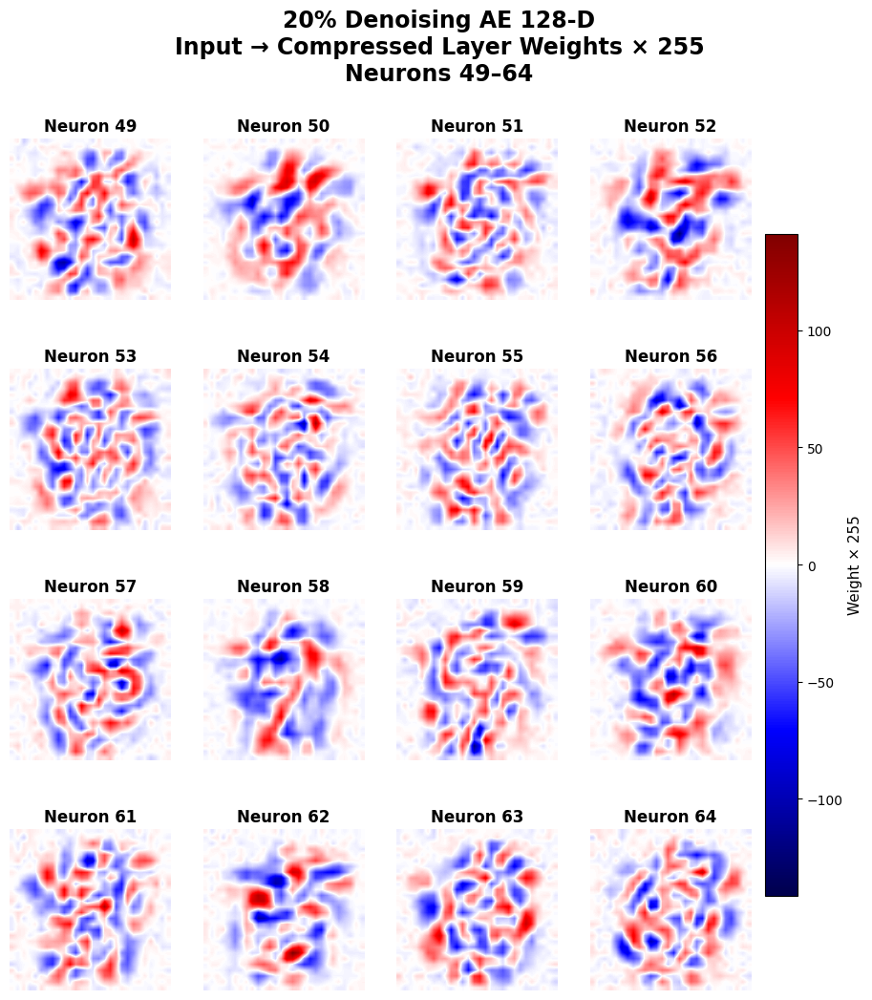

Saved: /content/task6_weight_visualization_0255/figures/dae_20pct/neurons_049_064.png


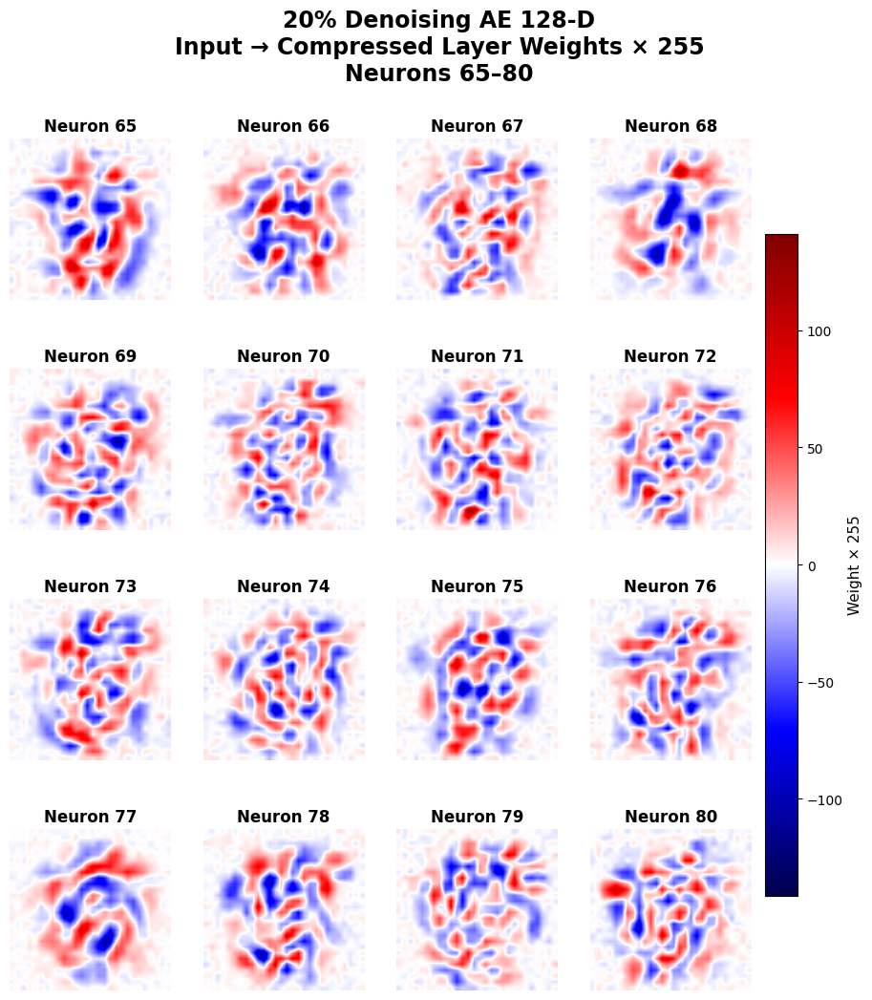

Saved: /content/task6_weight_visualization_0255/figures/dae_20pct/neurons_065_080.png


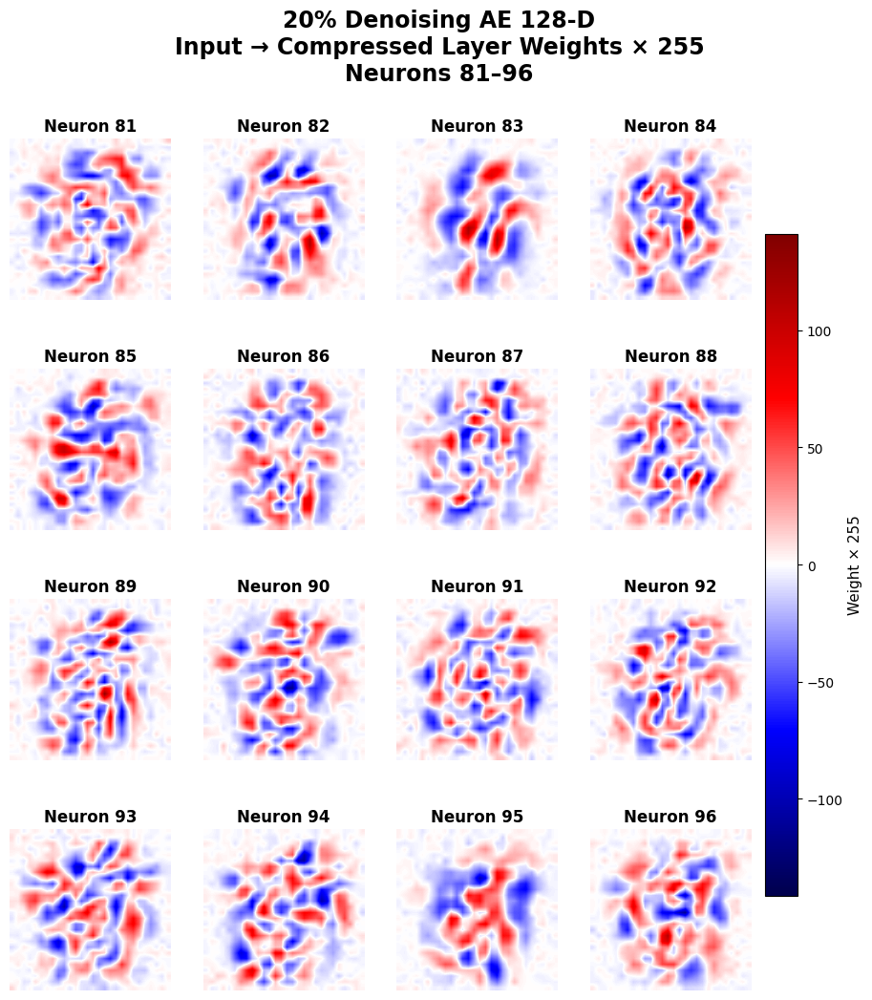

Saved: /content/task6_weight_visualization_0255/figures/dae_20pct/neurons_081_096.png


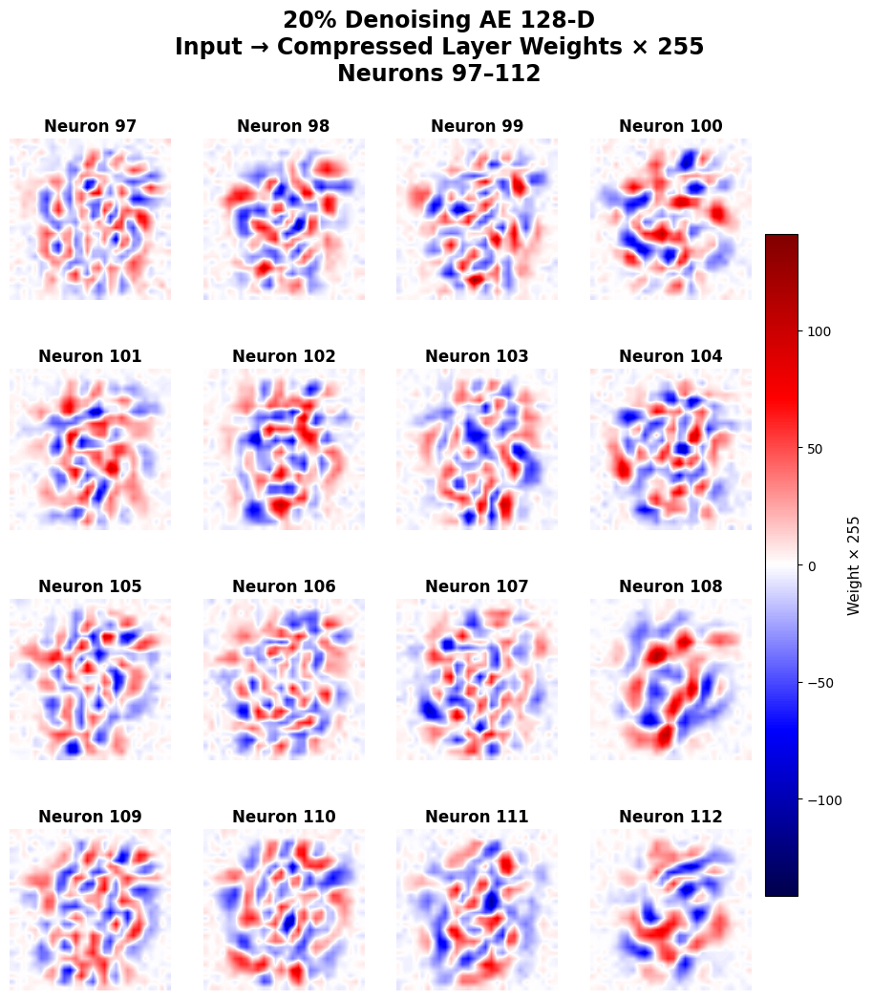

Saved: /content/task6_weight_visualization_0255/figures/dae_20pct/neurons_097_112.png


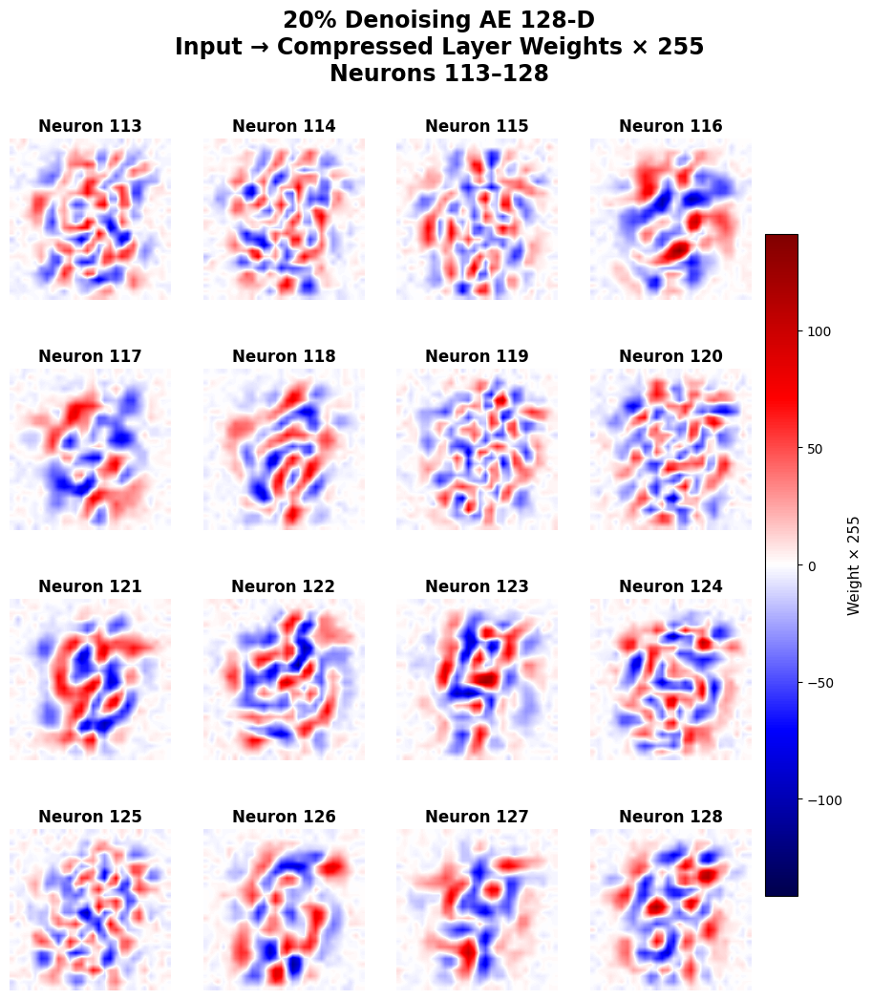

Saved: /content/task6_weight_visualization_0255/figures/dae_20pct/neurons_113_128.png


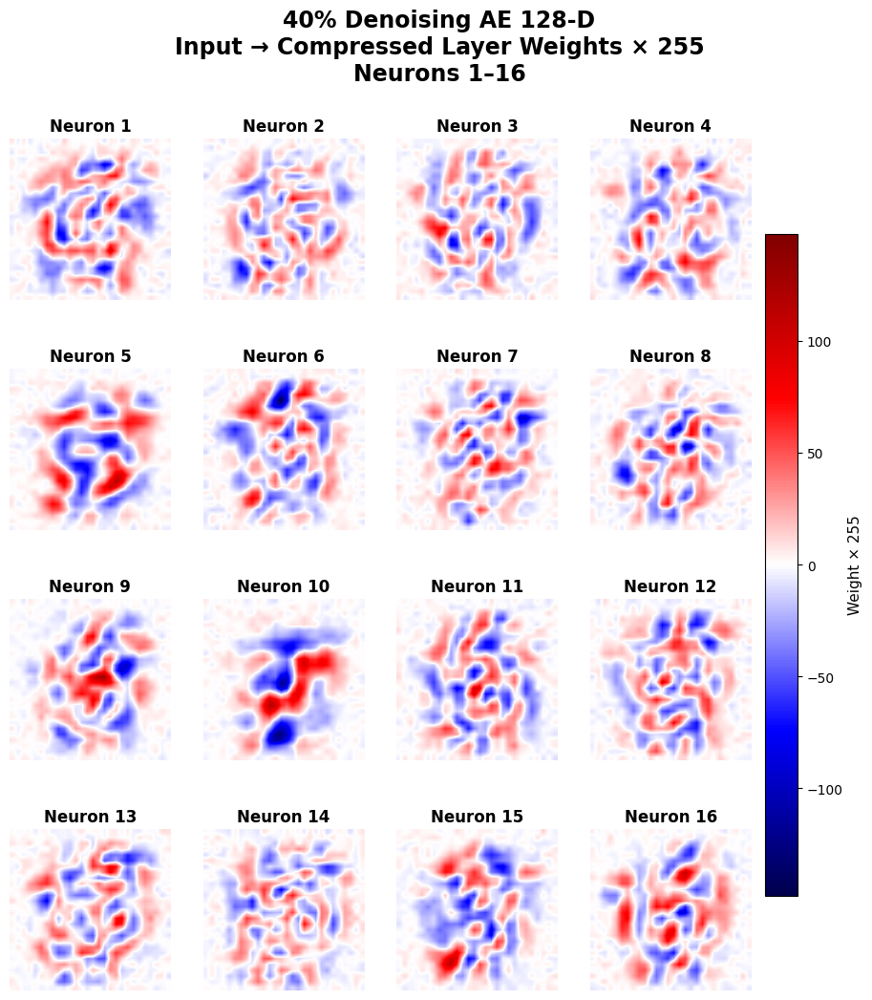

Saved: /content/task6_weight_visualization_0255/figures/dae_40pct/neurons_001_016.png


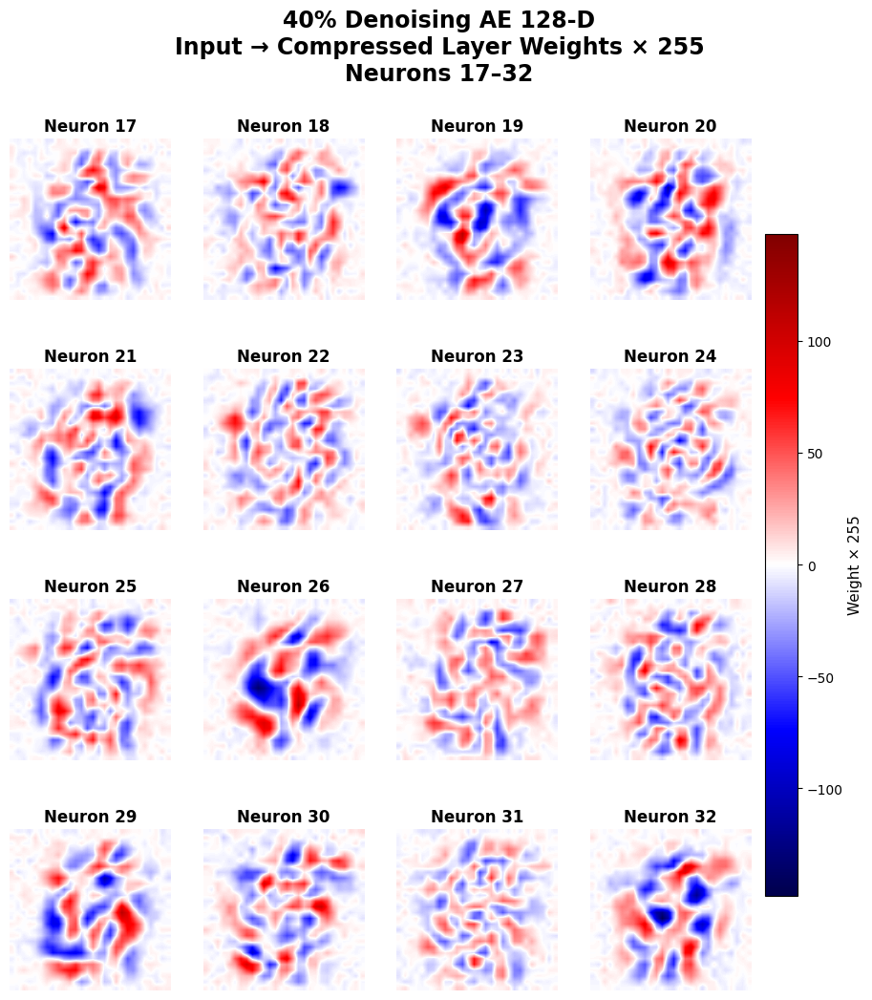

Saved: /content/task6_weight_visualization_0255/figures/dae_40pct/neurons_017_032.png


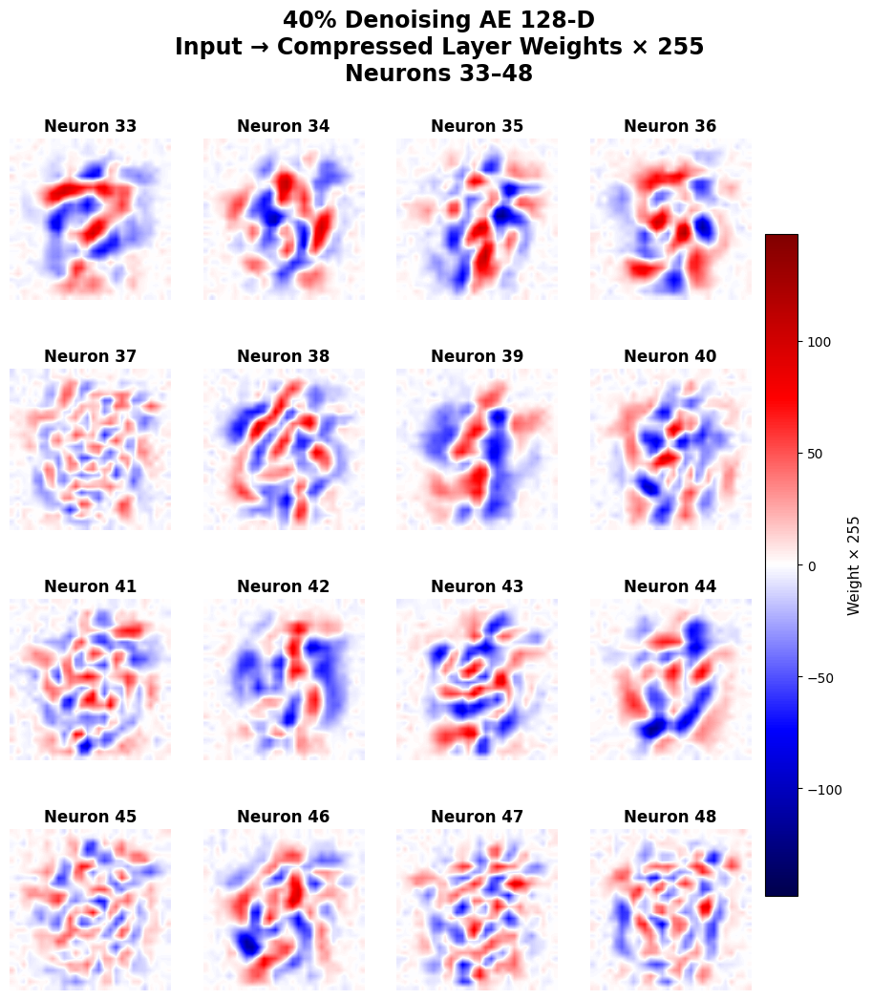

Saved: /content/task6_weight_visualization_0255/figures/dae_40pct/neurons_033_048.png


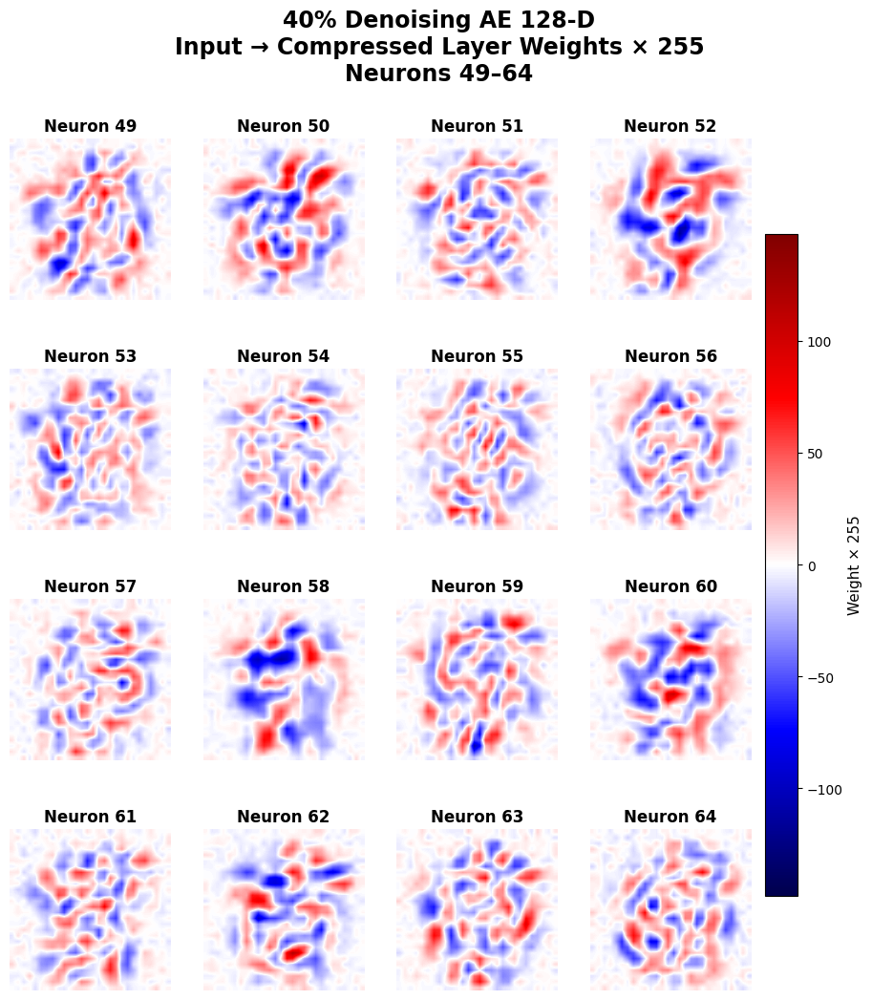

Saved: /content/task6_weight_visualization_0255/figures/dae_40pct/neurons_049_064.png


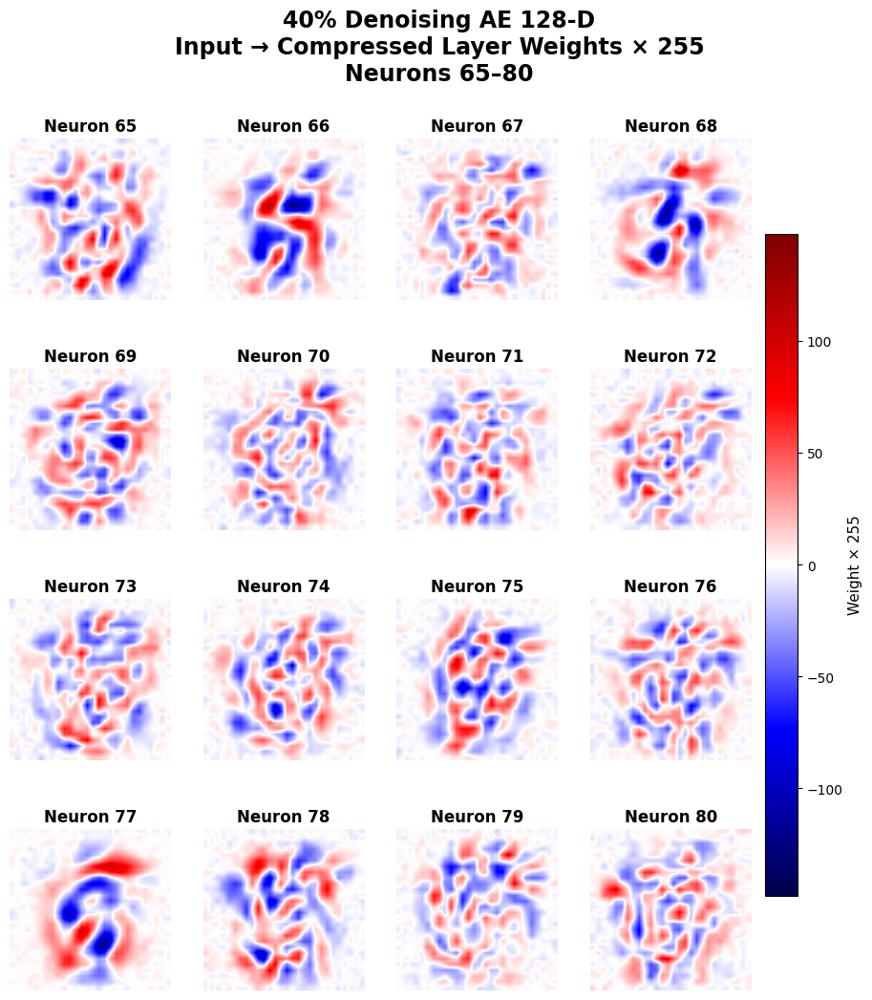

Saved: /content/task6_weight_visualization_0255/figures/dae_40pct/neurons_065_080.png


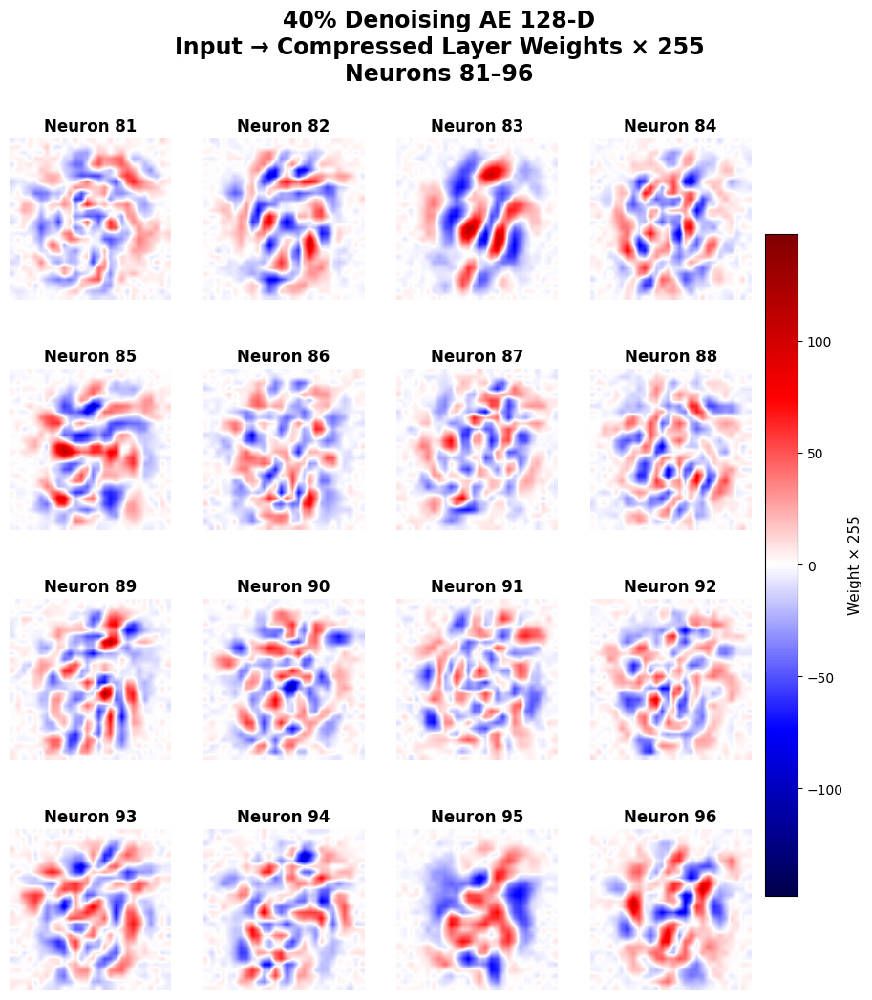

Saved: /content/task6_weight_visualization_0255/figures/dae_40pct/neurons_081_096.png


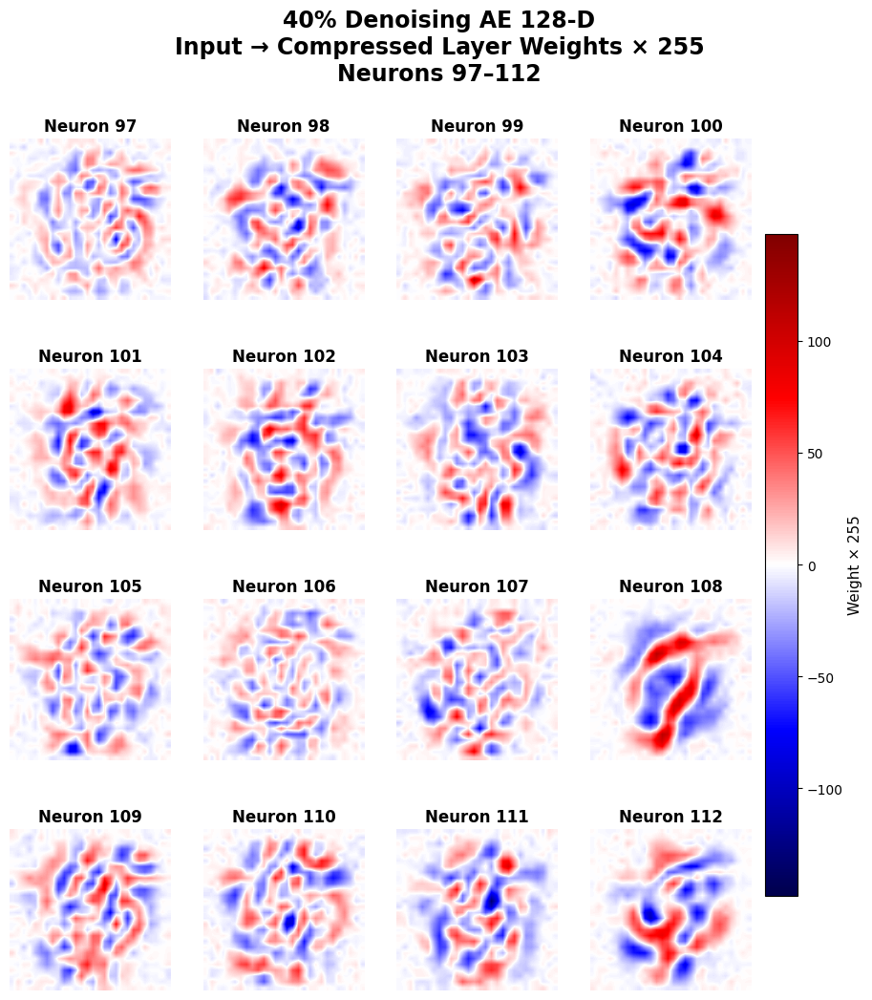

Saved: /content/task6_weight_visualization_0255/figures/dae_40pct/neurons_097_112.png


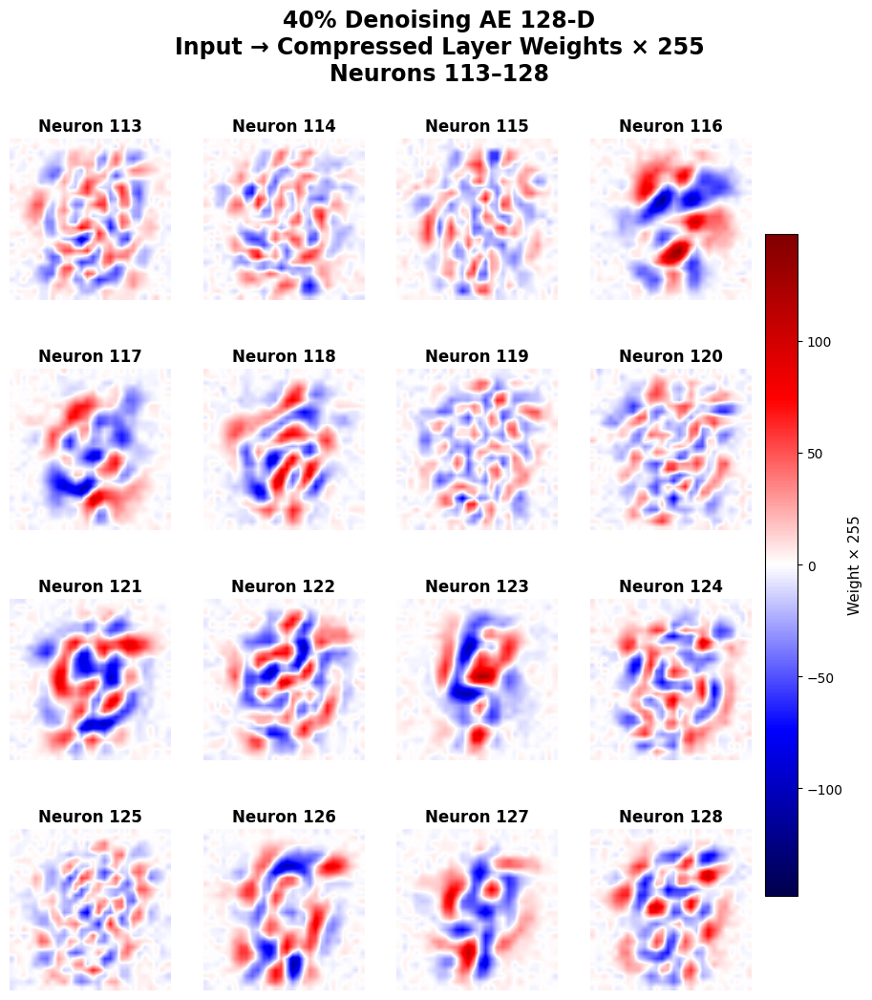

Saved: /content/task6_weight_visualization_0255/figures/dae_40pct/neurons_113_128.png

TASK 6 — WEIGHT VISUALIZATION COMPLETE

Each model:
  128 neurons
  8 figures
  16 neurons per figure
  Each neuron: 784 → 28 × 28
  Weight scaling: 0–255


In [ ]:
# ============================================================
# TASK 6 — WEIGHT VISUALIZATION
# Scale each neuron's weights to 0–255
# 4 × 4 = 16 neurons per figure
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt


# ------------------------------------------------------------
# Output directories
# ------------------------------------------------------------

TASK6_NEW_DIR = "/content/task6_weight_visualization_0255"

TASK6_NEW_FIG_DIR = os.path.join(
    TASK6_NEW_DIR,
    "figures"
)

MODEL_DIRS = {
    "normal_ae": os.path.join(
        TASK6_NEW_FIG_DIR,
        "normal_ae"
    ),

    "dae_20pct": os.path.join(
        TASK6_NEW_FIG_DIR,
        "dae_20pct"
    ),

    "dae_40pct": os.path.join(
        TASK6_NEW_FIG_DIR,
        "dae_40pct"
    )
}

for directory in MODEL_DIRS.values():
    os.makedirs(
        directory,
        exist_ok=True
    )


# ============================================================
# SCALE WEIGHTS TO 0–255
# ============================================================

def scale_weights_to_255(
    weight_vector
):

    weight_vector = np.asarray(
        weight_vector,
        dtype=np.float32
    )

    w_min = np.min(
        weight_vector
    )

    w_max = np.max(
        weight_vector
    )

    if w_max == w_min:

        return np.zeros_like(
            weight_vector,
            dtype=np.uint8
        )

    scaled = (
        (weight_vector - w_min)
        /
        (w_max - w_min)
    ) * 255.0

    return scaled.astype(
        np.uint8
    )


# ============================================================
# PLOT 16 NEURONS
# ============================================================

# ============================================================
# TASK 6 — WEIGHT VISUALIZATION
# Actual weights preserved
# Color display mapped to 0–255
# ============================================================


def plot_weight_pages_0255(
    weights,
    model_name,
    output_dir
):

    weights_np = (
        weights.detach().cpu().numpy()
        if hasattr(weights, "detach")
        else np.asarray(weights)
    )

    assert weights_np.shape == (128, 784), \
        f"Expected (128, 784), got {weights_np.shape}"

    os.makedirs(
        output_dir,
        exist_ok=True
    )

    # --------------------------------------------------------
    # Find the actual global weight range
    # --------------------------------------------------------

    max_abs = np.max(
        np.abs(weights_np)
    )

    print(
        f"{model_name}"
    )

    print(
        f"Actual weight range: "
        f"{weights_np.min():.6f} "
        f"to "
        f"{weights_np.max():.6f}"
    )

    print(
        f"Maximum absolute weight: "
        f"{max_abs:.6f}"
    )

    # --------------------------------------------------------
    # 8 pages × 16 neurons
    # --------------------------------------------------------

    for start in range(
        0,
        128,
        16
    ):

        end = start + 16

        fig, axes = plt.subplots(
            4,
            4,
            figsize=(13, 13)
        )

        axes = axes.flatten()

        # ----------------------------------------------------
        # Plot neurons
        # ----------------------------------------------------

        for local_idx, neuron_idx in enumerate(
            range(start, end)
        ):

            ax = axes[
                local_idx
            ]

            weight_image = (
                weights_np[
                    neuron_idx
                ].reshape(28, 28)
            )

            # -----------------------------------------------
            # Actual weights are preserved.
            #
            # The colormap maps the signed weight range
            # to its display color range.
            # -----------------------------------------------

            im = ax.imshow(
                weight_image,
                cmap="seismic",
                vmin=-max_abs,
                vmax=max_abs,
                interpolation="bilinear"
            )

            ax.set_title(
                f"Neuron {neuron_idx + 1}",
                fontsize=12,
                fontweight="bold"
            )

            ax.axis("off")

        # ----------------------------------------------------
        # Colorbar
        # ----------------------------------------------------

        cbar = fig.colorbar(
            im,
            ax=axes.tolist(),
            fraction=0.025,
            pad=0.02
        )

        cbar.set_label(
            "Actual weight value",
            fontsize=11
        )

        # ----------------------------------------------------
        # Title
        # ----------------------------------------------------

        fig.suptitle(
            (
                f"{model_name}\n"
                f"Input → Compressed Layer Weights\n"
                f"Neurons {start + 1}–{end}"
            ),
            fontsize=18,
            fontweight="bold"
        )

        plt.tight_layout(
            rect=[
                0,
                0,
                0.95,
                0.94
            ]
        )

        # ----------------------------------------------------
        # Save
        # ----------------------------------------------------

        filename = (
            f"neurons_"
            f"{start + 1:03d}_"
            f"{end:03d}.png"
        )

        save_path = os.path.join(
            output_dir,
            filename
        )

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        plt.close(fig)

        print(
            f"Saved: {save_path}"
        )


# ============================================================
# GENERATE ALL 128 NEURONS
# ============================================================

def generate_weight_visualizations(
    weights,
    model_name,
    output_dir
):

    for start_neuron in range(
        0,
        128,
        16
    ):

        plot_weight_page_0255(
            weights=weights,
            start_neuron=start_neuron,
            model_name=model_name,
            output_dir=output_dir
        )


# ============================================================
# NORMAL 1-HIDDEN AE
# ============================================================

generate_weight_visualizations(
    weights=ae128_weights,
    model_name="1-Hidden AE 128-D",
    output_dir=MODEL_DIRS[
        "normal_ae"
    ]
)


# ============================================================
# 20% DENOISING AE
# ============================================================

generate_weight_visualizations(
    weights=dae20_weights,
    model_name="20% Denoising AE 128-D",
    output_dir=MODEL_DIRS[
        "dae_20pct"
    ]
)


# ============================================================
# 40% DENOISING AE
# ============================================================

generate_weight_visualizations(
    weights=dae40_weights,
    model_name="40% Denoising AE 128-D",
    output_dir=MODEL_DIRS[
        "dae_40pct"
    ]
)


print("\n" + "=" * 70)
print("TASK 6 — WEIGHT VISUALIZATION COMPLETE")
print("=" * 70)

print("\nEach model:")
print("  128 neurons")
print("  8 figures")
print("  16 neurons per figure")
print("  Each neuron: 784 → 28 × 28")
print("  Weight scaling: 0–255")

In [ ]:
# ============================================================
# TASK 6 — WEIGHT VISUALIZATION
# Actual weights preserved
# Color display mapped to 0–255
# ============================================================

import os
import numpy as np
import matplotlib.pyplot as plt


def plot_weight_pages_0255(
    weights,
    model_name,
    output_dir
):

    weights_np = (
        weights.detach().cpu().numpy()
        if hasattr(weights, "detach")
        else np.asarray(weights)
    )

    assert weights_np.shape == (128, 784), \
        f"Expected (128, 784), got {weights_np.shape}"

    os.makedirs(
        output_dir,
        exist_ok=True
    )

    # --------------------------------------------------------
    # Find the actual global weight range
    # --------------------------------------------------------

    max_abs = np.max(
        np.abs(weights_np)
    )

    print(
        f"{model_name}"
    )

    print(
        f"Actual weight range: "
        f"{weights_np.min():.6f} "
        f"to "
        f"{weights_np.max():.6f}"
    )

    print(
        f"Maximum absolute weight: "
        f"{max_abs:.6f}"
    )

    # --------------------------------------------------------
    # 8 pages × 16 neurons
    # --------------------------------------------------------

    for start in range(
        0,
        128,
        16
    ):

        end = start + 16

        fig, axes = plt.subplots(
            4,
            4,
            figsize=(13, 13)
        )

        axes = axes.flatten()

        # ----------------------------------------------------
        # Plot neurons
        # ----------------------------------------------------

        for local_idx, neuron_idx in enumerate(
            range(start, end)
        ):

            ax = axes[
                local_idx
            ]

            weight_image = (
                weights_np[
                    neuron_idx
                ].reshape(28, 28)
            )

            # -----------------------------------------------
            # Actual weights are preserved.
            #
            # The colormap maps the signed weight range
            # to its display color range.
            # -----------------------------------------------

            im = ax.imshow(
                weight_image,
                cmap="seismic",
                vmin=-max_abs,
                vmax=max_abs,
                interpolation="bilinear"
            )

            ax.set_title(
                f"Neuron {neuron_idx + 1}",
                fontsize=12,
                fontweight="bold"
            )

            ax.axis("off")

        # ----------------------------------------------------
        # Colorbar
        # ----------------------------------------------------

        cbar = fig.colorbar(
            im,
            ax=axes.tolist(),
            fraction=0.025,
            pad=0.02
        )

        cbar.set_label(
            "Actual weight value",
            fontsize=11
        )

        # ----------------------------------------------------
        # Title
        # ----------------------------------------------------

        fig.suptitle(
            (
                f"{model_name}\n"
                f"Input → Compressed Layer Weights\n"
                f"Neurons {start + 1}–{end}"
            ),
            fontsize=18,
            fontweight="bold"
        )

        plt.tight_layout(
            rect=[
                0,
                0,
                0.95,
                0.94
            ]
        )

        # ----------------------------------------------------
        # Save
        # ----------------------------------------------------

        filename = (
            f"neurons_"
            f"{start + 1:03d}_"
            f"{end:03d}.png"
        )

        save_path = os.path.join(
            output_dir,
            filename
        )

        plt.savefig(
            save_path,
            dpi=300,
            bbox_inches="tight"
        )

        plt.show()

        plt.close(fig)

        print(
            f"Saved: {save_path}"
        )

1-Hidden AE 128-D
Actual weight range: -1.408312 to 1.713851
Maximum absolute weight: 1.713851


/tmp/ipykernel_1277/4074922517.py:147: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


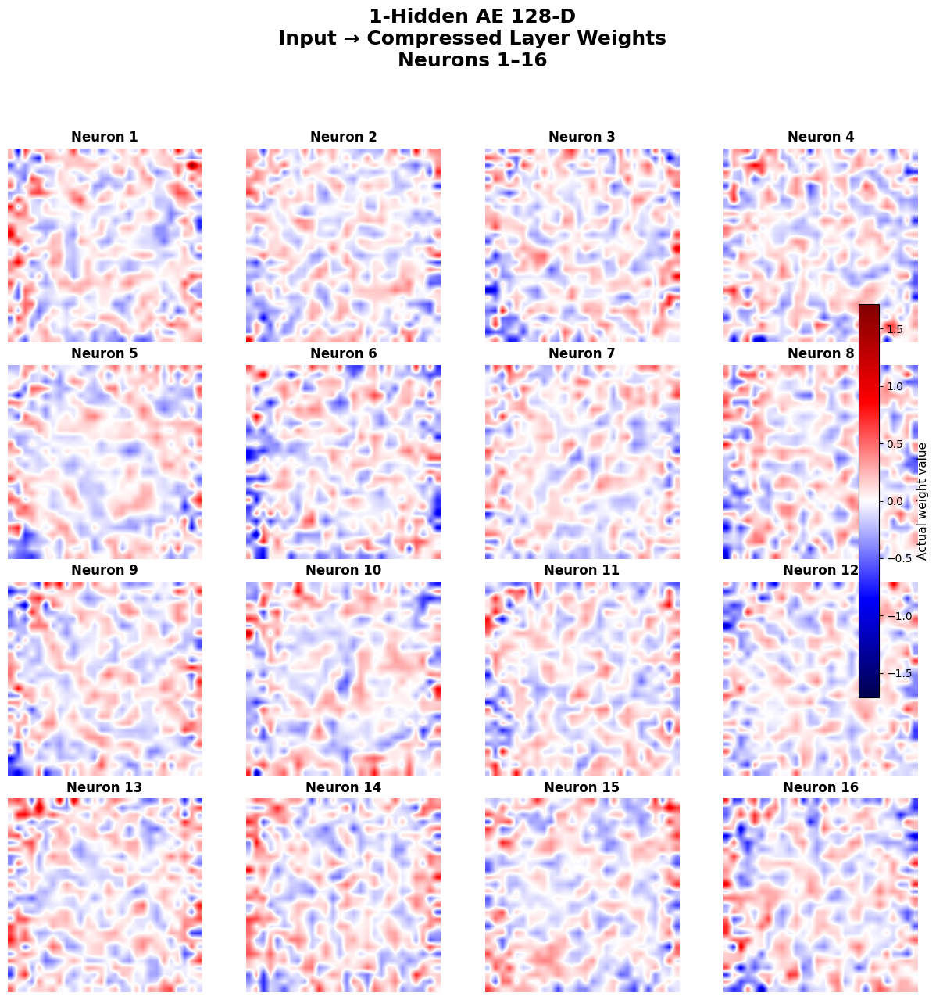

Saved: task_6_output/1_hidden_ae/neurons_001_016.png


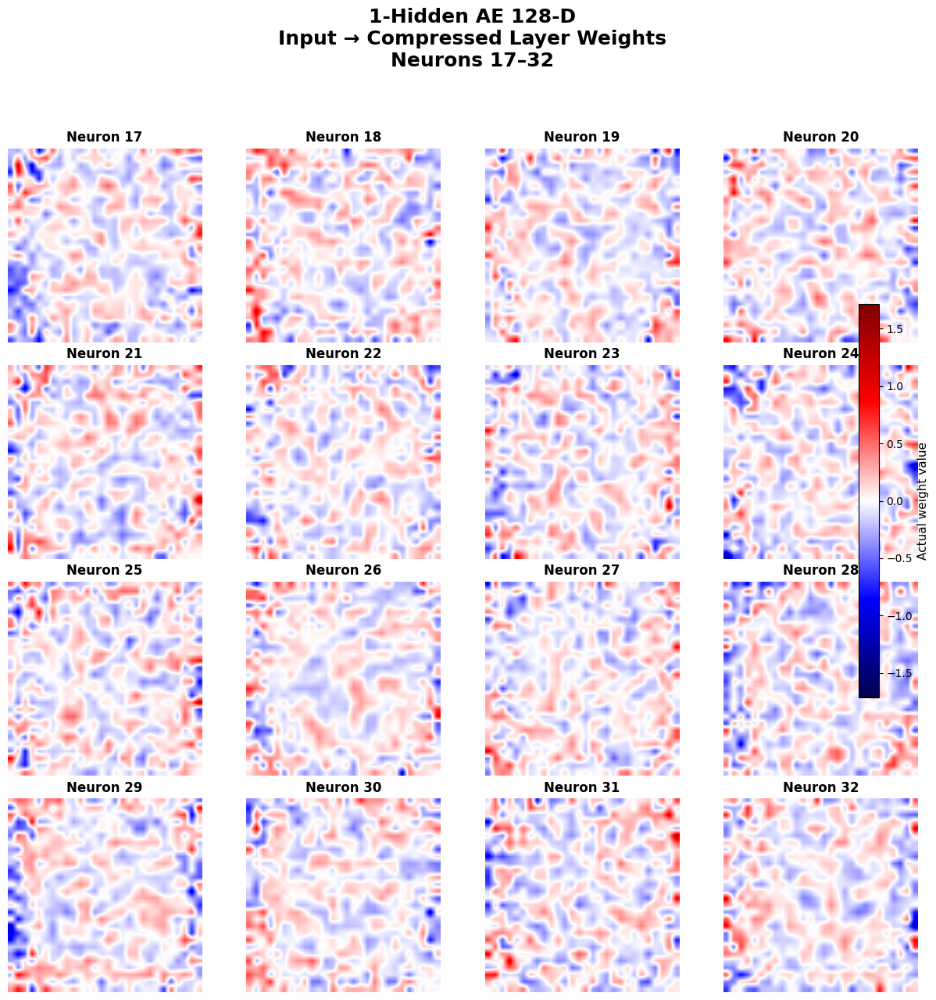

Saved: task_6_output/1_hidden_ae/neurons_017_032.png


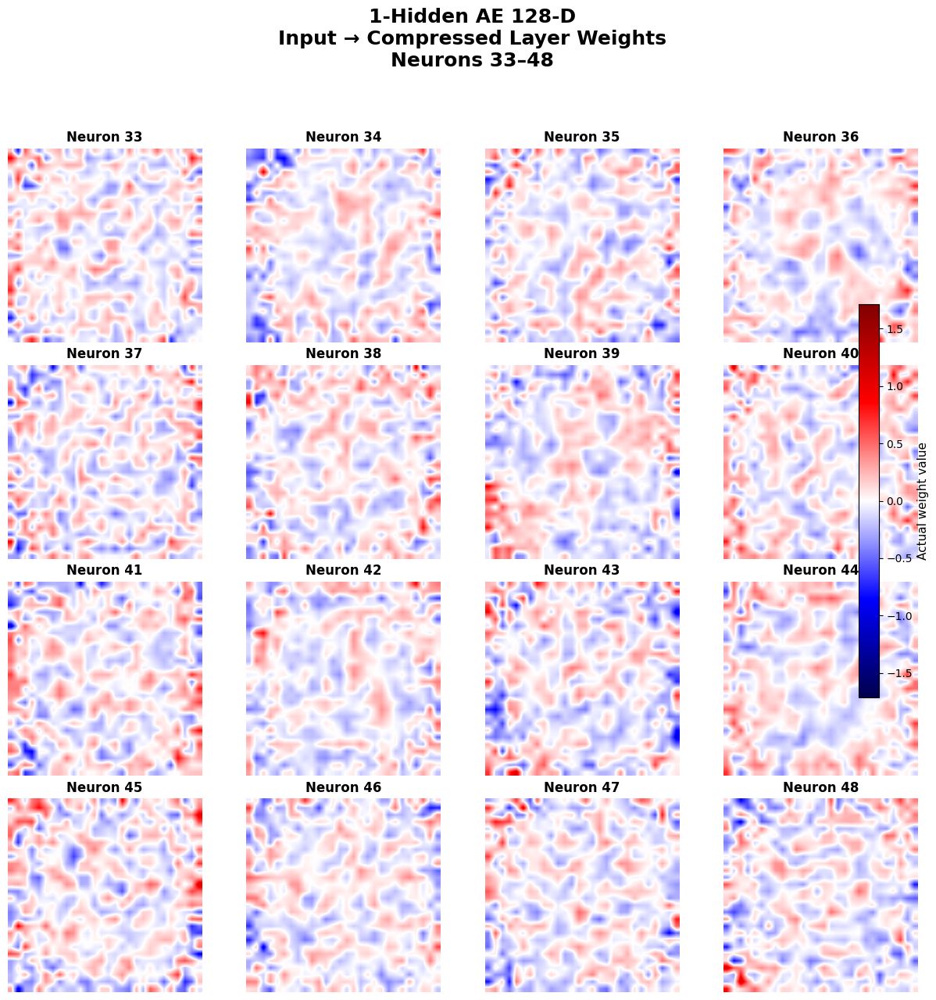

Saved: task_6_output/1_hidden_ae/neurons_033_048.png


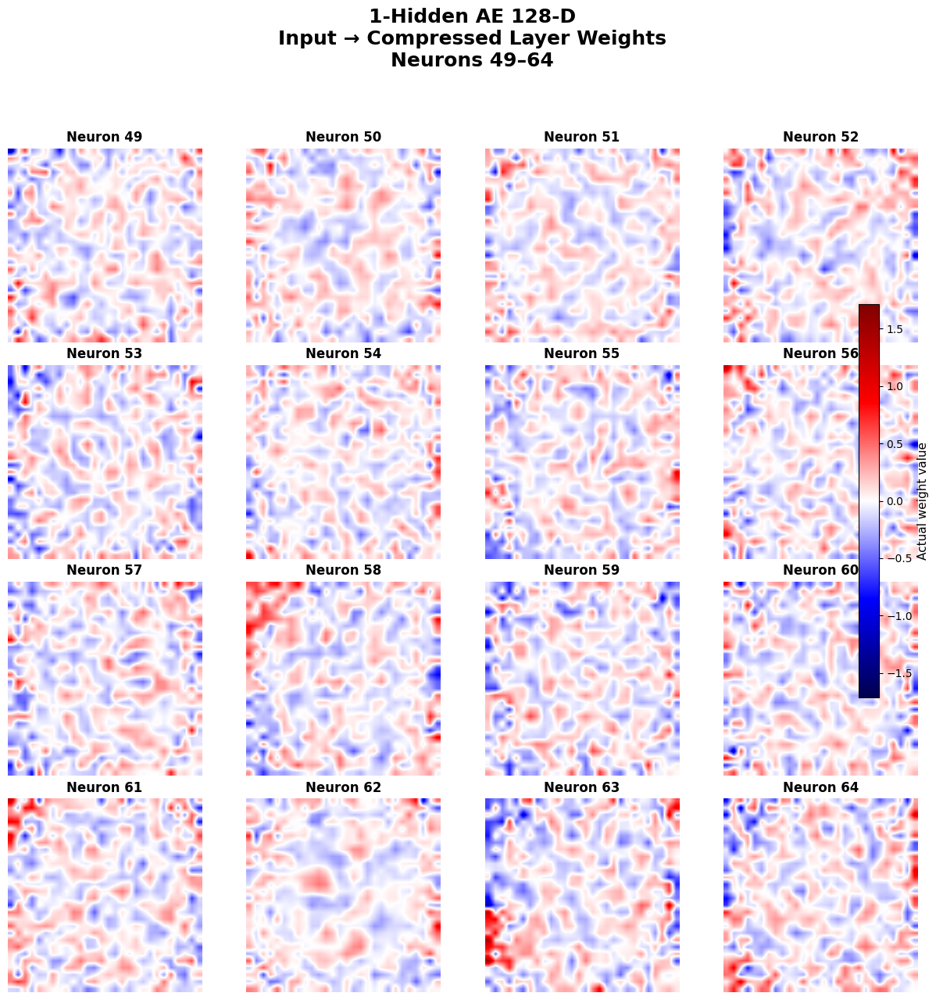

Saved: task_6_output/1_hidden_ae/neurons_049_064.png


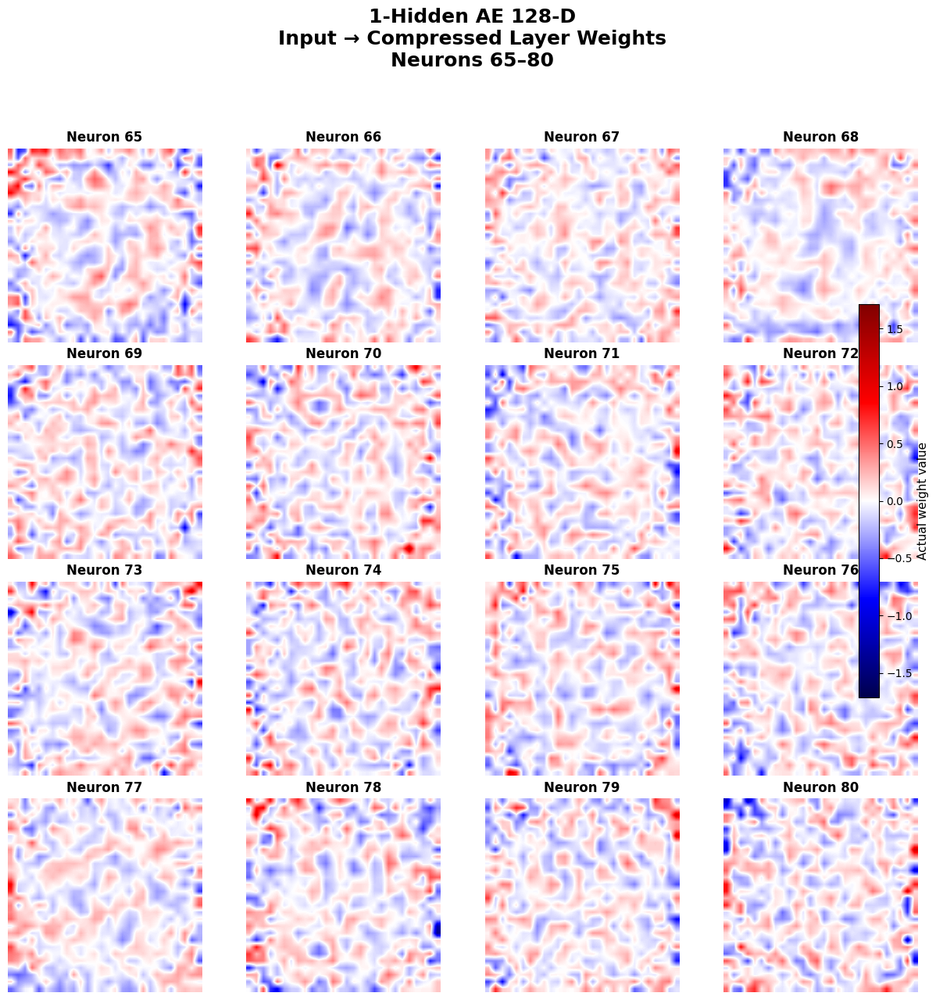

Saved: task_6_output/1_hidden_ae/neurons_065_080.png


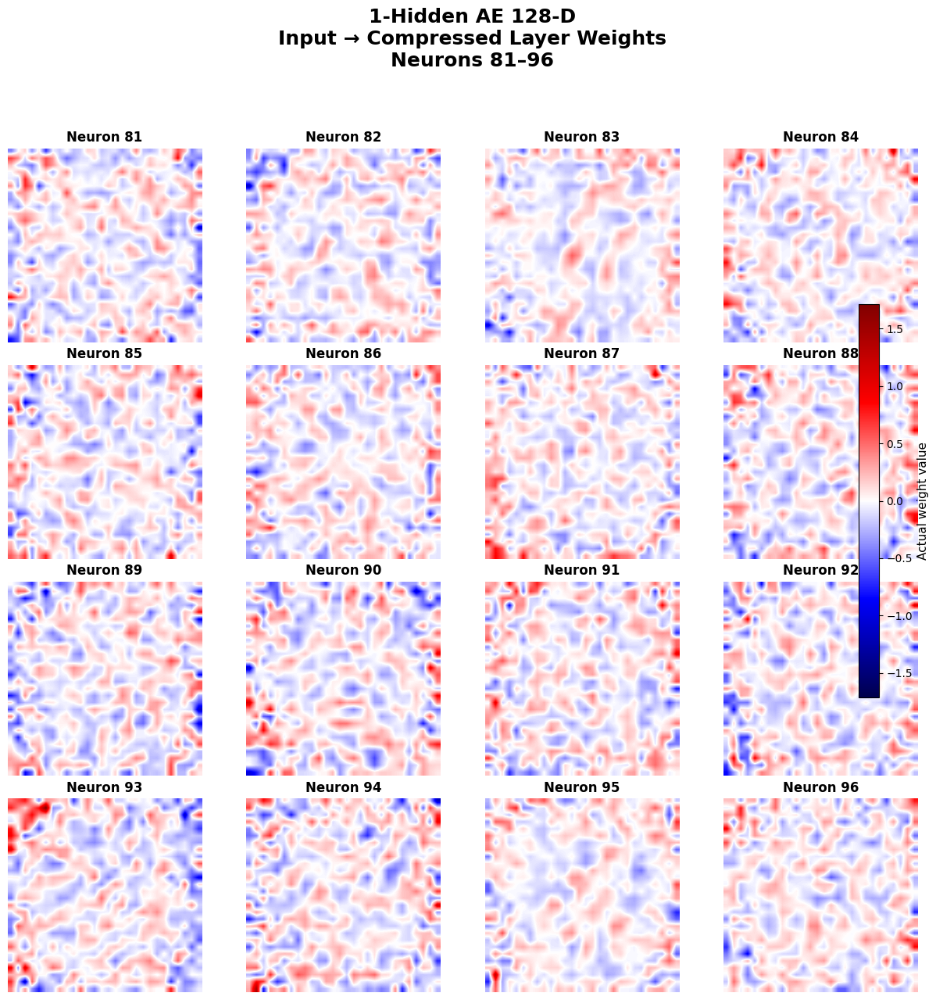

Saved: task_6_output/1_hidden_ae/neurons_081_096.png


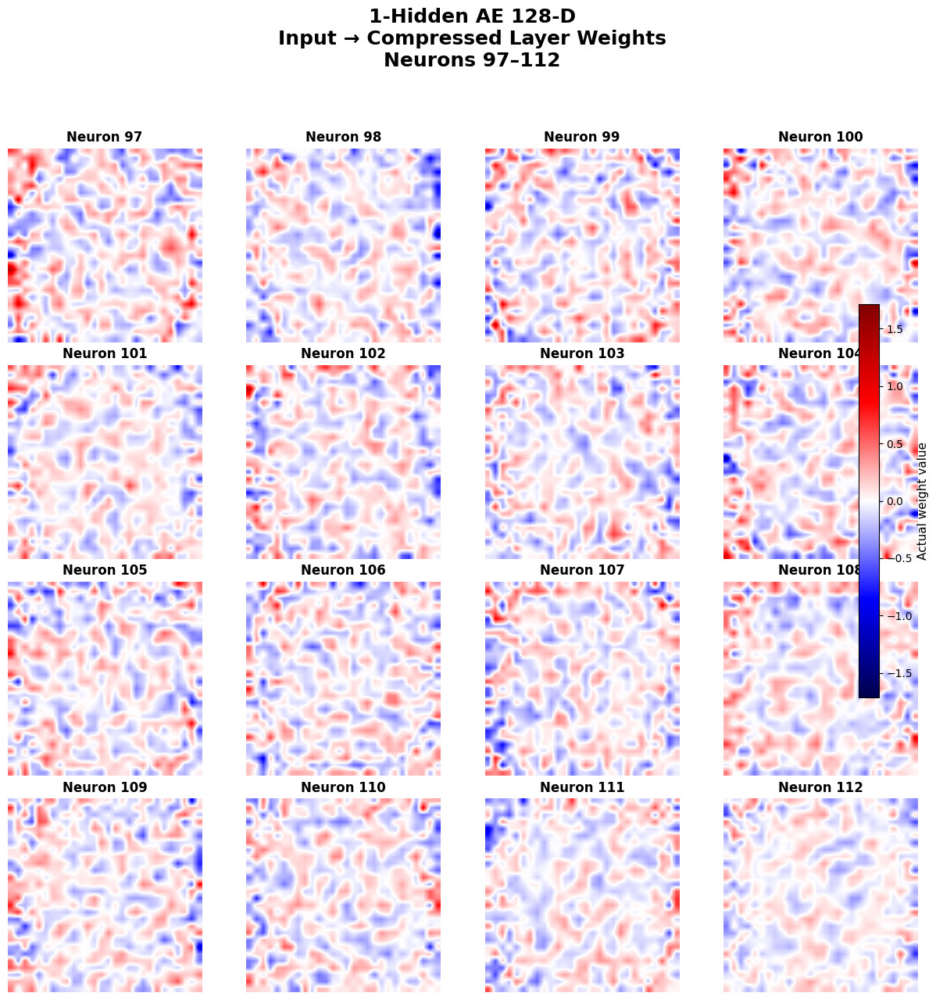

Saved: task_6_output/1_hidden_ae/neurons_097_112.png


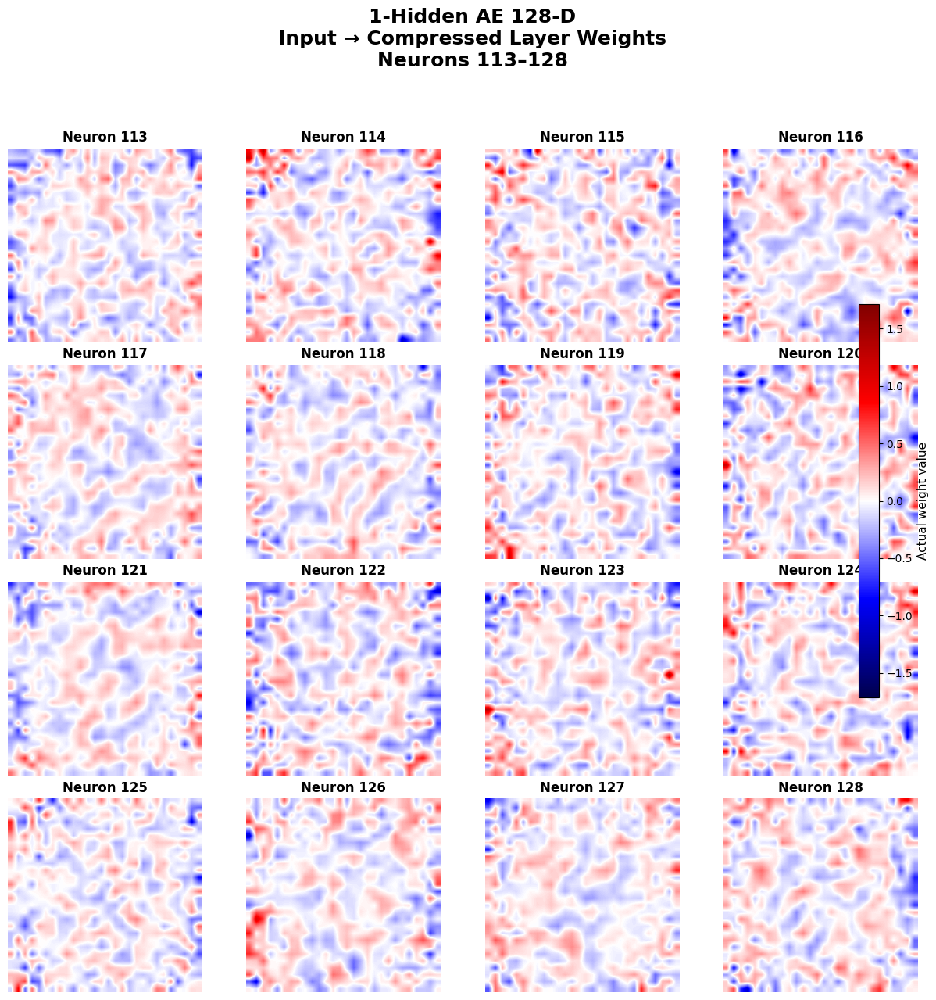

Saved: task_6_output/1_hidden_ae/neurons_113_128.png


In [ ]:
plot_weight_pages_0255(
    weights=ae128_weights,
    model_name="1-Hidden AE 128-D",
    output_dir="task_6_output/1_hidden_ae"
)


20% Denoising AE 128-D
Actual weight range: -0.522354 to 0.554212
Maximum absolute weight: 0.554212


/tmp/ipykernel_1277/4074922517.py:147: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


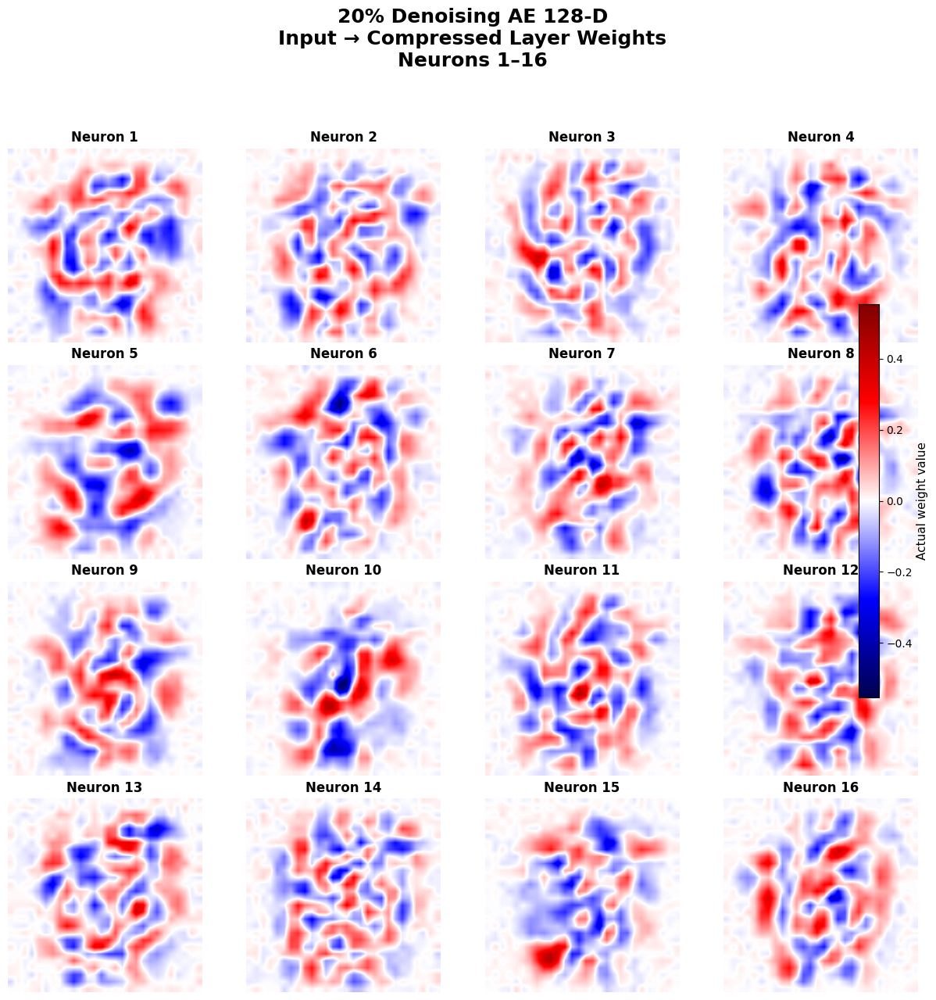

Saved: task_6_output/20_pct_dae/neurons_001_016.png


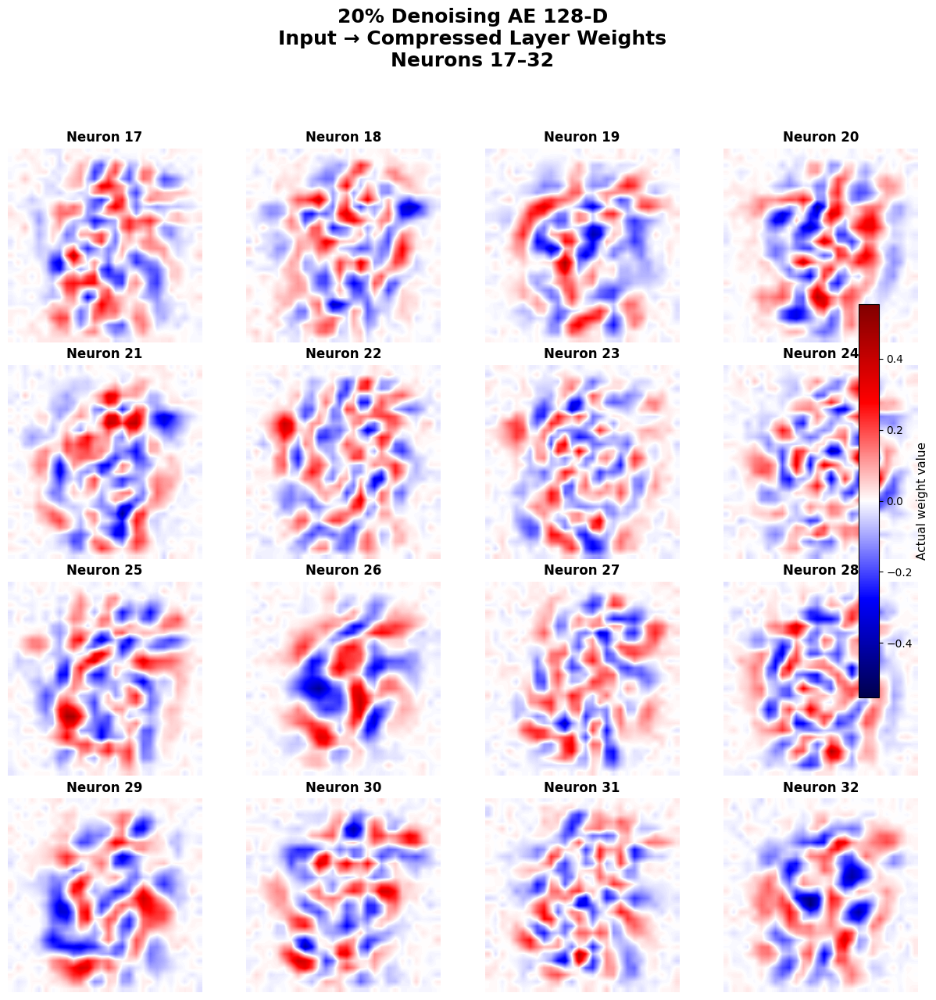

Saved: task_6_output/20_pct_dae/neurons_017_032.png


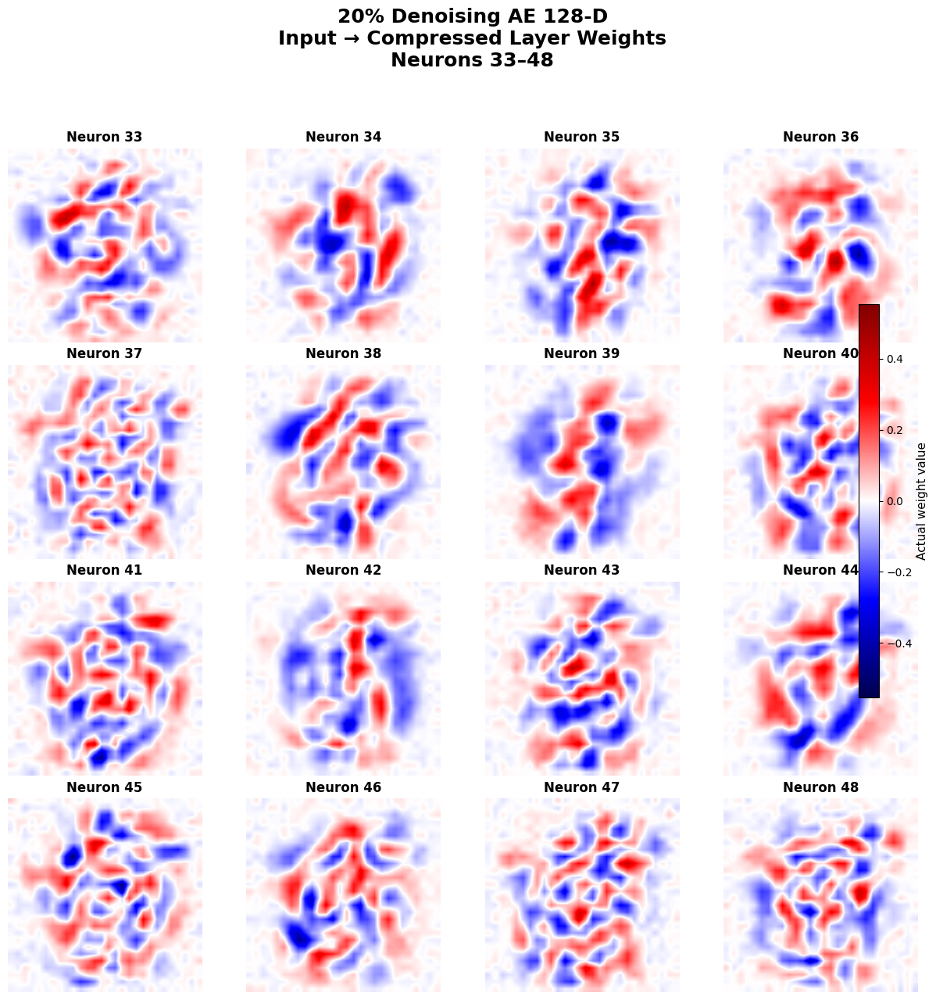

Saved: task_6_output/20_pct_dae/neurons_033_048.png


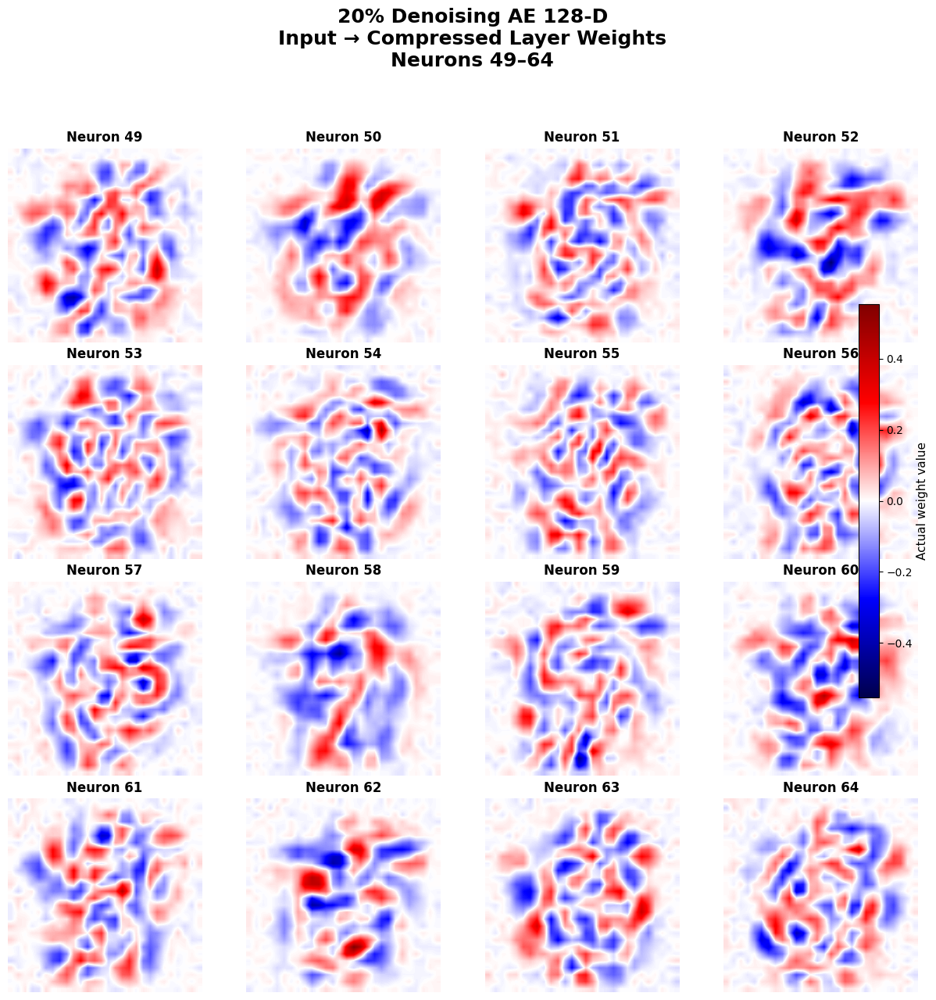

Saved: task_6_output/20_pct_dae/neurons_049_064.png


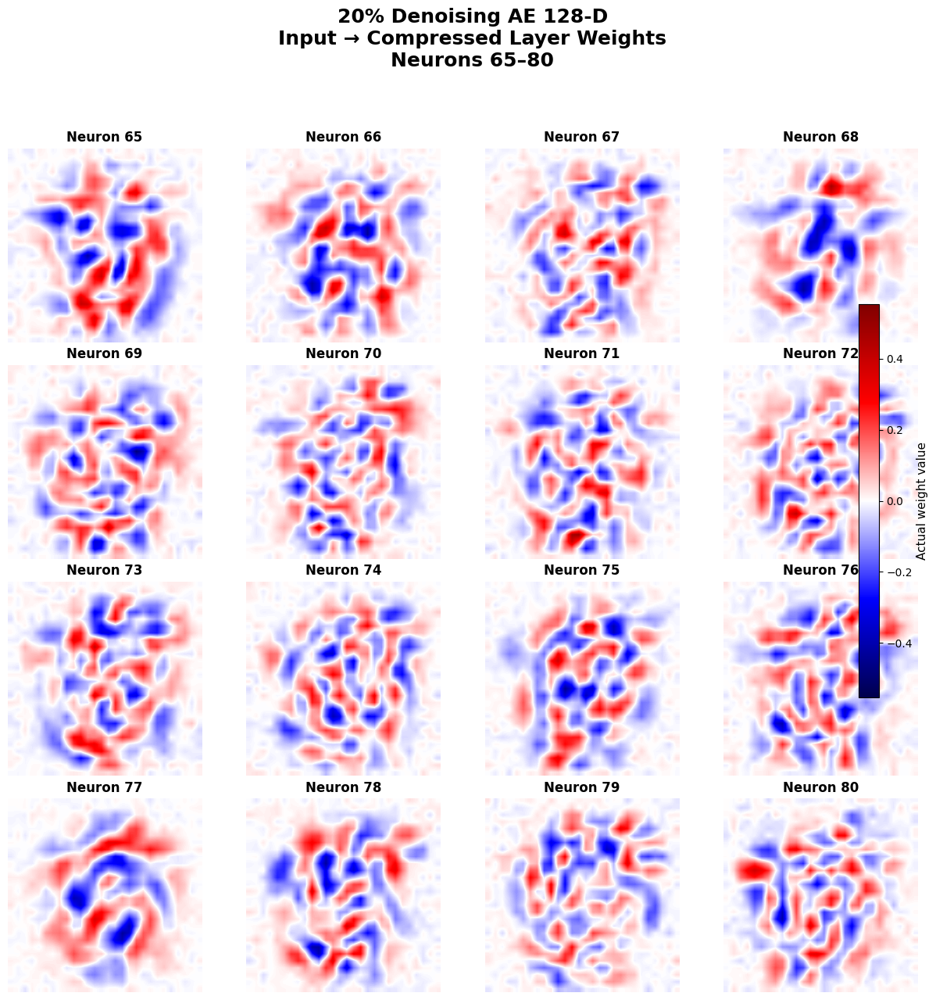

Saved: task_6_output/20_pct_dae/neurons_065_080.png


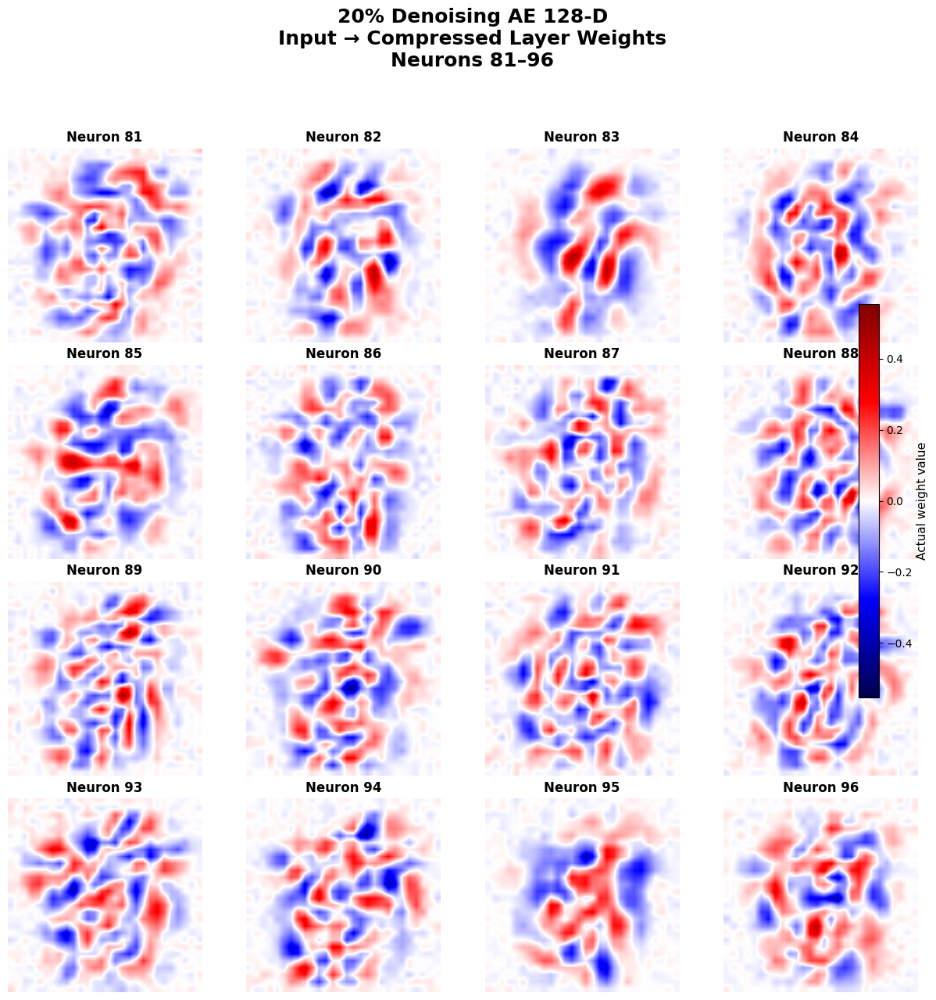

Saved: task_6_output/20_pct_dae/neurons_081_096.png


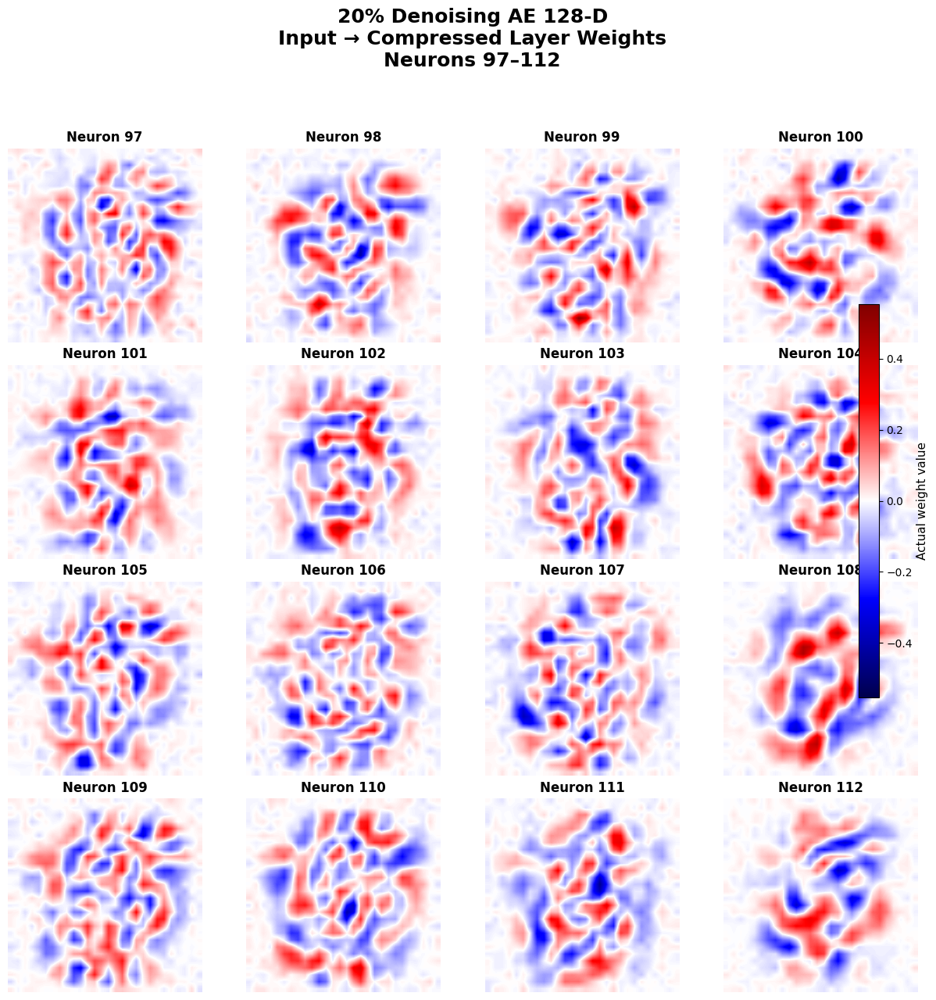

Saved: task_6_output/20_pct_dae/neurons_097_112.png


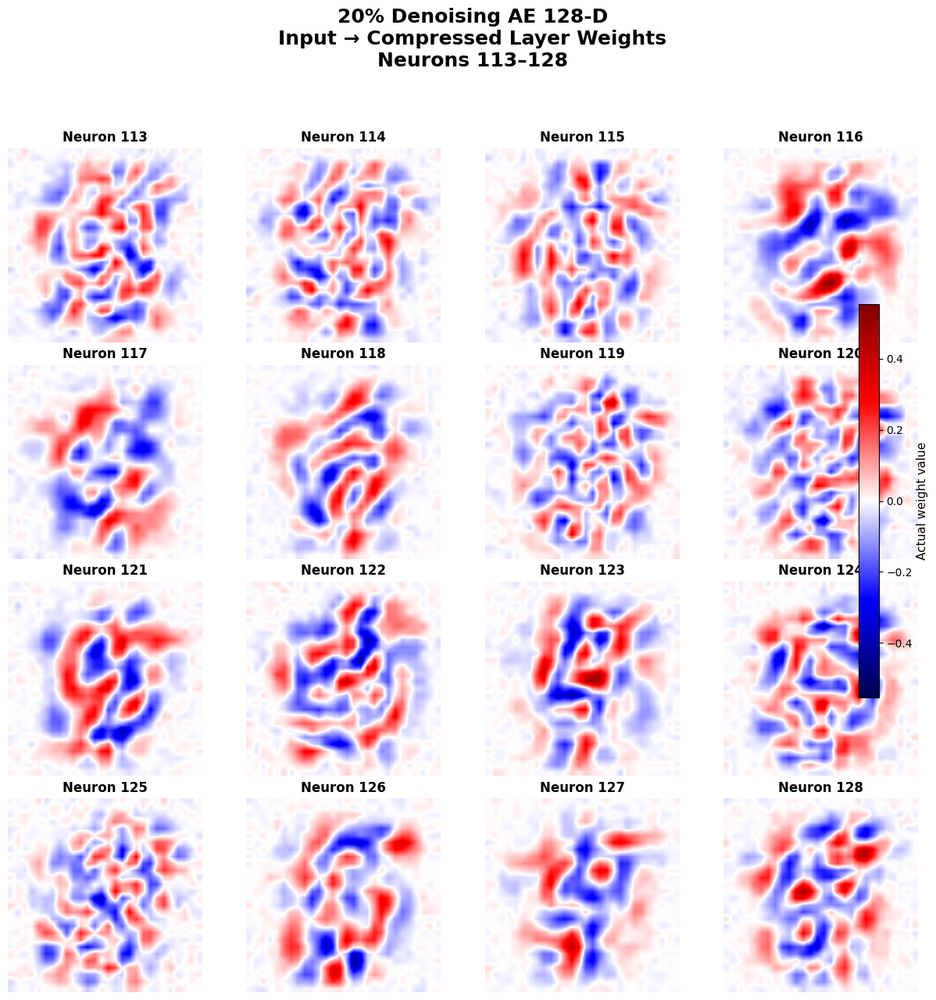

Saved: task_6_output/20_pct_dae/neurons_113_128.png


In [ ]:
plot_weight_pages_0255(
    weights=dae20_weights,
    model_name="20% Denoising AE 128-D",
    output_dir="task_6_output/20_pct_dae"
)

40% Denoising AE 128-D
Actual weight range: -0.580186 to 0.557432
Maximum absolute weight: 0.580186


/tmp/ipykernel_1277/4074922517.py:147: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


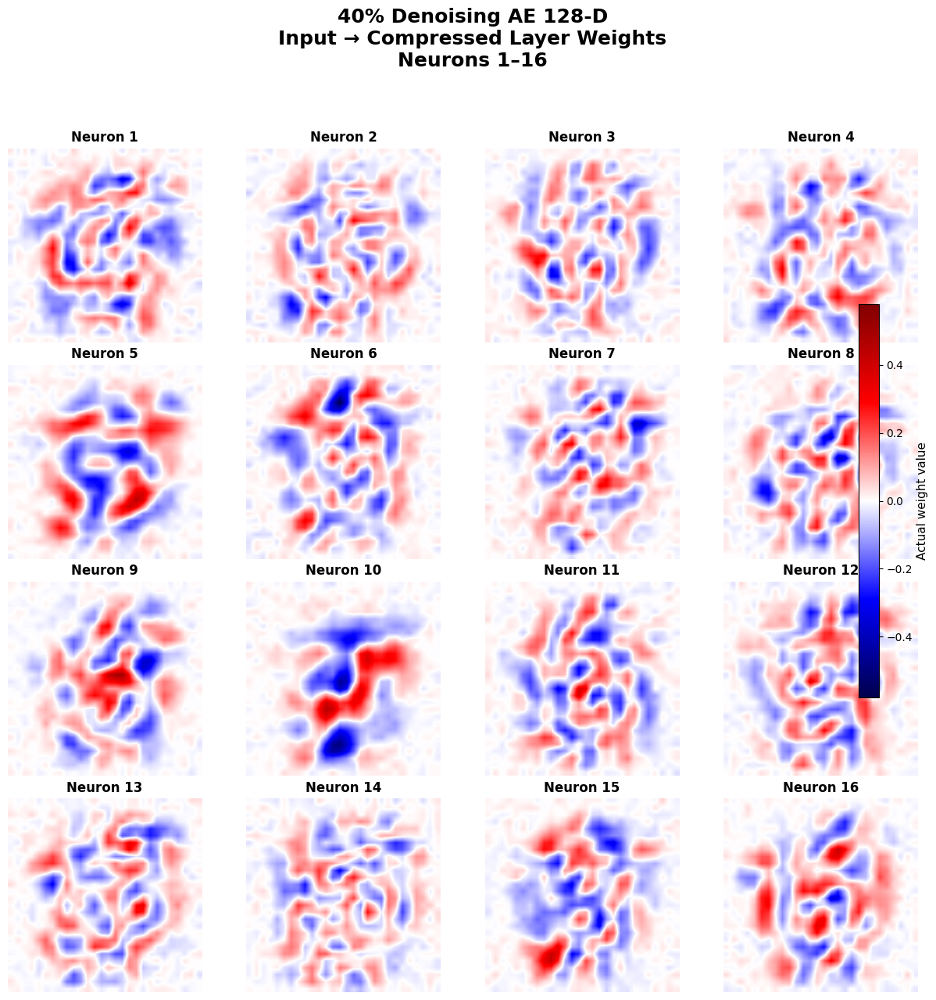

Saved: task_6_output/40_pct_dae/neurons_001_016.png


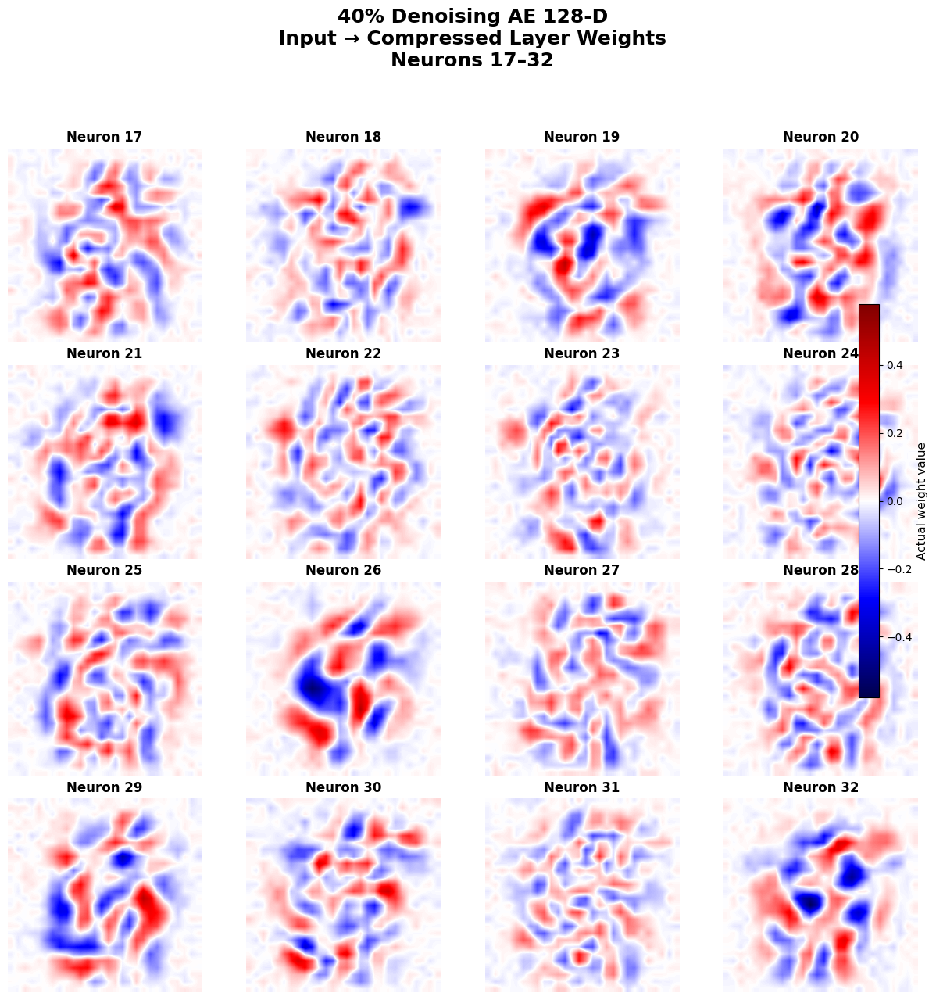

Saved: task_6_output/40_pct_dae/neurons_017_032.png


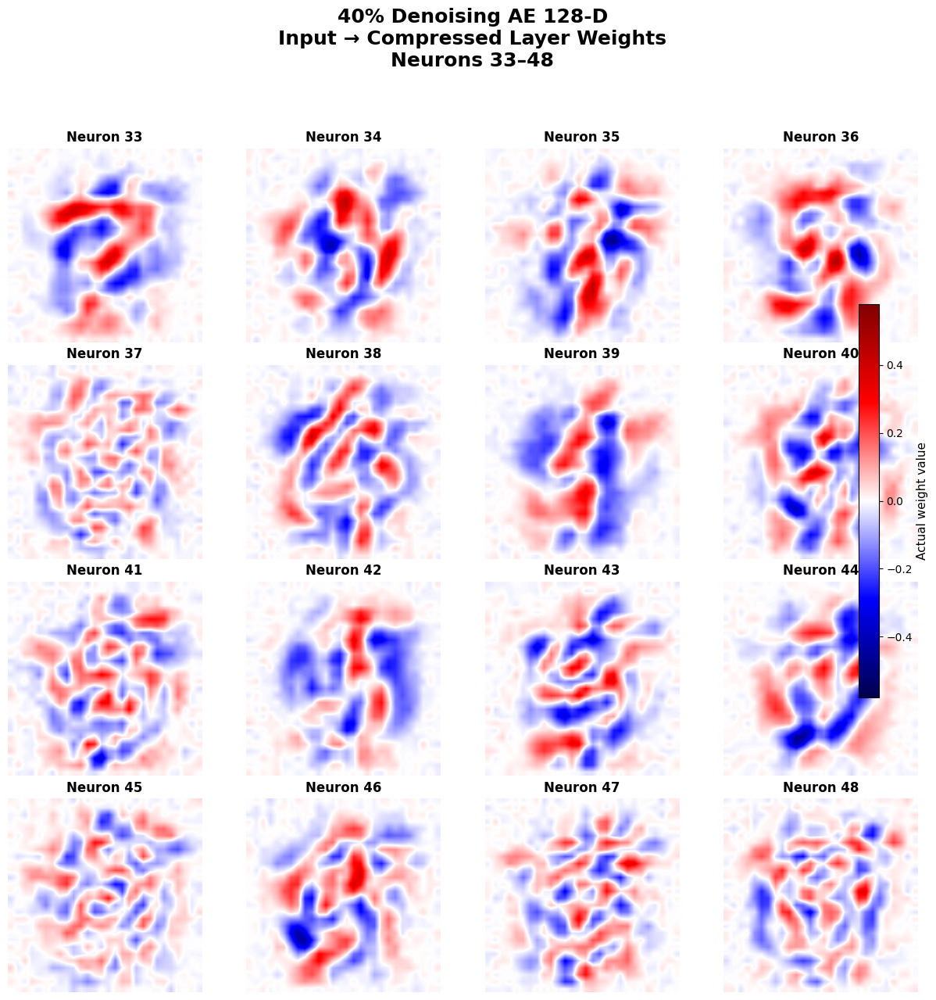

Saved: task_6_output/40_pct_dae/neurons_033_048.png


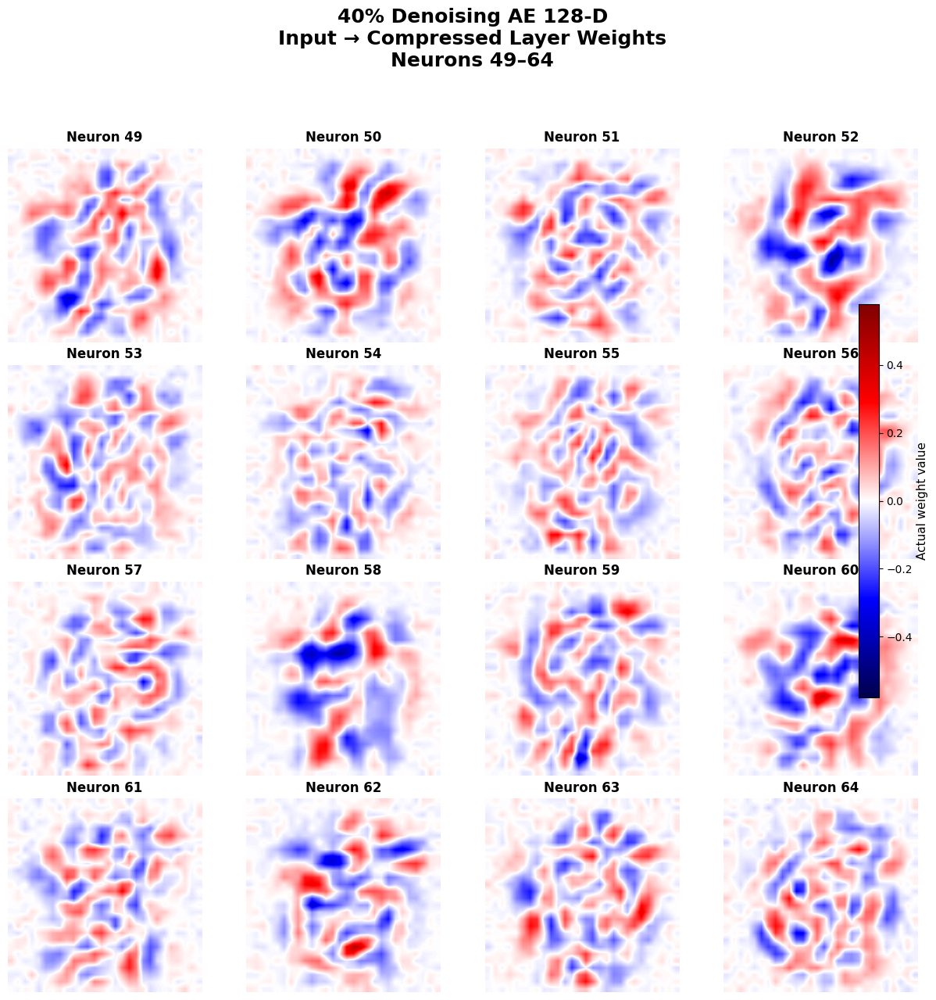

Saved: task_6_output/40_pct_dae/neurons_049_064.png


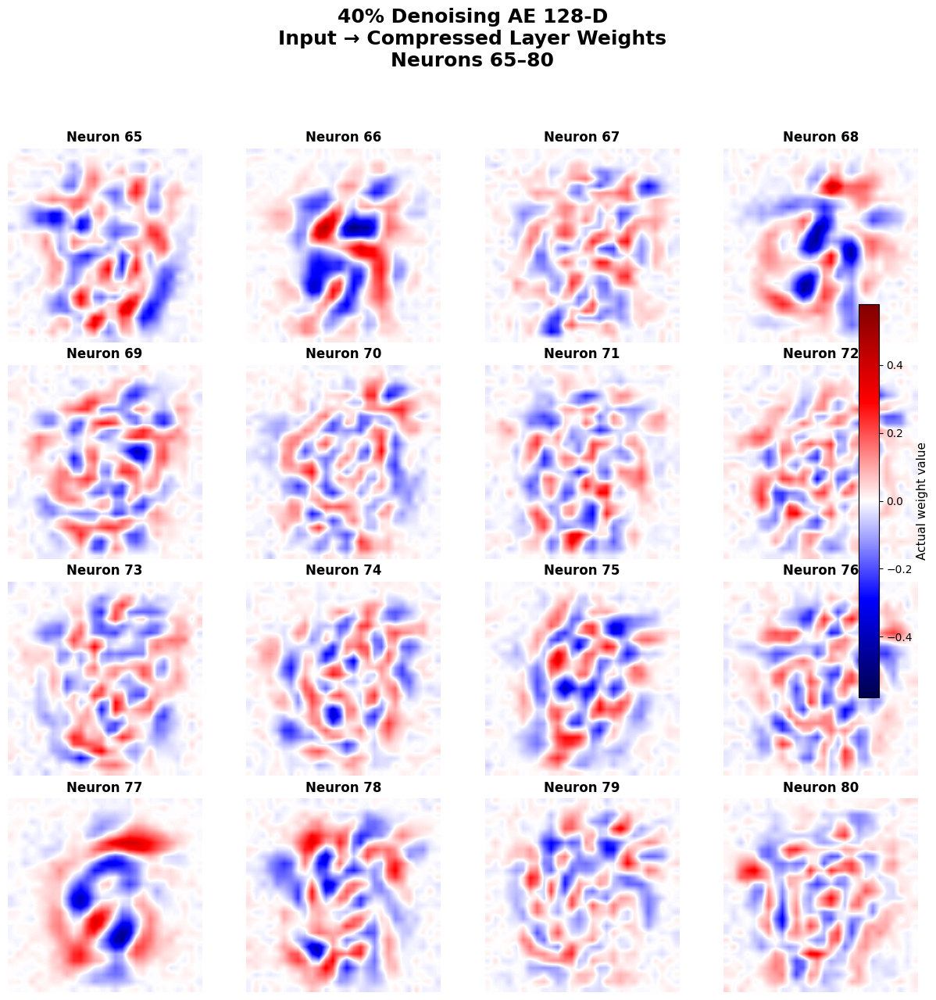

Saved: task_6_output/40_pct_dae/neurons_065_080.png


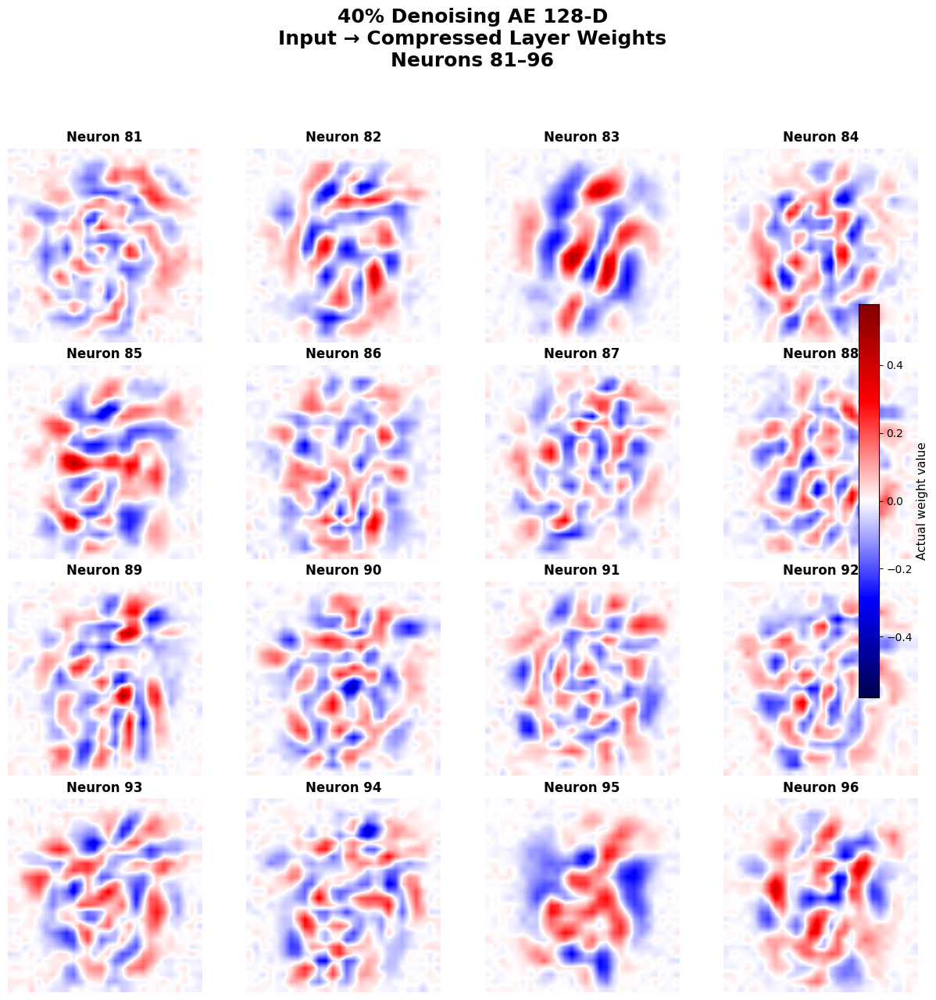

Saved: task_6_output/40_pct_dae/neurons_081_096.png


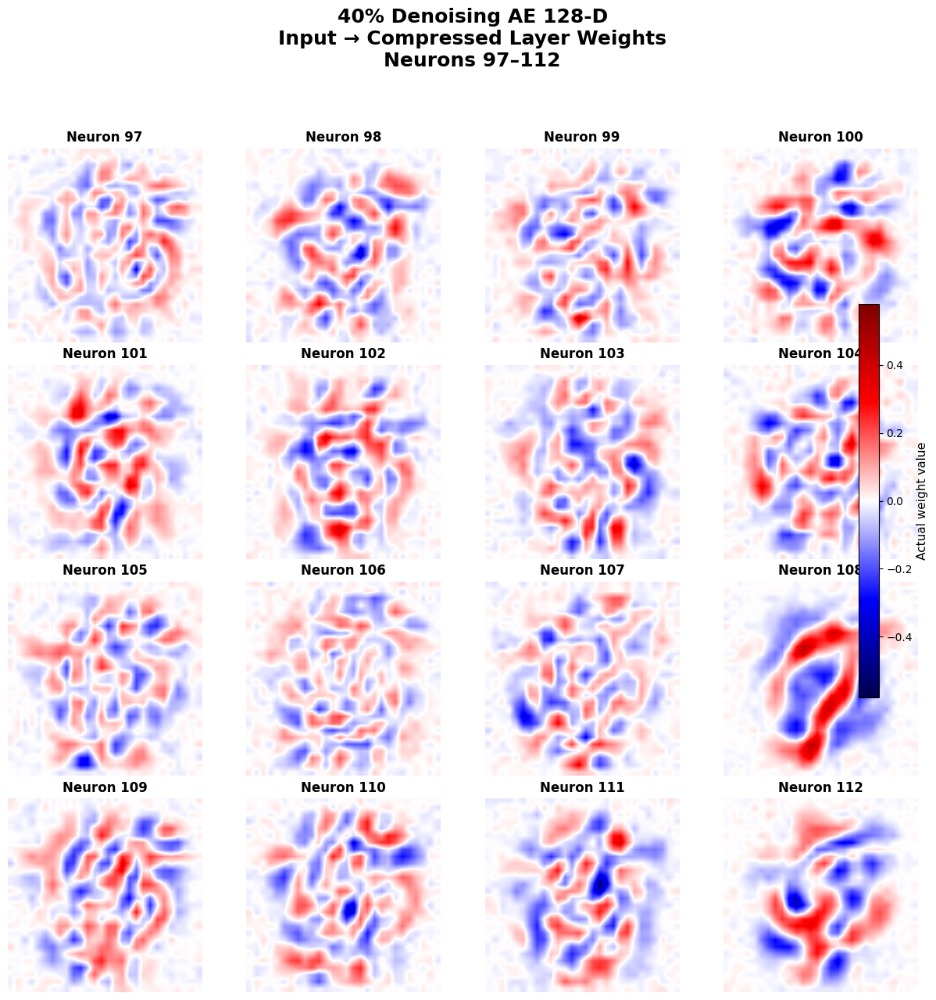

Saved: task_6_output/40_pct_dae/neurons_097_112.png


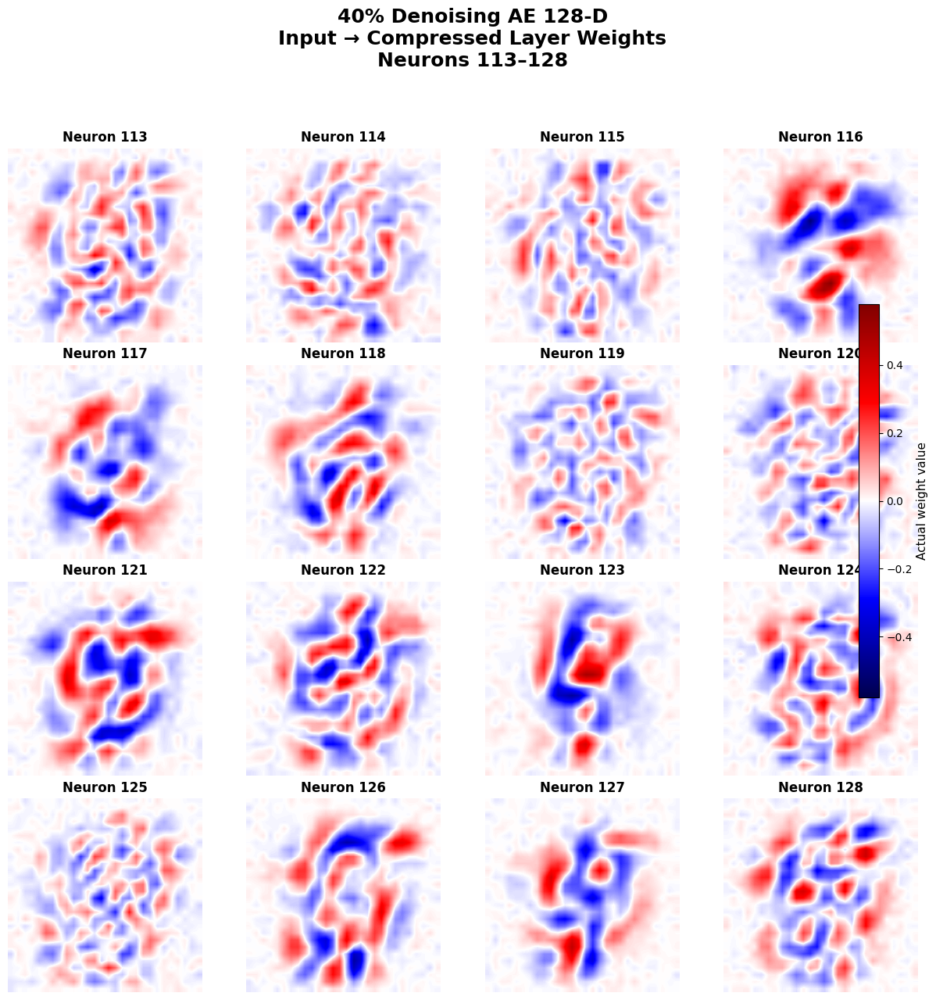

Saved: task_6_output/40_pct_dae/neurons_113_128.png


In [ ]:
plot_weight_pages_0255(
    weights=dae40_weights,
    model_name="40% Denoising AE 128-D",
    output_dir="task_6_output/40_pct_dae"
)

In [ ]:
!zip -r task_6_output.zip task_6_output

  adding: task_6_output/ (stored 0%)
  adding: task_6_output/40_pct_dae/ (stored 0%)
  adding: task_6_output/40_pct_dae/neurons_001_016.png (deflated 1%)
  adding: task_6_output/40_pct_dae/neurons_017_032.png (deflated 1%)
  adding: task_6_output/40_pct_dae/neurons_065_080.png (deflated 1%)
  adding: task_6_output/40_pct_dae/neurons_081_096.png (deflated 1%)
  adding: task_6_output/40_pct_dae/neurons_113_128.png (deflated 1%)
  adding: task_6_output/40_pct_dae/neurons_049_064.png (deflated 1%)
  adding: task_6_output/40_pct_dae/neurons_097_112.png (deflated 1%)
  adding: task_6_output/40_pct_dae/neurons_033_048.png (deflated 1%)
  adding: task_6_output/20_pct_dae/ (stored 0%)
  adding: task_6_output/20_pct_dae/neurons_001_016.png (deflated 1%)
  adding: task_6_output/20_pct_dae/neurons_017_032.png (deflated 1%)
  adding: task_6_output/20_pct_dae/neurons_065_080.png (deflated 1%)
  adding: task_6_output/20_pct_dae/neurons_081_096.png (deflated 1%)
  adding: task_6_output/20_pct_dae/neur